# Proyecto aplicado de PLN · Entregas 1, 2, 3 y 4
## Corpus auditable de cánticos del fútbol profesional colombiano

**Materia:** Procesamiento y Entendimiento del Lenguaje Natural  
**Entrega acumulada:** Fase 1 — entendimiento del negocio y adquisición; Fase 2 — entendimiento y preparación del corpus; Fase 3 — selección y extracción de características; Fase 4 — modelamiento con modelos preentrenados  
**Fecha de corte del corpus:** 1 de septiembre de 2026  
**Fecha de actualización del cuaderno:** 22 de septiembre de 2026  

### Integrantes del equipo

- Manuela Zapata Jiménez
- David Cardona Duque

## Sobre esta edición

Esta edición conserva las fases, el código y la discusión de la entrega académica. Las salidas guardadas se limitan a resultados agregados y figuras seleccionadas. Los resultados corresponden a la ejecución original.

**Reproducción.** La ejecución de extremo a extremo requiere el corpus académico, las matrices de revisión y las revisiones de los modelos que se declaran en las fases 3 y 4. La copia presenta resultados agregados de adquisición, similitud, clasificación y entidades.

[Volver al README del proyecto](../README.md)


# Parte I · Fase 1 — Entendimiento del negocio y adquisición del corpus

Esta parte conserva la formulación, delimitación y carga reproducible desarrolladas en la primera entrega. Las Partes II y III reutilizan sus decisiones e insumos sin duplicarlos ni modificar la evidencia primaria.


### Resumen ejecutivo

Este proyecto aplica **modelos preentrenados de procesamiento de lenguaje natural** a un corpus de cánticos del fútbol profesional colombiano para producir dos caracterizaciones complementarias por texto:

1. las entidades o referentes mencionados —por ejemplo, personas, lugares, clubes u organizaciones, animales y símbolos—;
2. el análisis de sentimientos y emociones —en adelante, **caracterización afectiva**— mediante etiquetas y puntuaciones con mayor riqueza que una polaridad básica.

La taxonomía afectiva y el enfoque preentrenado se seleccionarán después de revisar su compatibilidad con el español, la jerga del corpus, las salidas requeridas y los recursos de cómputo. Esta entrega no fija todavía un modelo, una arquitectura ni un conjunto cerrado de categorías.

Los resultados se unirán mediante `club_id` con las variables contextuales de `datos/clubes.csv`, como región, ciudad, títulos, tasa de clasificación, asistencia y seguidores. Por ejemplo, podrán construirse cruces descriptivos como **“en los cánticos de los clubes de la región Andina aparecen proporcionalmente más menciones de personas que de animales”** o **“ciertos perfiles afectivos tienen distinta presencia entre regiones”**.

El alcance corresponde al de un proyecto universitario realizable en el tiempo disponible. Se usarán modelos ya entrenados, sin entrenamiento propio, anotación manual ni evaluación humana. Tampoco se plantea una investigación sociológica completa ni se harán inferencias causales. La adquisición reunió **600 registros asociados con 17 clubes**; tras la curaduría de calidad, la unidad analítica queda en **566 textos de esos mismos 17 clubes**. Los 20 clubes de la Liga BetPlay A 2026 constituyen únicamente el universo de referencia; para tres de ellos no se localizaron textos en esta versión.


## 1. Entendimiento del negocio o dominio

Se adopta **CRISP-DM** como guía de organización: partir de la necesidad del dominio, comprender y preparar los datos, aplicar las técnicas seleccionadas y comunicar resultados interpretables (Chapman et al., 2000). Su uso aquí es metodológico; no convierte el trabajo en una investigación de alcance mayor al de la materia.

### 1.1 Trasfondo

Los cánticos de fútbol son expresiones colectivas en las que se articulan apoyo, rivalidad, memoria deportiva, pertenencia territorial y símbolos compartidos. No son solamente secuencias de palabras: mediante nombres propios, apodos, lugares, animales, instituciones y metáforas, las hinchadas construyen un “nosotros”, distinguen adversarios y sitúan al club dentro de una historia y un territorio. La literatura ha mostrado que estas prácticas discursivas intervienen en la producción y negociación de identidades colectivas (Knijnik, 2018).

En Colombia, además, las barras no pueden reducirse a episodios de violencia. También han desarrollado formas de organización social, participación y relación con instituciones públicas. Algunas letras contienen insultos, amenazas o antagonismos que deben conservarse y contextualizarse, pues la hinchada constituye una colectividad más amplia que los espacios de violencia y masculinidad (Castro, 2022; Preciado Gallego, 2018). Por ello resulta útil estudiar simultáneamente **de quién o de qué se habla** y **qué configuración afectiva expresa el texto**.

Las letras disponibles en internet están dispersas entre sitios con cobertura y formatos desiguales. Esa fragmentación dificulta comparar repertorios y favorece conclusiones apoyadas solo en ejemplos llamativos. Consolidar un corpus trazable y aplicar PLN permite transformar esas fuentes públicas en evidencia descriptiva comparable, conservando siempre la procedencia, el texto original y el número de observaciones que respalda cada resultado.


### 1.2 Beneficiarios

| Beneficiario potencial | Necesidad | Utilidad del resultado |
|---|---|---|
| Estudios sociales, culturales y del deporte | Examinar repertorios simbólicos sin depender únicamente de una lectura anecdótica | Frecuencias trazables de referentes y perfiles afectivos por club o región |
| Organizaciones deportivas, culturales y de convivencia | Comprender cómo aparecen territorios, actores, símbolos y formas de expresión en letras públicas | Insumos descriptivos para lectura cultural y diseño de conversaciones o actividades; no para perfilar personas |
| Clubes, colectivos de hinchas y proyectos de memoria futbolera | Reconocer elementos recurrentes de identidad y pertenencia en los repertorios recopilados | Tablas y visualizaciones que faciliten explorar semejanzas y diferencias contextuales |
| Comunidad académica y estudiantes de PLN | Contar con un caso reproducible en español colombiano y con lenguaje no estandarizado | Corpus auditable, código de carga y resultados de modelos preentrenados con limitaciones explícitas |

Estos son beneficiarios **potenciales** del conocimiento producido. El proyecto no supone que representen a todos los hinchas ni que sus decisiones dependan de este único análisis.

### 1.3 Dominio de aplicación

El trabajo se ubica en la intersección entre **procesamiento de lenguaje natural en español, analítica cultural y estudios sociales del deporte**. La unidad de interés no es la persona que canta ni su estado psicológico, sino la letra pública como objeto discursivo. El valor analítico proviene de relacionar rasgos lingüísticos de cada texto con información contextual del club mediante una clave verificable.

### 1.4 Problema a solucionar y relevancia

No se dispone actualmente de una caracterización consolidada y reproducible que muestre, para los textos recopilados, cuáles entidades o tipos de referentes predominan, qué perfiles afectivos asignan modelos preentrenados y cómo se distribuyen esos resultados según la región y otras características de los clubes. Las fuentes fragmentadas, la jerga, los apodos, las referencias históricas y la cobertura desigual hacen que una comparación puramente intuitiva sea insuficiente.

Resolver este problema permite:

1. pasar de ejemplos aislados a patrones cuantificados con denominadores visibles;
2. distinguir los actores, lugares, animales, organizaciones y símbolos sobre los que se construyen los cánticos;
3. caracterizar su contenido afectivo sin reducirlo de antemano a una clasificación elemental;
4. explorar asociaciones descriptivas entre lenguaje y contexto territorial o deportivo;
5. dejar un corpus y un procedimiento reproducibles para que cada afirmación pueda rastrearse hasta los textos y las fuentes.

La decisión analítica final consistirá en seleccionar y comunicar los patrones con mayor soporte y claridad. Las asociaciones no se presentarán como causas y los resultados no se extrapolarán más allá de los **550 textos del corpus final para 17 clubes**. La Fase 2 había conservado 566 registros; la auditoría técnica de similitud de la Fase 3 identificó 16 redundancias adicionales.


### 1.5 Objetivo del negocio o necesidad del dominio

**Objetivo:** convertir un conjunto disperso de letras públicas en evidencia descriptiva, trazable y comparable sobre **de qué se habla** y **cómo se configura afectivamente el discurso**. El análisis comprende los 550 cánticos del corpus final, obtenidos después de la curaduría de fuentes y la auditoría técnica de similitud sobre los 600 registros recopilados, y relaciona ambos resultados con las características de los 17 clubes representados.

| Resultado esperado | Indicador técnico | Meta |
|---|---|---:|
| Procesamiento completo | Cánticos del corpus final enviados a los componentes de entidades y análisis afectivo | 550/550 |
| Trazabilidad | Resultados que conservan `cantico_id`, `club_id`, enfoque y versión | 100% |
| Integración contextual | Filas enlazadas correctamente con `clubes.csv` | 100% |
| Salida de referentes | Menciones y categorías semánticas almacenadas por cántico | 100% de ejecuciones válidas |
| Salida afectiva | Etiquetas y puntuaciones del enfoque seleccionado almacenadas por cántico | 100% de ejecuciones válidas |
| Cruces interpretables | Tablas o gráficos con denominador y soporte visibles | Por club, región y variables seleccionadas |

Estas metas verifican la cobertura, la trazabilidad y la integración del flujo de procesamiento. Como no habrá datos etiquetados para contrastar las predicciones, el proyecto **no afirmará haber medido la exactitud real** de los modelos en este dominio.


## 2. Objetivo y alcance técnico del proyecto

### 2.1 Pregunta de trabajo

**¿Qué entidades o referentes aparecen con mayor frecuencia, qué patrones de sentimientos y emociones asignan modelos preentrenados a los cánticos recopilados y cómo varían ambos resultados al cruzarlos con la región y otras características de los clubes representados?**

### 2.2 Objetivo general del proyecto

Aplicar modelos preentrenados para reconocer entidades o referentes y realizar un análisis de sentimientos y emociones de los 550 cánticos del corpus final para 17 clubes, con el fin de generar variables por texto y analizarlas descriptivamente junto con la información contextual de los clubes.

### 2.3 Objetivos específicos

1. Cargar y validar los 600 registros recopilados, aplicar las decisiones de curaduría de fuentes para obtener 566 textos y, posteriormente, la auditoría técnica de similitud para consolidar 550 textos finales de 17 clubes, documentando además los tres clubes del universo de referencia sin textos localizados.
2. Crear una columna de texto derivado para la inferencia sin modificar `letra_original`.
3. Extraer entidades nombradas y referentes relevantes mediante herramientas preentrenadas.
4. Organizar las menciones en categorías semánticas comparables que permitan analizar de qué se habla.
5. Seleccionar y aplicar un enfoque preentrenado capaz de representar el contenido afectivo con una granularidad mayor que la polaridad básica, conservando sus etiquetas y puntuaciones por cántico.
6. Unir los resultados con `clubes.csv` mediante `club_id` y calcular frecuencias o proporciones por club, región y variables contextuales seleccionadas.
7. Presentar patrones descriptivos reproducibles, con su soporte y sus limitaciones, sin entrenamiento adicional, evaluación humana ni afirmaciones causales.


### 2.4 Solución técnica concreta

| Paso | Entrada | Operación | Salida |
|---:|---|---|---|
| 1 | `canticos.csv` + bitácoras de decisiones | Carga, validación, curaduría de fuentes y auditoría técnica de similitud | 550 textos finales con IDs, procedencia y auditoría |
| 2 | `letra_original` | Limpieza mínima compatible con la inferencia, en una columna nueva | `texto_modelo` |
| 3 | `texto_modelo` | Reconocimiento preentrenado de entidades en español o multilingüe | Entidades nombradas, tipo, fragmento y puntuación |
| 4 | Menciones y expresiones nominales | Clasificación semántica preentrenada | Categorías comparables de referentes y sus puntuaciones |
| 5 | `texto_modelo` | Caracterización afectiva con un enfoque preentrenado de mayor granularidad | Una o más etiquetas afectivas y puntuaciones por texto |
| 6 | Resultados + `clubes.csv` | Unión por `club_id` | Corpus enriquecido con región y variables del club |
| 7 | Corpus enriquecido | Agrupaciones, proporciones y visualizaciones | Cruces por región, club y variables seleccionadas |

**Estructura conceptual de la salida principal**

```text
cantico_id | club_id | entidades | conteos_por_tipo_referente |
etiquetas_afectivas | puntuaciones_afectivas | region | variables_del_club | ...
```

La selección del enfoque afectivo permanece abierta en esta fase. Deberá apoyarse en un recurso preentrenado aplicable al idioma y al corpus, capaz de conservar puntuaciones interpretables y de representar categorías más informativas que una polaridad básica. Todavía no se fija una arquitectura ni una taxonomía cerrada. Ambas se documentarán junto con el enfoque finalmente usado.

Los cruces emplearán proporciones por número de cánticos o de menciones, en lugar de limitarse a conteos brutos. Por ejemplo, podrá compararse la proporción de referentes de distintos tipos entre regiones. Las salidas se tratarán como predicciones exploratorias de modelos preentrenados, no como etiquetas verdaderas validadas externamente.


### 2.5 Alcance

**Incluye**

- Los 550 cánticos finales de 17 clubes: 566 después de la revisión de fuentes y 16 redundancias adicionales excluidas mediante la auditoría técnica de similitud de la Fase 3.
- Preservación de `letra_original` y creación de columnas derivadas para inferencia.
- Aplicación directa de recursos preentrenados, sin ajuste fino ni entrenamiento propio.
- Reconocimiento de entidades y clasificación semántica de referentes.
- Caracterización afectiva más rica que una polaridad básica, con etiquetas y puntuaciones cuya definición dependerá del enfoque seleccionado.
- Cruces mediante `club_id` con región, ciudad, desempeño, asistencia, seguidores y otras variables disponibles.
- Tablas y visualizaciones con soporte y denominadores explícitos.

**No incluye**

- Anotación manual, construcción de un conjunto de referencia o evaluación humana.
- Entrenamiento, ajuste fino o una comparación exhaustiva de modelos.
- Una taxonomía afectiva fijada antes de comprobar su pertinencia para el corpus.
- Inferencia causal, diagnóstico psicológico o afirmaciones sobre todas las personas de una hinchada.
- Audio, video, comentarios privados o datos individuales.
- Completar artificialmente los tres clubes sin textos o afirmar que el corpus representa todo su repertorio.


### 2.6 Justificación del uso de modelos preentrenados

El corpus adquirido contiene 600 registros y 33.077 palabras. Después de la curaduría de fuentes quedan 566 textos y 31.221 palabras; la auditoría técnica de similitud reduce el conjunto a 550 textos. Esta base es suficiente para realizar un **análisis descriptivo del material observado**, pero no para aprender desde cero representaciones generales del español. Los modelos de lenguaje contemporáneos obtienen esa capacidad mediante preentrenamiento sobre colecciones masivas y diversas de texto: BERT formalizó la transferencia de representaciones aprendidas en texto no etiquetado hacia tareas posteriores (Devlin et al., 2019), mientras que trabajos multilingües posteriores utilizaron corpus de una escala de terabytes para cubrir numerosos idiomas (Conneau et al., 2020). La diferencia de escala trasciende el costo computacional y afecta la variedad léxica y sintáctica necesaria para generalizar.

Existe además una limitación metodológica distinta al tamaño. El corpus no contiene etiquetas de referencia para entidades, tipos de referentes o categorías afectivas. Por tanto, sus 550 textos finales no equivalen a 550 ejemplos supervisados listos para entrenar y evaluar esas tareas. Construir un modelo propio exigiría definir una taxonomía, anotar sistemáticamente los textos y reservar subconjuntos independientes para validación y prueba. Hacerlo con la base y el tiempo actuales aumentaría el riesgo de sobreajuste, produciría métricas inestables y desplazaría el proyecto desde su objetivo descriptivo hacia la construcción de un nuevo recurso anotado.

Los modelos preentrenados ofrecen una alternativa coherente con el alcance de la materia porque transfieren conocimiento lingüístico adquirido previamente y permiten concentrar el trabajo en la inferencia, la estructuración de resultados y los cruces contextuales. Esto no significa asumir que sus predicciones sean verdaderas. La jerga barrista, los apodos, las metáforas y las grafías no convencionales introducen un cambio de dominio; la literatura muestra que la adaptación al dominio puede mejorar el desempeño de modelos generales (Gururangan et al., 2020). En consecuencia, este proyecto empleará modelos preentrenados como **instrumentos exploratorios**, conservará sus puntuaciones y documentará posibles errores, sin afirmar una exactitud que no puede medirse con los datos disponibles.

Las arquitecturas citadas fundamentan teóricamente el aprendizaje por transferencia; su inclusión no implica que se haya seleccionado todavía un modelo particular para el proyecto.

En síntesis, no entrenar un modelo propio responde a tres razones acumulativas: **escala insuficiente para preentrenamiento**, **ausencia de etiquetas para aprendizaje supervisado** y **desalineación con el objetivo y el calendario del proyecto**. Usar modelos preentrenados aprovecha transferencia lingüística y hace viable el análisis, manteniendo explícitos sus límites frente al español colombiano y al dominio futbolístico.


## 3. Planeación semanal

El proyecto tiene cuatro entregas. Cada etapa ocupa exactamente una semana de trabajo. La primera se preparó del 26 de agosto al 1 de septiembre y se entrega el 2 de septiembre; las siguientes se entregan los jueves 10, 17 y 24 de septiembre de 2026. La planeación fija productos semanales, pero mantiene abierta la selección concreta de modelos y categorías hasta revisar su pertinencia técnica.

| Entrega | Semana de trabajo | Fecha de entrega | Propósito de la etapa | Producto verificable |
|---|---|---:|---|---|
| 1. Negocio y carga | 26 ago–1 sep | **2 sep** | Delimitar el problema, el corpus y la adquisición | Notebook de Fase 1 ejecutado |
| 2. Comprensión y preparación | 3–9 sep | **Jueves 10 sep** | Comprender, depurar y preparar el corpus | Corpus preparado y decisiones de limpieza documentadas |
| 3. Extracción de características | 10–16 sep | **Jueves 17 sep** | Implementar una demostración académica de representaciones léxicas, subléxicas, contextuales y estructurales | Banco exploratorio de características con controles técnicos |
| 4. Modelos, análisis y comunicación | 17–23 sep | **Jueves 24 sep** | Seleccionar y aplicar recursos preentrenados para las tareas del proyecto; construir cruces, visualizaciones y conclusiones | Notebook final del proyecto |


In [ ]:
# Diagrama de Gantt: cuatro etapas de una semana y cuatro entregas
from datetime import datetime, timedelta
import matplotlib.dates as mdates
import matplotlib.pyplot as plt

fases = [
    ("E1 · Negocio y carga", "2026-08-26", "2026-09-01", "2026-09-02"),
    ("E2 · Comprensión y preparación", "2026-09-03", "2026-09-09", "2026-09-10"),
    ("E3 · Aplicación e integración", "2026-09-10", "2026-09-16", "2026-09-17"),
    ("E4 · Análisis y comunicación", "2026-09-17", "2026-09-23", "2026-09-24"),
]
colores = ["#00695C", "#00897B", "#26A69A", "#80CBC4"]

fig, ax = plt.subplots(figsize=(13, 4.6))
for i, (etiqueta, inicio, fin, entrega) in enumerate(fases):
    inicio_dt, fin_dt, entrega_dt = map(
        lambda x: datetime.strptime(x, "%Y-%m-%d"), (inicio, fin, entrega)
    )
    ax.barh(i, (fin_dt - inicio_dt).days + 1, left=inicio_dt, color=colores[i], height=0.58)
    ax.text(
        inicio_dt + timedelta(days=0.25), i,
        f"Trabajo: {inicio_dt.strftime('%d-%b')}–{fin_dt.strftime('%d-%b')}",
        va="center", color="white", fontsize=8, weight="bold"
    )
    ax.scatter(entrega_dt, i, marker="D", s=42, color="#D84315", zorder=3)
    ax.text(
        entrega_dt + timedelta(days=0.35), i,
        f"Entrega {entrega_dt.strftime('%d-%b')}",
        va="center", color="#B23C17", fontsize=8, weight="bold"
    )

ax.set_yticks(range(len(fases)), [x[0] for x in fases])
ax.invert_yaxis()
ax.set_xlim(datetime(2026, 8, 25), datetime(2026, 9, 27))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=7))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
ax.set_title("Planeación semanal · Entrega final 24 de septiembre de 2026", weight="bold")
ax.set_xlabel("Fecha (2026)")
ax.grid(axis="x", linestyle="--", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Lectura del cronograma.** La figura confirma una secuencia de cuatro semanas sin solapamiento de trabajo: cada barra termina el día anterior a su entrega y la etapa siguiente comienza el mismo día del hito anterior. Esa continuidad hace visible una dependencia fuerte entre entregas: la aplicación de modelos de la E3 parte del corpus preparado en la E2, y el análisis final de la E4 parte de las salidas integradas en la E3. También muestra que no existe una semana de holgura; los hitos del 10 y 17 de septiembre coinciden con el inicio inmediato de la etapa siguiente. Por eso, guardar resultados intermedios y cerrar los controles de cada fase constituye la principal protección frente a retrasos acumulativos.

### 3.1 Riesgos y mitigaciones

| Riesgo | Prob. | Impacto | Mitigación dentro del tiempo disponible |
|---|:---:|:---:|---|
| Cobertura desigual: 17 clubes con textos y 3 sin textos | Alta | Alta | Mostrar soporte por club y región; no extrapolar a los clubes ausentes |
| Un reconocedor estándar omite referentes comunes o apodos | Alta | Alta | Complementar la extracción con clasificación semántica preentrenada |
| Jerga, metáforas, ironía o negación afectan las predicciones afectivas | Alta | Alta | Conservar texto original, etiquetas, puntuaciones y limitaciones del enfoque |
| No existe un conjunto etiquetado para medir exactitud | Alta | Media | No reportar métricas de desempeño no sustentadas; tratar las salidas como exploratorias |
| Una decisión de curaduría se aplica de forma incompleta o fuera de orden | Baja | Alta | Validar 57 decisiones, cero pendientes, 34 exclusiones y la reasignación de `CAN0352` antes de construir cualquier tabla |
| El enfoque elegido excede tiempo o memoria | Media | Alta | Procesar por lotes, guardar resultados intermedios y priorizar alternativas viables |
| Cobertura digital se confunde con comportamiento social | Media | Alta | Normalizar resultados y limitar conclusiones a los textos observados |


## 4. Definición del corpus

El diseño de un corpus exige distinguir la población de referencia de los textos realmente observados (Biber, 1993). En este proyecto:

| Elemento | Definición operacional |
|---|---|
| Universo de referencia | 20 clubes de la Liga BetPlay A 2026 |
| Cobertura adquirida | 600 registros asociados con 17 clubes |
| Cobertura analítica después de curaduría | 566 textos asociados con 17 clubes |
| Clubes sin textos localizados | Águilas Doradas, Fortaleza CEIF y Llaneros FC |
| Marco observable | Páginas públicas con letras transcritas localizadas hasta 2026-09-01 |
| Unidad de análisis | Una letra diferente asociada de manera verificable con un club |
| Unidad de observación | Registro publicado en una URL y recuperado por un método documentado |
| Idioma | Principalmente español colombiano, con jerga, nombres y grafías originales |
| Granularidad | Una fila por cántico final |
| Variables que se generarán | Entidades, categorías semánticas, etiquetas afectivas y puntuaciones |
| Variables de cruce | Región, ciudad, títulos, clasificación, asistencia, seguidores y demás campos de `clubes.csv` |

### Reglas de inclusión

1. Letra no vacía, públicamente transcrita y asociada con uno de los clubes cubiertos.
2. Fuente, URL, fecha de consulta y método de adquisición presentes.
3. Cada letra diferente se conserva; compartir coro o melodía no basta para eliminarla.
4. Las identidades históricas de Alianza Petrolera y La Equidad se integran con trazabilidad separada.

### Reglas de exclusión

1. Club fuera del universo 2026, texto vacío o asociación sin evidencia suficiente.
2. Audio o video sin transcripción pública.
3. Coincidencia canónica completa dentro del mismo club: se conserva una versión y se documenta la otra.

### 4.1 Fuentes, adquisición y procedencia

- **DIMAYOR:** delimita el universo de clubes y el contexto competitivo de 2026 (División Mayor del Fútbol Colombiano, 2026).
- **FanChants:** páginas por club con título, letra y, en algunos casos, contexto editorial (FanChants, s. f.).
- **Barrabrava.net:** secciones públicas asociadas con clubes o barras; esa ubicación respalda asociación contextual, no autoría.
- **Attake Massivo Pasto & La Banda Tricolor:** página con múltiples bloques, por lo que se marcaron 18 segmentos para revisión.
- **Fortaleza Leoparda (4mg):** sitio histórico asignado a Atlético Bucaramanga por referencias explícitas a Bucaramanga, “leopardo” y “auriverde”; no a Fortaleza CEIF.

#### Protocolo de adquisición asistida por una herramienta agéntica

La obtención del corpus siguió un **diseño semiautomatizado de consulta documental** compuesto por tres momentos:

1. **Curaduría previa de las fuentes.** El equipo examinó manualmente páginas candidatas y delimitó un conjunto de sitios de referencia según su acceso público, relación identificable con un club colombiano, presencia de letras transcritas y utilidad para el objetivo del proyecto. Esta selección previa definió el espacio autorizado de búsqueda y evitó una recolección abierta y sin criterios.
2. **Consulta y extracción asistidas por Codex.** A partir de las páginas curadas, se utilizó Codex en modo agéntico como herramienta de consulta: el agente navegó los índices y páginas internas, localizó títulos y letras, recuperó el contexto editorial disponible y organizó la información en registros estructurados. El uso de una herramienta agéntica permitió encadenar búsqueda, navegación, extracción y comprobaciones de estructura dentro de un mismo flujo de trabajo (OpenAI, s. f.).
3. **Congelamiento e integración.** Los resultados de cada consulta se almacenaron en capturas JSON con metadatos de fuente, URL, fecha de consulta y método de adquisición. Después, el script `scripts/construir_corpus.py` integró las capturas, preservó `letra_original`, eliminó únicamente coincidencias exactas y generó banderas de calidad sin alterar silenciosamente el contenido.

Codex se empleó como **instrumento de adquisición y estructuración**, no como fuente de las letras: el contenido procede de las páginas citadas y cada registro conserva su URL de origen. Asimismo, la curaduría manual descrita aquí corresponde a la selección metodológica de páginas y no a la anotación de entidades, sentimientos o emociones ni a la evaluación humana de modelos.

En términos operativos, el pipeline separa dos procesos:

1. **Adquisición:** consulta páginas públicas, extrae el contenido seleccionado y guarda capturas JSON sin normalizar la letra.
2. **Integración:** carga las capturas congeladas, conserva el contexto útil, deduplica coincidencias exactas y marca incertidumbre.

La consulta a las páginas originales no se repite durante la ejecución porque estas pueden cambiar y porque hacerlo modificaría el corte documental. En su lugar, el notebook descarga explícitamente desde el repositorio público de GitHub las capturas JSON congeladas, verifica su integridad y reconstruye el corpus en memoria para compararlo con el CSV final. De esta manera, la búsqueda original fue asistida por un agente y la versión entregada permanece estable, auditable y reproducible.


### 4.2 Diccionario mínimo de datos

| Campo | Tipo | Descripción y regla |
|---|---|---|
| `cantico_id` | texto | Identificador único `CAN####` |
| `club_id` | texto | Clave que permite unir cánticos y variables del club |
| `equipo_mencionado_fuente` | texto | Nombre publicado; preserva identidades históricas |
| `titulo_referencia` | texto | Título dado por la fuente; no implica autoría |
| `letra_original` | texto | Evidencia primaria; nunca se sobrescribe |
| `fuente`, `url`, `fecha_consulta` | texto/fecha | Procedencia y corte temporal |
| `metodo_adquisicion` | texto | Procedimiento de recuperación; en esta versión registra la extracción de texto público realizada dentro del flujo de consulta asistido por Codex |
| `numero_palabras` | entero | Conteo descriptivo sin reemplazar la letra |
| `estado_verificacion` | categoría | Estado heredado del control de calidad |
| `posible_similar_a` | texto | IDs relacionados por similitud alta |
| `revision_manual` | Sí/No | Bandera heredada; se usará para análisis de sensibilidad, no para una campaña de anotación |
| Campos contextuales | texto | Desambiguación; no se concatena con la letra |

**Columnas nuevas previstas:** `texto_modelo`, `entidades`, conteos por categoría semántica, `etiquetas_afectivas`, `puntuaciones_afectivas` e identificador y versión de cada recurso preentrenado. La estructura exacta de las etiquetas afectivas se definirá después de seleccionar el enfoque, no en esta fase.

## 5. Carga reproducible del corpus

Para que el archivo `.ipynb` pueda ejecutarse de manera independiente, **todos los datos y recursos lingüísticos utilizados por el código se obtienen explícitamente desde GitHub y se verifican con SHA-256**. Los datos del proyecto provienen del repositorio `celthion/nlp-canticos-futbol-colombiano`; el inventario de stopwords proviene del repositorio oficial `nltk/nltk_data`. No se presupone una estructura local, no se consulta ningún cuaderno auxiliar y no se carga ningún archivo externo que no esté declarado en la siguiente celda.

### 5.1 Descarga explícita de datos y recursos

La celda siguiente declara ruta, URL y huella SHA-256 de cada insumo. Los archivos se guardan en `_nlp_canticos_entrega1` (nombre heredado de la primera fase). La caché solo se reutiliza si su huella coincide; de lo contrario, se descarga nuevamente. Este control reemplaza el manifiesto general del proyecto, que incluía documentos y cuadernos ajenos a la entrega final.

In [ ]:
from pathlib import Path
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen
import hashlib
import importlib.util
import json
import re

import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

# Repositorio público que contiene exclusivamente los insumos de esta entrega.
REPO_RAW = (
    "https://raw.githubusercontent.com/celthion/"
    "nlp-canticos-futbol-colombiano/refs/heads/main"
)

# Cada archivo que se leerá posteriormente queda declarado y verificado aquí.
ARCHIVOS_REQUERIDOS = {
    "datos/canticos.csv": "A2D3CDAC9F5BDB0F821EDCC65083D9D14CDF60D263A658CB6D7B8B9B7F6B7183",
    "datos/clubes.csv": "2B4E60E8C206A65CAF679C81CD8AB6AD90A5D403397DCF2D1DD49B728C813061",
    "datos/control_cobertura.csv": "14F5A0E408DD79B16339B63DEB086AB144BC76B995B985ED96FA05AF467C4ACA",
    "datos/duplicados_exactos.csv": "44D459BC1672EBAF771F0B2A4A47B6266F416FFC929592A1F2C3C62085FAD3D0",
    "datos/fuentes_revisadas.csv": "CBE86EFB50C2E82E8BA5010CA658E4FC0EAE5114EDA0D96B699F8900E7C23B6B",
    "datos/cambios_identidad_clubes.csv": "385CE10EE03F1C21DA5B652DE9E61E87F7F0A2CE4C6AA9A7C49F70A905D17A6C",
    "datos/bibliografia_apa7.csv": "F47D5B648299CFFE7A5D4A7095774E8C1571309CB92D49F8C454DA5E9A9389F9",
    "datos/decisiones_revision_fase2.csv": "7649739777406282471E39F9D8CFDDCFF956D847A0D2948557E4B4366198188B",
    "datos/revision_similitudes_fase3_llenado.xlsx": "AE30C4071870CB8D90F0956187E0819D3039D118E2CCA88D35B4C7E49BE17DDA",
    "datos/fanchants_atletico_nacional.json": "DE43A1DF64BE77D5456057EBC2F825639502270F85246F2DCBD2155150D1C0E2",
    "datos/fanchants_millonarios_santafe.json": "66B86B68375033B0FEAD1AAF61F3F38B437440C6C193E931F7DE24D27C492B85",
    "datos/fanchants_dim_cali.json": "33417DFE07106679C6086B0A214DC2EA27DB89E9BF91AF384F2EB9271FD105D4",
    "datos/fanchants_once_tolima.json": "0EDE21F7F4EC3B87EB4A128D560DD5B01001B681BFB1631729D470FE818AE036",
    "datos/fanchants_junior.json": "D9A6D3553EDA88B45DDDEDE4E0066D01D730FA7381976DC70D37C94DC026D169",
    "datos/fanchants_america_completo.json": "3A97FC999F80377D6DEE2B11FB00DF5C5D31829B3C050ED467EFDFF7BC0FA8AD",
    "datos/fanchants_paginas_pendientes.json": "19219ABD48D829FDB4510DB220221BB698E398360185EEBE1912CF9D33AA1EF2",
    "datos/canticos_crudos_fuentes_adicionales.json": "D101B3168A097780EB4A8A0A790EEF9C2762829A123EB2BD349D7DCECD170FA2",
    "datos/fanchants_contextos.json": "FB3E91C5872879307B6D0F62B9F786A5909D0F62B3EB86BD1C5C61588728D87C",
    "scripts/construir_corpus.py": "890F7AD2D33C90ADFE447D8235A2E1B16E1F65D681F28AA5780D8BC3C3928CA1",
}

# Recurso lingüístico oficial y versionado. No se usa una lista manual de stopwords.
RECURSOS_EXTERNOS_GITHUB = {
    "nltk_stopwords": {
        "url": (
            "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/"
            "packages/corpora/stopwords.zip"
        ),
        "ruta_local": "recursos_nltk/stopwords.zip",
        "sha256": "48C0E52D8B52546E827F53761FB30300C0AB94F70660D28BD65BA0A86270946B",
    }
}

ROOT = Path.cwd() / "_nlp_canticos_entrega1"
DATA = ROOT / "datos"


def sha256_bytes(contenido: bytes) -> str:
    return hashlib.sha256(contenido).hexdigest().upper()


def descargar_verificado(ruta_relativa: str, sha_esperado: str) -> dict[str, str]:
    """Descarga un archivo de GitHub y acepta caché solo si coincide su SHA-256."""
    destino = ROOT / ruta_relativa
    url = f"{REPO_RAW}/{ruta_relativa}"
    destino.parent.mkdir(parents=True, exist_ok=True)

    if destino.exists() and sha256_bytes(destino.read_bytes()) == sha_esperado:
        return {"archivo": ruta_relativa, "url": url, "estado": "caché verificada"}

    solicitud = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urlopen(solicitud, timeout=60) as respuesta:
            contenido = respuesta.read()
    except (HTTPError, URLError) as exc:
        raise RuntimeError(
            f"No fue posible descargar {url}. Verifique que el archivo exista "
            "en la rama main y que el repositorio sea público."
        ) from exc

    sha_observado = sha256_bytes(contenido)
    if sha_observado != sha_esperado:
        raise ValueError(
            f"Integridad inválida para {ruta_relativa}: "
            f"se esperaba {sha_esperado} y se obtuvo {sha_observado}."
        )

    destino.write_bytes(contenido)
    return {"archivo": ruta_relativa, "url": url, "estado": "descargado y verificado"}


def descargar_recurso_externo_verificado(
    nombre: str, url: str, ruta_local: str, sha_esperado: str
) -> dict[str, str]:
    """Descarga un recurso oficial de GitHub con el mismo control de integridad."""
    destino = ROOT / ruta_local
    destino.parent.mkdir(parents=True, exist_ok=True)

    if destino.exists() and sha256_bytes(destino.read_bytes()) == sha_esperado:
        return {"archivo": f"externo:{nombre}", "url": url, "estado": "caché verificada"}

    solicitud = Request(url, headers={"User-Agent": "Mozilla/5.0"})
    try:
        with urlopen(solicitud, timeout=60) as respuesta:
            contenido = respuesta.read()
    except (HTTPError, URLError) as exc:
        raise RuntimeError(f"No fue posible descargar el recurso lingüístico {url}.") from exc

    sha_observado = sha256_bytes(contenido)
    if sha_observado != sha_esperado:
        raise ValueError(
            f"Integridad inválida para {nombre}: se esperaba {sha_esperado} "
            f"y se obtuvo {sha_observado}."
        )
    destino.write_bytes(contenido)
    return {"archivo": f"externo:{nombre}", "url": url, "estado": "descargado y verificado"}


inventario_descarga = [
    descargar_verificado(ruta, sha)
    for ruta, sha in ARCHIVOS_REQUERIDOS.items()
]
inventario_descarga.extend(
    descargar_recurso_externo_verificado(
        nombre, especificacion["url"], especificacion["ruta_local"], especificacion["sha256"]
    )
    for nombre, especificacion in RECURSOS_EXTERNOS_GITHUB.items()
)

display(pd.DataFrame(inventario_descarga))
print(f"Paquete disponible en: {ROOT.resolve()}")
print(f"Datos y recursos obtenidos desde GitHub y verificados: {len(inventario_descarga)}/{len(inventario_descarga)}")


In [ ]:
def cargar_csv(nombre: str, columnas_obligatorias: set[str] | None = None) -> pd.DataFrame:
    ruta = DATA / nombre
    if not ruta.exists():
        raise FileNotFoundError(f"Falta el archivo requerido: {ruta}")
    tabla = pd.read_csv(ruta, encoding="utf-8-sig", low_memory=False)
    faltantes = (columnas_obligatorias or set()) - set(tabla.columns)
    if faltantes:
        raise ValueError(f"{nombre} no contiene las columnas: {sorted(faltantes)}")
    return tabla

tablas = {
    "canticos": cargar_csv("canticos.csv", {"cantico_id", "club_id", "letra_original", "fuente", "url", "fecha_consulta"}),
    "clubes": cargar_csv("clubes.csv", {"club_id", "nombre_corto", "region"}),
    "cobertura": cargar_csv("control_cobertura.csv", {"club_id", "registros_finales", "estado_primera_pasada"}),
    "duplicados": cargar_csv("duplicados_exactos.csv"),
    "fuentes": cargar_csv("fuentes_revisadas.csv"),
    "cambios": cargar_csv("cambios_identidad_clubes.csv"),
    "bibliografia": cargar_csv("bibliografia_apa7.csv"),
    "decisiones": cargar_csv(
        "decisiones_revision_fase2.csv",
        {"revision_id", "tipo_revision", "canticos_involucrados",
         "decision_revision", "justificacion", "estado_aplicacion"},
    ),
}
canticos = tablas["canticos"]
clubes = tablas["clubes"]
cobertura = tablas["cobertura"]
duplicados = tablas["duplicados"]
fuentes = tablas["fuentes"]
cambios = tablas["cambios"]
bibliografia = tablas["bibliografia"]
decisiones = tablas["decisiones"]

canticos["fecha_consulta"] = pd.to_datetime(canticos["fecha_consulta"], errors="raise")
canticos["numero_palabras"] = pd.to_numeric(canticos["numero_palabras"], errors="raise").astype("int64")
print("Tablas cargadas:", {nombre: tabla.shape for nombre, tabla in tablas.items()})

In [ ]:
# Indicadores de la versión cargada
indicadores = pd.DataFrame({
    "Indicador": [
        "Clubes del universo", "Textos finales", "Clubes con textos", "Clubes sin textos localizados",
        "Palabras en el corpus", "Fuentes de texto", "Capturas exactas descartadas",
        "Registros con bandera de calidad", "Referencias trazables"
    ],
    "Valor": [
        len(clubes), len(canticos), canticos["club_id"].nunique(),
        len(clubes) - canticos["club_id"].nunique(), canticos["numero_palabras"].sum(),
        canticos["fuente"].nunique(), len(duplicados),
        canticos["revision_manual"].eq("Sí").sum(), len(bibliografia)
    ]
})
display(indicadores)

muestra = canticos[[
    "cantico_id", "club_id", "equipo_mencionado_fuente", "titulo_referencia",
    "fuente", "fecha_consulta", "numero_palabras", "estado_verificacion"
]].head(8)
display(muestra)

**Lectura de las salidas de carga.** La descarga verificó **19 de 19 recursos**. Las ocho tablas principales se cargaron con las dimensiones esperadas: 600 cánticos, 20 clubes, 20 filas de cobertura, 10 duplicados exactos, 31 fuentes revisadas, 2 cambios de identidad, 75 referencias y 57 decisiones. La tabla de indicadores permite distinguir tamaño de adquisición y cobertura: hay 600 textos y 33.077 palabras, pero solo 17 de los 20 clubes tienen registros. En consecuencia, la ausencia de filas para tres clubes es una limitación de cobertura de esta versión, no evidencia de que esos clubes carezcan de cánticos.

Los **88 registros con bandera de calidad** equivalen al 14,7 % de la adquisición y justifican que el EDA no se ejecute directamente sobre las 600 filas. Las primeras ocho filas mostradas también permiten comprobar que la unidad conserva `cantico_id`, club, título, fuente, fecha y longitud; es decir, la lectura textual no quedó separada de su procedencia. En la Fase 2 se aplican las decisiones de curaduría antes del análisis, se retiran copias redundantes y se corrige `CAN0352`, sin modificar este archivo fuente.

### 5.2 Reconstrucción ejecutable desde capturas crudas

En lugar de volver a consultar internet, se importa el constructor ya existente y se ejecutan sus funciones sobre las ocho capturas JSON versionadas. El resultado se mantiene en memoria: no se sobrescribe ningún archivo.

In [ ]:
ruta_constructor = ROOT / "scripts" / "construir_corpus.py"
spec = importlib.util.spec_from_file_location("construir_corpus", ruta_constructor)
constructor = importlib.util.module_from_spec(spec)
assert spec.loader is not None
spec.loader.exec_module(constructor)

inventario_crudo = []
for ruta in constructor.INPUTS:
    payload = json.loads(ruta.read_text(encoding="utf-8"))
    inventario_crudo.append({
        "archivo": ruta.name,
        "registros": len(payload.get("registros", [])),
        "fecha_o_fuente": payload.get("metadata", {}).get("fecha_consulta", payload.get("metadata", {}).get("fuente", "")),
    })

crudos = constructor.load_rows()
corpus_reconstruido, duplicados_reconstruidos = constructor.integrate(crudos)
display(pd.DataFrame(inventario_crudo))
print({
    "capturas_crudas": len(crudos),
    "duplicados_exactos": len(duplicados_reconstruidos),
    "registros_reconstruidos": len(corpus_reconstruido),
})

In [ ]:
# Pruebas de integridad, estructura y equivalencia
columnas_obligatorias = {
    "cantico_id", "club_id", "equipo_mencionado_fuente", "titulo_referencia",
    "letra_original", "fuente", "url", "fecha_consulta", "metodo_adquisicion",
    "numero_palabras", "estado_verificacion", "revision_manual"
}
assert columnas_obligatorias <= set(canticos.columns)
assert canticos["cantico_id"].is_unique
assert canticos["cantico_id"].str.fullmatch(r"CAN\d{4}").all()
assert not canticos[list(columnas_obligatorias - {"numero_palabras"})].isna().any().any()
assert (canticos["numero_palabras"] > 0).all()
assert set(canticos["club_id"]) <= set(clubes["club_id"])
assert cobertura["registros_finales"].sum() == len(canticos)

campos_comparacion = ["cantico_id", "club_id", "titulo_referencia", "letra_original", "fuente", "url"]
cargado = [tuple(fila[c] for c in campos_comparacion) for fila in canticos.to_dict("records")]
reconstruido = [tuple(fila[c] for c in campos_comparacion) for fila in corpus_reconstruido]
assert cargado == reconstruido, "La reconstrucción no coincide con el corpus CSV descargado."

# Segunda verificación de todos los archivos declarados y descargados desde GitHub.
verificaciones = {
    ruta: sha256_bytes((ROOT / ruta).read_bytes()) == sha
    for ruta, sha in ARCHIVOS_REQUERIDOS.items()
}
verificaciones.update({
    f"externo:{nombre}": (
        sha256_bytes((ROOT / especificacion["ruta_local"]).read_bytes())
        == especificacion["sha256"]
    )
    for nombre, especificacion in RECURSOS_EXTERNOS_GITHUB.items()
})
assert all(verificaciones.values()), "Algún archivo descargado cambió durante la ejecución."

print("Pruebas estructurales: OK")
print(f"Equivalencia reconstrucción ↔ CSV: {len(reconstruido):,}/{len(cargado):,} registros idénticos en campos críticos")
print(f"Integridad del paquete mínimo: {sum(verificaciones.values())}/{len(verificaciones)} archivos coinciden")


**Lectura de la reconstrucción.** Los ocho archivos crudos aportan **610 capturas**: 177 provienen de los lotes de FanChants y 433 de fuentes adicionales. El constructor documenta 10 coincidencias exactas y produce 600 registros, de modo que el cambio 610 → 600 está completamente explicado y no corresponde a pérdida silenciosa. Las pruebas posteriores son especialmente importantes: los 600 registros reconstruidos coinciden 600/600 con el CSV en los campos críticos y los 19 archivos del paquete vuelven a coincidir con sus huellas. La salida respalda tanto la reproducibilidad del corpus como la integridad de la versión analizada.

### 5.3 Procedencia y cobertura de adquisición

La bitácora permite separar “fuente revisada”, “fuente incluida”, “registro recuperado” y “error”. Esa distinción evita presentar una navegación parcial como si fuera un censo completo.

In [7]:
resumen_fuentes = pd.DataFrame({
    "Métrica": ["Páginas revisadas", "Páginas incluidas", "Páginas excluidas", "Registros de fuentes adicionales", "Errores"],
    "Valor": [
        len(fuentes), fuentes["decision"].str.startswith("incluir").sum(),
        fuentes["decision"].eq("excluir").sum(), fuentes["recuperados"].sum(), fuentes["errores"].sum()
    ]
})
display(resumen_fuentes)

por_fuente = (canticos.groupby("fuente", as_index=False)
              .agg(textos=("cantico_id", "size"), clubes=("club_id", "nunique"))
              .sort_values("textos", ascending=False))
display(por_fuente)

Métrica  Valor
0                 Páginas revisadas     31
1                 Páginas incluidas     25
2                 Páginas excluidas      6
3  Registros de fuentes adicionales    433
4                           Errores      0


fuente  textos  clubes
0                                 Barrabrava.net     388      17
2                                      FanChants     176       9
1  Blog Attake Massivo Pasto & La Banda Tricolor      18       1
3                       Fortaleza Leoparda (4mg)      18       1


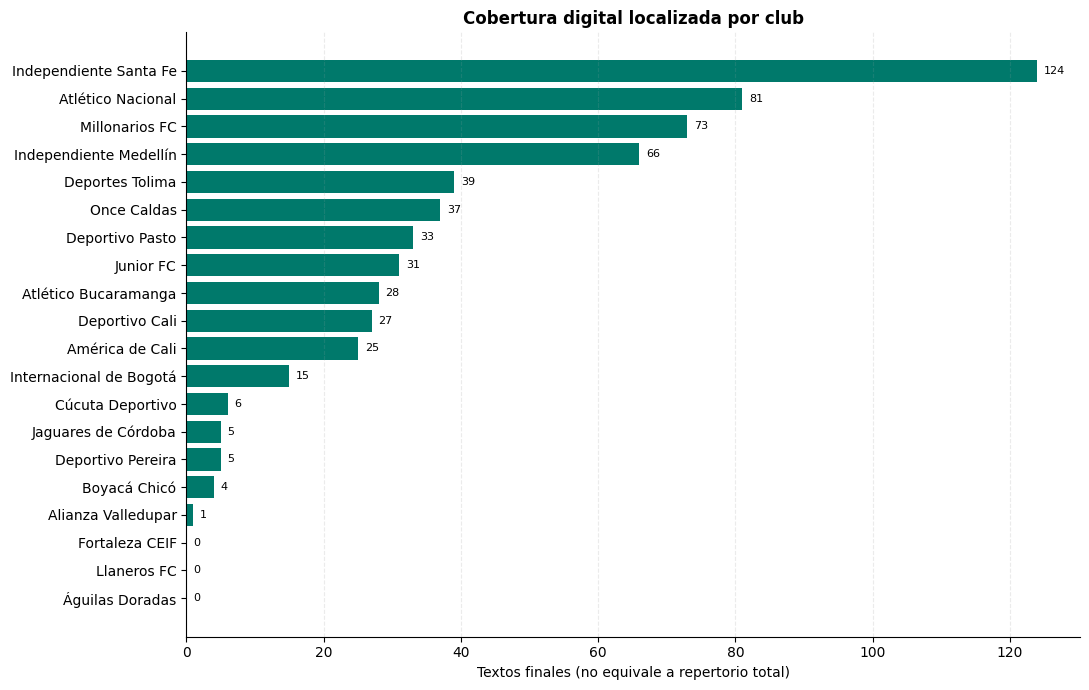

nombre_corto  fanchants_total_declarado  fanchants_recuperados  \
0           Águilas Doradas                          0                      0   
1        Alianza Valledupar                          0                      0   
2           América de Cali                          3                      3   
3           Deportivo Pasto                          0                      0   
4      Atlético Bucaramanga                          0                      0   
5         Atlético Nacional                         42                     41   
6              Boyacá Chicó                          0                      0   
7          Cúcuta Deportivo                          0                      0   
8            Deportivo Cali                         18                     18   
9    Independiente Medellín                         17                     17   
10        Deportivo Pereira                          0                      0   
11          Deportes Tolima                

Atlético Nacional en FanChants: 42 capturas crudas, 41 filas finales y 1 duplicado exacto descartado.


In [8]:
# Universo de referencia: 20 clubes; cobertura efectiva: 17 con textos.
cobertura_plot = cobertura[["nombre_corto", "registros_finales", "estado_primera_pasada"]].copy()
cobertura_plot = cobertura_plot.sort_values("registros_finales", ascending=True)
colores = ["#EF6C00" if n == 0 else "#00796B" for n in cobertura_plot["registros_finales"]]

fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(cobertura_plot["nombre_corto"], cobertura_plot["registros_finales"], color=colores)
for y, valor in enumerate(cobertura_plot["registros_finales"]):
    ax.text(valor + 1, y, str(valor), va="center", fontsize=8)
ax.set_title("Cobertura digital localizada por club", weight="bold")
ax.set_xlabel("Textos finales (no equivale a repertorio total)")
ax.grid(axis="x", linestyle="--", alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

display(cobertura[[
    "nombre_corto", "fanchants_total_declarado", "fanchants_recuperados",
    "barrabrava_recuperados", "registros_finales", "estado_primera_pasada"
]])

nacional_crudo = sum(r.get("club_id") == "CLU006" and r.get("fuente") == "FanChants" for r in crudos)
nacional_final = ((canticos["club_id"] == "CLU006") & (canticos["fuente"] == "FanChants")).sum()
nacional_duplicado = sum(r["club_id"] == "CLU006" and r["fuente_descartada"] == "FanChants" for r in duplicados_reconstruidos)
assert (nacional_crudo, nacional_final, nacional_duplicado) == (42, 41, 1)
print(f"Atlético Nacional en FanChants: {nacional_crudo} capturas crudas, {nacional_final} filas finales y {nacional_duplicado} duplicado exacto descartado.")

**Lectura de procedencia y cobertura.** Se revisaron 31 páginas: 25 fueron incluidas, 6 excluidas y no se registraron errores de adquisición. La procedencia es muy desigual incluso antes de la curaduría: Barrabrava.net aporta 388 de 600 textos (64,7 %), FanChants 176 (29,3 %) y las dos fuentes restantes 18 textos cada una (3,0 % por fuente). Por tanto, los patrones de ortografía, longitud o segmentación observados más adelante pueden reflejar en buena medida las convenciones de Barrabrava.net.

La gráfica por club hace visible otra concentración: Santa Fe reúne 124 textos adquiridos (20,7 %), mientras Atlético Nacional, Millonarios e Independiente Medellín aportan 81, 73 y 66. En el extremo inferior, tres clubes aparecen explícitamente con cero y otros cuatro no superan seis textos. Esta forma de cola larga impide leer la altura de las barras como tamaño real del repertorio o de la hinchada; representa únicamente disponibilidad digital localizada.

**Hallazgo de control.** La adquisición cruda de FanChants sí completó los nueve inventarios declarados. En Atlético Nacional se recuperaron **42 de 42** capturas, pero una era un duplicado canónico de una letra conservada desde Barrabrava.net; por ello quedan **41** filas finales con fuente FanChants. La etiqueta automática “cobertura FanChants parcial por fallo de paginación” compara el total final después de deduplicar contra el total declarado antes de deduplicar y, en este caso, es una clasificación imprecisa del control de cobertura, no una pérdida de adquisición.

### 5.4 Duplicados, banderas de calidad e identidades históricas

El algoritmo de adquisición crea una copia temporal en minúsculas, sin diacríticos y con puntuación o espacios unificados. En la Fase 1 solo eliminó coincidencias canónicas completas dentro del mismo club y conservó semejanzas altas para no decidir automáticamente si eran duplicados o variantes.

La columna `revision_manual` es, por tanto, una **bandera histórica del proceso de construcción**, no un estado pendiente en el corpus analítico. Las 56 decisiones diligenciadas en el libro de revisión y la aclaración adicional de `CAN0352` se normalizan en una bitácora de 57 decisiones y se aplican al inicio de la Fase 2. Esta revisión verifica la calidad y procedencia de los datos; no constituye evaluación humana de las predicciones de entidades o afecto.

In [9]:
estados = (canticos.groupby("estado_verificacion", as_index=False)
           .agg(registros=("cantico_id", "size"))
           .sort_values("registros", ascending=False))
estados["porcentaje"] = (estados["registros"] / len(canticos) * 100).round(1)
display(estados)

print(f"Duplicados exactos documentados: {len(duplicados)}")
display(duplicados[["club_id", "titulo_conservado", "fuente_conservada", "titulo_descartado", "fuente_descartada"]].head())

display(cambios[[
    "club_actual_2026", "identidad_historica_en_fuente",
    "canticos_identidad_historica", "canticos_identidad_actual", "tratamiento_en_corpus"
]])

estado_verificacion  registros  porcentaje
0                                   aceptado        512        85.3
3               requiere revisión: similitud         67        11.2
2  requiere revisión: segmentación de fuente         18         3.0
1     requiere revisión: asociación con club          3         0.5


Duplicados exactos documentados: 10


club_actual_2026 identidad_historica_en_fuente  \
0  Alianza FC / Alianza Valledupar FC             Alianza Petrolera   
1             Internacional de Bogotá                    La Equidad   

   canticos_identidad_historica  canticos_identidad_actual  \
0                             1                          0   
1                            15                          0   

                                                                       tratamiento_en_corpus  
0  Se integra por continuidad deportiva en CLU002, conservando Alianza Petrolera en equip...  
1  Se integra por continuidad institucional en CLU015, conservando La Equidad en equipo_m...


**Lectura de las banderas y decisiones.** En la adquisición, 512 registros (85,3 %) quedaron aceptados sin observación, 67 (11,2 %) fueron señalados por similitud, 18 (3,0 %) por segmentación y 3 (0,5 %) por asociación. Esas categorías describen el motivo de revisión, no cuatro niveles de calidad ni errores confirmados. La tabla de duplicados muestra, por ejemplo, títulos con variaciones ortográficas o editoriales conservados frente a su copia, mientras la tabla histórica explica 16 letras vinculadas a identidades anteriores: una de Alianza Petrolera y quince de La Equidad. Mantener ambas trazas evita interpretar un nombre histórico como asignación incorrecta del club actual.

### 5.5 Preservación textual, contexto y límites

- `letra_original` es evidencia primaria y no se corrige, traduce ni reemplaza.
- La entrada a los modelos se guardará en `texto_modelo`; nunca sobrescribirá la fuente.
- Grafías como `Rexixtenxia` o `Cha77arra`, apodos, números y jerga se conservan.
- El contexto editorial está separado y no se concatena con la letra.
- Los insultos se mantienen por integridad documental y no representan la posición del equipo.
- Las predicciones de referentes y contenido afectivo provendrán de recursos preentrenados; sin datos etiquetados no se podrá afirmar su exactitud en la jerga barrista.
- Los resultados describirán los textos recopilados, no la psicología o conducta de todas las personas de una hinchada.

**Unidad de inferencia permitida:** los 550 textos del corpus final. La bitácora de calidad de la Fase 2 había conservado 566 y la auditoría técnica de la Fase 3 excluyó 16 redundancias adicionales.  
**Unidad de inferencia no permitida:** los repertorios completos de los 20 clubes o las características personales de sus hinchas.

In [ ]:
# Controles cuantitativos que respaldan la afirmación anterior
campos_nucleo = ["cantico_id", "club_id", "titulo_referencia", "letra_original", "fuente", "url", "fecha_consulta", "metodo_adquisicion"]
control_calidad = pd.DataFrame({
    "Control": [
        "Campos núcleo completos", "IDs únicos", "URLs únicas", "Letras no vacías",
        "Contextos conservados", "Referentes verificados", "Bandera de calidad", "Identidad histórica"
    ],
    "Resultado": [
        not canticos[campos_nucleo].isna().any().any(), canticos["cantico_id"].is_unique,
        canticos["url"].is_unique, canticos["letra_original"].str.strip().ne("").all(),
        canticos["contexto_cantico"].notna().sum(),
        canticos["estado_contexto"].eq("verificado con fuente externa").sum(),
        canticos["revision_manual"].eq("Sí").sum(),
        canticos["equipo_mencionado_fuente"].isin(["Alianza Petrolera", "La Equidad"]).sum(),
    ]
})
display(control_calidad)

**Lectura de los controles de Fase 1.** Las ocho comprobaciones cuantitativas son coherentes entre sí: los campos núcleo están completos, los IDs y las URL son únicos y ninguna letra está vacía. Los cinco contextos conservados y cuatro referentes verificados son deliberadamente escasos porque solo se incluyeron cuando había evidencia; en cambio, las 88 banderas de calidad y las 16 identidades históricas permanecen visibles para que la Fase 2 las resuelva o contextualice. El resultado no implica que el corpus carezca de problemas. Corresponde a un inventario explícito de los aspectos cerrados y de aquellos que requieren una decisión.

## 6. Conclusiones de la Fase 1

1. El problema del dominio quedó delimitado: convertir letras públicas dispersas en evidencia trazable sobre los referentes y las configuraciones afectivas presentes en los cánticos, y relacionarla descriptivamente con el contexto de los clubes.
2. El objetivo técnico es concreto y viable para la materia: aplicar recursos preentrenados al corpus que resulte de la curaduría de los 600 textos adquiridos y cruzar sus salidas mediante `club_id`; no entrenar un modelo propio ni desarrollar una investigación sociológica completa.
3. El análisis afectivo no se restringe de antemano a una polaridad básica. La taxonomía, la arquitectura y el enfoque preentrenado quedan abiertos hasta comprobar su pertinencia para el idioma, la jerga, las salidas requeridas y los recursos disponibles.
4. La carga es autónoma y reproducible: el notebook declara y descarga desde GitHub 19 insumos —los 17 del paquete de adquisición, la bitácora de decisiones y el recurso oficial de stopwords de NLTK—, verifica sus huellas SHA-256 y reconstruye 600 registros a partir de 610 capturas después de documentar 10 duplicados exactos. No depende del borrador ni del manifiesto general del proyecto.
5. Los 20 clubes delimitan el universo de referencia, pero solo 17 tienen textos en la versión adquirida. Todas las comparaciones deberán mostrar soporte y circunscribirse a los registros conservados después de aplicar las decisiones de calidad.
6. Sin anotación ni evaluación humana de las salidas de los modelos, los resultados futuros se comunicarán como predicciones exploratorias de recursos preentrenados, con sus puntuaciones y limitaciones, no como verdades verificadas.

# Parte II · Fase 2 — Entendimiento y preparación del corpus

Esta fase continúa el mismo proyecto y trabaja sobre el corpus descargado y validado en la Parte I. En particular, retoma la [definición del corpus](#4-definición-del-corpus), la [carga reproducible](#5-carga-reproducible-del-corpus) y las [banderas históricas de calidad](#54-duplicados-banderas-de-calidad-e-identidades-históricas). No se vuelve a adquirir información ni se sustituye la evidencia original.

## 7. Propósito y alcance de la Fase 2

El propósito es comprender la composición del corpus, hacer visibles sus desequilibrios y preparar una representación textual adecuada para los análisis posteriores de **entidades o referentes** y **sentimientos o emociones de mayor riqueza que una polaridad de tres clases**. En esta entrega todavía no se selecciona un modelo ni una taxonomía afectiva particular.

### 7.1 Correspondencia con los requisitos

| Requisito | Desarrollo en el cuaderno | Evidencia verificable |
|---|---|---|
| Análisis exploratorio | Dimensiones, completitud, longitudes, diversidad, repetición, contenido léxico y cobertura | Tablas, aserciones y resúmenes calculados desde el corpus curado |
| Análisis descriptivo | Perfiles por club, fuente y región; composición fuente–región y cruces con variables externas | Medianas, intervalos intercuartílicos, tasas y correlaciones no causales |
| Visualización | Cobertura, distribuciones, sesgos de fuente, unigramas, bigramas y términos distintivos por región | Figuras rotuladas con denominadores y unidades |
| Limpieza de datos | Normalización conservadora y vista léxica con stopwords oficiales de NLTK | Funciones reproducibles, comparación antes/después y pruebas de conservación |
| Control de calidad | Bitácora cerrada, justificada y aplicada antes de toda exploración | 57 decisiones, 34 copias redundantes excluidas y una reasignación de club |

### 7.2 Decisiones metodológicas

- Toda la exploración se ejecuta sobre `canticos_curados`, no sobre las 600 filas adquiridas sin resolver.
- `canticos.csv` permanece inmutable. Las exclusiones y correcciones solo existen en una copia de trabajo y quedan trazadas por `revision_id`.
- Las decisiones de similitud determinan la unidad de análisis: 33 grupos conservan un registro canónico y 2 conservan ambas versiones; uno de los primeros grupos contiene tres registros.
- Los 18 casos de segmentación se confirmaron como correctos y las tres asociaciones originales se confirmaron. Además, `CAN0352` se reasigna de Santa Fe a Cúcuta Deportivo por evidencia explícita de su letra.
- La cobertura es desigual y depende de las fuentes localizadas. Por eso, las comparaciones muestran soporte y no se interpretan como estimaciones representativas de todas las hinchadas.
- El preprocesamiento es dependiente de la tarea: `texto_modelo` conserva el contexto completo; la vista léxica elimina stopwords oficiales de NLTK, pero retiene negaciones explícitas.
- La revisión realizada es curaduría de la fuente y la unidad textual; no evalúa manualmente predicciones futuras de entidades o contenido afectivo.

## 8. Integración reproducible de las decisiones de curaduría

El libro diligenciado `revision_casos_fase2.xlsm` es el artefacto de revisión. Para que el único entregable `.ipynb` pueda ejecutarse sin depender de Excel ni de rutas locales, sus decisiones se normalizaron en `datos/decisiones_revision_fase2.csv`, archivo declarado, descargado y verificado en la [sección 5.1](#51-descarga-explícita-del-paquete-mínimo-desde-github). La bitácora conserva decisión, IDs involucrados, justificación, revisor, enlaces de evidencia y procedencia.

La versión ejecutable contiene **57 decisiones cerradas**: 35 de similitud, 18 de segmentación y 4 de asociación. Las primeras 56 provienen del libro diligenciado; la decisión `ASO-CAN0352` formaliza la aclaración posterior del equipo revisor. La letra menciona “Cúcuta querido”, “Cúcuta divino” y “rojinegro”, por lo que el registro se reasigna de `CLU014` (Santa Fe) a `CLU008` (Cúcuta Deportivo). Se preservan los valores originales en columnas de auditoría.

### 8.1 Reglas de aplicación

| Tipo | Decisión observada | Efecto reproducible |
|---|---|---|
| Similitud | `conservar_uno` | Conserva el ID seleccionado y excluye únicamente las copias redundantes del grupo |
| Similitud | `conservar_ambos` | Mantiene todas las versiones porque conservan diferencias de club, agrupación o contexto |
| Segmentación | `segmentacion_correcta` | Mantiene el bloque como una unidad textual independiente |
| Asociación | `confirmar_club` | Conserva la clave del club ya registrada |
| Asociación | `reasignar_club` | Actualiza la clave analítica y preserva la asignación original para auditoría |

No hay decisiones `pendiente`, `fusionar`, `dividir_bloque` ni `excluir` en la bitácora recibida. Las aserciones siguientes impiden continuar si aparece una opción no implementada, un ID inexistente o una justificación vacía.

In [ ]:
COLUMNAS_DECISION = {
    "revision_id", "tipo_revision", "canticos_involucrados", "decision_revision",
    "id_conservar_o_relacionar", "club_id_corregido", "nombre_club_corregido",
    "justificacion", "revisor", "fecha_integracion", "urls_evidencia",
    "fuente_decision", "estado_aplicacion",
}
assert COLUMNAS_DECISION <= set(decisiones.columns)
assert decisiones["revision_id"].is_unique
assert len(decisiones) == 57
assert decisiones["decision_revision"].ne("pendiente").all()
assert decisiones["justificacion"].fillna("").str.strip().ne("").all()
assert decisiones["estado_aplicacion"].eq("aplicada").all()
assert decisiones.groupby("tipo_revision").size().to_dict() == {
    "asociacion": 4, "segmentacion": 18, "similitud": 35,
}


def separar_ids(valor: object) -> list[str]:
    return [parte.strip() for parte in str(valor).split("|") if parte.strip()]


ids_fuente = set(canticos["cantico_id"])
ids_en_bitacora = {
    cantico_id
    for valor in decisiones["canticos_involucrados"]
    for cantico_id in separar_ids(valor)
}
assert ids_en_bitacora <= ids_fuente

canticos_curados = canticos.copy()
canticos_curados["club_id_original"] = canticos_curados["club_id"]
canticos_curados["equipo_mencionado_fuente_original"] = canticos_curados["equipo_mencionado_fuente"]

ids_excluir: set[str] = set()
revisiones_por_id: dict[str, list[str]] = {}
filas_aplicacion = []

for _, decision in decisiones.iterrows():
    revision_id = decision["revision_id"]
    tipo = decision["tipo_revision"]
    accion = decision["decision_revision"]
    ids = separar_ids(decision["canticos_involucrados"])
    excluidos_decision: list[str] = []

    for cantico_id in ids:
        revisiones_por_id.setdefault(cantico_id, []).append(revision_id)

    if tipo == "similitud":
        if accion == "conservar_uno":
            conservar = str(decision["id_conservar_o_relacionar"]).strip()
            assert conservar in ids, f"{revision_id}: el ID canónico no pertenece al grupo."
            excluidos_decision = [cantico_id for cantico_id in ids if cantico_id != conservar]
            ids_excluir.update(excluidos_decision)
        elif accion != "conservar_ambos":
            raise ValueError(f"{revision_id}: decisión de similitud no implementada: {accion}")
    elif tipo == "segmentacion":
        if accion != "segmentacion_correcta":
            raise ValueError(f"{revision_id}: decisión de segmentación no implementada: {accion}")
    elif tipo == "asociacion":
        if accion == "reasignar_club":
            club_destino = str(decision["club_id_corregido"]).strip()
            nombre_destino = str(decision["nombre_club_corregido"]).strip()
            assert club_destino in set(clubes["club_id"])
            mascara = canticos_curados["cantico_id"].isin(ids)
            canticos_curados.loc[mascara, "club_id"] = club_destino
            canticos_curados.loc[mascara, "equipo_mencionado_fuente"] = nombre_destino
        elif accion != "confirmar_club":
            raise ValueError(f"{revision_id}: decisión de asociación no implementada: {accion}")
    else:
        raise ValueError(f"Tipo de revisión desconocido: {tipo}")

    filas_aplicacion.append({
        "revision_id": revision_id,
        "tipo_revision": tipo,
        "decision_revision": accion,
        "n_ids_involucrados": len(ids),
        "ids_excluidos": " | ".join(excluidos_decision),
        "n_excluidos": len(excluidos_decision),
        "resultado": "aplicada",
    })

registros_excluidos_fase2 = canticos_curados.loc[
    canticos_curados["cantico_id"].isin(ids_excluir)
].copy()
canticos_curados = canticos_curados.loc[
    ~canticos_curados["cantico_id"].isin(ids_excluir)
].copy().reset_index(drop=True)
canticos_curados["revision_ids_aplicadas"] = canticos_curados["cantico_id"].map(
    lambda cantico_id: " | ".join(revisiones_por_id.get(cantico_id, []))
)
canticos_curados["estado_curacion_fase2"] = canticos_curados["revision_ids_aplicadas"].map(
    lambda valor: "incluido_revisado" if valor else "incluido_sin_bandera"
)
canticos_curados["club_reasignado_fase2"] = (
    canticos_curados["club_id"] != canticos_curados["club_id_original"]
)
bitacora_aplicacion = pd.DataFrame(filas_aplicacion)

assert len(ids_excluir) == 34
assert len(canticos_curados) == 566
assert canticos_curados["cantico_id"].is_unique
assert bitacora_aplicacion["resultado"].eq("aplicada").all()
assert bitacora_aplicacion["n_excluidos"].sum() == 34
assert len(bitacora_aplicacion) == len(decisiones) == 57

traza_can0352 = canticos_curados.loc[
    canticos_curados["cantico_id"].eq("CAN0352"),
    ["cantico_id", "club_id_original", "club_id", "equipo_mencionado_fuente_original",
     "equipo_mencionado_fuente", "revision_ids_aplicadas"],
]
assert len(traza_can0352) == 1
assert traza_can0352.iloc[0]["club_id_original"] == "CLU014"
assert traza_can0352.iloc[0]["club_id"] == "CLU008"

resumen_decisiones = (
    decisiones.groupby(["tipo_revision", "decision_revision"], as_index=False)
    .agg(decisiones=("revision_id", "size"))
)
resumen_curacion = pd.DataFrame({
    "indicador": [
        "Registros adquiridos", "Decisiones aplicadas", "Copias redundantes excluidas",
        "Registros del corpus curado", "Clubes con cobertura", "Decisiones pendientes",
    ],
    "valor": [
        len(canticos), len(decisiones), len(registros_excluidos_fase2),
        len(canticos_curados), canticos_curados["club_id"].nunique(),
        decisiones["decision_revision"].eq("pendiente").sum(),
    ],
})

display(resumen_decisiones)
display(resumen_curacion)
display(traza_can0352)
display(registros_excluidos_fase2[[
    "cantico_id", "club_id_original", "titulo_referencia", "posible_similar_a", "fuente"
]].head(10))
print("Curaduría aplicada antes del EDA: 600 registros adquiridos → 566 registros analíticos.")

**Lectura de la curaduría aplicada.** La salida cierra las 57 decisiones sin pendientes: 35 corresponden a similitud (33 `conservar_uno` y 2 `conservar_ambos`), 18 confirman segmentación y 4 resuelven asociación. Una decisión puede involucrar varios registros y un mismo registro puede recibir más de una decisión. Por ello, las 57 decisiones no equivalen a 57 filas finales modificadas. El resultado observable es la exclusión de 34 copias redundantes y la conservación de **566 de 600 textos**. La traza de `CAN0352` confirma además el cambio analítico de Santa Fe a Cúcuta Deportivo, manteniendo `club_id_original` y los dos IDs de revisión. La muestra de exclusiones permite auditar cuál registro se retiró, con qué posible similar y desde qué fuente.

## 9. Entorno de ejecución y uso opcional de GPU

Las operaciones de esta fase (tablas, expresiones regulares y gráficos) son pequeñas y están limitadas por CPU. Trasladarlas a una GPU agregaría complejidad sin una ganancia material. La NVIDIA L4 será útil cuando se ejecute inferencia con modelos preentrenados. La celda siguiente deja preparado un selector compatible con `transformers`: `0` si hay CUDA y `-1` si solo hay CPU. La ausencia de `torch` o CUDA nunca interrumpe esta entrega.


In [ ]:
import warnings

GPU_DISPONIBLE = False
NOMBRE_GPU = None
DISPOSITIVO_TRANSFORMERS = -1

try:
    import torch

    GPU_DISPONIBLE = bool(torch.cuda.is_available())
    if GPU_DISPONIBLE:
        NOMBRE_GPU = torch.cuda.get_device_name(0)
        DISPOSITIVO_TRANSFORMERS = 0
        print(f"GPU detectada: {NOMBRE_GPU}. Se usará en inferencia de modelos preentrenados.")
    else:
        warnings.warn(
            "No se detectó una GPU CUDA. Esta Fase 2 corre normalmente en CPU; "
            "la inferencia posterior con modelos preentrenados será más lenta.",
            RuntimeWarning,
        )
except ImportError:
    warnings.warn(
        "PyTorch no está instalado. Esta Fase 2 corre normalmente en CPU; "
        "la inferencia posterior con modelos preentrenados será más lenta.",
        RuntimeWarning,
    )

configuracion_computo = pd.DataFrame(
    {
        "componente": ["EDA y limpieza", "Inferencia transformer posterior"],
        "dispositivo": ["CPU", NOMBRE_GPU or "CPU"],
        "observacion": [
            "Adecuado para 566 textos; no se requiere aceleración",
            "GPU si está disponible; fallback funcional a CPU",
        ],
    }
)
display(configuracion_computo)


**Lectura del entorno detectado.** La salida muestra que esta ejecución utilizó CPU tanto para el EDA como para la configuración de inferencia posterior, porque PyTorch no estaba instalado. Esto no invalida ninguna tabla ni gráfica de la Fase 2: las 566 letras se procesan adecuadamente con pandas, NLTK y matplotlib. Sí anticipa una diferencia operativa para las fases que utilicen transformadores: podrán ejecutarse con `device=-1`, pero tardarán más que en una L4; la advertencia documenta rendimiento esperado, no una falla del cuaderno.

## 10. Análisis exploratorio y descriptivo del corpus

### 10.1 Recursos lingüísticos, estructura y variables derivadas

La unidad de análisis sigue siendo una letra identificada por `cantico_id`. Un **token** es cada ocurrencia que el tokenizador reconoce como unidad; por ejemplo, cada aparición de `vamos`. Un **tipo** es una forma distinta. Por tanto, diez apariciones de `vamos` cuentan como diez tokens, pero como un solo tipo. Esta distinción permite separar longitud de variedad superficial.

Para evitar una lista artesanal, la tokenización y el inventario de stopwords en español se obtienen de **NLTK 3.9.2** y de su corpus oficial `stopwords` (Bird et al., 2009; NLTK Project, 2025). El ZIP oficial se descarga desde GitHub, se verifica por hash y se instala en un directorio aislado generado por el cuaderno; así el resultado no depende de archivos previamente instalados en el equipo.

Las **stopwords** son formas muy frecuentes —artículos, preposiciones, pronombres o auxiliares— que suelen aportar poca capacidad para distinguir documentos en análisis de frecuencias. NLTK incluye 313 formas españolas, pero una palabra frecuente no es necesariamente irrelevante para toda tarea. Aquí se conservan siete negaciones (`no`, `ni`, `nunca`, `jamás`, `jamas`, `sin`, `tampoco`) porque pueden invertir o limitar el significado afectivo. Tampoco se eliminan expresiones del dominio como `vamos`, `dale`, `banda` u `oh`, ya que forman parte de aquello que se desea describir.

Además de longitud se calculan diversidad léxica local, proporción de contenido, tokens por línea y repetición de líneas. También se miden exclamaciones, palabras completamente en mayúsculas y alargamientos gráficos como `goooool`. Estos últimos son rasgos observables de escritura; pueden reflejar expresividad, pero también la convención de una página, de modo que no se traducen automáticamente en emociones.

In [ ]:
from collections import Counter
import html
import math
import subprocess
import sys
import unicodedata
import zipfile

import matplotlib.pyplot as plt
import numpy as np

# NLTK es una dependencia de software; el recurso lingüístico se descargó y verificó en 5.1.
from importlib.metadata import PackageNotFoundError, version

# PEP 668 protege varios Python del sistema frente a instalaciones globales.
# La dependencia se instala en un directorio aislado del propio cuaderno.
NLTK_PACKAGE_DIR = ROOT / "_python_packages"
NLTK_PACKAGE_DIR.mkdir(parents=True, exist_ok=True)
if str(NLTK_PACKAGE_DIR) not in sys.path:
    sys.path.insert(0, str(NLTK_PACKAGE_DIR))

try:
    version_nltk_instalada = version("nltk")
except PackageNotFoundError:
    version_nltk_instalada = None
if version_nltk_instalada != "3.9.2":
    subprocess.run(
        [
            sys.executable, "-m", "pip", "install", "--quiet", "--upgrade",
            "--target", str(NLTK_PACKAGE_DIR), "nltk==3.9.2",
        ],
        check=True,
    )
    importlib.invalidate_caches()

import nltk
from nltk import FreqDist
from nltk.corpus import stopwords
from nltk.tokenize import RegexpTokenizer
from nltk.util import ngrams

assert nltk.__version__ == "3.9.2", f"Se esperaba NLTK 3.9.2 y se obtuvo {nltk.__version__}."

NLTK_DATA_DIR = ROOT / "nltk_data"
STOPWORDS_ZIP = ROOT / RECURSOS_EXTERNOS_GITHUB["nltk_stopwords"]["ruta_local"]
STOPWORDS_DIR = NLTK_DATA_DIR / "corpora" / "stopwords"
if not (STOPWORDS_DIR / "spanish").exists():
    (NLTK_DATA_DIR / "corpora").mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(STOPWORDS_ZIP) as archivo_zip:
        assert all(not nombre.startswith(("/", "..")) for nombre in archivo_zip.namelist())
        archivo_zip.extractall(NLTK_DATA_DIR / "corpora")
if str(NLTK_DATA_DIR) not in nltk.data.path:
    nltk.data.path.insert(0, str(NLTK_DATA_DIR))

STOPWORDS_NLTK_ES = {palabra.casefold() for palabra in stopwords.words("spanish")}
NEGACIONES_PRESERVADAS = {"no", "ni", "nunca", "jamás", "jamas", "sin", "tampoco"}
STOPWORDS_ANALISIS = STOPWORDS_NLTK_ES - NEGACIONES_PRESERVADAS
assert len(STOPWORDS_NLTK_ES) == 313
assert NEGACIONES_PRESERVADAS & STOPWORDS_NLTK_ES == {"no", "ni", "sin"}
# Las otras cuatro formas ya quedan fuera del inventario NLTK; se declaran para
# documentar de manera exhaustiva el criterio semántico de preservación.

plt.style.use("seaborn-v0_8-whitegrid")
COLOR_PRINCIPAL = "#1F4E79"
COLOR_ACENTO = "#D55E00"
COLOR_SECUNDARIO = "#2A9D8F"

TOKEN_PATTERN = r"\w+(?:['’*]+\w+)*"
TOKENIZADOR_NLTK = RegexpTokenizer(TOKEN_PATTERN, flags=re.UNICODE)


def tokenizar_auditable(texto: str) -> list[str]:
    """Tokenización superficial de NLTK compatible con el conteo de adquisición."""
    return TOKENIZADOR_NLTK.tokenize(str(texto))


def tokens_lexicos(texto: str) -> list[str]:
    """Tokens de contenido: NLTK español, sin stopwords y con negaciones preservadas."""
    tokens = [token.casefold() for token in tokenizar_auditable(texto)]
    return [
        token for token in tokens
        if len(token) > 1
        and any(caracter.isalpha() for caracter in token)
        and token not in STOPWORDS_ANALISIS
    ]


def mattr(tokens: list[str], ventana: int = 25) -> float:
    tokens = [token.casefold() for token in tokens]
    if not tokens:
        return np.nan
    ancho = min(ventana, len(tokens))
    valores = [
        len(set(tokens[i : i + ancho])) / ancho
        for i in range(len(tokens) - ancho + 1)
    ]
    return float(np.mean(valores))


def proporcion_lineas_repetidas(texto: str) -> float:
    lineas = [
        re.sub(r"\s+", " ", linea.strip().casefold())
        for linea in str(texto).splitlines()
        if linea.strip()
    ]
    return 0.0 if not lineas else 1 - len(set(lineas)) / len(lineas)


def proporcion_mayusculas(texto: str) -> float:
    tokens = [
        token for token in tokenizar_auditable(texto)
        if any(caracter.isalpha() for caracter in token)
    ]
    return 0.0 if not tokens else float(np.mean([token.isupper() for token in tokens]))


columnas_club = [
    "club_id", "nombre_corto", "ciudad_sede", "region",
    "titulos_liga_hasta_2026_I", "promedio_asistencia_2025", "seguidores_instagram",
]
corpus_eda = canticos_curados.merge(
    clubes[columnas_club], on="club_id", how="left", validate="many_to_one"
).copy()
corpus_eda["tokens_originales"] = corpus_eda["letra_original"].map(tokenizar_auditable)
corpus_eda["tokens_lexicos"] = corpus_eda["letra_original"].map(tokens_lexicos)
corpus_eda["n_tokens"] = corpus_eda["tokens_originales"].map(len)
corpus_eda["n_tipos"] = corpus_eda["tokens_originales"].map(
    lambda ts: len({token.casefold() for token in ts})
)
corpus_eda["n_tokens_lexicos"] = corpus_eda["tokens_lexicos"].map(len)
corpus_eda["proporcion_tokens_lexicos"] = (
    corpus_eda["n_tokens_lexicos"] / corpus_eda["n_tokens"]
)
corpus_eda["ttr"] = corpus_eda["n_tipos"] / corpus_eda["n_tokens"]
corpus_eda["mattr_25"] = corpus_eda["tokens_originales"].map(mattr)
corpus_eda["n_caracteres"] = corpus_eda["letra_original"].str.len()
corpus_eda["n_lineas"] = corpus_eda["letra_original"].str.count("\n") + 1
corpus_eda["tokens_por_linea"] = corpus_eda["n_tokens"] / corpus_eda["n_lineas"]
corpus_eda["proporcion_lineas_repetidas"] = corpus_eda["letra_original"].map(
    proporcion_lineas_repetidas
)
corpus_eda["exclamaciones_por_100_tokens"] = corpus_eda.apply(
    lambda fila: (
        fila["letra_original"].count("!") + fila["letra_original"].count("¡")
    ) / fila["n_tokens"] * 100,
    axis=1,
)
corpus_eda["proporcion_tokens_mayusculas"] = corpus_eda["letra_original"].map(
    proporcion_mayusculas
)
corpus_eda["alargamientos_por_1000_tokens"] = corpus_eda.apply(
    lambda fila: sum(
        bool(re.search(r"([a-záéíóúüñ])\1{2,}", token.casefold()))
        for token in fila["tokens_originales"]
    ) / fila["n_tokens"] * 1000,
    axis=1,
)

assert len(corpus_eda) == len(canticos_curados) == 566
assert corpus_eda["club_id"].notna().all()
assert (corpus_eda["n_tokens"] == corpus_eda["numero_palabras"]).all()
assert all(
    token not in STOPWORDS_ANALISIS
    for tokens in corpus_eda["tokens_lexicos"]
    for token in tokens
)

resumen_general = pd.DataFrame({
    "indicador": [
        "Textos", "Clubes con textos", "Clubes del universo", "Fuentes",
        "Tokens", "Tokens léxicos después de stopwords", "Stopwords NLTK en español",
        "Negaciones preservadas", "Mediana de tokens por texto", "MATTR-25 mediana",
        "Registros incluidos con decisión aplicada",
    ],
    "valor": [
        len(corpus_eda), corpus_eda["club_id"].nunique(), len(clubes),
        corpus_eda["fuente"].nunique(), corpus_eda["n_tokens"].sum(),
        corpus_eda["n_tokens_lexicos"].sum(), len(STOPWORDS_NLTK_ES),
        len(NEGACIONES_PRESERVADAS), corpus_eda["n_tokens"].median(),
        corpus_eda["mattr_25"].median(),
        corpus_eda["estado_curacion_fase2"].eq("incluido_revisado").sum(),
    ],
})
display(resumen_general)

campos_nucleo_f2 = [
    "cantico_id", "club_id", "titulo_referencia", "letra_original",
    "fuente", "url", "fecha_consulta", "metodo_adquisicion",
]
perfil_columnas = pd.DataFrame({
    "tipo": canticos_curados.dtypes.astype(str),
    "no_nulos": canticos_curados.notna().sum(),
    "nulos": canticos_curados.isna().sum(),
    "porcentaje_nulos": (canticos_curados.isna().mean() * 100).round(1),
    "valores_unicos": canticos_curados.nunique(dropna=True),
}).reset_index(names="variable")
perfil_columnas["rol"] = np.where(
    perfil_columnas["variable"].isin(campos_nucleo_f2), "núcleo", "complementaria"
)
display(perfil_columnas.sort_values(["rol", "porcentaje_nulos"], ascending=[True, False]))
assert not canticos_curados[campos_nucleo_f2].isna().any().any()

**Lectura de completitud.** La primera tabla resume el corpus curado: 566 textos, 31.221 tokens y 17.020 tokens léxicos después del filtrado. La mediana es de 46 tokens por letra y el MATTR-25 mediano alcanza 0,84. Los 54 registros incluidos con alguna decisión aplicada no equivalen a las 57 decisiones: algunas decisiones se superponen sobre una misma fila y otras producen exclusiones, de modo que ambas cifras miden unidades distintas.

El perfil de nulos confirma que todos los campos núcleo tienen **0 % de ausencia**. Los faltantes se concentran en evidencia complementaria: `fecha_publicacion` es nula en 427 textos (75,4 %), `posible_similar_a` en 529 (93,5 %) y los campos de contexto en 561 o 562 registros (más de 99 %). En estos casos, una celda vacía significa que esa evidencia no estaba disponible o no aplicaba; imputarla inventaría información. La combinación de núcleo completo y contexto escaso permite procesar las 566 letras, pero obliga a tratar análisis históricos o contextuales como estudios de pocos casos.

### 10.2 Contribución de las stopwords y análisis de sensibilidad

La comparación con y sin stopwords se realiza sobre **la misma tokenización auditable y los 566 textos curados**. Se distinguen tres cantidades que no deben confundirse:

1. `n_stopwords_nltk`: tokens incluidos en las 313 stopwords oficiales de NLTK;
2. `n_stopwords_efectivas`: tokens que realmente se retirarían en la representación léxica, después de preservar negaciones;
3. `n_tokens_otros_excluidos`: tokens de un carácter o sin letras, retirados por reglas distintas al inventario de stopwords.

La proporción por texto se calcula como `n_stopwords_nltk / n_tokens`. Se informan dos resultados. El resultado **macro** es el promedio de las proporciones y asigna el mismo peso a cada cántico. El resultado **micro** divide el total de stopwords entre el total de tokens, por lo que los cánticos largos pesan más. Ninguno es universalmente superior: responden preguntas diferentes.

La asociación con longitud se resume mediante **Spearman (ρ)**. Este coeficiente reemplaza los valores por sus posiciones ordenadas y mide si dos variables tienden a aumentar o disminuir juntas, aunque la relación no sea una línea recta. Varía entre −1 y 1: el signo indica la dirección y la magnitud la fuerza del ordenamiento, pero no demuestra causalidad. Como las proporciones de textos cortos son inestables, se repite el cálculo exigiendo 10 y 25 tokens.

El **bootstrap** vuelve a muestrear los 566 registros con reemplazo 2.000 veces y recalcula ρ. El intervalo resultante muestra cuánto cambiaría el coeficiente al perturbar la muestra observada; no convierte este corpus de conveniencia en una muestra probabilística del universo de cánticos.

El filtrado no se trata como una regla universal. La literatura muestra que retirar stopwords puede cambiar principalmente la apariencia de resultados léxicos y que las listas precompiladas pueden perjudicar tareas afectivas; por eso esta vista se usa para descripción, mientras `texto_modelo` conserva el contexto completo (Schofield et al., 2017; Saif et al., 2014).

In [14]:
# Descomposición exhaustiva de la tokenización: stopwords oficiales, filtro efectivo y otros.
corpus_eda["n_stopwords_nltk"] = corpus_eda["tokens_originales"].map(
    lambda tokens: sum(token.casefold() in STOPWORDS_NLTK_ES for token in tokens)
)
corpus_eda["n_stopwords_efectivas"] = corpus_eda["tokens_originales"].map(
    lambda tokens: sum(token.casefold() in STOPWORDS_ANALISIS for token in tokens)
)
corpus_eda["n_negaciones_preservadas"] = corpus_eda["tokens_originales"].map(
    lambda tokens: sum(token.casefold() in NEGACIONES_PRESERVADAS for token in tokens)
)
corpus_eda["n_tokens_otros_excluidos"] = (
    corpus_eda["n_tokens"]
    - corpus_eda["n_stopwords_efectivas"]
    - corpus_eda["n_tokens_lexicos"]
)
corpus_eda["proporcion_stopwords_nltk"] = (
    corpus_eda["n_stopwords_nltk"] / corpus_eda["n_tokens"]
)
corpus_eda["proporcion_stopwords_efectivas"] = (
    corpus_eda["n_stopwords_efectivas"] / corpus_eda["n_tokens"]
)
corpus_eda["proporcion_negaciones"] = (
    corpus_eda["n_negaciones_preservadas"] / corpus_eda["n_tokens"]
)

assert corpus_eda["proporcion_stopwords_nltk"].between(0, 1).all()
assert corpus_eda["n_tokens_otros_excluidos"].ge(0).all()
assert (
    corpus_eda["n_tokens"]
    == corpus_eda["n_tokens_lexicos"]
    + corpus_eda["n_stopwords_efectivas"]
    + corpus_eda["n_tokens_otros_excluidos"]
).all()

total_tokens = int(corpus_eda["n_tokens"].sum())
total_stopwords_nltk = int(corpus_eda["n_stopwords_nltk"].sum())
total_negaciones = int(corpus_eda["n_negaciones_preservadas"].sum())
participacion_global_stopwords = total_stopwords_nltk / total_tokens

resumen_stopwords = pd.DataFrame(
    [
        ("Tokens del corpus", total_tokens, "tokens"),
        ("Stopwords oficiales NLTK", total_stopwords_nltk, "tokens"),
        ("Participación global ponderada", participacion_global_stopwords * 100, "%"),
        ("Promedio de la proporción por cántico", corpus_eda["proporcion_stopwords_nltk"].mean() * 100, "%"),
        ("Mediana de la proporción por cántico", corpus_eda["proporcion_stopwords_nltk"].median() * 100, "%"),
        ("Q1 de la proporción por cántico", corpus_eda["proporcion_stopwords_nltk"].quantile(0.25) * 100, "%"),
        ("Q3 de la proporción por cántico", corpus_eda["proporcion_stopwords_nltk"].quantile(0.75) * 100, "%"),
        ("Negaciones preservadas", total_negaciones, "tokens"),
        ("Participación global de negaciones", total_negaciones / total_tokens * 100, "%"),
        ("Otros tokens excluidos por reglas no léxicas", int(corpus_eda["n_tokens_otros_excluidos"].sum()), "tokens"),
    ],
    columns=["indicador", "valor", "unidad"],
)
display(resumen_stopwords.round(2))


def rho_spearman_auditable(x, y) -> float:
    """Spearman mediante rangos promedio, sin añadir una dependencia estadística."""
    rango_x = pd.Series(np.asarray(x)).rank(method="average").to_numpy()
    rango_y = pd.Series(np.asarray(y)).rank(method="average").to_numpy()
    return float(np.corrcoef(rango_x, rango_y)[0, 1])


filas_sensibilidad = []
for minimo_tokens in [1, 10, 25]:
    muestra = corpus_eda.loc[corpus_eda["n_tokens"].ge(minimo_tokens)]
    filas_sensibilidad.append(
        {
            "criterio": f"n_tokens ≥ {minimo_tokens}",
            "n_textos": len(muestra),
            "rho_spearman": rho_spearman_auditable(
                muestra["n_tokens"], muestra["proporcion_stopwords_nltk"]
            ),
        }
    )
sensibilidad_longitud = pd.DataFrame(filas_sensibilidad)

# El intervalo bootstrap resume estabilidad dentro de la muestra observada;
# no convierte el corpus de conveniencia en una muestra probabilística.
generador = np.random.default_rng(20260910)
x_longitud = corpus_eda["n_tokens"].to_numpy()
y_stopwords = corpus_eda["proporcion_stopwords_nltk"].to_numpy()
rhos_bootstrap = []
for _ in range(2000):
    indices = generador.integers(0, len(corpus_eda), len(corpus_eda))
    rhos_bootstrap.append(
        rho_spearman_auditable(x_longitud[indices], y_stopwords[indices])
    )
ic_bootstrap = np.quantile(rhos_bootstrap, [0.025, 0.975])
sensibilidad_longitud["IC_bootstrap_95_pct"] = ""
sensibilidad_longitud.loc[0, "IC_bootstrap_95_pct"] = (
    f"[{ic_bootstrap[0]:.3f}, {ic_bootstrap[1]:.3f}]"
)
display(sensibilidad_longitud.round(3))

limites_longitud = [0, 9, 24, 49, 99, np.inf]
etiquetas_longitud = ["1–9", "10–24", "25–49", "50–99", "100+"]
corpus_eda["estrato_longitud"] = pd.cut(
    corpus_eda["n_tokens"], bins=limites_longitud,
    labels=etiquetas_longitud, include_lowest=True,
)
perfil_longitud_stopwords = (
    corpus_eda.groupby("estrato_longitud", observed=False)
    .agg(
        n_textos=("cantico_id", "size"),
        mediana_tokens=("n_tokens", "median"),
        mediana_stopwords=("proporcion_stopwords_nltk", "median"),
        q25_stopwords=("proporcion_stopwords_nltk", lambda serie: serie.quantile(0.25)),
        q75_stopwords=("proporcion_stopwords_nltk", lambda serie: serie.quantile(0.75)),
    )
    .reset_index()
)
display(perfil_longitud_stopwords.round(3))

conteo_stopwords = Counter(
    token.casefold()
    for tokens in corpus_eda["tokens_originales"]
    for token in tokens
    if token.casefold() in STOPWORDS_NLTK_ES
)
top_stopwords = pd.DataFrame(
    conteo_stopwords.most_common(20), columns=["stopword", "frecuencia"]
)
top_stopwords["por_1000_tokens"] = top_stopwords["frecuencia"] / total_tokens * 1000
top_stopwords["negacion_preservada"] = top_stopwords["stopword"].isin(
    NEGACIONES_PRESERVADAS
)
display(top_stopwords.round(2))

perfil_fuente_stopwords = (
    corpus_eda.groupby("fuente", as_index=False)
    .agg(
        n_textos=("cantico_id", "size"),
        mediana_stopwords=("proporcion_stopwords_nltk", "median"),
        q25_stopwords=("proporcion_stopwords_nltk", lambda serie: serie.quantile(0.25)),
        q75_stopwords=("proporcion_stopwords_nltk", lambda serie: serie.quantile(0.75)),
    )
)
display(perfil_fuente_stopwords.round(3))

# Los extremos excluyen textos de menos de 10 tokens para reducir inestabilidad del denominador.
candidatos_extremos = corpus_eda.loc[corpus_eda["n_tokens"].ge(10)].copy()
candidatos_extremos["terminos_contenido"] = candidatos_extremos["tokens_lexicos"].map(
    lambda tokens: ", ".join(palabra for palabra, _ in Counter(tokens).most_common(5))
)
extremos_stopwords = pd.concat(
    [
        candidatos_extremos.nsmallest(5, "proporcion_stopwords_nltk").assign(
            extremo="menor proporción"
        ),
        candidatos_extremos.nlargest(5, "proporcion_stopwords_nltk").assign(
            extremo="mayor proporción"
        ),
    ],
    ignore_index=True,
)[
    [
        "extremo", "cantico_id", "nombre_corto", "titulo_referencia", "n_tokens",
        "n_stopwords_nltk", "proporcion_stopwords_nltk",
        "n_negaciones_preservadas", "terminos_contenido",
    ]
]
display(extremos_stopwords.round(3))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].hist(
    corpus_eda["proporcion_stopwords_nltk"], bins=30,
    color=COLOR_SECUNDARIO, alpha=0.85, edgecolor="white",
)
axes[0, 0].axvline(
    corpus_eda["proporcion_stopwords_nltk"].median(),
    color=COLOR_ACENTO, linestyle="--",
    label=f"Mediana = {corpus_eda['proporcion_stopwords_nltk'].median():.2f}",
)
axes[0, 0].set(
    title="Proporción de stopwords oficiales por cántico",
    xlabel="Stopwords / tokens", ylabel="Textos",
)
axes[0, 0].legend()

axes[0, 1].scatter(
    corpus_eda["n_tokens"], corpus_eda["proporcion_stopwords_nltk"],
    alpha=0.25, s=22, color="#6A4C93", edgecolors="none",
)
axes[0, 1].plot(
    perfil_longitud_stopwords["mediana_tokens"],
    perfil_longitud_stopwords["mediana_stopwords"],
    marker="o", linewidth=2, color=COLOR_ACENTO, label="Mediana por estrato",
)
axes[0, 1].set_xscale("log")
axes[0, 1].set(
    title=f"Longitud y stopwords (ρ = {sensibilidad_longitud.loc[0, 'rho_spearman']:.2f})",
    xlabel="Tokens por cántico (escala log)", ylabel="Proporción de stopwords",
)
axes[0, 1].legend()

top_grafico = top_stopwords.head(15).sort_values("frecuencia")
colores = np.where(top_grafico["negacion_preservada"], COLOR_ACENTO, COLOR_PRINCIPAL)
axes[1, 0].barh(top_grafico["stopword"], top_grafico["frecuencia"], color=colores)
axes[1, 0].set(title="Stopwords más frecuentes", xlabel="Frecuencia")
axes[1, 0].text(
    0.99, 0.03, "Naranja: negación preservada",
    transform=axes[1, 0].transAxes, ha="right", color=COLOR_ACENTO, fontsize=9,
)

orden_fuentes = perfil_fuente_stopwords.sort_values("mediana_stopwords")["fuente"].tolist()
datos_fuentes = [
    corpus_eda.loc[corpus_eda["fuente"].eq(fuente), "proporcion_stopwords_nltk"]
    for fuente in orden_fuentes
]
axes[1, 1].boxplot(datos_fuentes, vert=False, showfliers=False)
axes[1, 1].set_yticks(range(1, len(orden_fuentes) + 1), orden_fuentes)
axes[1, 1].set(
    title="Distribución por fuente (atípicos ocultos)",
    xlabel="Proporción de stopwords", ylabel="Fuente",
)

fig.suptitle(
    "Stopwords: distribución, longitud, formas frecuentes y procedencia",
    fontsize=15, fontweight="bold",
)
fig.tight_layout()
plt.show()

indicador     valor  unidad
0                             Tokens del corpus  31221.00  tokens
1                      Stopwords oficiales NLTK  14730.00  tokens
2                Participación global ponderada     47.18       %
3         Promedio de la proporción por cántico     44.63       %
4          Mediana de la proporción por cántico     47.01       %
5               Q1 de la proporción por cántico     40.00       %
6               Q3 de la proporción por cántico     52.05       %
7                        Negaciones preservadas    731.00  tokens
8            Participación global de negaciones      2.34       %
9  Otros tokens excluidos por reglas no léxicas    103.00  tokens


criterio  n_textos  rho_spearman IC_bootstrap_95_pct
0   n_tokens ≥ 1       566         0.311      [0.233, 0.387]
1  n_tokens ≥ 10       555         0.276                    
2  n_tokens ≥ 25       447         0.185


estrato_longitud  n_textos  mediana_tokens  mediana_stopwords  \
0              1–9        11             8.0              0.125   
1            10–24       108            17.0              0.396   
2            25–49       191            40.0              0.457   
3            50–99       208            69.0              0.485   
4             100+        48           123.5              0.496   

   q25_stopwords  q75_stopwords  
0          0.000          0.194  
1          0.326          0.500  
2          0.402          0.515  
3          0.446          0.528  
4          0.453          0.533


stopword  frecuencia  por_1000_tokens  negacion_preservada
0       que        1239            39.68                False
1        la        1187            38.02                False
2         a        1046            33.50                False
3        te         756            24.21                False
4         y         719            23.03                False
5        de         711            22.77                False
6        el         595            19.06                False
7        yo         555            17.78                False
8        no         543            17.39                 True
9        en         435            13.93                False
10       mi         398            12.75                False
11      por         380            12.17                False
12      los         380            12.17                False
13       es         361            11.56                False
14       se         313            10.03                False
15       lo

fuente  n_textos  mediana_stopwords  \
0                                 Barrabrava.net       370              0.478   
1  Blog Attake Massivo Pasto & La Banda Tricolor        17              0.455   
2                                      FanChants       161              0.438   
3                       Fortaleza Leoparda (4mg)        18              0.511   

   q25_stopwords  q75_stopwords  
0          0.430          0.522  
1          0.431          0.490  
2          0.333          0.500  
3          0.418          0.547


**Lectura del análisis de stopwords.** El inventario oficial identifica **14.730 de 31.221 tokens**: 47,18 % cuando cada token tiene el mismo peso. Al dar el mismo peso a cada cántico, la proporción media es 44,63 % y la mediana 47,01 % (RIC: 40,00–52,05 %). Estas magnitudes dependen del tokenizador y del inventario; sin un corpus de prosa procesado con exactamente el mismo flujo no se sostiene una comparación externa.

La proporción no es independiente de la longitud. La asociación de Spearman es positiva y moderada para el conjunto completo (ρ=0,311; intervalo bootstrap descriptivo de 95 %: 0,233–0,387), baja a 0,276 al exigir 10 tokens y a 0,185 desde 25. Los textos muy breves amplifican la variación del cociente; por eso no se interpreta la dispersión como una regularidad gramatical del género.

Las formas más frecuentes (`que`, `la`, `a`, `te`, `y`, `de`, `el`, `yo`, `no`) sí documentan estructuras funcionales, deixis y apelación interpersonal. Sin embargo, una lista de stopwords no etiqueta categorías gramaticales de manera exhaustiva y no permite concluir por sí sola “pobreza léxica”. Las siete negaciones suman **731 apariciones (2,34 % de todos los tokens)**, evidencia práctica para conservarlas en `texto_modelo` y en la vista léxica de esta fase.

La mediana también cambia por fuente: 43,75 % en FanChants, 45,45 % en el blog de Pasto, 47,79 % en Barrabrava.net y 51,09 % en Fortaleza Leoparda. En consecuencia, cualquier diferencia entre clubes o regiones debe considerar la procedencia. Los extremos revisados desde 10 tokens aportan ejemplos interpretables, pero siguen siendo diagnósticos de transcripción y estructura; no constituyen por sí mismos clases de sentimiento ni criterios de exclusión.

### 10.3 Longitud, estructura y diversidad léxica

La media puede desplazarse por unas pocas letras muy extensas. Por eso se acompaña con mediana y **cuantiles**: Q1 deja por debajo 25 % de los textos, la mediana 50 % y Q3 75 %. El intervalo entre Q1 y Q3, denominado **rango intercuartílico (RIC)**, contiene la mitad central del corpus y es menos sensible a valores extremos.

La **TTR** (*type–token ratio*) se calcula como número de tipos distintos dividido por número de tokens. Una letra con 10 formas distintas en 10 posiciones obtiene 1, mientras otra con 50 formas distintas en 100 posiciones obtiene 0,5. El problema es que, al aumentar la longitud, se repiten inevitablemente palabras ya observadas; por eso la TTR suele disminuir incluso cuando dos textos poseen una variedad lingüística semejante.

La **MATTR-25** (*moving-average type–token ratio*) reduce ese sesgo. Se desplaza una ventana de 25 tokens una posición a la vez, calcula la TTR dentro de cada ventana y promedia todas las ventanas. Así, todos los segmentos largos se comparan con el mismo denominador. Se eligieron 25 tokens porque es una ventana suficientemente amplia para contener varias expresiones y, al mismo tiempo, cabe en 447 de las 566 letras; para textos más cortos se usa todo el texto y la estimación se interpreta con cautela (Covington & McFall, 2010).

MATTR-25 explica **variedad y repetición léxica local**, no riqueza semántica, calidad, sentimiento ni número de entidades. Un valor de 0,84 significa que una ventana típica contiene aproximadamente 21 formas distintas por cada 25 posiciones. Valores menores señalan más repetición cercana. En este cuaderno se calcula sobre los tokens originales en minúsculas, incluidas palabras funcionales, para describir la superficie completa del cántico.

In [15]:
variables_descriptivas = [
    "n_tokens", "n_caracteres", "n_lineas", "tokens_por_linea",
    "n_tokens_lexicos", "proporcion_tokens_lexicos", "ttr", "mattr_25",
    "proporcion_lineas_repetidas", "exclamaciones_por_100_tokens",
    "proporcion_tokens_mayusculas", "alargamientos_por_1000_tokens",
]
estadisticos_texto = (
    corpus_eda[variables_descriptivas]
    .describe(percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .T
    .rename(columns={"50%": "mediana"})
)
display(estadisticos_texto.round(3))

# Comprobación empírica del sesgo de longitud de TTR frente a MATTR-25.
filas_sensibilidad_diversidad = []
for minimo_tokens in [1, 25, 50]:
    muestra = corpus_eda.loc[corpus_eda["n_tokens"].ge(minimo_tokens)]
    filas_sensibilidad_diversidad.append(
        {
            "criterio": f"n_tokens ≥ {minimo_tokens}",
            "n_textos": len(muestra),
            "rho_longitud_TTR": rho_spearman_auditable(
                muestra["n_tokens"], muestra["ttr"]
            ),
            "rho_longitud_MATTR_25": rho_spearman_auditable(
                muestra["n_tokens"], muestra["mattr_25"]
            ),
        }
    )
sensibilidad_diversidad = pd.DataFrame(filas_sensibilidad_diversidad)
display(sensibilidad_diversidad.round(3))

extremos = pd.concat([
    corpus_eda.nsmallest(5, "n_tokens").assign(extremo="5 más cortos"),
    corpus_eda.nlargest(5, "n_tokens").assign(extremo="5 más largos"),
])[["extremo", "cantico_id", "nombre_corto", "titulo_referencia", "n_tokens", "fuente"]]
display(extremos)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes[0, 0].hist(corpus_eda["n_tokens"], bins=40, color=COLOR_PRINCIPAL, alpha=0.88)
axes[0, 0].axvline(
    corpus_eda["n_tokens"].median(), color=COLOR_ACENTO, linestyle="--",
    label=f"Mediana = {corpus_eda['n_tokens'].median():.0f}",
)
axes[0, 0].set(title="Longitud de las letras", xlabel="Tokens por texto", ylabel="Textos")
axes[0, 0].legend()

axes[0, 1].scatter(
    corpus_eda["n_tokens"], corpus_eda["mattr_25"], alpha=0.28, s=22,
    color=COLOR_SECUNDARIO, edgecolors="none",
)
axes[0, 1].set_xscale("log")
axes[0, 1].set(title="Diversidad local frente a longitud", xlabel="Tokens (escala log)", ylabel="MATTR-25")

axes[1, 0].hist(
    corpus_eda["proporcion_tokens_lexicos"], bins=30,
    color="#8E6C8A", alpha=0.88,
)
axes[1, 0].set(
    title="Contenido después de stopwords NLTK",
    xlabel="Proporción de tokens léxicos", ylabel="Textos",
)

axes[1, 1].scatter(
    corpus_eda["n_lineas"], corpus_eda["n_tokens"],
    c=corpus_eda["proporcion_lineas_repetidas"], cmap="YlOrRd",
    alpha=0.55, s=28, edgecolors="none",
)
axes[1, 1].set(
    title="Estructura y repetición", xlabel="Líneas", ylabel="Tokens",
)
barra = fig.colorbar(axes[1, 1].collections[0], ax=axes[1, 1])
barra.set_label("Proporción de líneas repetidas")
fig.suptitle("Distribución estructural y léxica del corpus curado", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

count     mean      std     min     10%  \
n_tokens                       566.0   55.161   44.548   4.000  16.000   
n_caracteres                   566.0  292.491  230.576  43.000  88.500   
n_lineas                       566.0    7.712    7.378   1.000   1.000   
tokens_por_linea               566.0   13.258   17.452   2.250   4.134   
n_tokens_lexicos               566.0   30.071   23.430   4.000  10.000   
proporcion_tokens_lexicos      566.0    0.572    0.121   0.316   0.450   
ttr                            566.0    0.678    0.179   0.083   0.417   
mattr_25                       566.0    0.790    0.157   0.140   0.569   
proporcion_lineas_repetidas    566.0    0.066    0.170   0.000   0.000   
exclamaciones_por_100_tokens   566.0    4.121   16.499   0.000   0.000   
proporcion_tokens_mayusculas   566.0    0.082    0.239   0.000   0.000   
alargamientos_por_1000_tokens  566.0   11.764   36.411   0.000   0.000   

                                   25%  mediana      75%      90%   

criterio  n_textos  rho_longitud_TTR  rho_longitud_MATTR_25
0   n_tokens ≥ 1       566            -0.320                  0.223
1  n_tokens ≥ 25       447            -0.460                  0.089
2  n_tokens ≥ 50       256            -0.437                  0.028


**Lectura de las distribuciones.** El histograma confirma una cola derecha pronunciada. La mediana es 46 tokens, el 75 % de las letras no supera 71 y el 95 % llega hasta 119; sin embargo, existe un máximo aislado de **695 tokens**. Por eso la media (55,2) queda por encima de la mediana y no representa por sí sola una letra típica. La tabla de extremos muestra además un patrón de fuente: los cinco textos más cortos, de 4 a 7 tokens, proceden de FanChants y se parecen a arengas breves, mientras los cinco más largos, de 204 a 695 tokens, proceden de Barrabrava.net. Parte de la dispersión de longitud es, por tanto, editorial.

La tabla de sensibilidad evidencia por qué no se usa solo TTR. Entre las 447 letras con al menos 25 tokens, la asociación entre longitud y TTR es ρ=−0,460: las letras largas reciben sistemáticamente valores menores. Para MATTR-25 baja a 0,089; desde 50 tokens es apenas 0,028. MATTR no elimina todo efecto en textos muy breves, pero permite comparaciones locales mucho menos determinadas por el tamaño.

En el diagrama MATTR–longitud, la mayor densidad se concentra aproximadamente entre 25 y 100 tokens y valores de 0,75 a 0,90. La mediana global de 0,84 equivale, como aproximación, a 21 tipos por ventana de 25 tokens. Los textos muy cortos presentan mayor variabilidad porque pocas repeticiones cambian fuertemente la razón; no conviene tratarlos como estimaciones igualmente estables. La proporción de contenido léxico se concentra alrededor de 0,50–0,60 (mediana 0,545; rango intercuartílico 0,500–0,615): después de retirar stopwords permanece algo más de la mitad de los tokens.

La gráfica de líneas frente a tokens muestra que casi todos los textos ocupan la zona inferior izquierda y que un registro de 109 líneas y 695 tokens domina la escala. La mediana de repetición de líneas es cero y solo a partir del percentil 90 llega a 0,25; por eso la repetición elevada caracteriza un subconjunto, no el corpus completo. Exclamaciones, mayúsculas y alargamientos también tienen mediana cero y máximos muy altos, otra señal de que deben analizarse como huellas de transcripción o casos extremos antes que como intensidad afectiva.

### 10.4 Cobertura por club, fuente y región

Las tablas incluyen denominadores y la proporción de registros cuya bandera histórica fue resuelta mediante la bitácora. `n_textos` representa disponibilidad después de la curaduría, no popularidad ni producción total de cada hinchada. Los tres clubes sin textos se mantienen en el universo con cero para evitar que desaparezcan del diagnóstico.

In [ ]:
por_club_observado = (
    corpus_eda.groupby(["club_id", "nombre_corto", "region"], as_index=False)
    .agg(
        n_textos=("cantico_id", "size"),
        n_tokens=("n_tokens", "sum"),
        mediana_tokens=("n_tokens", "median"),
        mattr_mediana=("mattr_25", "median"),
        registros_curados=("estado_curacion_fase2", lambda s: s.eq("incluido_revisado").sum()),
        fuentes=("fuente", "nunique"),
    )
)
por_club = (
    clubes[["club_id", "nombre_corto", "region"]]
    .merge(por_club_observado, on=["club_id", "nombre_corto", "region"], how="left")
)
for columna in ["n_textos", "n_tokens", "registros_curados", "fuentes"]:
    por_club[columna] = por_club[columna].fillna(0).astype(int)
por_club["tasa_curacion_pct"] = np.where(
    por_club["n_textos"].gt(0), por_club["registros_curados"] / por_club["n_textos"] * 100, np.nan
)

por_fuente = (
    corpus_eda.groupby("fuente", as_index=False)
    .agg(
        n_textos=("cantico_id", "size"),
        clubes=("club_id", "nunique"),
        mediana_tokens=("n_tokens", "median"),
        registros_curados=("estado_curacion_fase2", lambda s: s.eq("incluido_revisado").sum()),
    )
)
por_fuente["participacion_pct"] = por_fuente["n_textos"] / len(corpus_eda) * 100
por_fuente["tasa_curacion_pct"] = por_fuente["registros_curados"] / por_fuente["n_textos"] * 100

por_region = (
    corpus_eda.groupby("region", as_index=False)
    .agg(
        n_textos=("cantico_id", "size"),
        clubes=("club_id", "nunique"),
        n_tokens=("n_tokens", "sum"),
        mediana_tokens=("n_tokens", "median"),
        registros_curados=("estado_curacion_fase2", lambda s: s.eq("incluido_revisado").sum()),
    )
)
por_region["participacion_pct"] = por_region["n_textos"] / len(corpus_eda) * 100
por_region["tasa_curacion_pct"] = por_region["registros_curados"] / por_region["n_textos"] * 100

display(por_club.sort_values("n_textos", ascending=False).round(2))
display(por_fuente.sort_values("n_textos", ascending=False).round(2))
display(por_region.sort_values("n_textos", ascending=False).round(2))

top3_pct = por_club.nlargest(3, "n_textos")["n_textos"].sum() / len(corpus_eda) * 100
top5_pct = por_club.nlargest(5, "n_textos")["n_textos"].sum() / len(corpus_eda) * 100
print(f"Concentración de cobertura: top 3 = {top3_pct:.2f}% · top 5 = {top5_pct:.2f}%")


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

orden_club = por_club.sort_values("n_textos")
colores_club = np.where(orden_club["n_textos"].eq(0), "#BDBDBD", COLOR_PRINCIPAL)
axes[0, 0].barh(orden_club["nombre_corto"], orden_club["n_textos"], color=colores_club)
axes[0, 0].set(title="Cobertura efectiva por club (incluye ceros)", xlabel="Número de textos")

orden_fuente = por_fuente.sort_values("n_textos")
axes[0, 1].barh(orden_fuente["fuente"], orden_fuente["n_textos"], color=COLOR_SECUNDARIO)
axes[0, 1].set(title="Textos por fuente", xlabel="Número de textos")

orden_region = por_region.sort_values("n_textos", ascending=False)
axes[1, 0].bar(orden_region["region"], orden_region["n_textos"], color=COLOR_ACENTO, alpha=0.85)
axes[1, 0].set(title="Cobertura por región", xlabel="Región", ylabel="Número de textos")
axes[1, 0].tick_params(axis="x", rotation=20)

axes[1, 1].bar(orden_region["region"], orden_region["tasa_curacion_pct"], color="#8E6C8A")
axes[1, 1].set(title="Registros curados por región", xlabel="Región", ylabel="Registros con decisión aplicada (%)")
axes[1, 1].tick_params(axis="x", rotation=20)

fig.suptitle("Composición del corpus después de la curaduría", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()


**Lectura de la composición después de curar.** La barra por club conserva la desigualdad observada en adquisición: Santa Fe, Atlético Nacional y Millonarios reúnen 254 textos, **44,9 %** del corpus; al añadir Medellín y Once Caldas, los cinco primeros llegan a 63,1 %. En contraste, Alianza tiene una sola letra y tres clubes permanecen en cero. La reasignación de `CAN0352` también se refleja correctamente: Cúcuta pasa de seis registros adquiridos a siete textos analíticos, mientras la procedencia original queda en la auditoría.

Por fuente, Barrabrava.net aporta 370 textos (65,4 %) y FanChants 161 (28,4 %); las otras dos fuentes suman apenas 35 textos. Por región, Andina concentra 450 de 566 registros (79,5 %), frente a 80 de Pacífica (14,1 %) y 36 de Caribe (6,4 %). La tasa de curaduría más alta aparece en Pacífica (25 %), impulsada por la revisión de los 17 registros del blog de Pasto; no significa que la región tenga peor calidad. En conjunto, las cuatro subgráficas muestran que cualquier comparación futura necesita porcentajes y denominadores, porque los conteos brutos reproducirían sobre todo la composición de la muestra.

### 10.5 Perfiles multivariables por región, fuente y club

La descripción se amplía más allá del número de textos. Para cada agrupación se calculan mediana e intervalo intercuartílico de longitud, MATTR, proporción de contenido léxico, repetición, exclamaciones y mayúsculas. Las medianas y el RIC reducen la influencia de letras extremas y permiten ver si las distribuciones se solapan. También se cruza región con fuente para detectar **confusión**: una diferencia aparentemente regional puede deberse, en realidad, a que cada región está representada por clubes o páginas distintas. Este diagnóstico no corrige automáticamente el problema, pero impide atribuir a la geografía un patrón que puede ser editorial.

In [ ]:
def q25(serie):
    return serie.quantile(0.25)


def q75(serie):
    return serie.quantile(0.75)


metricas_agrupacion = dict(
    n_textos=("cantico_id", "size"),
    tokens_totales=("n_tokens", "sum"),
    tokens_mediana=("n_tokens", "median"),
    tokens_q25=("n_tokens", q25),
    tokens_q75=("n_tokens", q75),
    mattr_mediana=("mattr_25", "median"),
    contenido_lexico_mediana=("proporcion_tokens_lexicos", "median"),
    repeticion_lineas_mediana=("proporcion_lineas_repetidas", "median"),
    exclamaciones_mediana=("exclamaciones_por_100_tokens", "median"),
    mayusculas_mediana=("proporcion_tokens_mayusculas", "median"),
)

perfil_region = corpus_eda.groupby("region", as_index=False).agg(**metricas_agrupacion)
perfil_fuente = corpus_eda.groupby("fuente", as_index=False).agg(**metricas_agrupacion)
perfil_club = corpus_eda.groupby(["club_id", "nombre_corto", "region"], as_index=False).agg(
    **metricas_agrupacion
)

fuente_region_n = pd.crosstab(corpus_eda["region"], corpus_eda["fuente"])
fuente_region_pct = fuente_region_n.div(fuente_region_n.sum(axis=1), axis=0) * 100

display(perfil_region.round(3))
display(perfil_fuente.sort_values("n_textos", ascending=False).round(3))
display(perfil_club.sort_values("n_textos", ascending=False).round(3))
display(fuente_region_n)
display(fuente_region_pct.round(1))


def dibujar_boxplot(ax, dataframe, grupo, valor, orden, titulo, etiqueta_y):
    datos = [dataframe.loc[dataframe[grupo].eq(categoria), valor].dropna() for categoria in orden]
    ax.boxplot(datos, showfliers=False)
    ax.set_xticks(range(1, len(orden) + 1), orden, rotation=20, ha="right")
    ax.set(title=titulo, ylabel=etiqueta_y)


fig, axes = plt.subplots(2, 2, figsize=(16, 11))
orden_regiones = perfil_region.sort_values("tokens_mediana", ascending=False)["region"].tolist()
dibujar_boxplot(
    axes[0, 0], corpus_eda, "region", "n_tokens", orden_regiones,
    "Longitud por región (sin atípicos en el gráfico)", "Tokens",
)
dibujar_boxplot(
    axes[0, 1], corpus_eda, "region", "mattr_25", orden_regiones,
    "Diversidad léxica local por región", "MATTR-25",
)

imagen = axes[1, 0].imshow(fuente_region_pct.values, aspect="auto", cmap="Blues", vmin=0, vmax=100)
axes[1, 0].set_xticks(range(len(fuente_region_pct.columns)), fuente_region_pct.columns, rotation=35, ha="right")
axes[1, 0].set_yticks(range(len(fuente_region_pct.index)), fuente_region_pct.index)
axes[1, 0].set(title="Composición de fuentes dentro de cada región", xlabel="Fuente", ylabel="Región")
for fila in range(fuente_region_pct.shape[0]):
    for columna in range(fuente_region_pct.shape[1]):
        valor = fuente_region_pct.iloc[fila, columna]
        axes[1, 0].text(columna, fila, f"{valor:.1f}%", ha="center", va="center", fontsize=8)
fig.colorbar(imagen, ax=axes[1, 0], fraction=0.04, pad=0.03).set_label("Participación en la región (%)")

fuente_mayusculas = perfil_fuente.sort_values("mayusculas_mediana")
axes[1, 1].barh(
    fuente_mayusculas["fuente"], fuente_mayusculas["mayusculas_mediana"] * 100,
    color=COLOR_ACENTO, alpha=0.85,
)
axes[1, 1].set(
    title="Mayúsculas como huella de transcripción",
    xlabel="Mediana de tokens en mayúscula (%)",
)

fig.suptitle("Perfiles textuales y sesgo de procedencia", fontsize=15, fontweight="bold")
fig.tight_layout()
plt.show()

**Lectura multivariable.** La caja de longitud sitúa a Caribe por encima en mediana (63,5 tokens) frente a Pacífica (45,5) y Andina (45), pero los intervalos intercuartílicos se superponen ampliamente: 41,25–84,5 en Caribe, 32,5–67 en Pacífica y 27–70,75 en Andina. La figura, por tanto, sugiere una diferencia de centro, no una separación nítida entre regiones. La diversidad local muestra aún más solapamiento: las medianas MATTR-25 son 0,861, 0,825 y 0,840, respectivamente. No hay en la gráfica tres perfiles léxicos regionales claramente aislados.

La matriz de fuentes explica una parte importante de esas diferencias. Caribe tiene solo 36 textos y el 97,2 % procede de Barrabrava.net; Pacífica combina Barrabrava.net (52,5 %), FanChants (26,2 %) y el blog de Pasto (21,2 %); Andina combina principalmente Barrabrava.net (65,1 %) y FanChants (30,9 %). Por ello región, club y fuente están parcialmente confundidos.

La gráfica de mayúsculas ofrece la evidencia más directa del efecto editorial: la mediana es 100 % en las 17 transcripciones del blog de Pasto y en las 18 de Fortaleza Leoparda, pero 0 % en Barrabrava.net y FanChants. A nivel de club también aparecen perfiles extremos con poco soporte: Internacional de Bogotá tiene mediana de 92 tokens y repetición de 0,75 con 15 textos; Boyacá Chicó presenta MATTR de 0,44 y repetición de 0,80 con solo cuatro. Esos valores son útiles como alertas de fuente o tamaño muestral, no como rasgos generales de una región o hinchada.

### 10.6 Relación entre cobertura, perfil textual y variables del club

Se analizan dos niveles distintos. Primero, los 20 clubes del universo permiten diagnosticar si la cantidad de textos localizada se asocia con seguidores, asistencia y títulos; los ceros se mantienen porque son parte del sesgo de cobertura. Segundo, solo para los 17 clubes con textos se cruza el perfil mediano de sus letras con esas variables contextuales.

Se utiliza **Spearman** porque los tamaños son reducidos, las variables son asimétricas y no es razonable asumir una relación lineal. El coeficiente compara rangos: ρ cercano a 1 indica que clubes altos en una variable tienden a ser altos en la otra; cercano a −1, que el orden tiende a invertirse; cercano a 0, que no hay una tendencia monotónica clara. Una correlación no identifica qué variable causa la otra ni descarta factores compartidos como popularidad, antigüedad o disponibilidad de páginas.

In [ ]:
cobertura_variables = clubes[[
    "club_id", "nombre_corto", "seguidores_instagram",
    "promedio_asistencia_2025", "titulos_liga_hasta_2026_I",
]].merge(por_club[["club_id", "n_textos"]], on="club_id", how="left")
cobertura_variables["n_textos"] = cobertura_variables["n_textos"].fillna(0).astype(int)

variables_contexto = [
    "seguidores_instagram", "promedio_asistencia_2025", "titulos_liga_hasta_2026_I",
]
correlaciones_cobertura = (
    cobertura_variables[["n_textos", *variables_contexto]]
    .corr(method="spearman")["n_textos"]
    .drop("n_textos")
    .rename("rho_spearman")
    .to_frame()
)

perfil_club_contexto = perfil_club.merge(
    clubes[["club_id", *variables_contexto]], on="club_id", how="left", validate="one_to_one"
)
variables_matriz = [
    "n_textos", "tokens_mediana", "mattr_mediana", "contenido_lexico_mediana",
    "repeticion_lineas_mediana", *variables_contexto,
]
correlaciones_club = perfil_club_contexto[variables_matriz].corr(
    method="spearman", min_periods=5
)

display(correlaciones_cobertura.round(3))
display(perfil_club_contexto.sort_values("n_textos", ascending=False).round(3))
display(correlaciones_club.round(2))

etiquetas_x = {
    "seguidores_instagram": "Seguidores en Instagram",
    "promedio_asistencia_2025": "Asistencia promedio 2025",
    "titulos_liga_hasta_2026_I": "Títulos de liga",
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, variable in zip(axes, variables_contexto):
    ax.scatter(
        cobertura_variables[variable], cobertura_variables["n_textos"],
        color=COLOR_PRINCIPAL, alpha=0.78,
    )
    ax.set(
        xlabel=etiquetas_x[variable], ylabel="Textos localizados",
        title=f"ρ = {correlaciones_cobertura.loc[variable, 'rho_spearman']:.2f}",
    )
fig.suptitle(
    "Cobertura y características del club: asociación descriptiva, no causal",
    fontsize=13, fontweight="bold",
)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 8))
imagen = ax.imshow(correlaciones_club.values, cmap="RdBu_r", vmin=-1, vmax=1)
etiquetas = [
    "n textos", "mediana tokens", "MATTR", "contenido léxico", "repetición",
    "seguidores", "asistencia", "títulos",
]
ax.set_xticks(range(len(etiquetas)), etiquetas, rotation=40, ha="right")
ax.set_yticks(range(len(etiquetas)), etiquetas)
for fila in range(len(etiquetas)):
    for columna in range(len(etiquetas)):
        valor = correlaciones_club.iloc[fila, columna]
        ax.text(columna, fila, f"{valor:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(imagen, ax=ax, fraction=0.046, pad=0.04).set_label("ρ de Spearman")
ax.set_title("Correlaciones a nivel de club (n = 17 con textos)", fontweight="bold")
fig.tight_layout()
plt.show()

**Lectura del cruce contextual.** En los **20 clubes del universo**, incluidos los tres ceros, la cobertura localizada se asocia con asistencia (ρ=0,814), títulos (ρ=0,818) y seguidores (ρ=0,731). Las tres nubes tienen tendencia ascendente, pero también exhiben dispersión y casos alejados del patrón; por ejemplo, clubes con valores contextuales semejantes pueden tener coberturas muy distintas. Los coeficientes son compatibles con un sesgo de disponibilidad hacia clubes más visibles, pero no demuestran que asistencia, títulos o seguidores causen que una fuente publique más letras.

La matriz usa otro universo: **17 clubes con textos**. Allí `n_textos` conserva asociaciones altas, aunque algo distintas, con seguidores (0,71), asistencia (0,77) y títulos (0,74). La diferencia frente a 0,731/0,814/0,818 no es una contradicción, sino el efecto de excluir los tres ceros y cruzar variables de perfil disponibles solo cuando hay letras. Además, seguidores, asistencia y títulos están muy correlacionados entre sí (0,79, 0,90 y 0,76), por lo que el EDA no puede atribuir un efecto independiente a ninguna de ellas.

Entre los rasgos textuales, la relación más intensa es MATTR frente a contenido léxico (ρ=-0,78); también aparecen longitud frente a repetición (0,60) y repetición frente a asistencia (-0,53). Son señales que merecen control, pero descansan en 17 agregados y algunos clubes tienen solo 1, 4 o 5 textos. La matriz sirve para detectar posibles factores de confusión y no para formular inferencias poblacionales.

### 10.7 Exploración léxica con stopwords oficiales y n-gramas

Un **unigrama** es un token considerado por separado; un **bigrama** es una pareja consecutiva. El unigrama muestra qué formas dominan, mientras el bigrama recupera parte del contexto: `no` aislado es ambiguo, pero `no importa` constituye una expresión interpretable. Los bigramas se forman dentro de cada cántico para no inventar una pareja entre el final de una letra y el inicio de la siguiente.

Las frecuencias utilizan `tokens_lexicos`, generados con el tokenizador de NLTK y el inventario efectivo de stopwords, conservando negaciones y términos del dominio. Además del conteo se presenta una **tasa por 1.000 tokens léxicos**: número de apariciones dividido por el total del grupo y multiplicado por 1.000. Esta normalización hace comparables regiones de tamaños distintos, aunque no elimina sus diferencias de clubes y fuentes. Las salidas describen formas y secuencias observadas; todavía no son entidades ni categorías afectivas.

In [ ]:
frecuencias_globales = FreqDist(
    token for tokens in corpus_eda["tokens_lexicos"] for token in tokens
)
frecuencias_bigramas = FreqDist(
    bigrama
    for tokens in corpus_eda["tokens_lexicos"]
    for bigrama in ngrams(tokens, 2)
)

top_lexico = pd.DataFrame(
    frecuencias_globales.most_common(25), columns=["token", "frecuencia"]
)
top_lexico["por_1000_tokens_lexicos"] = (
    top_lexico["frecuencia"] / frecuencias_globales.N() * 1000
)
top_bigramas = pd.DataFrame([
    {"bigrama": " ".join(bigrama), "frecuencia": frecuencia}
    for bigrama, frecuencia in frecuencias_bigramas.most_common(20)
])
top_bigramas["por_1000_bigramas"] = (
    top_bigramas["frecuencia"] / frecuencias_bigramas.N() * 1000
)
display(top_lexico.round(2))
display(top_bigramas.round(2))

tokens_top_region = top_lexico.head(12)["token"].tolist()
filas_region = []
for region, grupo in corpus_eda.groupby("region"):
    contador = Counter(token for tokens in grupo["tokens_lexicos"] for token in tokens)
    denominador = sum(contador.values())
    filas_region.append({
        "region": region,
        **{token: contador[token] / denominador * 1000 for token in tokens_top_region},
    })
matriz_region = pd.DataFrame(filas_region).set_index("region")[tokens_top_region]
display(matriz_region.round(2))

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), gridspec_kw={"width_ratios": [0.9, 1.1, 1.5]})
orden_unigramas = top_lexico.head(20).sort_values("frecuencia")
axes[0].barh(orden_unigramas["token"], orden_unigramas["frecuencia"], color=COLOR_SECUNDARIO)
axes[0].set(title="Unigramas de contenido", xlabel="Frecuencia")

orden_bigramas = top_bigramas.head(15).sort_values("frecuencia")
axes[1].barh(orden_bigramas["bigrama"], orden_bigramas["frecuencia"], color=COLOR_PRINCIPAL)
axes[1].set(title="Bigramas dentro de cada letra", xlabel="Frecuencia")

imagen = axes[2].imshow(matriz_region.values, aspect="auto", cmap="YlOrRd")
axes[2].set_xticks(range(len(matriz_region.columns)), matriz_region.columns, rotation=45, ha="right")
axes[2].set_yticks(range(len(matriz_region.index)), matriz_region.index)
axes[2].set(title="Frecuencia relativa por región", xlabel="Token", ylabel="Región")
fig.colorbar(imagen, ax=axes[2], fraction=0.035, pad=0.03).set_label(
    "Apariciones por 1.000 tokens léxicos"
)
fig.suptitle(
    "Contenido léxico después del filtrado NLTK", fontsize=15, fontweight="bold"
)
fig.tight_layout()
plt.show()

### 10.8 Vocabulario distintivo por región

Una frecuencia alta no implica que una palabra caracterice especialmente a una región: Andina acumula 450 textos y, por tamaño, dominaría casi cualquier conteo. Para comparar cada región con el resto se emplea **log-odds con prior informativa** (Monroe et al., 2008).

Los *odds* de una palabra comparan su probabilidad de aparecer con la probabilidad de que aparezca cualquier otra palabra: `p / (1 − p)`. El log-odds regional resta el logaritmo de esos odds en “región” y “resto”. El resultado es positivo cuando la forma ocupa una proporción mayor dentro de la región, negativo cuando es relativamente más común fuera y cercano a cero cuando las proporciones son semejantes.

Los conteos pequeños y los ceros pueden producir razones extremas. El **prior informativo** añade pseudoconteos proporcionales a la frecuencia global de cada palabra (`ESCALA_PRIOR=0.01`). No inventa nuevas observaciones: funciona como estabilizador, acercando estimaciones muy escasas al patrón general. Después, el valor se divide por su incertidumbre estimada para producir `z_log_odds`; así una diferencia grande respaldada por varias apariciones pesa más que una coincidencia aislada. También se exige frecuencia global mínima de cinco.

Esta técnica es adecuada porque compara uso **relativo**, tolera tamaños regionales diferentes y evita infinitos cuando una palabra no aparece en uno de los grupos. `z_log_odds` sirve para ordenar señales exploratorias; aquí no se interpreta como prueba causal, probabilidad de pertenencia ni prueba de significancia corregida por múltiples comparaciones.

In [ ]:
VOCABULARIO_MINIMO = {
    token for token, frecuencia in frecuencias_globales.items() if frecuencia >= 5
}
ESCALA_PRIOR = 0.01
prior_token = {
    token: frecuencias_globales[token] * ESCALA_PRIOR
    for token in VOCABULARIO_MINIMO
}
prior_total = sum(prior_token.values())

filas_distintivas = []
for region in sorted(corpus_eda["region"].unique()):
    conteo_region = Counter(
        token
        for tokens in corpus_eda.loc[corpus_eda["region"].eq(region), "tokens_lexicos"]
        for token in tokens
    )
    conteo_resto = Counter(
        token
        for tokens in corpus_eda.loc[~corpus_eda["region"].eq(region), "tokens_lexicos"]
        for token in tokens
    )
    total_region = sum(conteo_region[token] for token in VOCABULARIO_MINIMO)
    total_resto = sum(conteo_resto[token] for token in VOCABULARIO_MINIMO)
    for token in VOCABULARIO_MINIMO:
        alfa = prior_token[token]
        log_odds = np.log(
            (conteo_region[token] + alfa)
            / (total_region + prior_total - conteo_region[token] - alfa)
        ) - np.log(
            (conteo_resto[token] + alfa)
            / (total_resto + prior_total - conteo_resto[token] - alfa)
        )
        varianza = 1 / (conteo_region[token] + alfa) + 1 / (conteo_resto[token] + alfa)
        filas_distintivas.append({
            "region": region,
            "token": token,
            "frecuencia_region": conteo_region[token],
            "frecuencia_resto": conteo_resto[token],
            "z_log_odds": log_odds / np.sqrt(varianza),
        })

terminos_distintivos = (
    pd.DataFrame(filas_distintivas)
    .sort_values(["region", "z_log_odds"], ascending=[True, False])
    .groupby("region", as_index=False)
    .head(10)
)
display(terminos_distintivos.round(3))

regiones = sorted(terminos_distintivos["region"].unique())
fig, axes = plt.subplots(1, len(regiones), figsize=(18, 6), sharex=False)
for ax, region in zip(np.atleast_1d(axes), regiones):
    datos = terminos_distintivos.loc[terminos_distintivos["region"].eq(region)].sort_values(
        "z_log_odds"
    )
    ax.barh(datos["token"], datos["z_log_odds"], color=COLOR_ACENTO, alpha=0.85)
    ax.set(title=region, xlabel="z de log-odds")
fig.suptitle(
    "Términos relativamente distintivos por región (región frente al resto)",
    fontsize=14, fontweight="bold",
)
fig.tight_layout()
plt.show()

**Lectura del vocabulario distintivo.** El contraste no repite simplemente la lista de palabras más frecuentes. En Andina, `millos` (z=3,53) y `huevos` (3,35) encabezan el perfil, seguidos por nombres o fragmentos de nombres de clubes como `fe`, `santa`, `nacional`, `equidad` y `once`. En Caribe, el mayor valor corresponde a `bis` (5,70), seguido de `fiesta` y `frente` (alrededor de 4,3), mientras `junior` y `tiburón` identifican de forma directa al club que domina esa región. En Pacífica, `dale` tiene el contraste más alto de toda la figura (8,26), por encima de `cali` (5,79), `tricolor` (4,64) y las variantes `olé`/`ole`.

La coexistencia de `olé` y `ole`, y la separación de `Santa Fe` en `santa` y `fe`, recuerdan que el gráfico opera sobre tokens y conserva variación ortográfica; no presenta entidades ya normalizadas. Asimismo, `bis` funciona como marca editorial de repetición y no como contenido cantado. El EDA cumple aquí una función diagnóstica: detecta el artefacto y la sección 11 lo retira, junto con otras anotaciones equivalentes, de las representaciones destinadas al análisis. La figura mezcla fórmulas de apoyo, referentes de clubes y convenciones de transcripción; sirve para señalar expresiones que un modelo deberá desambiguar, no para definir por sí sola una identidad regional.

## 11. Limpieza y representaciones para PLN

### 11.1 Preprocesamiento dependiente de la tarea

No existe una única “limpieza correcta” para todas las tareas. Un modelo contextual divide incluso palabras desconocidas en **subpalabras** y combina la información de los términos vecinos. Por eso eliminar tildes, stopwords, negaciones o repeticiones realmente cantadas puede cambiar el significado disponible para entidades y afecto (Devlin et al., 2019; Saif et al., 2014).

Sí se retiran artefactos que describen la transcripción y no la letra. El EDA encontró `bis`, `se repite`, `repite`, `repetido`, `repeated`, `coro` y multiplicadores como `x2`, `×2`, `(*2)`, `x3`, `x4` y `x10`. Estas marcas indican instrucciones editoriales. Se elimina solamente la anotación, **no las líneas repetidas que están efectivamente escritas**. Tampoco se borran expresiones como `otra vez` o `muchas veces`, porque pueden ser parte del cántico.

La normalización HTML convierte códigos como `&amp;` en su carácter. Unicode NFC hace que letras visualmente iguales tengan una representación informática común (The Unicode Consortium, 2025). La corrección de espacios elimina diferencias puramente tipográficas. `letra_original` permanece inmutable para auditoría.

| Columna | Transformaciones | Uso autorizado |
|---|---|---|
| `letra_original` | Ninguna | Evidencia y trazabilidad |
| `texto_modelo` | HTML, Unicode NFC, caracteres invisibles y espacios; elimina marcas editoriales de repetición y aplica solo equivalencias de asteriscos confirmadas | Entrada candidata para modelos contextuales de entidades y afecto |
| `texto_lexico_filtrado` | Parte de `texto_modelo`; además aplica tokenización NLTK y stopwords españolas, preservando negaciones | Frecuencias, bigramas, vocabulario distintivo y métodos de bolsa de palabras, que representan un texto mediante conteos sin modelar directamente el orden completo |

Por tanto, el filtrado de stopwords se aplica únicamente a `texto_lexico_filtrado`; no se aplica a `texto_modelo`. En cambio, las marcas editoriales se eliminan de ambas vistas porque no pertenecen al contenido interpretado. Esta separación mantiene el contexto para modelos y una representación reducida para análisis léxico, siempre con trazabilidad hacia el original.

Los asteriscos dentro de palabras requieren otra estrategia. Se detectan automáticamente, pero solo se sustituyen mediante `REEMPLAZOS_ASTERISCO`, un diccionario explícito y auditable. El patrón exige al menos una letra junto al asterisco y respeta los límites de palabra, de modo que no confunde estas formas con multiplicadores editoriales como `(*2)`. El reemplazo conserva mayúsculas iniciales o totales y permite equivalencias de varias palabras, como `put*de → puta de`.

Las diez formas efectivamente observadas fueron revisadas y cuentan con equivalencia confirmada:

| Forma observada | Reconstrucción |
|---|---|
| `p*ta` | `puta` |
| `p*to` | `puto` |
| `h*evos` | `huevos` |
| `c*gen` | `cogen` |
| `j*der` | `joder` |
| `m*tar` | `matar` |
| `p***` | `puta` |
| `p*tas` | `putas` |
| `put*de` | `puta de` |
| `put*s` | `putos` |

Estas sustituciones reconstruyen censuras ortográficas presentes en las páginas y no suavizan ni eliminan el vocabulario. Esto es importante porque varias formas pueden aportar señal afectiva o aparecer dentro de expresiones dirigidas a personas o clubes. La letra publicada se conserva en `letra_original`; las reconstrucciones solo aparecen en las vistas derivadas.

In [ ]:
CARACTERES_INVISIBLES = dict.fromkeys(map(ord, "\u200b\u200c\u200d\ufeff"), None)

# Solo se incluyen marcas efectivamente observadas en el corpus. El patrón es
# insensible a mayúsculas y cubre variantes entre paréntesis y multiplicadores.
PATRON_MARCADOR_EDITORIAL = re.compile(
    r"""(?ix)
    \(\s*(?:bis(?:\s*\d+)?|(?:se\s+)?repite|repetido|repeated)\s*[.…]*\s*\)
    |\(\s*[x×*]\s*\d+\s*\)
    |(?<!\w)(?:bis|(?:se\s+)?repite|repetido|repeated)(?!\w)
    |(?<!\w)coro(?!\w)\s*:?
    |(?<!\w)[x×]\s*\d+(?!\w)
    """
)
PATRON_TOKEN_ASTERISCO = re.compile(
    r"(?<!\w)[^\W_]+(?:\*+[^\W_]*)+(?!\w)", flags=re.UNICODE
)

# Diccionario de decisiones confirmadas. Las claves se comparan en minúsculas.
REEMPLAZOS_ASTERISCO = {
    "p*ta": "puta",
    "p*to": "puto",
    "h*evos": "huevos",
    "c*gen": "cogen",
    "j*der": "joder",
    "m*tar": "matar",
    "p***": "puta",
    "p*tas": "putas",
    "put*de": "puta de",
    "put*s": "putos",
}


def categoria_marcador_editorial(forma: str) -> str:
    canonica = forma.casefold()
    if "bis" in canonica:
        return "bis"
    if "coro" in canonica:
        return "encabezado de coro"
    if re.search(r"[x×*]\s*\d+", canonica):
        return "multiplicador"
    return "instrucción de repetición"


def contexto_breve(texto: str, inicio: int, fin: int, radio: int = 55) -> str:
    return re.sub(
        r"\s+", " ", str(texto)[max(0, inicio - radio) : fin + radio]
    ).strip()


filas_marcadores = []
filas_asteriscos = []
for fila in canticos_curados[["cantico_id", "letra_original"]].itertuples(index=False):
    for coincidencia in PATRON_MARCADOR_EDITORIAL.finditer(fila.letra_original):
        forma = coincidencia.group(0)
        filas_marcadores.append(
            {
                "cantico_id": fila.cantico_id,
                "categoria": categoria_marcador_editorial(forma),
                "forma_observada": forma,
            }
        )
    for coincidencia in PATRON_TOKEN_ASTERISCO.finditer(fila.letra_original):
        forma = coincidencia.group(0).casefold()
        filas_asteriscos.append(
            {
                "cantico_id": fila.cantico_id,
                "forma": forma,
                "contexto": contexto_breve(
                    fila.letra_original, coincidencia.start(), coincidencia.end()
                ),
            }
        )

inventario_marcadores = pd.DataFrame(filas_marcadores)
resumen_marcadores = (
    inventario_marcadores.groupby("categoria", as_index=False)
    .agg(
        apariciones=("cantico_id", "size"),
        n_textos=("cantico_id", "nunique"),
        formas=("forma_observada", lambda serie: " | ".join(sorted(set(serie), key=str.casefold))),
    )
    .sort_values("apariciones", ascending=False)
)

inventario_asteriscos_detalle = pd.DataFrame(filas_asteriscos)
inventario_asteriscos = (
    inventario_asteriscos_detalle.groupby("forma", as_index=False)
    .agg(
        frecuencia=("cantico_id", "size"),
        n_textos=("cantico_id", "nunique"),
        canticos=("cantico_id", lambda serie: " | ".join(sorted(set(serie)))),
        ejemplo_contexto=("contexto", "first"),
    )
    .sort_values(["frecuencia", "forma"], ascending=[False, True])
)
inventario_asteriscos["reemplazo_confirmado"] = inventario_asteriscos["forma"].map(
    REEMPLAZOS_ASTERISCO
)
inventario_asteriscos["estado"] = np.where(
    inventario_asteriscos["reemplazo_confirmado"].notna(),
    "equivalencia_confirmada", "pendiente_equivalencia",
)

display(resumen_marcadores)
display(inventario_asteriscos)


def eliminar_marcadores_editoriales(texto: str) -> str:
    return PATRON_MARCADOR_EDITORIAL.sub(" ", str(texto))


def reemplazar_tokens_asterisco(texto: str) -> str:
    def resolver(coincidencia):
        original = coincidencia.group(0)
        reemplazo = REEMPLAZOS_ASTERISCO.get(original.casefold())
        if reemplazo is None:
            return original
        if original.isupper():
            return reemplazo.upper()
        if original[:1].isupper():
            return reemplazo.capitalize()
        return reemplazo

    return PATRON_TOKEN_ASTERISCO.sub(resolver, str(texto))


def normalizar_para_modelo(texto: str) -> str:
    # Limpieza conservadora: preserva el contenido y retira metadatos editoriales.
    texto = html.unescape(str(texto))
    texto = unicodedata.normalize("NFC", texto)
    texto = texto.translate(CARACTERES_INVISIBLES)
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")
    texto = eliminar_marcadores_editoriales(texto)
    texto = reemplazar_tokens_asterisco(texto)
    lineas = [re.sub(r"[ \t]+", " ", linea).strip() for linea in texto.split("\n")]
    texto = "\n".join(lineas)
    texto = re.sub(r"\n{3,}", "\n\n", texto)
    return texto.strip()


def normalizar_para_eda_lexico(texto: str) -> str:
    # Vista derivada para frecuencias; no es la entrada automática al modelo.
    return " ".join(tokens_lexicos(normalizar_para_modelo(texto)))


corpus_preparado = corpus_eda.copy()
texto_sin_marcadores = corpus_preparado["letra_original"].map(
    eliminar_marcadores_editoriales
)
corpus_preparado["n_marcadores_editoriales"] = corpus_preparado[
    "letra_original"
].map(lambda texto: len(list(PATRON_MARCADOR_EDITORIAL.finditer(texto))))
corpus_preparado["n_tokens_sin_marcadores"] = texto_sin_marcadores.map(
    lambda texto: len(tokenizar_auditable(texto))
)
corpus_preparado["n_tokens_marcadores_eliminados"] = (
    corpus_preparado["n_tokens"] - corpus_preparado["n_tokens_sin_marcadores"]
)
corpus_preparado["n_reemplazos_asterisco_aplicados"] = corpus_preparado[
    "letra_original"
].map(
    lambda texto: sum(
        coincidencia.group(0).casefold() in REEMPLAZOS_ASTERISCO
        for coincidencia in PATRON_TOKEN_ASTERISCO.finditer(texto)
    )
)
corpus_preparado["texto_modelo"] = corpus_preparado["letra_original"].map(
    normalizar_para_modelo
)
corpus_preparado["texto_lexico_filtrado"] = corpus_preparado[
    "letra_original"
].map(normalizar_para_eda_lexico)
corpus_preparado["n_tokens_modelo"] = corpus_preparado["texto_modelo"].map(
    lambda texto: len(tokenizar_auditable(texto))
)
corpus_preparado["delta_tokens_equivalencias"] = (
    corpus_preparado["n_tokens_modelo"]
    - corpus_preparado["n_tokens_sin_marcadores"]
)
corpus_preparado["n_tokens_lexicos_filtrados"] = corpus_preparado[
    "texto_lexico_filtrado"
].map(lambda texto: len(texto.split()) if texto else 0)
corpus_preparado["formas_asterisco_pendientes"] = corpus_preparado[
    "texto_modelo"
].map(
    lambda texto: " | ".join(
        sorted({m.group(0).casefold() for m in PATRON_TOKEN_ASTERISCO.finditer(texto)})
    )
)
corpus_preparado["n_tokens_asterisco_pendientes"] = corpus_preparado[
    "texto_modelo"
].map(lambda texto: len(list(PATRON_TOKEN_ASTERISCO.finditer(texto))))
corpus_preparado["requiere_equivalencia_asterisco"] = corpus_preparado[
    "n_tokens_asterisco_pendientes"
].gt(0)
corpus_preparado["estado_fase2"] = np.where(
    corpus_preparado["requiere_equivalencia_asterisco"],
    "pendiente_equivalencia_asterisco", "listo_para_inferencia",
)
corpus_preparado["apto_inferencia"] = ~corpus_preparado[
    "requiere_equivalencia_asterisco"
]

cambios_normalizacion = corpus_preparado["letra_original"].ne(
    corpus_preparado["texto_modelo"]
)
comparacion = corpus_preparado.loc[
    corpus_preparado["n_marcadores_editoriales"].gt(0),
    ["cantico_id", "letra_original", "texto_modelo"],
].head(5)

print(
    f"Marcas editoriales: {len(inventario_marcadores)} apariciones en "
    f"{inventario_marcadores['cantico_id'].nunique()} textos; "
    f"{corpus_preparado['n_tokens_marcadores_eliminados'].sum()} tokens retirados."
)
print(
    f"Asteriscos: {len(inventario_asteriscos)} formas; "
    f"{inventario_asteriscos['estado'].eq('pendiente_equivalencia').sum()} pendientes."
)
print(
    f"Textos con alguna normalización: {cambios_normalizacion.sum()}/"
    f"{len(corpus_preparado)}"
)
display(comparacion)

resumen_filtrado = pd.DataFrame(
    {
        "representacion": ["letra_original", "texto_modelo", "texto_lexico_filtrado"],
        "tokens": [
            corpus_preparado["n_tokens"].sum(),
            corpus_preparado["n_tokens_modelo"].sum(),
            corpus_preparado["n_tokens_lexicos_filtrados"].sum(),
        ],
    }
)
resumen_filtrado["porcentaje_del_original"] = (
    resumen_filtrado["tokens"] / corpus_preparado["n_tokens"].sum() * 100
)
display(resumen_filtrado.round(2))
display(
    corpus_preparado[
        [
            "cantico_id", "letra_original", "texto_modelo",
            "texto_lexico_filtrado", "formas_asterisco_pendientes",
        ]
    ].head(5)
)
display(
    corpus_preparado["estado_fase2"]
    .value_counts()
    .rename_axis("estado_fase2")
    .reset_index(name="registros")
)

**Lectura de la normalización.** El patrón identifica 129 marcas editoriales en 111 textos y retira 176 tokens de trabajo. Incluye instrucciones de repetición, `bis`, encabezados de coro y multiplicadores; la evidencia original permanece intacta. Después de reconstruir las palabras censuradas, `texto_modelo` contiene 31.046 tokens y `texto_lexico_filtrado` 16.894.

El detector encuentra diez formas con asterisco, correspondientes a **27 apariciones distribuidas en 19 textos**. Las diez equivalencias fueron confirmadas y se aplican mediante el diccionario visible en el código; no quedan formas con asterisco ni registros pendientes. El paso de `put*de` a `puta de` aumenta en una unidad el conteo de `texto_modelo` porque una forma gráfica pasa a dos tokens. En la vista léxica, `de` se elimina posteriormente por pertenecer al inventario oficial de stopwords. Por su parte, `p*** → puta` recupera una palabra léxica que antes quedaba reducida al token de un carácter `p`.

El resultado no debe entenderse como corrección ortográfica general. Es una reconstrucción documentada de censuras tipográficas concretas para que el tokenizador y los modelos posteriores reciban las palabras interpretables, manteniendo siempre la evidencia sin modificar en `letra_original`.

### 11.2 Pruebas de conservación y producto preparado

La preparación parte de los 566 registros curados y nunca sobrescribe `letra_original`. Las pruebas separan conservación de evidencia, eliminación completa de marcadores editoriales y aplicación exhaustiva de las equivalencias confirmadas. También verifican que no quede ningún token con asterisco, que los 566 registros estén habilitados para inferencia y que la vista léxica no contenga stopwords del inventario efectivo.

In [ ]:
def clave_canonica(texto: str) -> str:
    descompuesto = unicodedata.normalize("NFKD", str(texto).casefold())
    sin_tildes = "".join(c for c in descompuesto if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", " ", sin_tildes).strip()


assert len(corpus_preparado) == len(canticos_curados) == 566
assert corpus_preparado["cantico_id"].is_unique
assert corpus_preparado["letra_original"].equals(corpus_eda["letra_original"])
assert corpus_preparado["texto_modelo"].str.strip().ne("").all()
assert corpus_preparado["texto_modelo"].map(
    lambda texto: unicodedata.is_normalized("NFC", texto)
).all()

marcadores_residuales = corpus_preparado["texto_modelo"].map(
    lambda texto: len(list(PATRON_MARCADOR_EDITORIAL.finditer(texto)))
).sum()
assert marcadores_residuales == 0
assert corpus_preparado["n_marcadores_editoriales"].sum() == len(
    inventario_marcadores
)
assert (
    corpus_preparado["n_tokens_modelo"]
    == corpus_preparado["n_tokens"]
    - corpus_preparado["n_tokens_marcadores_eliminados"]
    + corpus_preparado["delta_tokens_equivalencias"]
).all()
assert corpus_preparado["n_tokens_marcadores_eliminados"].ge(0).all()

formas_detectadas = set(inventario_asteriscos["forma"])
formas_pendientes = set(
    forma
    for formas in corpus_preparado["formas_asterisco_pendientes"]
    for forma in formas.split(" | ")
    if forma
)
assert formas_detectadas == set(REEMPLAZOS_ASTERISCO)
assert not formas_pendientes
assert inventario_asteriscos["estado"].eq("equivalencia_confirmada").all()
assert (
    corpus_preparado["n_reemplazos_asterisco_aplicados"].sum()
    == len(inventario_asteriscos_detalle)
    == 27
)
assert not corpus_preparado["requiere_equivalencia_asterisco"].any()
assert corpus_preparado["apto_inferencia"].all()
assert corpus_preparado["apto_inferencia"].equals(
    ~corpus_preparado["requiere_equivalencia_asterisco"]
)

tokens_filtrados_exportados = [
    token
    for texto in corpus_preparado["texto_lexico_filtrado"]
    for token in texto.split()
]
stopwords_residuales = sum(
    token in STOPWORDS_ANALISIS for token in tokens_filtrados_exportados
)
assert stopwords_residuales == 0
assert corpus_preparado["n_tokens_lexicos_filtrados"].sum() == len(
    tokens_filtrados_exportados
)
assert corpus_preparado["n_stopwords_nltk"].sum() == total_stopwords_nltk
assert corpus_preparado["n_negaciones_preservadas"].sum() == total_negaciones
assert (
    corpus_preparado["n_tokens"]
    == corpus_preparado["n_tokens_lexicos"]
    + corpus_preparado["n_stopwords_efectivas"]
    + corpus_preparado["n_tokens_otros_excluidos"]
).all()

claves = corpus_preparado["texto_modelo"].map(clave_canonica)
duplicados_canonicos = corpus_preparado.assign(_clave=claves).duplicated(
    subset=["club_id", "_clave"], keep=False
).sum()
assert duplicados_canonicos == 0

columnas_exportables = [
    columna
    for columna in corpus_preparado.columns
    if columna not in {"tokens_originales", "tokens_lexicos"}
]
SALIDAS_FASE2 = Path.cwd() / "salidas_fase2"
SALIDAS_FASE2.mkdir(parents=True, exist_ok=True)
ruta_corpus_preparado = SALIDAS_FASE2 / "corpus_preparado_fase2.csv"
corpus_preparado[columnas_exportables].to_csv(
    ruta_corpus_preparado, index=False, encoding="utf-8-sig"
)

controles_fase2 = pd.DataFrame(
    {
        "control": [
            "Registros adquiridos", "Copias redundantes excluidas",
            "Registros conservados", "IDs únicos", "Original inmutable",
            "Texto para modelo no vacío", "Marcas editoriales detectadas",
            "Textos con marcas editoriales", "Tokens editoriales retirados",
            "Marcadores residuales", "Formas con asterisco detectadas",
            "Tokens censurados reconstruidos", "Formas de asterisco pendientes",
            "Textos pendientes por asterisco", "Listos para inferencia",
            "Descomposición léxica original cerrada",
            "Stopwords oficiales contabilizadas", "Negaciones observadas",
            "Stopwords efectivas residuales", "Formas de negación preservadas",
            "Duplicados canónicos tras limpieza", "Decisiones de curaduría pendientes",
            "Decisiones de curaduría aplicadas", "CAN0352 asignado a Cúcuta",
        ],
        "resultado": [
            len(canticos), len(registros_excluidos_fase2), len(corpus_preparado),
            corpus_preparado["cantico_id"].is_unique,
            corpus_preparado["letra_original"].equals(corpus_eda["letra_original"]),
            corpus_preparado["texto_modelo"].str.strip().ne("").all(),
            len(inventario_marcadores), inventario_marcadores["cantico_id"].nunique(),
            corpus_preparado["n_tokens_marcadores_eliminados"].sum(),
            marcadores_residuales, len(formas_detectadas),
            corpus_preparado["n_reemplazos_asterisco_aplicados"].sum(),
            len(formas_pendientes),
            corpus_preparado["requiere_equivalencia_asterisco"].sum(),
            corpus_preparado["apto_inferencia"].sum(),
            (
                corpus_preparado["n_tokens"]
                == corpus_preparado["n_tokens_lexicos"]
                + corpus_preparado["n_stopwords_efectivas"]
                + corpus_preparado["n_tokens_otros_excluidos"]
            ).all(),
            total_stopwords_nltk, total_negaciones, stopwords_residuales,
            len(NEGACIONES_PRESERVADAS), duplicados_canonicos,
            decisiones["decision_revision"].eq("pendiente").sum(),
            bitacora_aplicacion["resultado"].eq("aplicada").sum(),
            corpus_preparado.loc[
                corpus_preparado["cantico_id"].eq("CAN0352"), "club_id"
            ].eq("CLU008").all(),
        ],
    }
)
ruta_excluidos = SALIDAS_FASE2 / "registros_excluidos_fase2.csv"
ruta_bitacora = SALIDAS_FASE2 / "bitacora_aplicacion_decisiones_fase2.csv"
registros_excluidos_fase2.to_csv(
    ruta_excluidos, index=False, encoding="utf-8-sig"
)
bitacora_aplicacion.to_csv(
    ruta_bitacora, index=False, encoding="utf-8-sig"
)

display(controles_fase2)
print(f"Corpus preparado: {ruta_corpus_preparado.resolve()}")
print(f"Registros excluidos: {ruta_excluidos.resolve()}")
print(f"Bitácora de aplicación: {ruta_bitacora.resolve()}")
print("Pruebas de preparación: OK")

**Lectura de los controles finales.** Las comprobaciones cierran la curaduría y la limpieza editorial sin alterar `letra_original`: se retiran todas las marcas identificadas, se reconstruyen las 27 apariciones censuradas, no quedan asteriscos pendientes y no aparecen duplicados nuevos. Las 57 decisiones sobre fuentes y las diez equivalencias lingüísticas están completamente aplicadas; los 566 registros quedan habilitados para inferencia.

## 12. Hallazgos y decisiones de cierre de la Fase 2

1. La adquisición produjo 600 registros. La curaduría excluyó 34 copias redundantes y dejó **566 textos, 31.221 tokens y 17 clubes con cobertura**.
2. `CAN0352` permanece como adaptación de Cúcuta Deportivo y conserva trazabilidad de su asociación original con Santa Fe.
3. Las 57 decisiones de curaduría se aplicaron antes del EDA; no quedan decisiones de fuentes pendientes.
4. La cobertura está concentrada: los tres clubes con más registros reúnen 44,9 % del corpus y los cinco primeros 63,1 %. `n_textos` presenta asociaciones altas con asistencia, títulos y seguidores, señal de disponibilidad digital desigual.
5. Región, club y fuente están parcialmente confundidos: Caribe depende en 97,2 % de Barrabrava.net, mientras Pacífica combina tres fuentes. Las mayúsculas funcionan como huella de transcripción y no como medida afectiva confiable.
6. El inventario oficial de NLTK identifica 14.730 stopwords: 47,18 % de los tokens agregados; la mediana por cántico es 47,01 %. Las siete negaciones preservadas acumulan 731 apariciones.
7. TTR disminuye con la longitud, mientras MATTR-25 estabiliza la comparación mediante ventanas constantes. Su mediana de 0,84 describe variedad local de formas, no riqueza semántica ni sentimiento.
8. La razón de stopwords no es independiente de la longitud y también varía por fuente. No se usa como prueba de regularidad gramatical, pobreza léxica ni comparación con prosa sin un *benchmark* equivalente.
9. El log-odds con prior informativa encuentra vocabulario relativamente sobrerrepresentado sin privilegiar automáticamente la región más grande ni producir valores infinitos por conteos cero; continúa siendo una señal exploratoria.
10. Se eliminaron 129 marcas editoriales de 111 textos —`bis`, instrucciones de repetición, encabezados de coro y multiplicadores—, equivalentes a 176 tokens. Las repeticiones realmente escritas se preservan.
11. Se reconstruyeron las diez formas con asterisco: 27 apariciones en 19 textos. La operación conserva el vocabulario explícito porque puede aportar información a entidades y afecto; no modifica la evidencia original y deja **cero equivalencias pendientes**.
12. La reconstrucción `put*de → puta de` explica que `texto_modelo` gane un token respecto de la simple eliminación de marcadores, mientras `p*** → puta` recupera un término antes descartable como token de una sola letra. Estas diferencias son esperadas y quedan verificadas en código.
13. `texto_modelo` conserva contexto y stopwords, mientras `texto_lexico_filtrado` elimina el inventario efectivo. Ambas vistas derivan de la evidencia original, cumplen funciones distintas y los **566 registros están listos para inferencia**.
14. El EDA y la preparación se ejecutaron en CPU. La inferencia posterior usará una L4 únicamente si el entorno expone CUDA y PyTorch.


### Productos generados al ejecutar

- `salidas_fase2/corpus_preparado_fase2.csv`: corpus curado y ambas representaciones textuales.
- `salidas_fase2/registros_excluidos_fase2.csv`: copias redundantes retiradas con trazabilidad.
- `salidas_fase2/bitacora_aplicacion_decisiones_fase2.csv`: resultado de las 57 decisiones.



# Parte III · Fase 3 — Selección y extracción de características

Esta fase continúa el mismo flujo y toma como entrada `corpus_preparado`, producto validado en la [sección 11](#11-limpieza-y-representaciones-para-pln). No vuelve a descargar un corpus preparado ni repite la curaduría: ejecuta las Fases 1 y 2, comprueba que las 566 unidades estén habilitadas y transforma sus dos vistas textuales en representaciones numéricas reproducibles. La extracción se presenta como un **ejercicio exploratorio y una demostración académica** de cómo podrían construirse variables explícitas si se quisiera desarrollar un modelo propio; no cambia la arquitectura prevista para resolver las preguntas del proyecto.

## 13. Propósito, alcance y correspondencia con la rúbrica

Las decisiones de negocio y técnica ya quedaron fijadas en la Fase 1: la [sección 2.4](#24-solución-técnica-concreta) establece que `texto_modelo` será procesado directamente por recursos preentrenados para reconocer entidades o referentes y caracterizar el contenido afectivo; la [sección 2.6](#26-justificación-del-uso-de-modelos-preentrenados) justifica por qué no se entrenará un modelo propio, y el punto 2 de las [conclusiones de la Fase 1](#6-conclusiones-de-la-fase-1) reitera expresamente esa delimitación. Por tanto, el propósito de esta fase es más acotado: implementar y comparar características que describan **qué expresiones aparecen**, **cómo se escriben** y **qué proximidad semántica existe entre letras**, como exploración del corpus y evidencia de dominio de la técnica de extracción.

Una **característica** es un valor numérico que representa algún aspecto del texto. Una matriz TF-IDF contiene miles de características interpretables, una por término o fragmento; un *embedding* contextual comprime cada cántico en un vector denso cuyas dimensiones se aprendieron durante el preentrenamiento del codificador. Ninguna representación constituye por sí sola una entidad o una emoción: son descriptores que conservan señales distintas. Si se entrenara un predictor convencional, estos valores podrían formar su matriz de entrada `X`; ese escenario se explica aquí solo con finalidad académica y no hace parte del alcance aprobado.

Es necesario distinguir esa extracción **externa y explícita** de la que realiza internamente un modelo preentrenado. El recurso que se seleccione en la fase siguiente recibirá `texto_modelo` y aplicará su propio tokenizador, sus representaciones internas y su componente final de inferencia. En consecuencia, no se le pasarán ni se concatenarán las matrices TF-IDF, los diez descriptores ni el *embedding* documental construido en esta sección. Hacerlo exigiría diseñar y entrenar una arquitectura adicional, precisamente lo que el proyecto excluye. La elección del modelo y de sus categorías permanece abierta; esta fase no favorece de antemano una familia específica.

| Exigencia | Desarrollo en esta fase | Evidencia ejecutable |
|---|---|---|
| Selección apropiada | Matriz de decisión según objetivo, unidad, tamaño, etiquetas, interpretabilidad y costo | Justificación explícita de métodos incluidos y descartados |
| Implementación eficiente | Matrices dispersas `float32`, procesamiento por lotes y GPU CUDA opcional | Dimensiones, densidad, memoria y dispositivo reportados |
| Representación contextual demostrativa | Codificador multilingüe preentrenado, revisionado y sin ajuste fino; no corresponde al modelo de las tareas finales | 566 vectores normalizados de 384 dimensiones |
| Cobertura de textos largos | Fragmentación por subpalabras y agregación ponderada | Conteo de subpalabras, fragmentos y textos divididos |
| Calidad y trazabilidad | Vectores no vacíos, valores finitos, orden por `cantico_id`, similitudes y hashes | Aserciones, diagnósticos, archivos exportados y manifiesto SHA-256 |

La Fase 3 **no asigna todavía etiquetas de entidades o afecto ni selecciona el modelo que lo hará**. Para reconocimiento de entidades, el recurso que se elija deberá producir resultados localizables en el texto, como fragmento, posición, tipo y puntuación; sustituir el texto por un único vector documental borraría la posición de cada mención. Para la caracterización afectiva, el recurso preentrenado recibirá `texto_modelo` y generará las etiquetas y puntuaciones propias de su tarea. Los vectores extraídos aquí tienen una función complementaria y no obligatoria: comparación semántica, agrupación exploratoria, recuperación de casos semejantes y demostración de una posible representación para aprendizaje supervisado si en otro proyecto existieran etiquetas y alcance para entrenarlo.

## 14. Selección de las características

### 14.1 Criterios de decisión

La unidad sigue siendo el **cántico completo**, no una palabra aislada. Hay 566 documentos, no existen etiquetas verdaderas de entidades o afecto y el proyecto excluye entrenamiento propio y evaluación humana. Por tanto, no sería válido escoger características por correlación con una supuesta variable objetivo ni dividir artificialmente en entrenamiento, ajuste y prueba en esta fase. El *hold-out* de la guía es pertinente cuando se ajusta y evalúa un predictor supervisado; aquí se representa exhaustivamente el corpus observado con fines exploratorios. En un ejercicio de entrenamiento distinto, el vectorizador tendría que ajustarse exclusivamente con la partición de entrenamiento para impedir fuga de información, pero ese flujo es hipotético y no se ejecuta en este proyecto.

| Alternativa | Decisión en la demostración de Fase 3 | Justificación para este corpus |
|---|---|---|
| Conteos BoW | No se conserva como matriz independiente | TF-IDF mantiene los mismos ejes léxicos y reduce mediante IDF el peso de los términos presentes en muchos documentos; otra matriz de conteos sería redundante para el alcance actual |
| TF-IDF de palabras y bigramas | **Seleccionada como vista exploratoria** | Es interpretable y permite rastrear fórmulas, nombres, negaciones y pares como `no importa`; usa `texto_lexico_filtrado` de la Fase 2 |
| TF-IDF de caracteres de 3–5 posiciones | **Seleccionada como vista exploratoria** | Tolera variación ortográfica, alargamientos, apodos y fragmentos de nombres; se calcula sobre `texto_modelo` para conservar el contexto superficial |
| Word2Vec o Doc2Vec entrenados aquí | Descartada | 566 documentos son insuficientes para aprender desde cero un espacio estable y hacerlo contradiría la decisión de transferencia expuesta en la [sección 2.6](#26-justificación-del-uso-de-modelos-preentrenados) |
| Embedding contextual multilingüe preentrenado | **Seleccionada solo para exploración semántica** | Produce una representación documental sin entrenar con este corpus y es compatible con español y procesamiento por lotes (Reimers & Gurevych, 2019, 2020); no selecciona ni sustituye el modelo posterior de entidades o afecto |
| Descriptores estructurales | **Seleccionados como bloque exploratorio auxiliar** | Longitud, diversidad, repetición y señales gráficas son interpretables y permiten controlar efectos editoriales detectados en la Fase 2 |

### 14.2 Banco exploratorio de múltiples vistas

No se concatenan automáticamente todos los bloques. Mezclar miles de columnas dispersas, 384 dimensiones contextuales y diez indicadores estandarizados impondría pesos arbitrarios sin una tarea etiquetada que permitiera calibrarlos. En su lugar se conserva un **banco de características alineado por `cantico_id`**:

1. una vista léxica interpretable;
2. una vista subléxica tolerante a variaciones gráficas;
3. una vista semántica contextual;
4. una vista estructural auxiliar.

Este banco permite demostrar cómo se conservarían representaciones alternativas sin perder trazabilidad ni confundir dimensiones heterogéneas. No es una interfaz pendiente de conexión con el modelo final: la inferencia de entidades y afecto partirá de `texto_modelo`, y las variables analíticas principales serán las salidas específicas del recurso elegido, como menciones, tipos, etiquetas y puntuaciones.

### 14.3 Qué ocurriría si se entrenara un modelo propio

En un problema supervisado convencional, TF-IDF, los *embeddings* fijos o los descriptores estructurales podrían actuar como variables predictoras `X`, mientras una anotación de referencia aportaría las etiquetas `y`. Sería necesario separar entrenamiento, validación y prueba; ajustar vectorizadores y cualquier selección únicamente con entrenamiento; comparar contra una línea base; y estimar el desempeño en datos no usados durante el ajuste. Este corpus no dispone de esas etiquetas y el proyecto decidió no producirlas mediante evaluación humana, por lo que ejecutar ese proceso daría una apariencia de modelado sin una variable objetivo válida. La implementación presente se detiene deliberadamente en la extracción, inspección y validación de las representaciones.

In [ ]:
SEMILLA_FASE3 = 2402

assert len(corpus_preparado) == 566
assert corpus_preparado["cantico_id"].is_unique
assert corpus_preparado["apto_inferencia"].all()
assert not corpus_preparado["requiere_equivalencia_asterisco"].any()
assert corpus_preparado["texto_modelo"].str.strip().ne("").all()
assert corpus_preparado["texto_lexico_filtrado"].str.strip().ne("").all()

resumen_entrada_fase3 = pd.DataFrame(
    {
        "indicador": [
            "Cánticos", "Clubes representados", "Regiones", "Listos para extracción",
            "Tokens en texto_modelo", "Tokens en vista léxica",
            "Mediana de tokens por cántico", "Máximo de tokens por cántico",
        ],
        "valor": [
            len(corpus_preparado), corpus_preparado["club_id"].nunique(),
            corpus_preparado["region"].nunique(), corpus_preparado["apto_inferencia"].sum(),
            corpus_preparado["n_tokens_modelo"].sum(),
            corpus_preparado["n_tokens_lexicos_filtrados"].sum(),
            corpus_preparado["n_tokens_modelo"].median(),
            corpus_preparado["n_tokens_modelo"].max(),
        ],
    }
)
display(resumen_entrada_fase3)

**Lectura de entrada.** La extracción parte de los 566 textos conservados por la Fase 2 y no de las 600 capturas iniciales. Sus controles resolvieron las asociaciones, las redundancias exactas o previamente señaladas, las marcas editoriales y las censuras con asterisco. Esta secuencia importa: calcular características antes de esas decisiones habría representado copias, asignaciones equivocadas y palabras truncadas como si fueran contenido analítico. La auditoría multirrepresentación de la sección 18.2 examina después redundancias aproximadas que no eran detectables por igualdad textual y consolida el corpus final de 550 registros.

## 15. Entorno reproducible y cómputo

Las dependencias principales se instalan con versiones fijas en una carpeta aislada del cuaderno para respetar entornos protegidos por PEP 668. Si el entorno ya ofrece PyTorch, como suele ocurrir en Colab con una NVIDIA L4, se reutiliza esa instalación para no descargar otra distribución de varios cientos de megabytes y se registra su versión real; si no existe, se instala una versión fijada. La extracción dispersa se implementa con scikit-learn (Pedregosa et al., 2011). La extracción contextual utiliza Sentence Transformers (Sentence Transformers, s. f.). Si se detecta CUDA, el modelo utiliza la L4 y aumenta el tamaño del lote. Sin CUDA, el mismo código continúa en CPU y emite una advertencia de rendimiento.

El **codificador usado únicamente en esta demostración de representación contextual** es `sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`. Su ficha declara un espacio denso de 384 dimensiones, cobertura multilingüe y uso para similitud o agrupamiento. Esta elección permite ejecutar y auditar la técnica exigida en la Fase 3, pero **no constituye la selección del modelo para reconocimiento de entidades ni para caracterización afectiva**, decisión que corresponde a la fase siguiente. Además del nombre se fija la revisión `e8f8c211226b894fcb81acc59f3b34ba3efd5f42`, evitando que una actualización silenciosa cambie los pesos entre ejecuciones. Es un artefacto de software preentrenado descargado de Hugging Face, no un archivo de datos del proyecto; todos los CSV y JSON de entrada continúan declarándose y obteniéndose desde GitHub.

In [ ]:
import importlib
import os
import time
from importlib.metadata import version as version_paquete

PAQUETES_FASE3 = {
    "sentence-transformers": "5.1.2",
    "transformers": "4.57.6",
    "scikit-learn": "1.7.2",
    "scipy": "1.16.3",
    "huggingface-hub": "0.36.0",
    "tokenizers": "0.22.1",
    "safetensors": "0.6.2",
    "joblib": "1.5.2",
    "threadpoolctl": "3.6.0",
    "openpyxl": "3.1.5",
    "et-xmlfile": "2.0.0",
}
TORCH_PREINSTALADO = importlib.util.find_spec("torch") is not None
if TORCH_PREINSTALADO:
    # Dependencias ligeras que necesita el ecosistema Hugging Face. Se
    # declaran porque la instalación usa --no-deps para no duplicar torch.
    PAQUETES_FASE3.update(
        {
            "filelock": "3.32.5",
            "fsspec": "2026.7.0",
            "hf-xet": "1.6.0",
            "regex": "2026.9.3",
            "tqdm": "4.70.0",
        }
    )
else:
    PAQUETES_FASE3["torch"] = "2.9.1"
FASE3_PACKAGE_DIR = ROOT / "_python_packages_fase3"
FASE3_PACKAGE_DIR.mkdir(parents=True, exist_ok=True)
MARCADOR_DEPENDENCIAS = FASE3_PACKAGE_DIR / "versiones_fase3.json"
especificacion_dependencias = json.dumps(PAQUETES_FASE3, sort_keys=True)

inicio_instalacion = time.perf_counter()
if (
    not MARCADOR_DEPENDENCIAS.exists()
    or MARCADOR_DEPENDENCIAS.read_text(encoding="utf-8") != especificacion_dependencias
):
    requerimientos = [f"{paquete}=={version}" for paquete, version in PAQUETES_FASE3.items()]
    comando_instalacion = [
        sys.executable, "-m", "pip", "install", "--quiet",
        "--disable-pip-version-check", "--only-binary=:all:",
        "--upgrade", "--target", str(FASE3_PACKAGE_DIR),
    ]
    if TORCH_PREINSTALADO:
        comando_instalacion.append("--no-deps")
    subprocess.run([*comando_instalacion, *requerimientos], check=True)
    MARCADOR_DEPENDENCIAS.write_text(especificacion_dependencias, encoding="utf-8")

if str(FASE3_PACKAGE_DIR) not in sys.path:
    sys.path.insert(0, str(FASE3_PACKAGE_DIR))
importlib.invalidate_caches()

import torch

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["HF_HUB_DISABLE_XET"] = "1"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"

from scipy import sparse
from scipy.stats import spearmanr
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import StandardScaler
from sentence_transformers import SentenceTransformer
from openpyxl.formatting.rule import ColorScaleRule
from openpyxl.styles import Alignment, Font, PatternFill
from openpyxl.utils import get_column_letter
from openpyxl.worksheet.datavalidation import DataValidation

for paquete, version_esperada in PAQUETES_FASE3.items():
    assert version_paquete(paquete) == version_esperada, (
        f"Versión inesperada de {paquete}: {version_paquete(paquete)}"
    )

versiones_ejecucion_fase3 = {
    paquete: version_paquete(paquete) for paquete in PAQUETES_FASE3
}
versiones_ejecucion_fase3["torch"] = version_paquete("torch")

np.random.seed(SEMILLA_FASE3)
torch.manual_seed(SEMILLA_FASE3)

if torch.cuda.is_available():
    DISPOSITIVO_FASE3 = "cuda"
    NOMBRE_DISPOSITIVO_FASE3 = torch.cuda.get_device_name(0)
    TAMANO_LOTE_FASE3 = 128
    torch.cuda.manual_seed_all(SEMILLA_FASE3)
else:
    DISPOSITIVO_FASE3 = "cpu"
    NOMBRE_DISPOSITIVO_FASE3 = "CPU"
    TAMANO_LOTE_FASE3 = 32
    warnings.warn(
        "No se detectó una GPU CUDA. La extracción contextual se ejecutará "
        "correctamente en CPU, pero será más lenta que con una NVIDIA L4.",
        RuntimeWarning,
    )

versiones_fase3 = pd.DataFrame(
    [
        {
            "paquete": paquete,
            "version": version,
            "procedencia": (
                "entorno reutilizado"
                if paquete == "torch" and TORCH_PREINSTALADO
                else "instalación aislada"
            ),
        }
        for paquete, version in versiones_ejecucion_fase3.items()
    ]
)
configuracion_computo_fase3 = pd.DataFrame(
    {
        "componente": ["TF-IDF y descriptores", "Embedding contextual"],
        "dispositivo": ["CPU", NOMBRE_DISPOSITIVO_FASE3],
        "lote": ["no aplica", TAMANO_LOTE_FASE3],
        "observacion": [
            "Operaciones dispersas; GPU no aporta ventaja práctica",
            "CUDA/L4 si está disponible; alternativa funcional en CPU",
        ],
    }
)
display(versiones_fase3)
display(configuracion_computo_fase3)
print(f"Preparación de dependencias: {time.perf_counter() - inicio_instalacion:.2f} s")

**Lectura del entorno.** La tabla deja visible la versión de cada componente y el dispositivo real de la ejecución. TF-IDF trabaja eficientemente en CPU porque almacena únicamente posiciones no nulas. La GPU se reserva para las multiplicaciones del codificador contextual demostrativo; si la salida indica CPU, cambia el tiempo, no la definición de las características. Este costo computacional pertenece a la exploración de Fase 3 y no se presenta como requisito previo del futuro modelo de inferencia.

## 16. Extracción léxica, subléxica y estructural

### 16.1 TF-IDF de palabras y caracteres

**TF-IDF** pondera cada término combinando dos ideas: su frecuencia dentro de un cántico y qué tan excepcional es frente al corpus. Se usa frecuencia sublineal `1 + log(tf)` para que repetir veinte veces una palabra no pese veinte veces más que una aparición. La frecuencia inversa de documento suavizada es `log((1 + N)/(1 + df)) + 1`: los términos presentes en pocos textos reciben más peso y aquellos que aparecen en muchos documentos reciben menos. Finalmente cada fila se normaliza con norma L2, por lo que la comparación coseno no queda dominada por la longitud (Salton & Buckley, 1988).

La vista de palabras incluye unigramas y bigramas de `texto_lexico_filtrado`. Se conserva `min_df=1` porque un apodo o referente raro puede ser informativo y la matriz dispersa mantiene bajo el costo. La vista de caracteres utiliza secuencias de 3 a 5 posiciones dentro de límites de palabra, exige presencia en al menos dos textos y limita el vocabulario a 8.000 rasgos para contener ruido y memoria. `char_wb` agrega espacios alrededor de cada palabra antes de formar fragmentos; en la tabla se muestran como `␠` para distinguir, por ejemplo, un inicio `␠que` de una secuencia interior. Esta segunda vista puede relacionar `campeón`, `campeones` o alargamientos sin afirmar que sean la misma palabra.

### 16.2 Descriptores estructurales

Diez indicadores resumen longitud, diversidad, repetición, contenido léxico, negaciones y señales gráficas. Se transforman a puntuaciones **z**, es decir, se resta la media y se divide por la desviación estándar. Así una variable medida en tokens no domina otra expresada como proporción. El signo indica si un cántico está por encima o por debajo de la media del corpus, no si es bueno, intenso o emocional.

In [ ]:
textos_lexicos_f3 = corpus_preparado["texto_lexico_filtrado"].fillna("")
textos_modelo_f3 = corpus_preparado["texto_modelo"].fillna("")

vectorizador_palabras = TfidfVectorizer(
    tokenizer=str.split,
    preprocessor=None,
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95,
    sublinear_tf=True,
    smooth_idf=True,
    norm="l2",
    dtype=np.float32,
)
X_tfidf_palabras = vectorizador_palabras.fit_transform(textos_lexicos_f3)

vectorizador_caracteres = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2,
    max_df=0.98,
    max_features=8000,
    sublinear_tf=True,
    smooth_idf=True,
    norm="l2",
    dtype=np.float32,
)
X_tfidf_caracteres = vectorizador_caracteres.fit_transform(textos_modelo_f3)

def tokens_minuscula(texto):
    return [token.casefold() for token in tokenizar_auditable(texto)]

descriptores_estructurales = pd.DataFrame(
    {
        "n_tokens_modelo": corpus_preparado["n_tokens_modelo"],
        "n_lineas_modelo": textos_modelo_f3.str.count("\n") + 1,
        "tokens_por_linea_modelo": corpus_preparado["n_tokens_modelo"]
        / (textos_modelo_f3.str.count("\n") + 1),
        "mattr_25_modelo": textos_modelo_f3.map(
            lambda texto: mattr(tokenizar_auditable(texto))
        ),
        "proporcion_lineas_repetidas_modelo": textos_modelo_f3.map(
            proporcion_lineas_repetidas
        ),
        "proporcion_tokens_lexicos_modelo": (
            corpus_preparado["n_tokens_lexicos_filtrados"]
            / corpus_preparado["n_tokens_modelo"]
        ),
        "proporcion_negaciones_modelo": textos_modelo_f3.map(
            lambda texto: sum(
                token in NEGACIONES_PRESERVADAS for token in tokens_minuscula(texto)
            ) / max(len(tokenizar_auditable(texto)), 1)
        ),
        "exclamaciones_por_100_tokens_modelo": [
            (texto.count("!") + texto.count("¡")) / max(n_tokens, 1) * 100
            for texto, n_tokens in zip(
                textos_modelo_f3, corpus_preparado["n_tokens_modelo"]
            )
        ],
        "proporcion_mayusculas_modelo": textos_modelo_f3.map(
            proporcion_mayusculas
        ),
        "alargamientos_por_1000_tokens_modelo": [
            sum(
                bool(re.search(r"([a-záéíóúüñ])\1{2,}", token.casefold()))
                for token in tokenizar_auditable(texto)
            ) / max(n_tokens, 1) * 1000
            for texto, n_tokens in zip(
                textos_modelo_f3, corpus_preparado["n_tokens_modelo"]
            )
        ],
    }
)
escalador_estructural = StandardScaler()
X_estructural = escalador_estructural.fit_transform(
    descriptores_estructurales
).astype(np.float32)

def memoria_matriz_dispersa_mb(matriz):
    return (matriz.data.nbytes + matriz.indices.nbytes + matriz.indptr.nbytes) / 2**20

def perfil_matriz_dispersa(nombre, matriz):
    normas = np.sqrt(matriz.multiply(matriz).sum(axis=1)).A1
    return {
        "representacion": nombre,
        "filas": matriz.shape[0],
        "caracteristicas": matriz.shape[1],
        "valores_no_cero": matriz.nnz,
        "densidad_pct": matriz.nnz / (matriz.shape[0] * matriz.shape[1]) * 100,
        "filas_vacias": int((matriz.getnnz(axis=1) == 0).sum()),
        "norma_l2_min": normas.min(),
        "norma_l2_max": normas.max(),
        "memoria_mb": memoria_matriz_dispersa_mb(matriz),
    }

perfil_sparse = pd.DataFrame(
    [
        perfil_matriz_dispersa("TF-IDF palabras 1–2", X_tfidf_palabras),
        perfil_matriz_dispersa("TF-IDF caracteres 3–5", X_tfidf_caracteres),
    ]
)

def inventario_vocabulario(vectorizador, matriz):
    return pd.DataFrame(
        {
            "caracteristica": vectorizador.get_feature_names_out(),
            "frecuencia_documental": np.asarray((matriz > 0).sum(axis=0)).ravel(),
            "tfidf_promedio": np.asarray(matriz.mean(axis=0)).ravel(),
        }
    ).sort_values(["tfidf_promedio", "frecuencia_documental"], ascending=False)

vocabulario_palabras = inventario_vocabulario(
    vectorizador_palabras, X_tfidf_palabras
)
vocabulario_caracteres = inventario_vocabulario(
    vectorizador_caracteres, X_tfidf_caracteres
)
vocabulario_caracteres.insert(
    1,
    "caracteristica_visible",
    vocabulario_caracteres["caracteristica"].str.replace(" ", "␠", regex=False),
)

display(perfil_sparse.round(4))
display(vocabulario_palabras.head(20))
display(
    vocabulario_caracteres[
        ["caracteristica_visible", "frecuencia_documental", "tfidf_promedio"]
    ].head(20)
)
display(
    pd.DataFrame(
        {
            "media_z": X_estructural.mean(axis=0),
            "desviacion_z": X_estructural.std(axis=0),
        },
        index=descriptores_estructurales.columns,
    ).round(4)
)

**Lectura de las matrices dispersas.** Las dos matrices conservan una fila por cántico y ninguna fila vacía. La vista de palabras mantiene vocabulario raro para no descartar nombres o apodos; su gran número de columnas no implica un archivo denso grande porque solo se almacenan los pesos distintos de cero. La vista de caracteres es menos dispersa: cada palabra produce varios fragmentos solapados. Las normas próximas a uno confirman la normalización L2.

Los mayores TF-IDF medios describen rasgos compartidos del corpus, no una lista automática de características “más importantes” para sentimiento. Una palabra puede tener un peso alto por su distribución y aun no ser afectiva; del mismo modo, un nombre poco frecuente puede ser crucial para entidades aunque no aparezca en los primeros lugares. Estos pesos sirven para interpretar y demostrar una representación explícita; no se transferirán como entrada al recurso preentrenado que se elija después.

In [27]:
N_COMPONENTES_AUDITORIA = 50
svd_palabras_auditoria = TruncatedSVD(
    n_components=N_COMPONENTES_AUDITORIA,
    random_state=SEMILLA_FASE3,
    n_iter=7,
).fit(X_tfidf_palabras)
svd_caracteres_auditoria = TruncatedSVD(
    n_components=N_COMPONENTES_AUDITORIA,
    random_state=SEMILLA_FASE3,
    n_iter=7,
).fit(X_tfidf_caracteres)

svd_palabras_2d = TruncatedSVD(
    n_components=2, random_state=SEMILLA_FASE3, n_iter=7
)
svd_caracteres_2d = TruncatedSVD(
    n_components=2, random_state=SEMILLA_FASE3, n_iter=7
)
coordenadas_palabras = svd_palabras_2d.fit_transform(X_tfidf_palabras)
coordenadas_caracteres = svd_caracteres_2d.fit_transform(X_tfidf_caracteres)

varianza_sparse = pd.DataFrame(
    {
        "representacion": ["TF-IDF palabras", "TF-IDF caracteres"],
        "varianza_2_componentes_pct": [
            svd_palabras_2d.explained_variance_ratio_.sum() * 100,
            svd_caracteres_2d.explained_variance_ratio_.sum() * 100,
        ],
        "varianza_50_componentes_pct": [
            svd_palabras_auditoria.explained_variance_ratio_.sum() * 100,
            svd_caracteres_auditoria.explained_variance_ratio_.sum() * 100,
        ],
    }
)
display(varianza_sparse.round(2))

regiones = sorted(corpus_preparado["region"].unique())
colores_region = dict(zip(regiones, ["#1F4E79", "#D55E00", "#2A9D8F"]))
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for region in regiones:
    mascara = corpus_preparado["region"].eq(region).to_numpy()
    axes[0].scatter(
        coordenadas_palabras[mascara, 0], coordenadas_palabras[mascara, 1],
        s=24, alpha=0.55, label=region, color=colores_region[region],
        edgecolors="none",
    )
    axes[1].scatter(
        coordenadas_caracteres[mascara, 0], coordenadas_caracteres[mascara, 1],
        s=24, alpha=0.55, label=region, color=colores_region[region],
        edgecolors="none",
    )
axes[0].set(
    title="TF-IDF de palabras · proyección SVD",
    xlabel="Componente 1", ylabel="Componente 2",
)
axes[1].set(
    title="TF-IDF de caracteres · proyección SVD",
    xlabel="Componente 1", ylabel="Componente 2",
)
axes[0].legend(title="Región", fontsize=8)

top_terminos = vocabulario_palabras.head(18).sort_values("tfidf_promedio")
axes[2].barh(
    top_terminos["caracteristica"], top_terminos["tfidf_promedio"],
    color=COLOR_SECUNDARIO,
)
axes[2].set(
    title="Mayor peso TF-IDF medio",
    xlabel="TF-IDF promedio en 566 cánticos", ylabel="Característica",
)
fig.suptitle(
    "Representaciones dispersas: estructura global e interpretabilidad",
    fontsize=15, fontweight="bold",
)
fig.tight_layout()
plt.show()

representacion  varianza_2_componentes_pct  varianza_50_componentes_pct
0    TF-IDF palabras                        1.77                    23.260000
1  TF-IDF caracteres                        2.93                    36.110001


**Lectura de la proyección dispersa.** SVD truncada aproxima una matriz mediante ejes que concentran variación y, a diferencia de PCA, puede operar sin densificar TF-IDF (Deerwester et al., 1990). Los dos ejes se usan únicamente para visualizar: retienen una fracción pequeña de la información y el solapamiento regional no prueba ausencia de patrones en las miles de dimensiones originales. El acumulado de 50 componentes sirve como diagnóstico de concentración, no como criterio automático para reducir la matriz.

La barra confirma el predominio de fórmulas futbolísticas y relacionales, con términos como `vamos`, `no`, `dale`, `siempre`, `campeón`, `ganar` y `banda`. La presencia de `no` valida la decisión de conservar negaciones. Estos ejes son transparentes y útiles para saber de qué se habla, pero su coincidencia literal no resuelve por sí sola sinonimia, metáfora o contexto.

## 17. Extracción contextual multilingüe

El modelo contextual divide cada texto en **subpalabras** y genera un vector según los términos vecinos. Su límite es 128 posiciones, incluidas marcas especiales. Truncar silenciosamente sería especialmente problemático: la Fase 2 encontró textos de hasta 695 tokens superficiales. El código reserva dos posiciones especiales, divide cada letra en fragmentos de máximo 126 subpalabras, representa todos los fragmentos y obtiene el vector del cántico mediante promedio ponderado por su número de subpalabras. Finalmente normaliza el vector a longitud uno.

Esta agregación evita perder el final de las letras y da mayor peso a fragmentos con más contenido. Aun así, un promedio de fragmentos no reconstruye todas las relaciones de larga distancia; es una representación documental pragmática y auditable para 566 textos, no un reemplazo de las representaciones por token que necesita el reconocimiento de entidades. Tampoco define cómo se fragmentarán los textos durante la inferencia posterior: el modelo que se seleccione tendrá su propio tokenizador, límite y estrategia de salida, que deberán documentarse entonces.

In [ ]:
MODELO_CONTEXTUAL_ID = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
MODELO_CONTEXTUAL_REVISION = "e8f8c211226b894fcb81acc59f3b34ba3efd5f42"
CACHE_MODELO_FASE3 = ROOT / "modelos_huggingface"

inicio_carga_modelo = time.perf_counter()
modelo_contextual = SentenceTransformer(
    MODELO_CONTEXTUAL_ID,
    revision=MODELO_CONTEXTUAL_REVISION,
    device=DISPOSITIVO_FASE3,
    cache_folder=str(CACHE_MODELO_FASE3),
    trust_remote_code=False,
)
tokenizador_contextual = modelo_contextual.tokenizer
limite_modelo = int(modelo_contextual.max_seq_length)
tokens_especiales = int(
    tokenizador_contextual.num_special_tokens_to_add(pair=False)
)
limite_contenido = limite_modelo - tokens_especiales
assert limite_modelo == 128
assert limite_contenido > 0
assert modelo_contextual.get_sentence_embedding_dimension() == 384

textos_fragmentos = []
indices_fragmentos = []
filas_tokenizacion = []
for indice_documento, texto in enumerate(textos_modelo_f3):
    ids = tokenizador_contextual(
        texto,
        add_special_tokens=False,
        truncation=False,
        return_attention_mask=False,
        return_token_type_ids=False,
        verbose=False,
    )["input_ids"]
    assert ids
    n_unk = (
        ids.count(tokenizador_contextual.unk_token_id)
        if tokenizador_contextual.unk_token_id is not None else 0
    )
    fragmentos_documento = []
    for inicio in range(0, len(ids), limite_contenido):
        ids_fragmento = ids[inicio : inicio + limite_contenido]
        texto_fragmento = tokenizador_contextual.decode(
            ids_fragmento,
            skip_special_tokens=True,
            clean_up_tokenization_spaces=False,
        )
        textos_fragmentos.append(texto_fragmento)
        indices_fragmentos.append((indice_documento, len(ids_fragmento)))
        fragmentos_documento.append(len(ids_fragmento))
    filas_tokenizacion.append(
        {
            "cantico_id": corpus_preparado.iloc[indice_documento]["cantico_id"],
            "n_subpalabras": len(ids),
            "n_fragmentos": len(fragmentos_documento),
            "max_subpalabras_fragmento": max(fragmentos_documento),
            "n_tokens_desconocidos": n_unk,
        }
    )

diagnostico_tokenizacion = pd.DataFrame(filas_tokenizacion)
inicio_inferencia = time.perf_counter()
embeddings_fragmentos = modelo_contextual.encode(
    textos_fragmentos,
    batch_size=TAMANO_LOTE_FASE3,
    show_progress_bar=False,
    convert_to_numpy=True,
    normalize_embeddings=True,
).astype(np.float32)
duracion_inferencia = time.perf_counter() - inicio_inferencia

X_contextual = np.zeros(
    (len(corpus_preparado), embeddings_fragmentos.shape[1]), dtype=np.float32
)
pesos_documento = np.zeros(len(corpus_preparado), dtype=np.float32)
for vector, (indice_documento, peso) in zip(
    embeddings_fragmentos, indices_fragmentos
):
    X_contextual[indice_documento] += vector * peso
    pesos_documento[indice_documento] += peso
X_contextual /= pesos_documento[:, None]
X_contextual /= np.linalg.norm(X_contextual, axis=1, keepdims=True)

resumen_contextual = pd.DataFrame(
    {
        "indicador": [
            "Documentos", "Dimensiones", "Subpalabras totales",
            "Subpalabras medianas", "Subpalabras percentil 95",
            "Subpalabras máximas", "Fragmentos procesados",
            "Textos con más de un fragmento", "Máximo de fragmentos por texto",
            "Tokens desconocidos", "Dispositivo", "Tiempo de inferencia (s)",
        ],
        "valor": [
            X_contextual.shape[0], X_contextual.shape[1],
            diagnostico_tokenizacion["n_subpalabras"].sum(),
            diagnostico_tokenizacion["n_subpalabras"].median(),
            diagnostico_tokenizacion["n_subpalabras"].quantile(0.95),
            diagnostico_tokenizacion["n_subpalabras"].max(),
            len(textos_fragmentos),
            diagnostico_tokenizacion["n_fragmentos"].gt(1).sum(),
            diagnostico_tokenizacion["n_fragmentos"].max(),
            diagnostico_tokenizacion["n_tokens_desconocidos"].sum(),
            NOMBRE_DISPOSITIVO_FASE3, round(duracion_inferencia, 2),
        ],
    }
)
display(resumen_contextual)
display(
    diagnostico_tokenizacion.nlargest(8, "n_subpalabras").merge(
        corpus_preparado[["cantico_id", "nombre_corto", "titulo_referencia"]],
        on="cantico_id", how="left", validate="one_to_one",
    )
)
print(f"Carga del modelo: {time.perf_counter() - inicio_carga_modelo:.2f} s")

**Lectura de cobertura contextual.** La tokenización contextual produce 45.463 subpalabras y 660 fragmentos. Ochenta de los 566 cánticos exceden un fragmento; el más extenso requiere ocho. Sin esta estrategia, esos 80 textos perderían contenido después de la posición máxima. No aparecen tokens desconocidos, lo que indica cobertura técnica del tokenizador, pero no demuestra que el modelo interprete correctamente jerga, apodos o metáforas colombianas.

Cada fila de `X_contextual` tiene 384 valores `float32` y norma unitaria. El vector es denso: incluso dimensiones cuyo significado no puede nombrarse directamente participan en la representación. Su ventaja exploratoria es capturar proximidad más allá de coincidencias exactas; sus límites son la menor interpretabilidad frente a TF-IDF y la falta de validación específica en cánticos. `X_contextual` no es una predicción afectiva, no conserva posiciones de entidades y no será la entrada obligatoria del modelo de la fase siguiente.

## 18. Exploración, complementariedad y producto de características

### 18.1 Similitud y vecinos

La **similitud coseno** compara el ángulo entre dos vectores. Con filas normalizadas equivale al producto punto: valores mayores indican mayor proximidad según la representación, no igualdad factual ni pertenencia al mismo sentimiento. Se resumen todos los pares y se inspeccionan los cinco más próximos de cada método. La proporción de vecinos del mismo club es un diagnóstico descriptivo, no una métrica de exactitud, porque no existe una regla que obligue a que letras semánticamente semejantes pertenezcan al mismo equipo.

In [29]:
similitudes = {
    "TF-IDF palabras": cosine_similarity(X_tfidf_palabras),
    "TF-IDF caracteres": cosine_similarity(X_tfidf_caracteres),
    "Embedding contextual": cosine_similarity(X_contextual),
}
triangulo_superior = np.triu_indices(len(corpus_preparado), k=1)

filas_distribucion = []
filas_vecino = []
clubes_array = corpus_preparado["club_id"].to_numpy()
for nombre, matriz_similitud in similitudes.items():
    valores = matriz_similitud[triangulo_superior]
    sin_diagonal = matriz_similitud.copy()
    np.fill_diagonal(sin_diagonal, -np.inf)
    vecino = sin_diagonal.argmax(axis=1)
    filas_distribucion.append(
        {
            "representacion": nombre,
            "mediana": np.median(valores),
            "q75": np.quantile(valores, 0.75),
            "p95": np.quantile(valores, 0.95),
            "p99": np.quantile(valores, 0.99),
            "maximo": valores.max(),
        }
    )
    filas_vecino.append(
        {
            "representacion": nombre,
            "vecino_del_mismo_club_pct": (
                clubes_array[vecino] == clubes_array
            ).mean() * 100,
        }
    )
distribucion_similitud = pd.DataFrame(filas_distribucion)
diagnostico_vecinos = pd.DataFrame(filas_vecino)

def pares_superiores(nombre, matriz_similitud, n=5):
    valores = matriz_similitud[triangulo_superior]
    posiciones = np.argsort(valores)[-n:][::-1]
    filas = []
    for posicion in posiciones:
        i = triangulo_superior[0][posicion]
        j = triangulo_superior[1][posicion]
        fila_i = corpus_preparado.iloc[i]
        fila_j = corpus_preparado.iloc[j]
        filas.append(
            {
                "representacion": nombre,
                "similitud": valores[posicion],
                "cantico_1": fila_i["cantico_id"],
                "club_1": fila_i["nombre_corto"],
                "titulo_1": fila_i["titulo_referencia"],
                "cantico_2": fila_j["cantico_id"],
                "club_2": fila_j["nombre_corto"],
                "titulo_2": fila_j["titulo_referencia"],
                "mismo_club": fila_i["club_id"] == fila_j["club_id"],
            }
        )
    return pd.DataFrame(filas)

pares_cercanos = pd.concat(
    [pares_superiores(nombre, matriz) for nombre, matriz in similitudes.items()],
    ignore_index=True,
)
display(distribucion_similitud.round(4))
display(diagnostico_vecinos.round(2))
display(pares_cercanos)

pca_contextual_2d = PCA(n_components=2, random_state=SEMILLA_FASE3)
coordenadas_contextuales = pca_contextual_2d.fit_transform(X_contextual)
pca_contextual_50 = PCA(n_components=50, random_state=SEMILLA_FASE3).fit(
    X_contextual
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for region in regiones:
    mascara = corpus_preparado["region"].eq(region).to_numpy()
    axes[0].scatter(
        coordenadas_contextuales[mascara, 0],
        coordenadas_contextuales[mascara, 1],
        s=25, alpha=0.55, label=region, color=colores_region[region],
        edgecolors="none",
    )
axes[0].set(
    title=(
        "Embedding contextual · PCA 2D\n"
        f"varianza mostrada: {pca_contextual_2d.explained_variance_ratio_.sum()*100:.1f}%"
    ),
    xlabel="Componente principal 1", ylabel="Componente principal 2",
)
axes[0].legend(title="Región", fontsize=8)

for nombre, matriz_similitud in similitudes.items():
    axes[1].hist(
        matriz_similitud[triangulo_superior], bins=45, density=True,
        alpha=0.45, label=nombre,
    )
axes[1].set(
    title="Distribución de similitud entre pares",
    xlabel="Similitud coseno", ylabel="Densidad",
)
axes[1].legend(fontsize=8)
fig.suptitle(
    "Geometría contextual y diferencias entre representaciones",
    fontsize=15, fontweight="bold",
)
fig.tight_layout()
plt.show()

representacion  mediana     q75     p95     p99  maximo
0       TF-IDF palabras   0.0081  0.0197  0.0533  0.1062  1.0000
1     TF-IDF caracteres   0.0815  0.1255  0.1987  0.2672  0.9610
2  Embedding contextual   0.5029  0.5913  0.7030  0.7792  0.9819


representacion  vecino_del_mismo_club_pct
0       TF-IDF palabras                      40.99
1     TF-IDF caracteres                      50.00
2  Embedding contextual                      36.40


**Lectura de similitudes.** TF-IDF de palabras genera muchas similitudes exactamente iguales a cero porque exige coincidencias léxicas; la vista de caracteres comparte más fragmentos y eleva esa base. El embedding contextual presenta una distribución aún más alta porque todos los textos ocupan el mismo espacio denso. Por eso un valor de 0,7 no significa lo mismo entre métodos y no se fija un umbral universal.

Los pares superiores recuperan adaptaciones y fórmulas semejantes, incluso entre clubes. Esa evidencia es coherente con la curaduría: la Fase 2 eliminó copias redundantes de fuente, pero conservó adaptaciones legítimas cuando cambiaban club o contexto. Una similitud de 1 en TF-IDF de palabras puede ser una **colisión de representación** (los mismos términos filtrados, aunque cambien el orden o las palabras funcionales) y no un duplicado exacto del texto original.

La proyección PCA contextual muestra solapamiento entre regiones. Dos componentes solo explican una parte del espacio y la cobertura está confundida con club y fuente, como se demostró en la [sección 10.5](#105-perfiles-multivariables-por-región-fuente-y-club). En consecuencia, la figura sirve para inspección y no para afirmar tres dialectos o identidades regionales separadas.

### 18.2 Auditoría ampliada de posibles redundancias

Los pares superiores revelan un riesgo que la tabla de cinco vecinos por método no permite revisar por completo: dos registros del **mismo club** pueden corresponder al mismo cántico aunque conserven pequeñas diferencias de puntuación, título, segmentación o transcripción. La pertenencia al mismo club se usa como filtro de entrada porque el objetivo de esta auditoría es detectar redundancias internas que debieron resolverse antes del análisis, no eliminar adaptaciones legítimas compartidas por hinchadas distintas. Cada par aparece una sola vez y conserva lado a lado los tres coeficientes, los títulos, las URL y las letras completas.

El umbral no tiene idéntico significado en los tres espacios: en esta ejecución el percentil 99 es 0,106 para palabras, 0,267 para caracteres y 0,779 para el *embedding* contextual. Exigir más de 0,85 simultáneamente en los tres métodos dejaría solo dos pares del mismo club; aceptar cualquier método por encima de 0,85 dejaría 127 y estaría dominado por similitud contextual. Se adopta una regla intermedia y auditable: **mismo club, al menos un coeficiente mayor que 0,85 y el segundo coeficiente más alto mayor que 0,70**. Así una señal muy alta debe quedar corroborada por otra representación sin exigir que los tres métodos midan exactamente lo mismo.

La lista se ordena en dos niveles: **prioridad 1** cuando por lo menos dos métodos superan 0,85, y **prioridad 2** cuando solo uno supera 0,85 pero otro supera 0,70. Con el corpus actual se obtienen 19 pares —8 de prioridad 1 y 11 de prioridad 2—, una carga manual razonable y más sensible que revisar únicamente los dos casos de coincidencia extrema en los tres espacios.

La similitud funciona únicamente como mecanismo de detección. **No se elimina, fusiona ni reasigna ningún registro automáticamente.** El libro generado es el instrumento de decisión y deberá devolverse diligenciado antes de modificar el corpus analítico.

In [ ]:
UMBRAL_PRINCIPAL_SIMILITUD = 0.85
UMBRAL_CORROBORACION_SIMILITUD = 0.70
indices_1, indices_2 = triangulo_superior

sim_palabras_pares = similitudes["TF-IDF palabras"][indices_1, indices_2]
sim_caracteres_pares = similitudes["TF-IDF caracteres"][indices_1, indices_2]
sim_contextual_pares = similitudes["Embedding contextual"][indices_1, indices_2]
valores_pares = np.column_stack(
    [sim_palabras_pares, sim_caracteres_pares, sim_contextual_pares]
)
mismo_club_pares = (
    corpus_preparado.iloc[indices_1]["club_id"].to_numpy()
    == corpus_preparado.iloc[indices_2]["club_id"].to_numpy()
)
valores_ordenados = np.sort(valores_pares, axis=1)
mascara_universo_085 = (
    mismo_club_pares
    & (valores_ordenados[:, -1] > UMBRAL_PRINCIPAL_SIMILITUD)
)
mascara_revision_priorizada = (
    mascara_universo_085
    & (valores_ordenados[:, -2] > UMBRAL_CORROBORACION_SIMILITUD)
)

def normalizar_para_igualdad(texto: object) -> str:
    return " ".join(
        unicodedata.normalize("NFC", str(texto)).casefold().split()
    )

nombres_metodos = ["tfidf_palabras", "tfidf_caracteres", "embedding_contextual"]
filas_revision_similitud = []
for posicion in np.flatnonzero(mascara_revision_priorizada):
    i = indices_1[posicion]
    j = indices_2[posicion]
    registro_1 = corpus_preparado.iloc[i]
    registro_2 = corpus_preparado.iloc[j]
    coeficientes = valores_pares[posicion]
    supera_085 = coeficientes > UMBRAL_PRINCIPAL_SIMILITUD
    n_superan_085 = int(supera_085.sum())
    filas_revision_similitud.append(
        {
            "prioridad": (
                "1_concordancia_muy_alta"
                if n_superan_085 >= 2
                else "2_senal_alta_corroborada"
            ),
            "mismo_club": True,
            "n_metodos_sobre_085": n_superan_085,
            "metodos_sobre_085": " | ".join(
                nombre for nombre, supera in zip(nombres_metodos, supera_085)
                if supera
            ),
            "sim_tfidf_palabras": float(coeficientes[0]),
            "sim_tfidf_caracteres": float(coeficientes[1]),
            "sim_embedding_contextual": float(coeficientes[2]),
            "similitud_maxima": float(coeficientes.max()),
            "segunda_mayor_similitud": float(valores_ordenados[posicion, -2]),
            "coincidencia_exacta_original_normalizada": (
                normalizar_para_igualdad(registro_1["letra_original"])
                == normalizar_para_igualdad(registro_2["letra_original"])
            ),
            "coincidencia_exacta_modelo_normalizada": (
                normalizar_para_igualdad(registro_1["texto_modelo"])
                == normalizar_para_igualdad(registro_2["texto_modelo"])
            ),
            "decision_revision": "pendiente",
            "id_conservar_o_relacionar": "",
            "justificacion": "",
            "revisor": "",
            "fecha_revision": "",
            "cantico_id_1": registro_1["cantico_id"],
            "club_id_1": registro_1["club_id"],
            "club_1": registro_1["nombre_corto"],
            "titulo_1": registro_1["titulo_referencia"],
            "url_1": registro_1["url"],
            "fuente_1": registro_1["fuente"],
            "posible_similar_a_1": registro_1["posible_similar_a"],
            "n_tokens_modelo_1": int(registro_1["n_tokens_modelo"]),
            "letra_original_1": registro_1["letra_original"],
            "texto_modelo_1": registro_1["texto_modelo"],
            "cantico_id_2": registro_2["cantico_id"],
            "club_id_2": registro_2["club_id"],
            "club_2": registro_2["nombre_corto"],
            "titulo_2": registro_2["titulo_referencia"],
            "url_2": registro_2["url"],
            "fuente_2": registro_2["fuente"],
            "posible_similar_a_2": registro_2["posible_similar_a"],
            "n_tokens_modelo_2": int(registro_2["n_tokens_modelo"]),
            "letra_original_2": registro_2["letra_original"],
            "texto_modelo_2": registro_2["texto_modelo"],
        }
    )

revision_similitud_fase3 = pd.DataFrame(filas_revision_similitud).sort_values(
    ["prioridad", "n_metodos_sobre_085", "segunda_mayor_similitud", "similitud_maxima"],
    ascending=[True, False, False, False],
).reset_index(drop=True)
revision_similitud_fase3.insert(
    0,
    "revision_id",
    [f"SIMF3-{numero:03d}" for numero in range(1, len(revision_similitud_fase3) + 1)],
)

resumen_revision_similitud = pd.DataFrame(
    {
        "control": [
            "Pares totales sin diagonal",
            "Pares del mismo club",
            "Mismo club y al menos un método > 0,85",
            "Lista priorizada: además, segundo método > 0,70",
            "Prioridad 1: al menos dos métodos > 0,85",
            "Prioridad 2: un método > 0,85 y otro > 0,70",
            "Los tres métodos > 0,85 dentro de la lista",
        ],
        "pares": [
            len(valores_pares),
            int(mismo_club_pares.sum()),
            int(mascara_universo_085.sum()),
            len(revision_similitud_fase3),
            int(revision_similitud_fase3["n_metodos_sobre_085"].ge(2).sum()),
            int(revision_similitud_fase3["n_metodos_sobre_085"].eq(1).sum()),
            int(revision_similitud_fase3["n_metodos_sobre_085"].eq(3).sum()),
        ],
    }
)

guia_revision_similitud = pd.DataFrame(
    [
        ("orden_sugerido", "Revisar primero prioridad 1 y después prioridad 2."),
        ("conservar_ambos", "Las letras son unidades diferentes o adaptaciones legítimas; explicar la diferencia decisiva."),
        ("conservar_uno", "Los registros representan la misma unidad; indicar en id_conservar_o_relacionar cuál ID queda."),
        ("fusionar", "Son fragmentos complementarios de una sola unidad; indicar el ID base y explicar cómo deberían integrarse."),
        ("pendiente", "La evidencia no permite decidir todavía; describir qué falta comprobar."),
        ("evidencia_minima", "Comparar ambas letras completas, títulos, club y páginas enlazadas; no decidir solo por el coeficiente."),
        ("integridad", "No borrar filas ni renombrar columnas. Diligenciar decisión, ID cuando aplique, justificación, revisor y fecha."),
    ],
    columns=["elemento", "instruccion"],
)

assert len(revision_similitud_fase3) > 0
assert revision_similitud_fase3["mismo_club"].all()
assert revision_similitud_fase3["similitud_maxima"].gt(
    UMBRAL_PRINCIPAL_SIMILITUD
).all()
assert revision_similitud_fase3["segunda_mayor_similitud"].gt(
    UMBRAL_CORROBORACION_SIMILITUD
).all()
assert revision_similitud_fase3["revision_id"].is_unique
assert revision_similitud_fase3["decision_revision"].eq("pendiente").all()

DIRECTORIO_REVISION_FASE3 = Path.cwd() / "salidas_fase3"
DIRECTORIO_REVISION_FASE3.mkdir(parents=True, exist_ok=True)
RUTA_REVISION_SIMILITUD_FASE3 = (
    DIRECTORIO_REVISION_FASE3 / "revision_similitudes_fase3.xlsx"
)

with pd.ExcelWriter(RUTA_REVISION_SIMILITUD_FASE3, engine="openpyxl") as writer:
    revision_similitud_fase3.to_excel(writer, sheet_name="revision", index=False)
    resumen_revision_similitud.to_excel(writer, sheet_name="resumen", index=False)
    guia_revision_similitud.to_excel(writer, sheet_name="guia_decisiones", index=False)

    libro = writer.book
    color_encabezado = "1F4E78"
    relleno_prioridad_1 = PatternFill("solid", fgColor="F4CCCC")
    relleno_prioridad_2 = PatternFill("solid", fgColor="FFF2CC")
    relleno_entrada = PatternFill("solid", fgColor="FFF2CC")

    for hoja in libro.worksheets:
        hoja.freeze_panes = "C2" if hoja.title == "revision" else "A2"
        hoja.sheet_view.showGridLines = False
        hoja.auto_filter.ref = hoja.dimensions
        hoja.row_dimensions[1].height = 42
        for celda in hoja[1]:
            celda.fill = PatternFill("solid", fgColor=color_encabezado)
            celda.font = Font(color="FFFFFF", bold=True)
            celda.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)

    hoja_revision = libro["revision"]
    encabezados = {celda.value: celda.column for celda in hoja_revision[1]}
    anchos_especiales = {
        "revision_id": 14,
        "prioridad": 28,
        "metodos_sobre_085": 45,
        "decision_revision": 22,
        "id_conservar_o_relacionar": 27,
        "justificacion": 55,
        "revisor": 22,
        "fecha_revision": 16,
        "titulo_1": 38,
        "titulo_2": 38,
        "url_1": 48,
        "url_2": 48,
        "letra_original_1": 75,
        "letra_original_2": 75,
        "texto_modelo_1": 75,
        "texto_modelo_2": 75,
    }
    for nombre_columna, numero_columna in encabezados.items():
        ancho = anchos_especiales.get(nombre_columna, 20)
        hoja_revision.column_dimensions[get_column_letter(numero_columna)].width = ancho
    for fila in hoja_revision.iter_rows(min_row=2):
        hoja_revision.row_dimensions[fila[0].row].height = 90
        for celda in fila:
            celda.alignment = Alignment(vertical="top", wrap_text=True)
        celda_prioridad = fila[encabezados["prioridad"] - 1]
        celda_prioridad.fill = (
            relleno_prioridad_1
            if str(celda_prioridad.value).startswith("1_")
            else relleno_prioridad_2
        )
        for nombre_entrada in [
            "decision_revision", "id_conservar_o_relacionar",
            "justificacion", "revisor", "fecha_revision",
        ]:
            fila[encabezados[nombre_entrada] - 1].fill = relleno_entrada

    for nombre_url in ["url_1", "url_2"]:
        columna_url = encabezados[nombre_url]
        for numero_fila in range(2, hoja_revision.max_row + 1):
            celda_url = hoja_revision.cell(numero_fila, columna_url)
            if isinstance(celda_url.value, str) and celda_url.value.startswith("http"):
                celda_url.hyperlink = celda_url.value
                celda_url.style = "Hyperlink"

    validacion_decision = DataValidation(
        type="list",
        formula1='"pendiente,conservar_ambos,conservar_uno,fusionar"',
        allow_blank=False,
    )
    hoja_revision.add_data_validation(validacion_decision)
    columna_decision = get_column_letter(encabezados["decision_revision"])
    validacion_decision.add(
        f"{columna_decision}2:{columna_decision}{hoja_revision.max_row}"
    )

    for nombre_similitud in [
        "sim_tfidf_palabras", "sim_tfidf_caracteres",
        "sim_embedding_contextual", "similitud_maxima",
        "segunda_mayor_similitud",
    ]:
        letra_columna = get_column_letter(encabezados[nombre_similitud])
        for numero_fila in range(2, hoja_revision.max_row + 1):
            hoja_revision.cell(
                numero_fila, encabezados[nombre_similitud]
            ).number_format = "0.0000"
        hoja_revision.conditional_formatting.add(
            f"{letra_columna}2:{letra_columna}{hoja_revision.max_row}",
            ColorScaleRule(
                start_type="min", start_color="FFFFFF",
                mid_type="percentile", mid_value=50, mid_color="FFF2CC",
                end_type="max", end_color="E06666",
            ),
        )
    columna_fecha = encabezados["fecha_revision"]
    for numero_fila in range(2, hoja_revision.max_row + 1):
        hoja_revision.cell(
            numero_fila, columna_fecha
        ).number_format = "yyyy-mm-dd"

    hoja_resumen = libro["resumen"]
    hoja_resumen.column_dimensions["A"].width = 58
    hoja_resumen.column_dimensions["B"].width = 14
    hoja_guia = libro["guia_decisiones"]
    hoja_guia.column_dimensions["A"].width = 24
    hoja_guia.column_dimensions["B"].width = 110
    for fila in hoja_guia.iter_rows(min_row=2):
        fila[1].alignment = Alignment(vertical="top", wrap_text=True)

display(resumen_revision_similitud)
display(
    revision_similitud_fase3[
        [
            "revision_id", "prioridad", "cantico_id_1", "cantico_id_2",
            "club_1", "sim_tfidf_palabras", "sim_tfidf_caracteres",
            "sim_embedding_contextual", "n_metodos_sobre_085",
        ]
    ].round(4)
)
print(f"Libro de revisión generado: {RUTA_REVISION_SIMILITUD_FASE3.resolve()}")

**Cómo se realizó la revisión.** Se recorrieron primero las ocho filas de prioridad 1 y después las once de prioridad 2. En cada par se compararon las dos letras completas y las páginas enlazadas: títulos diferentes no bastaron para conservar dos registros, y títulos iguales no bastaron para eliminar uno. Cuando las diferencias correspondían a puntuación, mayúsculas, marcas editoriales, orden de estrofas o errores menores de transcripción y ambos registros representaban la misma unidad del mismo club, se indicó `conservar_uno`. Cuando cambiaban versos sustantivos, referente, estructura o función del cántico, se indicó `conservar_ambos`.

El archivo diligenciado `datos/revision_similitudes_fase3_llenado.xlsx` se incorpora como insumo versionado y verificado. La sección siguiente valida su correspondencia con los 19 pares generados y aplica las decisiones sin modificar `letra_original` de los registros conservados.


### 18.3 Aplicación reproducible de las decisiones y corpus final

La extracción de características cumplió aquí una función adicional a la demostración académica. Las representaciones de palabras, caracteres y contexto permitieron comparar todos los pares mediante señales complementarias y detectar redundancias aproximadas que no eran copias exactas. Este control amplía la deduplicación basada únicamente en la igualdad de cadenas: reconoce cambios de puntuación, pequeñas variantes ortográficas, alteraciones en el orden de versos y transcripciones muy próximas, pero exige pertenencia al mismo club y confirmación humana antes de retirar un registro.

El libro diligenciado contiene 17 decisiones `conservar_uno` y 2 decisiones `conservar_ambos`. Para aplicarlas se realizan cinco controles antes de modificar el corpus:

1. el esquema del libro y sus 19 `revision_id` deben ser válidos y únicos;
2. los 19 pares canónicos de `cantico_id` y sus respectivos `club_id` deben coincidir con los pares detectados por el cuaderno, aunque el orden de prioridad varíe ligeramente entre CPU y GPU;
3. no puede quedar una decisión `pendiente`;
4. `conservar_ambos` mantiene los dos registros;
5. los pares marcados `conservar_uno` se interpretan como relaciones de equivalencia y se resuelven por componentes conectados. Esto evita inconsistencias cuando un mismo cántico aparece en más de un par.

`revision_id` se conserva como identificador de auditoría del libro diligenciado, pero no se utiliza para emparejar decisiones con candidatos. La identidad estable es la pareja de cánticos, ordenada canónicamente, junto con sus clubes. Esta separación evita que pequeñas diferencias numéricas de los *embeddings* entre dispositivos reasignen una decisión humana a otro par.

Dentro de cada componente, el representante se determina mediante los votos explícitos de `id_conservar_o_relacionar`. Si un mismo grupo aparece en varios pares, prevalece el ID seleccionado con mayor frecuencia; un eventual empate se resuelve por mayor contenido textual y luego por el menor ID. La regla no decide si dos letras son equivalentes, pues esa decisión ya fue humana. Su función consiste únicamente en consolidar de manera reproducible un representante para las relaciones transitivas.


In [ ]:
RUTA_DECISIONES_SIMILITUD_FASE3 = (
    DATA / "revision_similitudes_fase3_llenado.xlsx"
)
decisiones_similitud_fase3 = pd.read_excel(
    RUTA_DECISIONES_SIMILITUD_FASE3,
    sheet_name="revision",
)

columnas_decision_requeridas = {
    "revision_id", "decision_revision", "id_conservar_o_relacionar",
    "revisor", "fecha_revision", "cantico_id_1", "cantico_id_2",
    "club_id_1", "club_id_2", "mismo_club",
}
faltantes_decision = columnas_decision_requeridas.difference(
    decisiones_similitud_fase3.columns
)
assert not faltantes_decision, f"Columnas faltantes: {sorted(faltantes_decision)}"
assert decisiones_similitud_fase3["revision_id"].is_unique
assert decisiones_similitud_fase3["revision_id"].astype("string").str.fullmatch(
    r"SIMF3-\d{3}"
).all()

# `revision_id` refleja el orden de prioridad del libro revisado, pero ese orden
# puede variar ligeramente entre CPU y GPU por diferencias numéricas en los
# embeddings. La identidad estable de una decisión es el par de cánticos y sus
# clubes, sin depender del orden de los extremos ni del puesto en el ranking.
columnas_identidad_revision = [
    "cantico_id_1", "cantico_id_2", "club_id_1", "club_id_2",
]


def identidad_canonica_pares(tabla):
    filas = []
    for fila in tabla[columnas_identidad_revision].itertuples(index=False):
        extremos = sorted(
            [
                (str(fila.cantico_id_1), str(fila.club_id_1)),
                (str(fila.cantico_id_2), str(fila.club_id_2)),
            ],
            key=lambda extremo: extremo[0],
        )
        filas.append(
            {
                "par_id": f"{extremos[0][0]} | {extremos[1][0]}",
                "cantico_id_a": extremos[0][0],
                "club_id_a": extremos[0][1],
                "cantico_id_b": extremos[1][0],
                "club_id_b": extremos[1][1],
            }
        )
    identidad = pd.DataFrame(filas).sort_values("par_id").reset_index(drop=True)
    assert identidad["par_id"].is_unique, "Hay pares repetidos en la revisión"
    return identidad


identidad_esperada = identidad_canonica_pares(revision_similitud_fase3)
identidad_recibida = identidad_canonica_pares(decisiones_similitud_fase3)
pd.testing.assert_frame_equal(
    identidad_recibida,
    identidad_esperada,
    check_dtype=False,
)

decisiones_similitud_fase3["decision_revision"] = decisiones_similitud_fase3[
    "decision_revision"
].astype("string").str.strip().str.casefold()
decisiones_similitud_fase3["id_conservar_o_relacionar"] = (
    decisiones_similitud_fase3["id_conservar_o_relacionar"]
    .astype("string").str.strip()
)
decisiones_similitud_fase3["id_conservar_o_relacionar"] = (
    decisiones_similitud_fase3["id_conservar_o_relacionar"]
    .replace({"": pd.NA, "nan": pd.NA, "<NA>": pd.NA})
)

decisiones_permitidas_fase3 = {"conservar_uno", "conservar_ambos"}
assert set(decisiones_similitud_fase3["decision_revision"]).issubset(
    decisiones_permitidas_fase3
)
assert not decisiones_similitud_fase3["decision_revision"].eq("pendiente").any()
assert decisiones_similitud_fase3["mismo_club"].all()
assert decisiones_similitud_fase3["revisor"].notna().all()
assert decisiones_similitud_fase3["fecha_revision"].notna().all()


class ComponentesEquivalencia:
    def __init__(self):
        self.padre = {}

    def encontrar(self, elemento):
        self.padre.setdefault(elemento, elemento)
        if self.padre[elemento] != elemento:
            self.padre[elemento] = self.encontrar(self.padre[elemento])
        return self.padre[elemento]

    def unir(self, elemento_1, elemento_2):
        raiz_1 = self.encontrar(elemento_1)
        raiz_2 = self.encontrar(elemento_2)
        if raiz_1 != raiz_2:
            self.padre[raiz_2] = raiz_1


componentes = ComponentesEquivalencia()
filas_conservar_uno = decisiones_similitud_fase3[
    decisiones_similitud_fase3["decision_revision"].eq("conservar_uno")
]
for fila in filas_conservar_uno.itertuples(index=False):
    componentes.unir(fila.cantico_id_1, fila.cantico_id_2)

miembros_por_raiz = {}
for cantico_id in componentes.padre:
    miembros_por_raiz.setdefault(componentes.encontrar(cantico_id), set()).add(
        cantico_id
    )

tokens_por_cantico = corpus_preparado.set_index("cantico_id")[
    "n_tokens_modelo"
].to_dict()
representante_por_cantico = {}
for raiz, miembros in miembros_por_raiz.items():
    votos = {cantico_id: 0 for cantico_id in miembros}
    filas_componente = filas_conservar_uno[
        filas_conservar_uno["cantico_id_1"].isin(miembros)
        | filas_conservar_uno["cantico_id_2"].isin(miembros)
    ]
    for fila in filas_componente.itertuples(index=False):
        seleccion = fila.id_conservar_o_relacionar
        if pd.isna(seleccion) or seleccion not in {
            fila.cantico_id_1, fila.cantico_id_2
        }:
            raise ValueError(
                f"{fila.revision_id}: el ID a conservar debe pertenecer al par"
            )
        votos[seleccion] += 1

    representante = sorted(
        miembros,
        key=lambda cantico_id: (
            -votos[cantico_id],
            -tokens_por_cantico[cantico_id],
            cantico_id,
        ),
    )[0]
    for cantico_id in miembros:
        representante_por_cantico[cantico_id] = representante

ids_excluir_fase3 = sorted(
    cantico_id
    for cantico_id, representante in representante_por_cantico.items()
    if cantico_id != representante
)

bitacora_fase3 = []
for fila in decisiones_similitud_fase3.itertuples(index=False):
    par = {fila.cantico_id_1, fila.cantico_id_2}
    if fila.decision_revision == "conservar_ambos":
        representante = pd.NA
        excluidos = ""
        resultado = "ambos_conservados"
        regla = "decision_humana"
    else:
        representante = representante_por_cantico[fila.cantico_id_1]
        miembros = miembros_por_raiz[componentes.encontrar(fila.cantico_id_1)]
        excluidos = " | ".join(sorted(miembros.difference({representante})))
        resultado = "equivalencia_aplicada"
        regla = "votacion_de_ids_seleccionados_en_componente"
    bitacora_fase3.append(
        {
            "revision_id": fila.revision_id,
            "decision_revision": fila.decision_revision,
            "cantico_id_1": fila.cantico_id_1,
            "cantico_id_2": fila.cantico_id_2,
            "club_id": fila.club_id_1,
            "id_indicado_en_revision": fila.id_conservar_o_relacionar,
            "id_representante_final": representante,
            "ids_excluidos_del_componente": excluidos,
            "regla_aplicacion": regla,
            "resultado": resultado,
            "revisor": fila.revisor,
            "fecha_revision": fila.fecha_revision,
        }
    )

bitacora_decisiones_fase3 = pd.DataFrame(bitacora_fase3)
mapa_representantes_excluidos = {
    cantico_id: representante
    for cantico_id, representante in representante_por_cantico.items()
    if cantico_id != representante
}
registros_excluidos_similitud_fase3 = corpus_preparado[
    corpus_preparado["cantico_id"].isin(ids_excluir_fase3)
].copy()
registros_excluidos_similitud_fase3["id_representante_final"] = (
    registros_excluidos_similitud_fase3["cantico_id"].map(
        mapa_representantes_excluidos
    )
)
registros_excluidos_similitud_fase3["motivo_exclusion"] = (
    "redundancia_confirmada_mediante_auditoria_multirrepresentacion"
)

mascara_conservar_fase3 = ~corpus_preparado["cantico_id"].isin(
    ids_excluir_fase3
)
indices_conservados_fase3 = np.flatnonzero(mascara_conservar_fase3.to_numpy())
corpus_curado_fase3 = corpus_preparado.loc[mascara_conservar_fase3].copy()
corpus_curado_fase3 = corpus_curado_fase3.reset_index(drop=True)

# TF-IDF depende de la distribución completa del corpus y se vuelve a ajustar.
# Los embeddings contextuales son documentales e independientes, por lo que se
# conservan las filas correspondientes. Los descriptores z se reestandarizan.
vectorizador_palabras_curado = TfidfVectorizer(
    **vectorizador_palabras.get_params()
)
X_tfidf_palabras_curado = vectorizador_palabras_curado.fit_transform(
    corpus_curado_fase3["texto_lexico_filtrado"].fillna("")
)
vectorizador_caracteres_curado = TfidfVectorizer(
    **vectorizador_caracteres.get_params()
)
X_tfidf_caracteres_curado = vectorizador_caracteres_curado.fit_transform(
    corpus_curado_fase3["texto_modelo"].fillna("")
)
X_contextual_curado = X_contextual[indices_conservados_fase3].copy()
descriptores_estructurales_curados = descriptores_estructurales.iloc[
    indices_conservados_fase3
].reset_index(drop=True)
escalador_estructural_curado = StandardScaler()
X_estructural_curado = escalador_estructural_curado.fit_transform(
    descriptores_estructurales_curados
).astype(np.float32)
diagnostico_tokenizacion_curado = diagnostico_tokenizacion.set_index(
    "cantico_id"
).loc[corpus_curado_fase3["cantico_id"]].reset_index()

vocabulario_palabras_curado = inventario_vocabulario(
    vectorizador_palabras_curado, X_tfidf_palabras_curado
)
vocabulario_caracteres_curado = inventario_vocabulario(
    vectorizador_caracteres_curado, X_tfidf_caracteres_curado
)
vocabulario_caracteres_curado.insert(
    1,
    "caracteristica_visible",
    vocabulario_caracteres_curado["caracteristica"].str.replace(
        " ", "␠", regex=False
    ),
)

for miembros in miembros_por_raiz.values():
    assert len(miembros.intersection(set(corpus_curado_fase3["cantico_id"]))) == 1
filas_conservar_ambos = decisiones_similitud_fase3[
    decisiones_similitud_fase3["decision_revision"].eq("conservar_ambos")
]
ids_conservar_ambos = set(filas_conservar_ambos["cantico_id_1"]).union(
    filas_conservar_ambos["cantico_id_2"]
)
assert ids_conservar_ambos.issubset(set(corpus_curado_fase3["cantico_id"]))
assert len(decisiones_similitud_fase3) == 19
assert len(filas_conservar_uno) == 17
assert len(filas_conservar_ambos) == 2
assert len(ids_excluir_fase3) == 16
assert len(corpus_curado_fase3) == 550
assert corpus_curado_fase3["cantico_id"].is_unique
assert not set(ids_excluir_fase3).intersection(corpus_curado_fase3["cantico_id"])
assert representante_por_cantico["CAN0553"] == "CAN0553"
assert representante_por_cantico["CAN0555"] == "CAN0553"
assert X_tfidf_palabras_curado.shape[0] == len(corpus_curado_fase3)
assert X_tfidf_caracteres_curado.shape[0] == len(corpus_curado_fase3)
assert X_contextual_curado.shape[0] == len(corpus_curado_fase3)
assert X_estructural_curado.shape[0] == len(corpus_curado_fase3)

resumen_aplicacion_fase3 = pd.DataFrame(
    {
        "control": [
            "Pares revisados", "Decisiones conservar uno",
            "Decisiones conservar ambos", "Componentes de equivalencia",
            "IDs excluidos sin doble conteo", "Registros antes de la auditoría",
            "Registros del corpus final",
        ],
        "resultado": [
            len(decisiones_similitud_fase3), len(filas_conservar_uno),
            len(filas_conservar_ambos), len(miembros_por_raiz),
            len(ids_excluir_fase3), len(corpus_preparado),
            len(corpus_curado_fase3),
        ],
    }
)
display(resumen_aplicacion_fase3)
display(
    bitacora_decisiones_fase3[
        [
            "revision_id", "decision_revision", "cantico_id_1",
            "cantico_id_2", "id_representante_final",
            "ids_excluidos_del_componente", "regla_aplicacion",
        ]
    ]
)
print("Decisiones de similitud aplicadas: 19/19")
print(f"Corpus final: {len(corpus_curado_fase3)} cánticos")


**Resultado de la curaduría técnica.** Las 17 decisiones de equivalencia forman 15 componentes porque tres pares pertenecen al mismo grupo transitivo (`CAN0009`, `CAN0019` y `CAN0025`). La aplicación elimina 16 IDs únicos, no 17 filas, y conserva un único representante por componente. Las dos parejas marcadas `conservar_ambos` permanecen completas. El corpus pasa de 566 registros después de la Fase 2 a **550 cánticos finales**.

Después de aplicar las decisiones se vuelven a ajustar los dos TF-IDF, ya que su IDF depende de la frecuencia documental del corpus completo. Los embeddings contextuales se filtran por fila porque cada vector fue calculado de manera independiente para su documento; los descriptores estructurales se reestandarizan sobre los 550 textos. Así, los artefactos exportados al final quedan alineados con el corpus final y no con la versión anterior a la auditoría.

Este resultado muestra una utilidad concreta de la extracción de características. Las matrices no se utilizarán como entrada obligatoria del modelo preentrenado posterior, pero hicieron posible una **curaduría semiautomática basada en evidencia**, con búsqueda exhaustiva de candidatos, corroboración entre representaciones, decisión humana y aplicación reproducible.

### 18.4 Complementariedad entre representaciones

Para comparar métodos se calcula Spearman entre sus 159.895 similitudes por pares previas a la exclusión. Una correlación alta indica que dos espacios ordenan de manera parecida qué letras están próximas; una correlación intermedia indica que comparten señal pero también recuperan relaciones diferentes. Este diagnóstico es más apropiado que correlacionar dimensiones individuales: las columnas de un embedding contextual no poseen equivalencias directas con palabras TF-IDF.


TF-IDF palabras  TF-IDF caracteres  Embedding contextual
TF-IDF palabras                 1.000              0.777                 0.386
TF-IDF caracteres               0.777              1.000                 0.423
Embedding contextual            0.386              0.423                 1.000


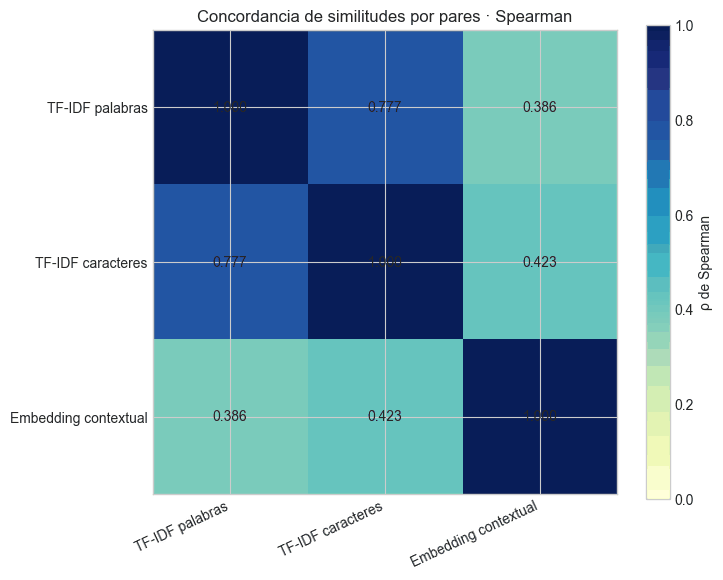

In [32]:
nombres_representaciones = list(similitudes)
correlacion_espacios = pd.DataFrame(
    np.eye(len(nombres_representaciones)),
    index=nombres_representaciones,
    columns=nombres_representaciones,
)
for i, nombre_i in enumerate(nombres_representaciones):
    for j in range(i + 1, len(nombres_representaciones)):
        nombre_j = nombres_representaciones[j]
        rho = spearmanr(
            similitudes[nombre_i][triangulo_superior],
            similitudes[nombre_j][triangulo_superior],
        ).statistic
        correlacion_espacios.loc[nombre_i, nombre_j] = rho
        correlacion_espacios.loc[nombre_j, nombre_i] = rho

resumen_componentes = pd.DataFrame(
    {
        "bloque": [
            "TF-IDF palabras 1–2", "TF-IDF caracteres 3–5",
            "Embedding contextual", "Descriptores estructurales z",
        ],
        "forma": [
            str(X_tfidf_palabras.shape), str(X_tfidf_caracteres.shape),
            str(X_contextual.shape), str(X_estructural.shape),
        ],
        "almacenamiento": ["disperso float32", "disperso float32", "denso float32", "denso float32"],
        "uso_principal": [
            "Expresiones y bigramas interpretables",
            "Variación ortográfica y fragmentos de nombres",
            "Proximidad semántica documental",
            "Control de longitud, estructura y edición",
        ],
        "limitacion_principal": [
            "No resuelve contexto ni sinonimia",
            "Fragmentos difíciles de interpretar aisladamente",
            "Dimensiones opacas y dominio no validado",
            "No codifica por sí solo el contenido semántico",
        ],
    }
)
display(correlacion_espacios.round(3))
display(resumen_componentes)

fig, ax = plt.subplots(figsize=(7.5, 6))
imagen = ax.imshow(correlacion_espacios, vmin=0, vmax=1, cmap="YlGnBu")
ax.set_xticks(range(len(nombres_representaciones)), nombres_representaciones, rotation=25, ha="right")
ax.set_yticks(range(len(nombres_representaciones)), nombres_representaciones)
for i in range(len(nombres_representaciones)):
    for j in range(len(nombres_representaciones)):
        ax.text(j, i, f"{correlacion_espacios.iloc[i, j]:.3f}", ha="center", va="center")
ax.set_title("Concordancia de similitudes por pares · Spearman")
fig.colorbar(imagen, ax=ax, label="ρ de Spearman")
fig.tight_layout()
plt.show()

**Lectura de complementariedad.** Las similitudes de palabras y caracteres tienen asociación alta (ρ=0,777) porque ambas dependen de la forma escrita. Sus diferencias justifican conservar la vista de caracteres: este método comparte raíces y variantes aunque no coincida el token completo. Las asociaciones del embedding contextual son bastante menores —ρ=0,386 con palabras y ρ=0,423 con caracteres—; por tanto, no es una copia densa de TF-IDF y agrega otra forma de ordenar proximidades. Tampoco sustituye la transparencia léxica.

La selección **exploratoria de esta fase** es deliberadamente plural: TF-IDF de palabras para interpretar expresiones, caracteres para tolerar variaciones ortográficas, *embeddings* para relaciones semánticas y descriptores para controlar la estructura. La coexistencia de bloques está sustentada por funciones distintas y por la concordancia incompleta entre sus espacios, no por acumular características sin criterio ni por la intención de concatenarlos para alimentar un modelo posterior.

### 18.5 Exportación, integridad y pruebas finales

Las matrices se exportan por separado para conservar su tipo eficiente. `indice_caracteristicas_fase3.csv` fija el orden de las 550 filas finales; los vocabularios relacionan cada columna dispersa con su forma observable; `configuracion_fase3.json` registra versiones, parámetros, revisión del codificador y el alcance demostrativo de los artefactos. Un manifiesto SHA-256 permite comprobar que ningún archivo cambió después de la ejecución. Estas salidas prueban la reproducibilidad de la Fase 3, pero la inferencia posterior no depende de cargarlas.

In [ ]:
SALIDAS_FASE3 = Path.cwd() / "salidas_fase3"
SALIDAS_FASE3.mkdir(parents=True, exist_ok=True)

indice_caracteristicas_fase3 = corpus_curado_fase3[
    [
        "cantico_id", "club_id", "nombre_corto", "region", "fuente",
        "titulo_referencia", "n_tokens_modelo", "n_tokens_lexicos_filtrados",
    ]
].merge(
    diagnostico_tokenizacion_curado,
    on="cantico_id", how="left", validate="one_to_one",
)
indice_caracteristicas_fase3.insert(
    0, "fila_matriz", np.arange(len(indice_caracteristicas_fase3))
)

rutas_fase3 = {
    "matriz_tfidf_palabras.npz": SALIDAS_FASE3 / "matriz_tfidf_palabras.npz",
    "matriz_tfidf_caracteres.npz": SALIDAS_FASE3 / "matriz_tfidf_caracteres.npz",
    "embeddings_contextuales.npy": SALIDAS_FASE3 / "embeddings_contextuales.npy",
    "descriptores_estructurales.npy": SALIDAS_FASE3 / "descriptores_estructurales.npy",
    "descriptores_estructurales_crudos.csv": SALIDAS_FASE3 / "descriptores_estructurales_crudos.csv",
    "vocabulario_tfidf_palabras.csv": SALIDAS_FASE3 / "vocabulario_tfidf_palabras.csv",
    "vocabulario_tfidf_caracteres.csv": SALIDAS_FASE3 / "vocabulario_tfidf_caracteres.csv",
    "indice_caracteristicas_fase3.csv": SALIDAS_FASE3 / "indice_caracteristicas_fase3.csv",
    "configuracion_fase3.json": SALIDAS_FASE3 / "configuracion_fase3.json",
    "revision_similitudes_fase3.xlsx": RUTA_REVISION_SIMILITUD_FASE3,
    "corpus_curado_fase3.csv": SALIDAS_FASE3 / "corpus_curado_fase3.csv",
    "decisiones_similitud_aplicadas_fase3.csv": SALIDAS_FASE3 / "decisiones_similitud_aplicadas_fase3.csv",
    "registros_excluidos_similitud_fase3.csv": SALIDAS_FASE3 / "registros_excluidos_similitud_fase3.csv",
}

sparse.save_npz(rutas_fase3["matriz_tfidf_palabras.npz"], X_tfidf_palabras_curado)
sparse.save_npz(rutas_fase3["matriz_tfidf_caracteres.npz"], X_tfidf_caracteres_curado)
np.save(rutas_fase3["embeddings_contextuales.npy"], X_contextual_curado, allow_pickle=False)
np.save(rutas_fase3["descriptores_estructurales.npy"], X_estructural_curado, allow_pickle=False)
descriptores_estructurales_curados.to_csv(
    rutas_fase3["descriptores_estructurales_crudos.csv"],
    index=False, encoding="utf-8-sig",
)
vocabulario_palabras_curado.reset_index(drop=True).to_csv(
    rutas_fase3["vocabulario_tfidf_palabras.csv"], index_label="columna_matriz",
    encoding="utf-8-sig",
)
vocabulario_caracteres_curado.reset_index(drop=True).to_csv(
    rutas_fase3["vocabulario_tfidf_caracteres.csv"], index_label="columna_matriz",
    encoding="utf-8-sig",
)
indice_caracteristicas_fase3.to_csv(
    rutas_fase3["indice_caracteristicas_fase3.csv"], index=False,
    encoding="utf-8-sig",
)

columnas_exportables_fase3 = [
    columna for columna in corpus_curado_fase3.columns
    if columna not in {"tokens_originales", "tokens_lexicos"}
]
corpus_curado_fase3[columnas_exportables_fase3].to_csv(
    rutas_fase3["corpus_curado_fase3.csv"], index=False, encoding="utf-8-sig"
)
bitacora_decisiones_fase3.to_csv(
    rutas_fase3["decisiones_similitud_aplicadas_fase3.csv"],
    index=False, encoding="utf-8-sig",
)
registros_excluidos_similitud_fase3.to_csv(
    rutas_fase3["registros_excluidos_similitud_fase3.csv"],
    index=False, encoding="utf-8-sig",
)

configuracion_fase3 = {
    "alcance": "exploracion del corpus y demostracion academica de extraccion de caracteristicas",
    "uso_como_entrada_del_modelo_final": False,
    "seleccion_del_modelo_de_entidades_y_afecto": "pendiente para la fase siguiente",
    "semilla": SEMILLA_FASE3,
    "n_documentos_antes_auditoria_similitud": len(corpus_preparado),
    "n_documentos": len(corpus_curado_fase3),
    "decisiones_similitud": {
        "archivo": "datos/revision_similitudes_fase3_llenado.xlsx",
        "sha256": "AE30C4071870CB8D90F0956187E0819D3039D118E2CCA88D35B4C7E49BE17DDA",
        "pares_revisados": len(decisiones_similitud_fase3),
        "ids_excluidos": len(ids_excluir_fase3),
    },
    "orden_filas": "indice_caracteristicas_fase3.csv::fila_matriz",
    "paquetes": versiones_ejecucion_fase3,
    "torch_preinstalado_reutilizado": TORCH_PREINSTALADO,
    "modelo_contextual": {
        "id": MODELO_CONTEXTUAL_ID,
        "revision": MODELO_CONTEXTUAL_REVISION,
        "dimension": int(X_contextual.shape[1]),
        "max_seq_length": limite_modelo,
        "max_tokens_contenido_por_fragmento": limite_contenido,
        "agregacion": "media ponderada por subpalabras y normalizacion L2",
    },
    "tfidf_palabras": {
        "ngram_range": [1, 2], "min_df": 1, "max_df": 0.95,
        "sublinear_tf": True, "norm": "l2",
    },
    "tfidf_caracteres": {
        "analyzer": "char_wb", "ngram_range": [3, 5], "min_df": 2,
        "max_df": 0.98, "max_features": 8000,
        "sublinear_tf": True, "norm": "l2",
    },
    "descriptores_estructurales": list(descriptores_estructurales.columns),
    "dispositivo_ejecucion_documentado": NOMBRE_DISPOSITIVO_FASE3,
}
rutas_fase3["configuracion_fase3.json"].write_text(
    json.dumps(configuracion_fase3, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# Pruebas de forma, contenido y correspondencia de filas.
n_documentos = len(corpus_curado_fase3)
assert X_tfidf_palabras_curado.shape[0] == n_documentos
assert X_tfidf_caracteres_curado.shape[0] == n_documentos
assert X_contextual_curado.shape == (n_documentos, 384)
assert X_estructural_curado.shape == (n_documentos, len(descriptores_estructurales_curados.columns))
assert X_tfidf_palabras_curado.dtype == np.float32
assert X_tfidf_caracteres_curado.dtype == np.float32
assert X_contextual_curado.dtype == np.float32
assert X_estructural_curado.dtype == np.float32
assert (X_tfidf_palabras_curado.getnnz(axis=1) > 0).all()
assert (X_tfidf_caracteres_curado.getnnz(axis=1) > 0).all()
assert np.isfinite(X_tfidf_palabras_curado.data).all()
assert np.isfinite(X_tfidf_caracteres_curado.data).all()
assert np.isfinite(X_contextual_curado).all()
assert np.isfinite(X_estructural_curado).all()
assert np.allclose(
    np.sqrt(X_tfidf_palabras_curado.multiply(X_tfidf_palabras_curado).sum(axis=1)).A1,
    1.0, atol=1e-5,
)
assert np.allclose(
    np.sqrt(X_tfidf_caracteres_curado.multiply(X_tfidf_caracteres_curado).sum(axis=1)).A1,
    1.0, atol=1e-5,
)
assert np.allclose(np.linalg.norm(X_contextual_curado, axis=1), 1.0, atol=1e-5)
assert indice_caracteristicas_fase3["cantico_id"].tolist() == corpus_curado_fase3[
    "cantico_id"
].tolist()
assert diagnostico_tokenizacion_curado["n_subpalabras"].gt(0).all()
assert len(indices_fragmentos) == len(textos_fragmentos)
assert all(0 < peso <= limite_contenido for _, peso in indices_fragmentos)
assert diagnostico_tokenizacion["max_subpalabras_fragmento"].le(
    limite_contenido
).all()
assert sum(peso for _, peso in indices_fragmentos) == diagnostico_tokenizacion[
    "n_subpalabras"
].sum()
assert set(indice for indice, _ in indices_fragmentos) == set(
    range(len(corpus_preparado))
)

# Recarga: los archivos publicados conservan forma y tipo.
assert sparse.load_npz(rutas_fase3["matriz_tfidf_palabras.npz"]).shape == X_tfidf_palabras_curado.shape
assert sparse.load_npz(rutas_fase3["matriz_tfidf_caracteres.npz"]).shape == X_tfidf_caracteres_curado.shape
assert np.load(rutas_fase3["embeddings_contextuales.npy"], allow_pickle=False).shape == X_contextual_curado.shape
assert np.load(rutas_fase3["descriptores_estructurales.npy"], allow_pickle=False).shape == X_estructural_curado.shape

manifiesto_fase3 = pd.DataFrame(
    [
        {
            "archivo": nombre,
            "bytes": ruta.stat().st_size,
            "sha256": hashlib.sha256(ruta.read_bytes()).hexdigest().upper(),
        }
        for nombre, ruta in rutas_fase3.items()
    ]
)
ruta_manifiesto_fase3 = SALIDAS_FASE3 / "MANIFIESTO_SHA256_FASE3.csv"
manifiesto_fase3.to_csv(ruta_manifiesto_fase3, index=False, encoding="utf-8-sig")

controles_fase3 = pd.DataFrame(
    {
        "control": [
            "Documentos alineados", "TF-IDF palabras sin filas vacías",
            "TF-IDF caracteres sin filas vacías", "Embeddings finitos",
            "Embeddings con norma unitaria", "Subpalabras desconocidas",
            "Textos fragmentados sin truncar", "Archivos producidos",
            "Hashes SHA-256 generados", "Registros listos para inferencia",
        ],
        "resultado": [
            n_documentos, int((X_tfidf_palabras_curado.getnnz(axis=1) > 0).sum()),
            int((X_tfidf_caracteres_curado.getnnz(axis=1) > 0).sum()),
            bool(np.isfinite(X_contextual_curado).all()),
            bool(np.allclose(np.linalg.norm(X_contextual_curado, axis=1), 1.0, atol=1e-5)),
            int(diagnostico_tokenizacion_curado["n_tokens_desconocidos"].sum()),
            int(diagnostico_tokenizacion_curado["n_fragmentos"].gt(1).sum()),
            len(rutas_fase3) + 1, len(manifiesto_fase3),
            int(corpus_curado_fase3["apto_inferencia"].sum()),
        ],
    }
)
display(controles_fase3)
display(manifiesto_fase3)
print(f"Salidas de Fase 3: {SALIDAS_FASE3.resolve()}")
print("Pruebas de extracción de características: OK")

## Conclusiones de la Fase 3

1. Se implementaron, como exploración del corpus y demostración académica, cuatro bloques alineados inicialmente para los 566 cánticos de la Fase 2 y actualizados para los 550 registros del corpus final: TF-IDF de palabras, TF-IDF de caracteres, *embedding* contextual multilingüe y diez descriptores estructurales.
2. La representación léxica conserva expresiones observables y negaciones; la subléxica tolera variantes y apodos; la contextual incorpora proximidad semántica; la estructural permite controlar longitud y huellas editoriales. Ningún bloque se presenta como universalmente superior ni como predictor de entidades o afecto.
3. Las características explícitas muestran cómo podría construirse una matriz `X` para un modelo propio, pero ese escenario requeriría etiquetas `y`, particiones independientes y evaluación. No se ejecuta porque el corpus carece de etiquetas y el alcance de la Fase 1 excluye entrenamiento propio y evaluación humana.
4. El codificador contextual demostrativo está fijado por nombre y revisión. No es el modelo seleccionado para las tareas finales. Su fragmentación procesa la totalidad de los 80 textos que superan una secuencia, en lugar de truncarlos silenciosamente.
5. Las relaciones entre espacios muestran complementariedad: palabras y caracteres ordenan los pares de forma parecida, mientras el *embedding* contextual conserva coincidencia parcial y añade relaciones diferentes. Esto justifica mantener las vistas separadas dentro de la exploración, no concatenarlas como entrada de inferencia.
6. Las proyecciones bidimensionales no separan regiones de manera nítida y no deben forzarse como evidencia territorial. La cobertura desigual por club y fuente continúa siendo una limitación central.
7. Las matrices finales contienen 550 filas, son eficientes, contienen valores finitos, no tienen filas vacías y conservan orden verificable por `cantico_id`. Los archivos exportados quedan acompañados por vocabularios, configuración y hashes como evidencia reproducible de esta entrega; cargarlos no es requisito para la inferencia posterior.
8. La auditoría combina pertenencia al mismo club, una similitud mayor que 0,85 y corroboración mayor que 0,70 en otro espacio. Los 19 pares fueron revisados: 17 decisiones de equivalencia y 2 de conservación de ambos registros. La aplicación por componentes excluye 16 IDs únicos y consolida un corpus final de 550 cánticos, con bitácora y sin alterar las letras originales conservadas.
9. En coherencia con las secciones 2.4 y 2.6 y con las conclusiones de la Fase 1, el recurso preentrenado que se elija recibirá `texto_modelo` y realizará internamente su tokenización y construcción de representaciones. Las variables principales para el análisis serán sus salidas específicas —menciones, tipos, etiquetas y puntuaciones—, no las matrices construidas aquí.
10. La selección del modelo y de las categorías de entidades o afecto queda deliberadamente pendiente para la fase siguiente. Esta entrega no compromete una arquitectura o estrategia particular.


# Parte IV · Fase 4 — Modelamiento con modelos preentrenados: afecto, dimensiones discursivas y entidades

Esta parte continúa el mismo flujo de las Partes I, II y III. Recibe en memoria `corpus_curado_fase3`, producto de la [sección 18.3](#183-aplicación-reproducible-de-las-decisiones-y-corpus-final), y conserva sin cambios todas las decisiones anteriores: la adquisición y sus 600 registros, las 57 decisiones de curaduría de la Fase 2, la reasignación de `CAN0352`, las 19 decisiones de similitud de la Fase 3 y el corpus final de **550 cánticos de 17 clubes**. No se vuelve a descargar un corpus procesado ni se sustituye `letra_original`.

## 19. Propósito, alcance y correspondencia con la rúbrica

La Fase 1 dejó establecido el enfoque que aquí se implementa. La [sección 2.4](#24-solución-técnica-concreta) previó aplicar a `texto_modelo` un reconocimiento preentrenado de entidades, una clasificación semántica de las menciones y una caracterización afectiva más granular que la polaridad; la [sección 2.6](#26-justificación-del-uso-de-modelos-preentrenados) justificó por qué no se entrenaría un modelo propio, y la [sección 2.5](#25-alcance) excluyó el ajuste fino, la anotación manual y la evaluación humana. La Fase 3 añadió un compromiso técnico: sus matrices TF-IDF, *embeddings* y descriptores estructurales fueron una demostración académica y **no** son la entrada de los modelos de esta fase (véanse la [sección 13](#13-propósito-alcance-y-correspondencia-con-la-rúbrica) y la conclusión 9 de la Fase 3). Cada modelo recibe `texto_modelo` y aplica su propio tokenizador.

El propósito de la Fase 4 es **seleccionar, aplicar y comparar modelos preentrenados** para tres tareas separadas —polaridad ternaria como línea base, emociones y dimensiones afectivas o discursivas, y reconocimiento de entidades— y después cruzar sus salidas con las variables de club y región. La selección se apoya en evidencia de dos tipos que no se mezclan: las métricas publicadas por los autores en sus propios *benchmarks* y el comportamiento observable de cada modelo sobre los 550 cánticos.

| Criterio de la rúbrica | Cómo se atiende en un proyecto sin entrenamiento | Evidencia en esta fase |
|---|---|---|
| Implementación de modelo | Doce modelos preentrenados de cuatro familias, con identificador y revisión fijados, cargados de forma modular | Secciones 21, 22 y 24 |
| Entrenamiento | No hay entrenamiento ni ajuste fino por decisión metodológica aprobada. Lo equivalente es una **aplicación correcta**: entrada adecuada, longitudes controladas sin truncamiento silencioso, agregación explícita y controles de integridad | Secciones 23, 24 y 32 |
| Selección de hiperparámetros | Hiperparámetros de **inferencia**: formulación de las hipótesis zero-shot, regla de puntuación NLI, umbral multietiqueta, estrategia de agregación de subpalabras en NER, puntuación mínima de entidades, umbrales por etiqueta y agregación entre fragmentos | Secciones 26, 27, 29 y 33 |
| Comparación de modelos | Comparación dentro de cada tarea con métricas externas, validez convergente débil, acuerdo entre modelos, capacidad discriminante y costo; la alternativa elegida mejora esos indicadores frente a las descartadas | Secciones 25 a 29 y 33 |

**Decisión metodológica.** Como no existe un conjunto de prueba etiquetado para cánticos colombianos, esta fase no reporta *accuracy*, *precision*, *recall* ni F1 propios. Las cifras de ese tipo que aparecen provienen de las fichas o artículos de cada modelo y se refieren a sus *benchmarks*. Las comparaciones internas usan indicadores definidos antes de observar las predicciones y se interpretan como evidencia de adecuación, no de exactitud.

## 20. Tipo de modelamiento

El problema combina tareas supervisadas **ya resueltas por terceros** con un análisis descriptivo posterior:

| Tarea del proyecto | Tipo de modelo | Salida por cántico | Motivo |
|---|---|---|---|
| Polaridad (línea base) | Clasificación de texto de una etiqueta | Probabilidades de negativo, neutral y positivo | Punto de comparación con el enfoque tradicional |
| Emociones especializadas | Clasificación de una etiqueta o multietiqueta | Distribución sobre 7, 11 o 28 emociones, según el modelo | Taxonomías aprendidas con datos anotados por humanos o sintéticos |
| Dimensiones afectivas y discursivas | Clasificación **cero disparos** mediante inferencia en lenguaje natural (NLI) | Probabilidad de implicación para 33 hipótesis agrupadas en 4 dimensiones | Permite definir categorías propias sin reentrenar (Yin et al., 2019) |
| Entidades y referentes | Clasificación de *tokens* (NER) más tipificación NLI de cada mención | Mención, posición, tipo, puntuación y categoría del dominio | Identifica de quién o de qué se habla |

Se descartan la regresión, porque no hay una variable continua que predecir; el agrupamiento y los modelos de tópicos, porque describirían semejanzas léxicas sin producir las categorías afectivas o de entidades que exige la pregunta de trabajo; y el aprendizaje supervisado propio, por las tres razones de la [sección 2.6](#26-justificación-del-uso-de-modelos-preentrenados). La clasificación zero-shot con NLI funciona así: el cántico actúa como **premisa**, cada categoría se redacta como una **hipótesis** en español y el modelo estima la probabilidad de que la premisa implique la hipótesis. Esa probabilidad es la puntuación de la etiqueta. Como cada hipótesis se evalúa por separado, un mismo cántico puede recibir varias etiquetas: la clasificación es **multietiqueta** (Laurer et al., 2024; Yin et al., 2019).

En NER, un modelo asigna a cada subpalabra una etiqueta del esquema BIO (inicio, interior o fuera de una entidad) y luego se agrupan las subpalabras en menciones completas. Los modelos disponibles para español se entrenaron con noticias o Wikipedia y reconocen tipos generales —persona, lugar, organización y otros—. Para obtener categorías del dominio (club, hinchada, autoridad, animal o símbolo) se aplica después una **tipificación semántica** de cada mención con el mismo mecanismo NLI, en la línea de la tipificación de entidades por implicación textual (Li et al., 2022). Esta es la operación prevista en el paso 4 de la [sección 2.4](#24-solución-técnica-concreta).

## 21. Entorno reproducible, dispositivo y población de entrada

### 21.1 Dependencias y dispositivo

La Fase 4 **no instala paquetes nuevos**. Reutiliza la instalación aislada y verificada de la [sección 15](#15-entorno-reproducible-y-cómputo) —`transformers` 4.57.6, `tokenizers` 0.22.1, `huggingface-hub` 0.36.0, `safetensors` 0.6.2, `scikit-learn` 1.7.2 y `scipy` 1.16.3— y vuelve a comprobar esas versiones antes de cargar cualquier modelo (Wolf et al., 2020). La biblioteca GLiNER se evaluó como alternativa para entidades de tipo abierto, pero sus versiones compatibles con `transformers` 4.57.6 exigen `onnxruntime` o importan ModernBERT, que no funciona con Python 3.14; incorporarla habría condicionado la reproducibilidad a un entorno particular (Zaratiana et al., 2024). Su función se cubre con la tipificación NLI descrita en la [sección 20](#20-tipo-de-modelamiento).

Si el entorno expone CUDA, como una NVIDIA L4 en Colab, los modelos se ejecutan en GPU con lotes mayores. Si no, el cuaderno continúa en CPU y emite una advertencia de lentitud. Las puntuaciones pueden diferir en decimales lejanos entre CPU y GPU; por eso las decisiones de esta fase se basan en comparaciones agregadas y no en empates numéricos exactos.

Cada modelo se identifica por repositorio y **revisión** (el *commit* de Hugging Face). Cuando una revisión solo publica `pytorch_model.bin`, `transformers` carga ese archivo, pero además intenta descargar en segundo plano una conversión a `safetensors` desde otra rama del repositorio. El cuaderno desactiva ese comportamiento y declara el formato de pesos que usa cada modelo, de modo que la caché contenga únicamente archivos de las revisiones fijadas. Los pesos son artefactos de software descargados de su repositorio oficial; no forman parte de los datos del proyecto.

In [ ]:
import gc
import platform
from importlib.metadata import version as version_paquete

import matplotlib
import transformers
from scipy.stats import kendalltau, spearmanr
from sklearn.metrics import cohen_kappa_score, roc_auc_score
from transformers import (
    AutoModelForSequenceClassification,
    AutoModelForTokenClassification,
    AutoTokenizer,
    pipeline,
)
from huggingface_hub import list_repo_files
from transformers.utils import logging as registro_transformers

registro_transformers.set_verbosity_error()

# Con una revisión fijada, transformers carga pytorch_model.bin de esa revisión,
# pero además lanza en segundo plano una descarga de conversiones a safetensors
# publicadas en ramas de solicitudes de cambio. Se desactiva para que la caché
# contenga únicamente los archivos de las revisiones declaradas.
os.environ["DISABLE_SAFETENSORS_CONVERSION"] = "true"

# La Fase 4 no instala paquetes nuevos: reutiliza exactamente las versiones
# fijadas y verificadas en la sección 15. Esta comprobación impide mezclar
# resultados producidos con otra versión de transformers o tokenizers.
for paquete, version_esperada in PAQUETES_FASE3.items():
    assert version_paquete(paquete) == version_esperada, paquete

SEMILLA_FASE4 = SEMILLA_FASE3
np.random.seed(SEMILLA_FASE4)
torch.manual_seed(SEMILLA_FASE4)

if torch.cuda.is_available():
    DISPOSITIVO_FASE4 = "cuda"
    NOMBRE_DISPOSITIVO_FASE4 = torch.cuda.get_device_name(0)
    LOTE_CLASIFICACION, LOTE_NLI, LOTE_NER = 64, 64, 32
    torch.cuda.manual_seed_all(SEMILLA_FASE4)
    if "L4" not in NOMBRE_DISPOSITIVO_FASE4:
        warnings.warn(
            f"Se detectó {NOMBRE_DISPOSITIVO_FASE4}. El cuaderno funciona con esta GPU; "
            "los tamaños de lote se definieron pensando en una NVIDIA L4.",
            RuntimeWarning,
        )
else:
    DISPOSITIVO_FASE4 = "cpu"
    NOMBRE_DISPOSITIVO_FASE4 = "CPU"
    LOTE_CLASIFICACION, LOTE_NLI, LOTE_NER = 16, 16, 8
    warnings.warn(
        "No se detectó una GPU CUDA. La Fase 4 se ejecutará completa en CPU: "
        "en la ejecución de referencia, la fase completa tardó cerca de hora y media, incluida la descarga de los modelos. "
        "Con una NVIDIA L4 el mismo código usa lotes mayores y es mucho más rápido.",
        RuntimeWarning,
    )

# El inferidor NER de transformers espera un índice de dispositivo.
DISPOSITIVO_PIPELINE_FASE4 = 0 if DISPOSITIVO_FASE4 == "cuda" else -1

SALIDAS_FASE4 = Path.cwd() / "salidas_fase4"
CACHE_INFERENCIA_FASE4 = SALIDAS_FASE4 / "cache_inferencia"
CACHE_INFERENCIA_FASE4.mkdir(parents=True, exist_ok=True)
CACHE_MODELOS_FASE4 = CACHE_MODELO_FASE3

ENTORNO_FASE4 = {
    "python": platform.python_version(),
    "torch": torch.__version__,
    "transformers": transformers.__version__,
    "tokenizers": version_paquete("tokenizers"),
    "huggingface-hub": version_paquete("huggingface-hub"),
    "safetensors": version_paquete("safetensors"),
    "scikit-learn": version_paquete("scikit-learn"),
    "scipy": version_paquete("scipy"),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__,
    "dispositivo": NOMBRE_DISPOSITIVO_FASE4,
    "hilos_cpu_torch": torch.get_num_threads(),
}
display(pd.DataFrame(ENTORNO_FASE4.items(), columns=["componente", "version_o_valor"]))
print(
    f"Dispositivo de inferencia: {NOMBRE_DISPOSITIVO_FASE4} · lotes "
    f"clasificación={LOTE_CLASIFICACION}, NLI={LOTE_NLI}, NER={LOTE_NER}"
)

### 21.2 Población de entrada

La población es exactamente el corpus final de la Fase 3. La celda siguiente comprueba que haya 550 filas, identificadores únicos, ningún texto vacío, 17 clubes, 3 regiones, la reasignación de `CAN0352` y la ausencia de los 16 identificadores excluidos en la auditoría de similitud. También calcula una huella SHA-256 de los pares `cantico_id`–`texto_modelo`: esa huella forma parte de la clave de caché de cada inferencia, así que una predicción guardada nunca se reutiliza si el texto de entrada cambia.

In [ ]:
COLUMNAS_TEXTO_FASE4 = [
    "cantico_id", "club_id", "nombre_corto", "ciudad_sede", "region", "fuente",
    "titulo_referencia", "texto_modelo", "n_tokens_modelo",
    "proporcion_tokens_mayusculas", "estrato_longitud",
]
COLUMNAS_CLUB_FASE4 = [
    "club_id", "departamento", "estadio_principal", "anio_fundacion",
    "titulos_liga_hasta_2026_I", "subcampeonatos_liga_hasta_2026_I",
    "torneos_disputados_periodo", "clasificaciones_fase_final_periodo",
    "tasa_clasificacion", "promedio_asistencia_2025",
    "partidos_con_dato_asistencia", "seguidores_instagram",
]
corpus_fase4 = (
    corpus_curado_fase3[COLUMNAS_TEXTO_FASE4]
    .merge(clubes[COLUMNAS_CLUB_FASE4], on="club_id", how="left", validate="many_to_one")
    .reset_index(drop=True)
)
corpus_fase4["estrato_longitud"] = corpus_fase4["estrato_longitud"].astype(str)
corpus_fase4["texto_mayusculas"] = corpus_fase4["proporcion_tokens_mayusculas"].ge(0.5)

# Controles de población: la Fase 4 recibe exactamente el corpus final de la Fase 3.
assert len(corpus_fase4) == len(corpus_curado_fase3) == 550
assert corpus_fase4["cantico_id"].is_unique
assert corpus_fase4["cantico_id"].tolist() == corpus_curado_fase3["cantico_id"].tolist()
assert corpus_fase4["texto_modelo"].notna().all()
assert corpus_fase4["texto_modelo"].str.strip().ne("").all()
assert not set(ids_excluir_fase3) & set(corpus_fase4["cantico_id"])
assert corpus_fase4["club_id"].nunique() == 17
assert corpus_fase4["region"].nunique() == 3
assert corpus_fase4.loc[corpus_fase4["cantico_id"].eq("CAN0352"), "club_id"].eq("CLU008").all()
assert corpus_fase4["texto_modelo"].equals(corpus_curado_fase3["texto_modelo"])

IDS_FASE4 = corpus_fase4["cantico_id"].tolist()
TEXTOS_FASE4 = corpus_fase4.set_index("cantico_id")["texto_modelo"]
HUELLA_ENTRADA_FASE4 = hashlib.sha256(
    "\n".join(f"{i}\t{t}" for i, t in TEXTOS_FASE4.items()).encode("utf-8")
).hexdigest().upper()

resumen_entrada_fase4 = pd.DataFrame(
    {
        "indicador": [
            "Cánticos de entrada", "Identificadores únicos", "Clubes", "Regiones",
            "Fuentes", "Textos vacíos", "Tokens en texto_modelo",
            "Mediana de tokens", "Máximo de tokens",
            "Textos con mayoría de palabras en mayúscula", "Huella SHA-256 de la entrada",
        ],
        "valor": [
            len(corpus_fase4), corpus_fase4["cantico_id"].nunique(),
            corpus_fase4["club_id"].nunique(), corpus_fase4["region"].nunique(),
            corpus_fase4["fuente"].nunique(),
            int(corpus_fase4["texto_modelo"].str.strip().eq("").sum()),
            int(corpus_fase4["n_tokens_modelo"].sum()),
            corpus_fase4["n_tokens_modelo"].median(),
            int(corpus_fase4["n_tokens_modelo"].max()),
            int(corpus_fase4["texto_mayusculas"].sum()),
            HUELLA_ENTRADA_FASE4[:16] + "…",
        ],
    }
)
display(resumen_entrada_fase4)
display(
    corpus_fase4.groupby("region", as_index=False)
    .agg(canticos=("cantico_id", "size"), clubes=("club_id", "nunique"))
    .assign(participacion_pct=lambda t: (t["canticos"] / len(corpus_fase4) * 100).round(1))
)

**Lectura de la población.** La entrada coincide con el corpus final: 550 cánticos con identificadores únicos, 17 clubes, tres regiones, cuatro fuentes y ningún texto vacío. `texto_modelo` suma 30.265 tokens superficiales; la mediana es de 46 por cántico y el máximo de 695. Andina aporta 437 textos de 11 clubes (79,5 %), Pacífica 77 de 3 clubes (14,0 %) y Caribe 36 de 3 clubes (6,5 %). Además, 35 cánticos tienen mayoría de palabras en mayúscula; esta huella editorial, documentada en la Fase 2, se vuelve relevante en NER porque los reconocedores de entidades usan la capitalización como señal.

## 22. Modelos candidatos y evidencia externa

### 22.1 Criterios de búsqueda y registro

La búsqueda se hizo en Hugging Face el 22 de septiembre de 2026 y se limitó a modelos públicos, con ficha consultable, compatibles con la versión fijada de `transformers` y con soporte declarado para español. Para cada candidato se revisaron la ficha, los archivos de resultados publicados en la misma revisión y, cuando la ficha remitía a un artículo, la fuente original. El registro siguiente es la **única** fuente de identificadores y revisiones que usa el código; las métricas se transcriben tal como aparecen en sus fuentes. Las fichas consultadas son las de RoBERTuito para polaridad y para emociones (pysentimiento, s. f.-a, s. f.-b), XLM-T multilingüe (Cardiff NLP, s. f.), XLM-RoBERTa para emociones en español (daveni, s. f.), GoEmotions multilingüe (AnasAlokla, s. f.), el clasificador de tabularis (tabularis.ai, s. f.), BGE-M3 zero-shot y mDeBERTa-v3 (Laurer, s. f.-a, s. f.-b), BETO-XNLI (Recognai, s. f.), BETO-NER (Romero, s. f.), XLM-RoBERTa-large NER (MMG, s. f.) y WikiNEuRal (Babelscape, s. f.).

Un caso muestra por qué esta verificación es necesaria. La ficha de `daveni/twitter-xlm-roberta-emotion-es` y el resumen del artículo de sus autores describen el 71,70 % como un F1 *macro*; sin embargo, la tabla 5 del mismo artículo lo presenta como **F1 ponderado**, junto con una *accuracy* de 72,77 % en la prueba de EmoEvalEs 2021 (Vera et al., 2021). En la tabla se registra el valor según la tabla de resultados.

In [ ]:
def ficha(repo, revision):
    return f"https://huggingface.co/{repo}/blob/{revision}/README.md"


# Registro único de los modelos ejecutados. Las métricas se transcriben de la
# ficha o de los archivos de resultados publicados en la misma revisión fijada;
# "no reportada" significa que la fuente no ofrece ese valor.
MODELOS_FASE4 = {
    "sent_robertuito": dict(
        max_longitud=128,
        tarea="Sentimiento ternario", id="pysentimiento/robertuito-sentiment-analysis",
        revision="a2cc0f67ebd705c55191e25a05ba23d885fcc09b",
        arquitectura="RoBERTa-base (RoBERTuito, preentrenado con tuits en español)",
        idioma="Español", dataset="TASS 2020: ~5 mil tuits de varias variedades del español",
        etiquetas="NEG, NEU, POS (una etiqueta)", precision="0,715 (macro)", recall="0,704 (macro)",
        f1="0,707 (macro); 0,705 ± 0,003 en la ficha", accuracy="0,715",
        benchmark="Prueba de TASS 2020 (tuits)",
        fuente_metrica="test_results.json y tabla de resultados de la ficha",
        licencia="No declarada en la ficha", longitud="128 subpalabras",
        observaciones="Modelo de dominio social en español; su límite corto exige fragmentar letras largas",
    ),
    "sent_xlmt": dict(
        max_longitud=512,
        tarea="Sentimiento ternario", id="cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual",
        revision="82107f4ccba672c9ab1eee538e727e462cad21de",
        arquitectura="XLM-RoBERTa-base (XLM-T, preentrenado con ~198 millones de tuits)",
        idioma="Multilingüe; ajuste en 8 idiomas, incluido español",
        dataset="tweet_sentiment_multilingual (UMSAB)",
        etiquetas="negative, neutral, positive (una etiqueta)", precision="No reportada",
        recall="No reportada", f1="0,693 (macro)", accuracy="0,693",
        benchmark="Prueba conjunta de 8 idiomas; no desagrega español",
        fuente_metrica="metric.json y model-index de la ficha",
        licencia="No declarada en la ficha", longitud="512 subpalabras",
        observaciones="Alternativa multilingüe al baseline en español",
    ),
    "emo_robertuito": dict(
        max_longitud=128,
        tarea="Emociones especializadas", id="pysentimiento/robertuito-emotion-analysis",
        revision="bcd6835f4d1ab1a061bd7437c9d762623c8437ad",
        arquitectura="RoBERTa-base (RoBERTuito)", idioma="Español",
        dataset="EmoEvent (TASS 2020, tarea 2): tuits en español",
        etiquetas="anger, disgust, fear, joy, sadness, surprise, others (una etiqueta)",
        precision="0,580 (macro)", recall="0,543 (macro)",
        f1="0,558 (macro); 0,560 ± 0,010 en la ficha; F1 de disgust = 0,000", accuracy="0,732",
        benchmark="Prueba de EmoEvent (tuits)",
        fuente_metrica="test_results.json y tabla de resultados de la ficha",
        licencia="No declarada en la ficha", longitud="128 subpalabras",
        observaciones="Seis emociones de Ekman más una clase residual",
    ),
    "emo_xlmt_es": dict(
        max_longitud=512,
        tarea="Emociones especializadas", id="daveni/twitter-xlm-roberta-emotion-es",
        revision="ab57a1137b2eb1f6c90fc77b0a4c4ced7dbd4d60",
        arquitectura="XLM-RoBERTa-base (XLM-T)", idioma="Español",
        dataset="EmoEvalEs, IberLEF 2021 (tuits en español)",
        etiquetas="anger, disgust, fear, joy, sadness, surprise, others (una etiqueta)",
        precision="No reportada", recall="No reportada",
        f1="0,717 (ponderado; la ficha lo describe como macro)", accuracy="0,728",
        benchmark="Prueba de EmoEvalEs 2021",
        fuente_metrica="Vera et al. (2021), tabla 5; ficha del modelo",
        licencia="No declarada en la ficha", longitud="512 subpalabras",
        observaciones="Misma taxonomía que RoBERTuito; permite medir acuerdo entre modelos",
    ),
    "emo_goemotions": dict(
        max_longitud=512,
        tarea="Emociones especializadas", id="AnasAlokla/multilingual_go_emotions_V1.1",
        revision="315b22654fb96b4a3ec0ba3d091f9b897e9f9c10",
        arquitectura="BERT multilingüe base (mBERT cased)",
        idioma="Multilingüe: árabe, inglés, francés, español, neerlandés y turco",
        dataset="multilingual_go_emotions: GoEmotions con versiones en otros idiomas",
        etiquetas="27 emociones de GoEmotions + neutral (multietiqueta)",
        precision="No reportada en agregado", recall="No reportada en agregado",
        f1="0,398 (macro); 0,481 (micro); F1 de pride = 0,301", accuracy="0,963 (por etiqueta)",
        benchmark="Partición de prueba del propio conjunto multilingüe; no desagrega español",
        fuente_metrica="test_evaluation.json y tabla de umbrales de la ficha",
        licencia="MIT", longitud="512 subpalabras",
        observaciones="Taxonomía amplia; la ficha no documenta cómo se obtuvieron los textos en español",
    ),
    "emo_tabularis": dict(
        max_longitud=192,
        tarea="Emociones especializadas", id="tabularisai/multilingual-emotion-classification",
        revision="a2b9b4d9640c53e84ab7abdd2a66146d3dafb10c",
        arquitectura="XLM-RoBERTa-base", idioma="Multilingüe: 23 idiomas, incluido español",
        dataset="Datos sintéticos multilingües generados con modelos de lenguaje",
        etiquetas="anger, contempt, disgust, fear, frustration, gratitude, joy, love, neutral, sadness, surprise (multietiqueta)",
        precision="No reportada", recall="No reportada", f1="0,839 (macro); 0,840 (micro)",
        accuracy="0,640 (coincidencia exacta del conjunto)",
        benchmark="Prueba sintética multilingüe de 11.500 filas; no es un corpus humano",
        fuente_metrica="Tabla de evaluación de la ficha y Borisov (2026)",
        licencia="CC BY-NC 4.0", longitud="512 posiciones; la ficha entrena e infiere con 192",
        observaciones="Incluye desprecio y frustración; métricas no comparables con benchmarks humanos",
    ),
    "nli_mdeberta": dict(
        max_longitud=512,
        tarea="Zero-shot NLI", id="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
        revision="b5113eb38ab63efdd7f280f8c144ea8b13f978ce",
        arquitectura="mDeBERTa-v3-base", idioma="Multilingüe: 100 idiomas de preentrenamiento; NLI en 27",
        dataset="XNLI + multilingual-NLI-26lang-2mil7 (traducción automática de MNLI, ANLI, FEVER, LingNLI y WANLI)",
        etiquetas="entailment, neutral, contradiction", precision="No reportada", recall="No reportada",
        f1="No reportada", accuracy="0,832 en XNLI-es",
        benchmark="XNLI, prueba en español (5.010 pares)", fuente_metrica="Tabla de evaluación de la ficha",
        licencia="MIT", longitud="512 subpalabras",
        observaciones="Modelo NLI multilingüe de referencia para clasificación cero disparos",
    ),
    "nli_bgem3": dict(
        max_longitud=512,
        tarea="Zero-shot NLI", id="MoritzLaurer/bge-m3-zeroshot-v2.0",
        revision="9abf1c8aaeb82a2447809c20753ed0b106b76652",
        arquitectura="BGE-M3 (arquitectura XLM-RoBERTa-large)", idioma="Multilingüe",
        dataset="Mezcla de NLI (MNLI, FEVER, ANLI, WANLI, LingNLI) y tareas de clasificación reformuladas",
        etiquetas="entailment, not_entailment", precision="No reportada", recall="No reportada",
        f1="0,803: media de F1 macro en 28 tareas en inglés (modalidad few-shot)", accuracy="No reportada",
        benchmark="28 tareas en inglés; incluye hasta 500 ejemplos por clase de esas tareas",
        fuente_metrica="Tabla de métricas de la ficha; Laurer et al. (2023)",
        licencia="MIT", longitud="8.192 subpalabras (aquí se limita a 512 para comparar)",
        observaciones="Clasificador universal; no reporta desempeño en español",
    ),
    "nli_beto": dict(
        max_longitud=512,
        tarea="Zero-shot NLI", id="Recognai/bert-base-spanish-wwm-cased-xnli",
        revision="e44f774ea40ee8202311d9e5448263f176e04796",
        arquitectura="BETO (BERT-base en español, cased)", idioma="Español",
        dataset="Porción en español de XNLI", etiquetas="entailment, neutral, contradiction",
        precision="No reportada", recall="No reportada", f1="No reportada", accuracy="0,799 en XNLI-es",
        benchmark="XNLI, prueba en español", fuente_metrica="Tabla de evaluación de la ficha",
        licencia="MIT", longitud="512 subpalabras",
        observaciones="Alternativa monolingüe en español",
    ),
    "ner_beto": dict(
        max_longitud=512,
        tarea="NER", id="mrm8488/bert-spanish-cased-finetuned-ner",
        revision="b11721d41d9e948da32fcdabeeef4fb0f3ebcdf7",
        arquitectura="BETO (BERT-base en español, cased)", idioma="Español",
        dataset="CoNLL-2002, porción en español (noticias)", etiquetas="PER, LOC, ORG, MISC",
        precision="0,895", recall="0,906", f1="0,901 (0,902 en desarrollo según la ficha)",
        accuracy="No reportada",
        benchmark="CoNLL-2002 español; la ficha no identifica con precisión la partición",
        fuente_metrica="test_results.txt, eval_results.txt y ficha",
        licencia="No declarada en la ficha", longitud="512 subpalabras",
        observaciones="Modelo NER especializado en español",
    ),
    "ner_xlmr": dict(
        max_longitud=512,
        tarea="NER", id="MMG/xlm-roberta-large-ner-spanish",
        revision="c1e225bd85b7ea6a706a131516df3046a63711c7",
        arquitectura="XLM-RoBERTa-large", idioma="Español (ajuste); base multilingüe",
        dataset="CoNLL-2002, porción en español (noticias)", etiquetas="PER, LOC, ORG, MISC",
        precision="No reportada", recall="No reportada", f1="0,892", accuracy="No reportada",
        benchmark="CoNLL-2002 español, prueba", fuente_metrica="Ficha del modelo",
        licencia="No declarada en la ficha", longitud="512 subpalabras",
        observaciones="Arquitectura grande y distinta de BERT",
    ),
    "ner_wikineural": dict(
        max_longitud=512,
        tarea="NER", id="Babelscape/wikineural-multilingual-ner",
        revision="bed6ee7a45d2827b6c90a4fd7983f0241ae0a5c1",
        arquitectura="BERT multilingüe base (mBERT)", idioma="Multilingüe: 9 idiomas, incluido español",
        dataset="WikiNEuRal: datos plata derivados de Wikipedia", etiquetas="PER, LOC, ORG, MISC",
        precision="No reportada", recall="No reportada", f1="No reportada para este checkpoint",
        accuracy="No reportada", benchmark="La ficha remite al artículo; no publica métricas del modelo",
        fuente_metrica="Ficha y Tedeschi et al. (2021)",
        licencia="CC BY-NC-SA 4.0", longitud="512 subpalabras",
        observaciones="Modelo NER multilingüe entrenado fuera del dominio periodístico",
    ),
}

CANDIDATOS_NO_EJECUTADOS_FASE4 = pd.DataFrame(
    [
        ("Sentimiento ternario", "cardiffnlp/twitter-xlm-roberta-base-sentiment",
         "Sin métricas en la ficha y sin tokenizer.json; se reemplaza por su variante multilingüe, que sí informa F1"),
        ("Sentimiento ternario", "tabularisai/multilingual-sentiment-analysis",
         "Cinco clases entrenadas con datos sintéticos; no aporta una línea base ternaria distinta"),
        ("Sentimiento ternario", "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
         "Modelo destilado desde un clasificador cero disparos; la ficha no reporta métricas"),
        ("Emociones especializadas", "MilaNLProc/xlm-emo-t",
         "Solo cuatro emociones (anger, fear, joy, sadness): menor riqueza que los candidatos ejecutados"),
        ("Emociones especializadas", "AnasAlokla/multilingual_go_emotions",
         "Versión 1.0: su propia tabla informa F1 = 0 para pride, grief y relief; se ejecuta la V1.1"),
        ("Emociones especializadas", "AnasAlokla/multilingual_go_emotions_V1.2",
         "Evaluada en una prueba aumentada con modelos de lenguaje; sus F1 superiores a 0,9 no son comparables"),
        ("Zero-shot NLI", "joeddav/xlm-roberta-large-xnli",
         "Sin métricas en la ficha y sin tokenizer.json; la familia XLM-R large queda representada por BGE-M3"),
        ("NER", "PlanTL-GOB-ES/roberta-base-bne-capitel-ner",
         "No disponible en Hugging Face en la fecha de consulta (22 de septiembre de 2026)"),
        ("NER", "Davlan/xlm-roberta-large-ner-hrl",
         "Sin métricas publicadas y sin tokenizer.json en el repositorio"),
        ("NER", "bertin-project/bertin-base-ner-conll2002-es",
         "F1 de desarrollo 0,871, inferior al de los modelos en español ejecutados"),
        ("NER de tipos abiertos", "urchade/gliner_multi-v2.1 · knowledgator/gliner-x-base",
         "GLiNER no reporta métricas en español y sus versiones compatibles con transformers 4.57.6 "
         "exigen onnxruntime o importan ModernBERT, incompatible con Python 3.14; se sustituye por tipificación NLI"),
    ],
    columns=["tarea", "modelo", "motivo_no_ejecutado"],
)


def tabla_registro(tarea):
    filas = []
    for clave, espec in MODELOS_FASE4.items():
        if espec["tarea"] != tarea:
            continue
        filas.append(
            {
                "clave": clave,
                "Modelo": espec["id"],
                "Revisión": espec["revision"][:10],
                "Arquitectura": espec["arquitectura"],
                "Idioma": espec["idioma"],
                "Dataset de entrenamiento": espec["dataset"],
                "Etiquetas": espec["etiquetas"],
                "Precision": espec["precision"],
                "Recall": espec["recall"],
                "F1": espec["f1"],
                "Accuracy": espec["accuracy"],
                "Benchmark de la métrica": espec["benchmark"],
                "Fuente de la métrica": espec["fuente_metrica"],
                "Licencia": espec["licencia"],
                "Longitud admitida": espec["longitud"],
                "Observaciones": espec["observaciones"],
            }
        )
    return pd.DataFrame(filas)


with pd.option_context("display.max_colwidth", 70):
    for tarea in ["Sentimiento ternario", "Emociones especializadas", "Zero-shot NLI", "NER"]:
        print(f"\n{tarea}")
        display(tabla_registro(tarea).drop(columns="clave"))
    print("\nCandidatos revisados y no ejecutados")
    display(CANDIDATOS_NO_EJECUTADOS_FASE4)

### 22.2 Comparabilidad de las métricas externas

**Hecho respaldado por las fuentes.** Las métricas se calcularon con conjuntos, idiomas y tareas distintas: tuits en español de TASS 2020 y EmoEvent para RoBERTuito (Pérez et al., 2021, 2022; Plaza del Arco et al., 2020), una prueba conjunta de ocho idiomas para XLM-T (Barbieri et al., 2022), una versión multilingüe de GoEmotions cuya ficha no documenta cómo se produjeron los textos en español (Demszky et al., 2020), datos sintéticos para el modelo de tabularis (Borisov, 2026), XNLI para los modelos NLI (Conneau et al., 2018) y noticias de CoNLL-2002 para NER (Tjong Kim Sang, 2002).

**Consecuencia metodológica.** Solo son directamente comparables las cifras obtenidas en el mismo *benchmark* y con la misma métrica: por ejemplo, las *accuracy* de mDeBERTa (0,832) y BETO-XNLI (0,799) en la prueba española de XNLI, o el F1 de los dos modelos NER evaluados en CoNLL-2002. Aun así, esa ventaja se refiere a pares de oraciones o noticias, no a cánticos. Comparar el F1 macro de 0,839 del modelo sintético de tabularis con el 0,558 de RoBERTuito sería engañoso: el primero se mide en datos generados por modelos de lenguaje y el segundo en tuits anotados por personas. Por eso la tabla informa cada métrica con su *benchmark* y la selección final depende sobre todo del comportamiento en el corpus.

## 23. Estrategia de evaluación sin un conjunto etiquetado

**Decisión metodológica.** Ningún cántico tiene una etiqueta verdadera de emoción o entidad, y el proyecto excluye producirlas manualmente. Por eso la comparación combina cinco tipos de evidencia, ninguno de los cuales equivale a exactitud:

| Evidencia | Qué mide | Cómo se calcula | Límite |
|---|---|---|---|
| Métricas externas | Desempeño en el *benchmark* de los autores | Ficha, archivos de resultados o artículo | Otro dominio y, a veces, otro idioma |
| Validez convergente débil | Si el modelo puntúa más alto los cánticos que nombran explícitamente el concepto | **AUC** entre la puntuación y un marcador léxico definido antes de ver las predicciones | Solo cubre expresiones literales; una AUC alta no prueba comprensión |
| Acuerdo entre modelos | Si modelos distintos ordenan los cánticos de forma parecida | ρ de Spearman por etiqueta y kappa de Cohen para etiquetas únicas (Cohen, 1960) | Dos modelos pueden coincidir en el mismo error |
| Capacidad discriminante | Si una etiqueta distingue cánticos o se activa casi siempre o casi nunca | Prevalencia, etiquetas saturadas y zona incierta de puntuación | Una prevalencia alta puede ser real |
| Costo y reproducibilidad | Tiempo, memoria, licencia y dependencias | Registro de ejecución | Depende del hardware |

La **AUC** (área bajo la curva ROC) es la probabilidad de que un cántico con el marcador reciba una puntuación mayor que uno sin él: 0,5 indica que el modelo no los distingue y 1 que siempre los ordena correctamente (Hanley & McNeil, 1982). Los marcadores son expresiones como «te quiero» o «amor» para *amor*, «aguante» o «huevos» para *aguante*, «descenso» o «la B» para *burla* y groserías explícitas para *insultar*. Se fijan en el código antes de ejecutar los modelos y se excluyen expresiones ambiguas: «hasta la muerte» funciona en estas letras como fórmula de lealtad y no se usa como señal de amenaza. Solo se calcula AUC cuando hay al menos diez cánticos con y sin el marcador.

Para decidir entre alternativas se usa el **rango medio**: cada configuración se ordena en cada criterio y se promedia su posición. Este procedimiento evita asignar pesos arbitrarios a indicadores medidos en escalas diferentes. Si dos alternativas empatan, decide un criterio secundario declarado en cada tarea y, al final, el costo.

In [ ]:
def normalizar_alineado(texto):
    """Minúsculas y sin tildes, con la misma longitud que el texto original."""
    salida = []
    for caracter in str(texto):
        base = "".join(
            c for c in unicodedata.normalize("NFKD", caracter.casefold())
            if not unicodedata.combining(c)
        )
        salida.append(base if len(base) == 1 else caracter.casefold()[:1] or " ")
    return "".join(salida)



# Marcadores léxicos explícitos definidos antes de observar las predicciones.
# No son etiquetas verdaderas: sirven para comprobar si un modelo asigna más
# puntuación cuando el concepto aparece literalmente en la letra (validez
# convergente débil). Expresiones ambiguas como «hasta la muerte» (lealtad) no
# se usan como señal de amenaza.
MARCADORES_LEXICOS = {
    "emocional:alegría": r"\b(?:alegria\w*|fiesta\w*|carnaval\w*|feliz|felices|felicidad)\b",
    "emocional:euforia": r"\b(?:locura|loco|locos|descontrolad\w*|delirio)\b",
    "emocional:amor": r"\b(?:amor|te amo|te quiero|quererte|amarte|enamorad\w*|te adoro)\b",
    "emocional:orgullo": r"\b(?:orgull\w*)\b",
    "emocional:esperanza": r"\b(?:vamos a ganar|hay que ganar|ilusion\w*|esperanza|se viene)\b",
    "emocional:tristeza": r"\b(?:llor\w*|llanto|lagrima\w*|triste\w*|dolor\w*|sufr\w*)\b",
    "identidad:lealtad": (
        r"\b(?:no importa|no me importa|todas partes|en las buenas y en las malas|donde vayas|"
        r"te sigo|te seguire|nunca te dejare|nunca te voy a dejar|hasta la muerte|hasta morir)\b"
    ),
    "identidad:aguante": r"\b(?:aguante|aguantar\w*|huevo|huevos)\b",
    "identidad:territorialidad": r"\b(?:barrio\w*|ciudad\w*|calles|mi tierra|esta tierra|la capital)\b",
    "identidad:memoria colectiva": r"\b(?:recuerd\w*|recordar\w*|historia|memoria)\b",
    "rival:burla": r"\b(?:la b|a la b|descenso|descendi\w*|el que no salta|no existe)\b",
    "rival:amenaza": (
        r"\b(?:matar|matamos|mataron|mataremos|cuchill\w*|punal\w*|apunal\w*|balas?|plomo|"
        r"fierros?|pistolas?|machete\w*)\b"
    ),
    "funcion:alentar": r"\b(?:alentar\w*|aliento|alentando|alienta|alentamos)\b",
    "funcion:celebrar": r"\b(?:vuelta olimpica|festej\w*|celebr\w*|estrellas?|titulos?|copas?)\b",
    "funcion:recordar": r"\b(?:recuerd\w*|recordar\w*|historia|memoria)\b",
    "funcion:insultar": (
        r"\b(?:puta|puto|putas|putos|hijueputa\w*|marica|maricas|maricon\w*|gonorrea\w*|"
        r"malparid\w*|mierda|cagon|cagones|perra|perras|culo)\b"
    ),
}
textos_normalizados = TEXTOS_FASE4.map(normalizar_alineado)
presencia_marcadores = pd.DataFrame(
    {etiqueta: textos_normalizados.str.contains(patron, regex=True) for etiqueta, patron in MARCADORES_LEXICOS.items()}
)
assert presencia_marcadores.index.tolist() == IDS_FASE4


def seleccion_por_rangos(tabla, criterios, desempate=None):
    """Ordena alternativas por el rango medio de varios criterios (1 = mejor).

    `criterios` asocia cada columna con True si un valor mayor es preferible.
    El rango medio evita fijar pesos arbitrarios entre criterios heterogéneos.
    `desempate` es una columna o una lista de columnas, en orden ascendente.
    """
    tabla = tabla.copy()
    rangos = pd.DataFrame(
        {f"rango_{c}": tabla[c].rank(ascending=not mayor, method="average") for c, mayor in criterios.items()}
    )
    tabla = pd.concat([tabla, rangos], axis=1)
    tabla["rango_medio"] = rangos.mean(axis=1)
    orden = ["rango_medio"] + ([desempate] if isinstance(desempate, str) else list(desempate or []))
    return tabla.sort_values(orden).reset_index(drop=True)


def auc_marcador(puntuaciones, etiqueta_marcador, minimo=10):
    y = presencia_marcadores[etiqueta_marcador].to_numpy()
    if y.sum() < minimo or (~y).sum() < minimo:
        return np.nan
    return roc_auc_score(y, np.asarray(puntuaciones))


display(
    presencia_marcadores.sum().rename("canticos_con_marcador").to_frame()
    .assign(porcentaje=lambda t: (t["canticos_con_marcador"] / 550 * 100).round(1))
)

**Lectura de los marcadores.** Los 16 marcadores tienen suficiente soporte para calcular AUC: desde 16 cánticos para amenaza hasta 221 para alentar (40,2 %). Las expresiones de lealtad (140 cánticos), alegría o fiesta (131), aguante (128) y amor (122) son frecuentes; orgullo (24), burla por descenso (22), memoria (17) y amenaza explícita (16) son escasas. Este contraste ya anticipa una limitación: los conceptos poco frecuentes en forma literal tendrán estimaciones de AUC menos estables. Los marcadores solo verifican expresiones explícitas; un cántico puede expresar orgullo sin decir «orgullo», y un modelo que lo reconozca no recibe crédito por ello en esta prueba.

## 24. Implementación modular de la inferencia

Las funciones de la celda siguiente separan carga, fragmentación, inferencia, agregación y caché. Sustituir un modelo solo exige editar su entrada en el registro de la [sección 22](#22-modelos-candidatos-y-evidencia-externa).

**Longitud de los textos.** Cada modelo tiene un límite de subpalabras: 128 para RoBERTuito, 192 para el modelo de tabularis —la longitud con la que su ficha entrena e infiere— y 512 para los demás. Si un cántico excede ese límite, `fragmentar_por_versos` lo divide en tramos contiguos que cubren todo el texto, cortando preferentemente en saltos de línea para no partir versos. En NLI el límite descuenta además la hipótesis más larga. Ningún tramo supera el límite y el código lo verifica en cada lote: **no hay truncamiento silencioso**.

**Agregación entre fragmentos.** Para modelos de una etiqueta (polaridad y emociones Ekman), la distribución del cántico es el promedio de las distribuciones de sus tramos, ponderado por el número de subpalabras. Para modelos multietiqueta y NLI se usa el **máximo**: una etiqueta está presente si alguna parte del cántico la activa. Esta regla responde a la pregunta «¿aparece este rasgo en la letra?», aunque puede favorecer levemente a los textos más largos; ese efecto se controla en la [sección 31](#31-análisis-exploratorio-y-descriptivo-de-las-salidas).

**Caché.** Cada resultado se guarda en `salidas_fase4/cache_inferencia` con una clave que combina modelo, revisión, hipótesis, agregación, longitud, huella de la entrada y versión de `transformers`. Una segunda ejecución en el mismo directorio no repite modelos costosos; un cambio en cualquiera de esos elementos obliga a recalcular.

In [ ]:
VERSION_CODIGO_INFERENCIA = "fase4-v1"
REGISTRO_EJECUCION_FASE4 = []
FORMATO_PESOS_FASE4 = {}
SIGNOS_BORDE = " \t\n\r.,;:!¡?¿\"'«»“”‘’()[]{}-–—…/*"


def huella_configuracion(configuracion):
    texto = json.dumps(configuracion, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(texto.encode("utf-8")).hexdigest()[:16].upper()


def cargar_modelo(clave, clase_modelo):
    espec = MODELOS_FASE4[clave]
    tokenizador = AutoTokenizer.from_pretrained(
        espec["id"], revision=espec["revision"], cache_dir=str(CACHE_MODELOS_FASE4),
        use_fast=True,
    )
    # Los desplazamientos de caracteres solo existen en tokenizadores rápidos;
    # sin ellos no podrían reconstruirse fragmentos ni posiciones de entidades.
    assert tokenizador.is_fast, f"{clave}: se requiere un tokenizador rápido"
    archivos = set(list_repo_files(espec["id"], revision=espec["revision"]))
    usa_safetensors = "model.safetensors" in archivos
    FORMATO_PESOS_FASE4[clave] = "model.safetensors" if usa_safetensors else "pytorch_model.bin"
    modelo = clase_modelo.from_pretrained(
        espec["id"], revision=espec["revision"], cache_dir=str(CACHE_MODELOS_FASE4),
        dtype=torch.float32, use_safetensors=usa_safetensors,
    ).to(DISPOSITIVO_FASE4).eval()
    return tokenizador, modelo


def longitud_admitida(modelo, clave):
    posiciones = int(getattr(modelo.config, "max_position_embeddings", 512))
    if modelo.config.model_type in {"roberta", "xlm-roberta", "camembert"}:
        posiciones -= 2  # estas arquitecturas reservan dos posiciones por el relleno
    return min(posiciones, MODELOS_FASE4[clave]["max_longitud"])


def fragmentar_por_versos(texto, tokenizador, limite):
    """Divide el texto en tramos contiguos de hasta `limite` subpalabras.

    Prefiere cortar en un salto de línea para no partir versos; solo corta dentro
    de una línea cuando un verso excede por sí mismo el límite. Devuelve
    (inicio, fin, n_subpalabras) sobre el texto original.
    """
    desplazamientos = tokenizador(
        texto, add_special_tokens=False, return_offsets_mapping=True,
        truncation=False, verbose=False,
    )["offset_mapping"]
    n = len(desplazamientos)
    assert n > 0, "texto sin subpalabras"
    if n <= limite:
        return [(0, len(texto), n)]
    frontera = [False] + [
        "\n" in texto[desplazamientos[i - 1][1]:desplazamientos[i][0]] for i in range(1, n)
    ]
    tramos, inicio = [], 0
    while inicio < n:
        fin = min(inicio + limite, n)
        if fin < n:
            cortes = [j for j in range(inicio + 1, fin + 1) if frontera[j]]
            if cortes and cortes[-1] - inicio >= limite // 2:
                fin = cortes[-1]
        while True:
            a, b = desplazamientos[inicio][0], desplazamientos[fin - 1][1]
            n_tramo = len(tokenizador(texto[a:b], add_special_tokens=False, verbose=False)["input_ids"])
            if n_tramo <= limite or fin - inicio == 1:
                break
            fin -= 1
        tramos.append((a, b, n_tramo))
        inicio = fin
    return tramos


def fragmentar_corpus(tokenizador, limite):
    fragmentos = []
    for posicion, texto in enumerate(TEXTOS_FASE4.tolist()):
        for a, b, n_sub in fragmentar_por_versos(texto, tokenizador, limite):
            fragmentos.append((posicion, a, b, n_sub))
    return fragmentos


def resumen_fragmentos(fragmentos):
    tabla = pd.DataFrame(fragmentos, columns=["posicion", "inicio", "fin", "n_subpalabras"])
    por_texto = tabla.groupby("posicion").agg(
        n_fragmentos=("inicio", "size"), n_subpalabras=("n_subpalabras", "sum")
    )
    assert por_texto.index.tolist() == list(range(len(TEXTOS_FASE4)))
    return por_texto


def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def registrar_ejecucion(clave, configuracion, meta, desde_cache):
    espec = MODELOS_FASE4[clave]
    REGISTRO_EJECUCION_FASE4.append(
        {
            "clave": clave, "modelo": espec["id"], "revision": espec["revision"],
            "tarea": espec["tarea"], "configuracion": configuracion.get("nombre", ""),
            "n_textos": meta["n_textos"], "n_fragmentos": meta["n_fragmentos"],
            "textos_fragmentados": meta["textos_fragmentados"],
            "max_subpalabras_por_texto": meta["max_subpalabras"],
            "longitud_admitida": meta["longitud_admitida"],
            "parametros_millones": round(meta["parametros"] / 1e6, 1),
            "segundos": round(meta["segundos"], 1),
            "segundos_por_texto": round(meta["segundos"] / meta["n_textos"], 3),
            "dispositivo_calculo": meta["dispositivo"], "desde_cache": desde_cache,
        }
    )


def ruta_cache(clave, configuracion, extension):
    return CACHE_INFERENCIA_FASE4 / f"{clave}__{configuracion['nombre']}__{huella_configuracion(configuracion)}.{extension}"


def leer_cache_matriz(clave, configuracion):
    ruta = ruta_cache(clave, configuracion, "npz")
    ruta_meta = ruta.with_suffix(".json")
    if not (ruta.exists() and ruta_meta.exists()):
        return None
    meta = json.loads(ruta_meta.read_text(encoding="utf-8"))
    if meta.get("configuracion") != configuracion:
        return None
    datos = np.load(ruta, allow_pickle=False)
    return datos["valores"], meta


def guardar_cache_matriz(clave, configuracion, valores, meta):
    ruta = ruta_cache(clave, configuracion, "npz")
    np.savez_compressed(ruta, valores=valores)
    ruta.with_suffix(".json").write_text(
        json.dumps({**meta, "configuracion": configuracion}, ensure_ascii=False, indent=1),
        encoding="utf-8",
    )


def meta_fragmentos(fragmentos, longitud, parametros, segundos):
    por_texto = resumen_fragmentos(fragmentos)
    return {
        "n_textos": len(por_texto), "n_fragmentos": len(fragmentos),
        "textos_fragmentados": int(por_texto["n_fragmentos"].gt(1).sum()),
        "max_subpalabras": int(por_texto["n_subpalabras"].max()),
        "fragmentos_por_texto": por_texto["n_fragmentos"].tolist(),
        "longitud_admitida": longitud, "parametros": parametros, "segundos": segundos,
        "dispositivo": NOMBRE_DISPOSITIVO_FASE4,
    }


def agregar_por_texto(valores_fragmento, fragmentos, agregacion):
    """Agrega filas por fragmento a filas por cántico.

    `media_ponderada` usa el número de subpalabras como peso y conserva una
    distribución que suma uno; `maximo` responde a la pregunta de si alguna parte
    del texto activa la etiqueta.
    """
    posiciones = np.array([f[0] for f in fragmentos])
    pesos = np.array([f[3] for f in fragmentos], dtype=np.float64)
    salida = np.zeros((len(TEXTOS_FASE4), valores_fragmento.shape[1]), dtype=np.float64)
    if agregacion == "media_ponderada":
        np.add.at(salida, posiciones, valores_fragmento * pesos[:, None])
        salida /= np.bincount(posiciones, weights=pesos)[:, None]
    elif agregacion == "maximo":
        salida[:] = -np.inf
        np.maximum.at(salida, posiciones, valores_fragmento)
    else:
        raise ValueError(agregacion)
    return salida


def inferir_clasificador(clave, agregacion):
    espec = MODELOS_FASE4[clave]
    configuracion = {
        "nombre": f"clasificacion_{agregacion}", "modelo": espec["id"],
        "revision": espec["revision"], "agregacion": agregacion,
        "max_longitud": espec["max_longitud"], "entrada": HUELLA_ENTRADA_FASE4,
        "transformers": transformers.__version__, "codigo": VERSION_CODIGO_INFERENCIA,
    }
    en_cache = leer_cache_matriz(clave, configuracion)
    if en_cache is not None:
        valores, meta = en_cache
        registrar_ejecucion(clave, configuracion, meta, True)
        return pd.DataFrame(valores, index=IDS_FASE4, columns=meta["etiquetas"]), meta

    inicio_reloj = time.perf_counter()
    tokenizador, modelo = cargar_modelo(clave, AutoModelForSequenceClassification)
    longitud = longitud_admitida(modelo, clave)
    limite = longitud - tokenizador.num_special_tokens_to_add(pair=False)
    fragmentos = fragmentar_corpus(tokenizador, limite)
    textos = TEXTOS_FASE4.tolist()
    textos_fragmento = [textos[p][a:b] for p, a, b, _ in fragmentos]
    orden = np.argsort([f[3] for f in fragmentos], kind="stable")
    multietiqueta = modelo.config.problem_type == "multi_label_classification"
    probabilidades = np.zeros((len(fragmentos), modelo.config.num_labels), dtype=np.float64)
    with torch.inference_mode():
        for i in range(0, len(orden), LOTE_CLASIFICACION):
            indices = orden[i : i + LOTE_CLASIFICACION]
            lote = tokenizador(
                [textos_fragmento[j] for j in indices], padding=True, truncation=False,
                return_tensors="pt",
            )
            assert lote["input_ids"].shape[1] <= longitud, "fragmento más largo que el modelo"
            logits = modelo(**lote.to(DISPOSITIVO_FASE4)).logits.float()
            salida = torch.sigmoid(logits) if multietiqueta else torch.softmax(logits, dim=-1)
            probabilidades[indices] = salida.cpu().numpy()
    etiquetas = [modelo.config.id2label[i] for i in range(modelo.config.num_labels)]
    valores = agregar_por_texto(probabilidades, fragmentos, agregacion)
    parametros = sum(p.numel() for p in modelo.parameters())
    meta = meta_fragmentos(fragmentos, longitud, parametros, time.perf_counter() - inicio_reloj)
    meta.update({"etiquetas": etiquetas, "multietiqueta": multietiqueta})
    guardar_cache_matriz(clave, configuracion, valores, meta)
    registrar_ejecucion(clave, configuracion, meta, False)
    del modelo, tokenizador
    liberar_memoria()
    return pd.DataFrame(valores, index=IDS_FASE4, columns=etiquetas), meta


REGLAS_NLI = ["implicacion_vs_contradiccion", "implicacion_vs_resto"]


def probabilidades_implicacion(logits, modelo):
    """Dos reglas para convertir los logits NLI en la puntuación de una etiqueta.

    `implicacion_vs_contradiccion` reproduce el modo multi_label del pipeline
    zero-shot de transformers: softmax entre implicación y contradicción,
    descartando la clase neutral. `implicacion_vs_resto` usa el softmax sobre
    todas las clases, de modo que la neutralidad también resta. En modelos de
    dos clases (implicación frente a no implicación) ambas reglas coinciden.
    """
    etiquetas = {v.lower(): k for k, v in modelo.config.id2label.items()}
    implicacion = etiquetas["entailment"]
    completa = torch.softmax(logits, dim=-1)[:, implicacion]
    if "contradiction" in etiquetas:
        par = torch.softmax(logits[:, [etiquetas["contradiction"], implicacion]], dim=-1)[:, 1]
    else:
        par = completa
    return {"implicacion_vs_contradiccion": par, "implicacion_vs_resto": completa}


def inferir_nli(clave, hipotesis, nombre_configuracion, agregacion="maximo"):
    """Puntuación de implicación por cántico e hipótesis para ambas reglas.

    Cada hipótesis se evalúa por separado (multietiqueta). Devuelve un
    diccionario regla -> tabla de 550 × hipótesis.
    """
    espec = MODELOS_FASE4[clave]
    configuracion = {
        "nombre": nombre_configuracion, "modelo": espec["id"], "revision": espec["revision"],
        "hipotesis": hipotesis, "agregacion": agregacion, "max_longitud": espec["max_longitud"],
        "reglas": REGLAS_NLI, "entrada": HUELLA_ENTRADA_FASE4,
        "transformers": transformers.__version__, "codigo": VERSION_CODIGO_INFERENCIA + "-nli2",
    }
    columnas = list(hipotesis)
    en_cache = leer_cache_matriz(clave, configuracion)
    if en_cache is not None:
        valores, meta = en_cache
        registrar_ejecucion(clave, configuracion, meta, True)
        return {
            regla: pd.DataFrame(valores[k], index=IDS_FASE4, columns=columnas)
            for k, regla in enumerate(REGLAS_NLI)
        }, meta

    inicio_reloj = time.perf_counter()
    tokenizador, modelo = cargar_modelo(clave, AutoModelForSequenceClassification)
    longitud = longitud_admitida(modelo, clave)
    textos_hipotesis = list(hipotesis.values())
    max_hipotesis = max(
        len(tokenizador(h, add_special_tokens=False)["input_ids"]) for h in textos_hipotesis
    )
    limite = longitud - tokenizador.num_special_tokens_to_add(pair=True) - max_hipotesis
    fragmentos = fragmentar_corpus(tokenizador, limite)
    textos = TEXTOS_FASE4.tolist()
    premisas = [textos[p][a:b] for p, a, b, _ in fragmentos]
    pares = [(f, h) for f in range(len(fragmentos)) for h in range(len(textos_hipotesis))]
    codificados = tokenizador(
        [premisas[f] for f, _ in pares], [textos_hipotesis[h] for _, h in pares],
        truncation=False, padding=False,
    )
    longitudes = [len(ids) for ids in codificados["input_ids"]]
    assert max(longitudes) <= longitud, "par premisa-hipótesis más largo que el modelo"
    orden = np.argsort(longitudes, kind="stable")
    probabilidad_par = {regla: np.zeros(len(pares), dtype=np.float64) for regla in REGLAS_NLI}
    with torch.inference_mode():
        for i in range(0, len(orden), LOTE_NLI):
            indices = orden[i : i + LOTE_NLI]
            lote = tokenizador.pad(
                {k: [codificados[k][j] for j in indices] for k in codificados.keys()},
                return_tensors="pt",
            )
            logits = modelo(**lote.to(DISPOSITIVO_FASE4)).logits.float()
            for regla, valores_lote in probabilidades_implicacion(logits, modelo).items():
                probabilidad_par[regla][indices] = valores_lote.cpu().numpy()
    valores = np.stack(
        [
            agregar_por_texto(
                probabilidad_par[regla].reshape(len(fragmentos), len(textos_hipotesis)), fragmentos, agregacion
            )
            for regla in REGLAS_NLI
        ]
    )
    parametros = sum(p.numel() for p in modelo.parameters())
    meta = meta_fragmentos(fragmentos, longitud, parametros, time.perf_counter() - inicio_reloj)
    meta.update({"n_pares": len(pares), "max_subpalabras_hipotesis": max_hipotesis,
                 "clases_nli": int(modelo.config.num_labels)})
    guardar_cache_matriz(clave, configuracion, valores, meta)
    registrar_ejecucion(clave, configuracion, meta, False)
    del modelo, tokenizador
    liberar_memoria()
    return {
        regla: pd.DataFrame(valores[k], index=IDS_FASE4, columns=columnas)
        for k, regla in enumerate(REGLAS_NLI)
    }, meta


def recortar_bordes(texto, inicio, fin):
    while inicio < fin and texto[inicio] in SIGNOS_BORDE:
        inicio += 1
    while fin > inicio and texto[fin - 1] in SIGNOS_BORDE:
        fin -= 1
    return inicio, fin


def inferir_ner(clave, estrategia):
    espec = MODELOS_FASE4[clave]
    configuracion = {
        "nombre": f"ner_{estrategia}", "modelo": espec["id"], "revision": espec["revision"],
        "estrategia_agregacion": estrategia, "max_longitud": espec["max_longitud"],
        "entrada": HUELLA_ENTRADA_FASE4, "transformers": transformers.__version__,
        "codigo": VERSION_CODIGO_INFERENCIA,
    }
    ruta = ruta_cache(clave, configuracion, "csv.gz")
    ruta_meta = CACHE_INFERENCIA_FASE4 / (ruta.name.removesuffix(".csv.gz") + ".json")
    if ruta.exists() and ruta_meta.exists():
        meta = json.loads(ruta_meta.read_text(encoding="utf-8"))
        if meta.get("configuracion") == configuracion:
            registrar_ejecucion(clave, configuracion, meta, True)
            return pd.read_csv(ruta, keep_default_na=False), meta

    inicio_reloj = time.perf_counter()
    tokenizador, modelo = cargar_modelo(clave, AutoModelForTokenClassification)
    longitud = longitud_admitida(modelo, clave)
    limite = longitud - tokenizador.num_special_tokens_to_add(pair=False)
    fragmentos = fragmentar_corpus(tokenizador, limite)
    extractor = pipeline(
        "token-classification", model=modelo, tokenizer=tokenizador,
        aggregation_strategy=estrategia, device=DISPOSITIVO_PIPELINE_FASE4,
    )
    textos = TEXTOS_FASE4.tolist()
    salidas = extractor([textos[p][a:b] for p, a, b, _ in fragmentos], batch_size=LOTE_NER)
    filas = []
    for (posicion, a, _, _), entidades in zip(fragmentos, salidas):
        texto = textos[posicion]
        for entidad in entidades:
            inicio, fin = recortar_bordes(texto, a + int(entidad["start"]), a + int(entidad["end"]))
            if inicio >= fin:
                continue
            filas.append(
                {
                    "cantico_id": IDS_FASE4[posicion], "inicio": inicio, "fin": fin,
                    "mencion": texto[inicio:fin], "tipo": entidad["entity_group"],
                    "puntuacion": float(entidad["score"]),
                }
            )
    entidades = pd.DataFrame(
        filas, columns=["cantico_id", "inicio", "fin", "mencion", "tipo", "puntuacion"]
    )
    parametros = sum(p.numel() for p in modelo.parameters())
    meta = meta_fragmentos(fragmentos, longitud, parametros, time.perf_counter() - inicio_reloj)
    entidades.to_csv(ruta, index=False, encoding="utf-8")
    ruta_meta.write_text(
        json.dumps({**meta, "configuracion": configuracion}, ensure_ascii=False, indent=1),
        encoding="utf-8",
    )
    registrar_ejecucion(clave, configuracion, meta, False)
    del extractor, modelo, tokenizador
    liberar_memoria()
    return entidades, meta


print("Funciones de inferencia modular definidas:", ", ".join(
    ["inferir_clasificador", "inferir_nli", "inferir_ner", "fragmentar_por_versos"]
))

## 25. Tarea 1A · Línea base de polaridad ternaria

La línea base responde una pregunta limitada: si el texto, tomado como un todo, suena negativo, neutral o positivo. Se ejecutan dos modelos entrenados con tuits, uno en español y otro multilingüe, para observar cuánto depende esa respuesta del modelo elegido. Su función en el proyecto es servir de referencia: permite verificar después si las representaciones más ricas agregan información que una polaridad no capta.

In [ ]:
ETIQUETAS_ES = {
    "NEG": "negativo", "NEU": "neutral", "POS": "positivo",
    "negative": "negativo", "neutral": "neutral", "positive": "positivo",
    "others": "otras", "joy": "alegría", "sadness": "tristeza", "anger": "ira",
    "surprise": "sorpresa", "disgust": "asco", "fear": "miedo",
    "admiration": "admiración", "amusement": "diversión", "annoyance": "molestia",
    "approval": "aprobación", "caring": "cuidado", "confusion": "confusión",
    "curiosity": "curiosidad", "desire": "deseo", "disappointment": "decepción",
    "disapproval": "desaprobación", "embarrassment": "vergüenza",
    "excitement": "entusiasmo", "gratitude": "gratitud", "grief": "duelo",
    "love": "amor", "nervousness": "nerviosismo", "optimism": "optimismo",
    "pride": "orgullo", "realization": "comprensión", "relief": "alivio",
    "remorse": "remordimiento", "contempt": "desprecio", "frustration": "frustración",
}

# Umbrales por etiqueta publicados en la tabla "using class weight" de la ficha
# de GoEmotions multilingüe V1.1 (revisión fijada). Se comparan con 0,5.
UMBRALES_GOEMOTIONS_FICHA = {
    "admiration": 0.15, "amusement": 0.10, "anger": 0.15, "annoyance": 0.10,
    "approval": 0.15, "caring": 0.20, "confusion": 0.25, "curiosity": 0.10,
    "desire": 0.30, "disappointment": 0.40, "disapproval": 0.10, "disgust": 0.15,
    "embarrassment": 0.45, "excitement": 0.10, "fear": 0.20, "gratitude": 0.35,
    "grief": 0.85, "joy": 0.15, "love": 0.25, "nervousness": 0.70, "optimism": 0.45,
    "pride": 0.25, "realization": 0.25, "relief": 0.10, "remorse": 0.20,
    "sadness": 0.15, "surprise": 0.60, "neutral": 0.10,
}

# Agregación entre fragmentos: los modelos de una etiqueta producen una
# distribución por texto (media ponderada); los multietiqueta indican presencia
# en alguna parte de la letra (máximo).
CONFIG_CLASIFICADORES_FASE4 = {
    "sent_robertuito": "media_ponderada", "sent_xlmt": "media_ponderada",
    "emo_robertuito": "media_ponderada", "emo_xlmt_es": "media_ponderada",
    "emo_goemotions": "maximo", "emo_tabularis": "maximo",
}
probabilidades_clasificadores = {}
metadatos_clasificadores = {}
for clave in ["sent_robertuito", "sent_xlmt"]:
    agregacion = CONFIG_CLASIFICADORES_FASE4[clave]
    tabla, meta = inferir_clasificador(clave, agregacion)
    tabla = tabla.rename(columns=ETIQUETAS_ES)
    probabilidades_clasificadores[clave] = tabla
    metadatos_clasificadores[clave] = meta


def validar_clasificador(clave):
    tabla = probabilidades_clasificadores[clave]
    assert tabla.shape[0] == 550 and tabla.index.tolist() == IDS_FASE4
    assert np.isfinite(tabla.to_numpy()).all()
    assert tabla.to_numpy().min() >= 0 and tabla.to_numpy().max() <= 1
    if not metadatos_clasificadores[clave]["multietiqueta"]:
        assert np.allclose(tabla.sum(axis=1), 1.0, atol=1e-6)


for clave in ["sent_robertuito", "sent_xlmt"]:
    validar_clasificador(clave)

display(
    pd.DataFrame(REGISTRO_EJECUCION_FASE4).query("tarea == 'Sentimiento ternario'")[
        ["modelo", "configuracion", "n_fragmentos", "textos_fragmentados",
         "max_subpalabras_por_texto", "longitud_admitida", "parametros_millones",
         "segundos", "desde_cache"]
    ]
)

modelo  negativo_pct  \
0                 pysentimiento/robertuito-sentiment-analysis        13.091   
1  cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual        12.182   

   neutral_pct  positivo_pct  confianza_mediana  confianza_menor_0_5_pct  \
0       14.909        72.000              0.694                   13.091   
1       38.364        49.455              0.773                    3.818   

   auc_negativo_vs_insultos  auc_positivo_vs_amor  auc_positivo_vs_alegria  \
0                     0.843                 0.685                    0.617   
1                     0.777                 0.636                    0.551   

   textos_fragmentados  auc_media  
0                   36      0.715  
1                    1      0.654


Acuerdo exacto entre baselines: 61.6% · kappa de Cohen = 0.328


XLM-T       negativo  neutral  positivo  All
RoBERTuito                                  
negativo          47       22         3   72
neutral           13       46        23   82
positivo           7      143       246  396
All               67      211       272  550


Distribución de la polaridad de RoBERTuito por fuente (%)


negativo  neutral  positivo  \
fuente                                                                       
Barrabrava.net                                     11.8     11.0      77.1   
Blog Attake Massivo Pasto & La Banda Tricolor       5.9     11.8      82.4   
FanChants                                          13.8     23.7      62.5   
Fortaleza Leoparda (4mg)                           38.9     22.2      38.9   

                                               n_textos  
fuente                                                   
Barrabrava.net                                      363  
Blog Attake Massivo Pasto & La Banda Tricolor        17  
FanChants                                           152  
Fortaleza Leoparda (4mg)                             18


Baseline de referencia para comparar con las representaciones afectivas: pysentimiento/robertuito-sentiment-analysis


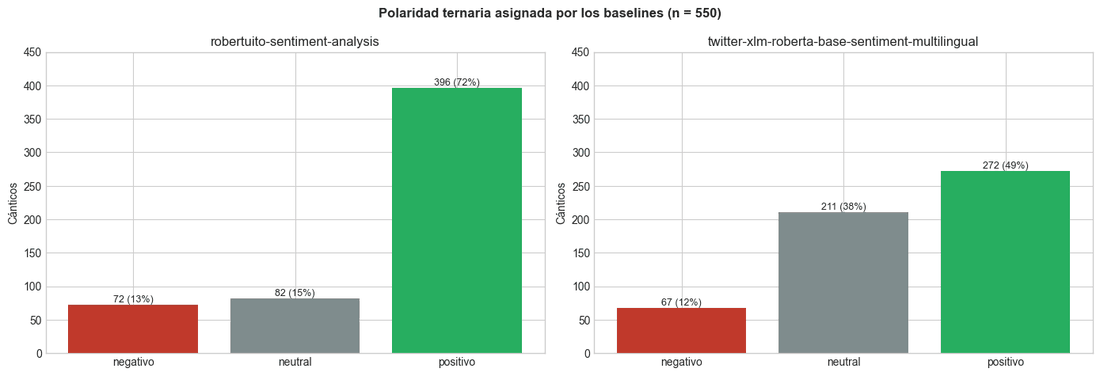

In [40]:
sentimiento = {
    clave: probabilidades_clasificadores[clave][["negativo", "neutral", "positivo"]]
    for clave in ["sent_robertuito", "sent_xlmt"]
}
etiqueta_sentimiento = {clave: tabla.idxmax(axis=1) for clave, tabla in sentimiento.items()}
filas = []
for clave, tabla in sentimiento.items():
    confianza = tabla.max(axis=1)
    filas.append(
        {
            "modelo": MODELOS_FASE4[clave]["id"], "clave": clave,
            **{f"{e}_pct": etiqueta_sentimiento[clave].eq(e).mean() * 100 for e in tabla.columns},
            "confianza_mediana": confianza.median(),
            "confianza_menor_0_5_pct": confianza.lt(0.5).mean() * 100,
            "auc_negativo_vs_insultos": auc_marcador(tabla["negativo"], "funcion:insultar"),
            "auc_positivo_vs_amor": auc_marcador(tabla["positivo"], "emocional:amor"),
            "auc_positivo_vs_alegria": auc_marcador(tabla["positivo"], "emocional:alegría"),
            "textos_fragmentados": metadatos_clasificadores[clave]["textos_fragmentados"],
        }
    )
comparacion_sentimiento = pd.DataFrame(filas)
comparacion_sentimiento["auc_media"] = comparacion_sentimiento[
    ["auc_negativo_vs_insultos", "auc_positivo_vs_amor", "auc_positivo_vs_alegria"]
].mean(axis=1)

kappa_sentimiento = cohen_kappa_score(
    etiqueta_sentimiento["sent_robertuito"], etiqueta_sentimiento["sent_xlmt"]
)
acuerdo_sentimiento = (etiqueta_sentimiento["sent_robertuito"] == etiqueta_sentimiento["sent_xlmt"]).mean()
matriz_sentimiento = pd.crosstab(
    etiqueta_sentimiento["sent_robertuito"].rename("RoBERTuito"),
    etiqueta_sentimiento["sent_xlmt"].rename("XLM-T"), margins=True,
)
sentimiento_por_fuente = (
    pd.crosstab(corpus_fase4.set_index("cantico_id")["fuente"], etiqueta_sentimiento["sent_robertuito"], normalize="index")
    .mul(100).round(1)
    .join(corpus_fase4["fuente"].value_counts().rename("n_textos"))
)
BASELINE_SELECCIONADO = comparacion_sentimiento.sort_values("auc_media", ascending=False)["clave"].iloc[0]

display(comparacion_sentimiento.drop(columns="clave").round(3))
print(f"Acuerdo exacto entre baselines: {acuerdo_sentimiento:.1%} · kappa de Cohen = {kappa_sentimiento:.3f}")
display(matriz_sentimiento)
print("Distribución de la polaridad de RoBERTuito por fuente (%)")
display(sentimiento_por_fuente)
print(f"Baseline de referencia para comparar con las representaciones afectivas: {MODELOS_FASE4[BASELINE_SELECCIONADO]['id']}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (clave, tabla) in zip(axes, sentimiento.items()):
    conteo = etiqueta_sentimiento[clave].value_counts().reindex(["negativo", "neutral", "positivo"])
    ax.bar(conteo.index, conteo.values, color=["#C0392B", "#7F8C8D", "#27AE60"])
    for x, v in enumerate(conteo.values):
        ax.text(x, v + 4, f"{v} ({v / 550:.0%})", ha="center", fontsize=9)
    ax.set(title=MODELOS_FASE4[clave]["id"].split("/")[1], ylabel="Cánticos", ylim=(0, 450))
fig.suptitle("Polaridad ternaria asignada por los baselines (n = 550)", fontweight="bold")
fig.tight_layout()
plt.show()

**Resultado observado.** Los dos modelos coinciden en que los cánticos negativos son minoría —13,1 % para RoBERTuito y 12,2 % para XLM-T—, pero difieren en el resto de la escala. RoBERTuito asigna polaridad positiva al 72,0 % de las letras y neutral al 14,9 %; XLM-T reparte esos casos entre 49,5 % positivos y 38,4 % neutrales. La matriz muestra el origen del desacuerdo: 143 cánticos, el 26 % del corpus, son positivos para RoBERTuito y neutrales para XLM-T. El acuerdo exacto es 61,6 % y el kappa de Cohen, 0,328; es decir, la polaridad de un cántico depende en buena medida del modelo que la asigna.

En la prueba léxica, RoBERTuito ordena mejor los cánticos con groserías explícitas como negativos (AUC = 0,843 frente a 0,777) y los que contienen expresiones de amor o de fiesta como positivos (0,685 y 0,617 frente a 0,636 y 0,551). Por eso se adopta como línea base. Las 36 letras que superan su límite de 128 subpalabras se procesaron completas mediante fragmentación.

**Interpretación.** La línea base sugiere que el corpus es mayoritariamente «positivo», lo cual es compatible con el predominio del aliento observado en la Fase 2, pero la etiqueta no dice si esa positividad es orgullo, amor, euforia o celebración. La polaridad negativa, a su vez, se asocia sobre todo con vocabulario ofensivo explícito. La distribución por fuente muestra además un posible efecto editorial: Fortaleza Leoparda, con 18 textos en mayúsculas, tiene 38,9 % de negativos, frente a 11,8 % en Barrabrava.net. Con tan pocos casos no puede atribuirse esa diferencia a una hinchada ni a una región.

## 26. Tarea 1B · Emociones con modelos especializados

Se aplican cuatro clasificadores entrenados específicamente para emociones. Dos comparten la taxonomía de Ekman —alegría, tristeza, ira, miedo, asco y sorpresa, más una clase residual— y fueron ajustados con tuits en español (Ekman, 1992; Plaza del Arco et al., 2020; Vera et al., 2021). Los otros dos son multietiqueta y amplían el inventario: la versión multilingüe de GoEmotions incluye orgullo, admiración, entusiasmo, amor, decepción y desaprobación, entre otras 28 categorías (Demszky et al., 2020), y el modelo de tabularis añade desprecio y frustración (Borisov, 2026).

**Hiperparámetro de decisión.** Para GoEmotions multilingüe se usan los umbrales por etiqueta publicados en su ficha, calibrados por los autores en su propia validación, y se contrastan con el umbral uniforme de 0,5. Para tabularis se usa 0,5, como indica su ficha. Los modelos de una etiqueta se resumen con la clase de mayor probabilidad. Como las taxonomías no coinciden, las comparaciones se hacen solo entre conceptos con equivalencia directa, por ejemplo *joy* ↔ alegría o *pride* ↔ orgullo.

In [ ]:
MODELOS_EMOCION_FASE4 = ["emo_robertuito", "emo_xlmt_es", "emo_goemotions", "emo_tabularis"]
for clave in MODELOS_EMOCION_FASE4:
    tabla, meta = inferir_clasificador(clave, CONFIG_CLASIFICADORES_FASE4[clave])
    probabilidades_clasificadores[clave] = tabla.rename(columns=ETIQUETAS_ES)
    metadatos_clasificadores[clave] = meta
    validar_clasificador(clave)

display(
    pd.DataFrame(REGISTRO_EJECUCION_FASE4).query("tarea == 'Emociones especializadas'")[
        ["modelo", "configuracion", "n_fragmentos", "textos_fragmentados",
         "max_subpalabras_por_texto", "longitud_admitida", "parametros_millones",
         "segundos", "desde_cache"]
    ]
)

In [42]:
# Correspondencia entre las etiquetas de cada modelo y los conceptos
# emocionales del proyecto. Solo se enlazan equivalencias directas.
CONCEPTOS_EMOCION = {
    "alegría": {"emo_robertuito": "alegría", "emo_xlmt_es": "alegría", "emo_goemotions": "alegría", "emo_tabularis": "alegría"},
    "euforia": {"emo_goemotions": "entusiasmo"},
    "amor": {"emo_goemotions": "amor", "emo_tabularis": "amor"},
    "orgullo": {"emo_goemotions": "orgullo"},
    "esperanza": {"emo_goemotions": "optimismo"},
    "tristeza": {"emo_robertuito": "tristeza", "emo_xlmt_es": "tristeza", "emo_goemotions": "tristeza", "emo_tabularis": "tristeza"},
    "frustración": {"emo_goemotions": "decepción", "emo_tabularis": "frustración"},
    "ira": {"emo_robertuito": "ira", "emo_xlmt_es": "ira", "emo_goemotions": "ira", "emo_tabularis": "ira"},
    "miedo": {"emo_robertuito": "miedo", "emo_xlmt_es": "miedo", "emo_goemotions": "miedo", "emo_tabularis": "miedo"},
    "desprecio": {"emo_tabularis": "desprecio"},
    "disgusto": {"emo_robertuito": "asco", "emo_xlmt_es": "asco", "emo_goemotions": "asco", "emo_tabularis": "asco"},
}
ETIQUETA_RESIDUAL = {"emo_robertuito": "otras", "emo_xlmt_es": "otras", "emo_goemotions": "neutral", "emo_tabularis": "neutral"}
UMBRAL_GOEMOTIONS_ES = {ETIQUETAS_ES[k]: v for k, v in UMBRALES_GOEMOTIONS_FICHA.items()}


def activaciones_emocion(clave, umbral_ficha=True):
    tabla = probabilidades_clasificadores[clave]
    if not metadatos_clasificadores[clave]["multietiqueta"]:
        return pd.get_dummies(tabla.idxmax(axis=1)).reindex(columns=tabla.columns, fill_value=False)
    if clave == "emo_goemotions" and umbral_ficha:
        return tabla.ge(pd.Series(UMBRAL_GOEMOTIONS_ES)[tabla.columns])
    return tabla.ge(0.5)


filas_emocion, filas_umbral = [], []
for clave in MODELOS_EMOCION_FASE4:
    tabla = probabilidades_clasificadores[clave]
    activas = activaciones_emocion(clave)
    residual = ETIQUETA_RESIDUAL[clave]
    dominante = tabla.idxmax(axis=1)
    no_residuales = activas.drop(columns=residual)
    conceptos = [c for c, m in CONCEPTOS_EMOCION.items() if clave in m]
    aucs = {
        c: auc_marcador(tabla[CONCEPTOS_EMOCION[c][clave]], f"emocional:{c}")
        for c in conceptos if f"emocional:{c}" in presencia_marcadores
    }
    filas_emocion.append(
        {
            "modelo": MODELOS_FASE4[clave]["id"], "clave": clave,
            "etiquetas_del_modelo": tabla.shape[1],
            "conceptos_del_proyecto_cubiertos": len(conceptos),
            "multietiqueta": metadatos_clasificadores[clave]["multietiqueta"],
            "residual_dominante_pct": dominante.eq(residual).mean() * 100,
            "sin_emocion_no_residual_pct": (~no_residuales.any(axis=1)).mean() * 100,
            "etiquetas_activas_media": activas.sum(axis=1).mean(),
            "etiquetas_usadas": int(activas.any(axis=0).sum()),
            "auc_lexica_media": np.nanmean(list(aucs.values())) if aucs else np.nan,
            **{f"auc_{c}": v for c, v in aucs.items()},
        }
    )
    frecuencias = activas.mean().mul(100).sort_values(ascending=False)
    criterio = "umbrales de la ficha" if clave == "emo_goemotions" else (
        "0,5" if metadatos_clasificadores[clave]["multietiqueta"] else "etiqueta de mayor probabilidad"
    )
    filas_umbral.append(
        {"modelo": MODELOS_FASE4[clave]["id"].split("/")[1], "criterio": criterio,
         "etiquetas mas frecuentes (% de canticos)": ", ".join(f"{e} {v:.1f}" for e, v in frecuencias.head(8).items())}
    )
    if clave == "emo_goemotions":
        frecuencias_05 = activaciones_emocion(clave, umbral_ficha=False).mean().mul(100).sort_values(ascending=False)
        filas_umbral.append(
            {"modelo": MODELOS_FASE4[clave]["id"].split("/")[1], "criterio": "0,5",
             "etiquetas mas frecuentes (% de canticos)": ", ".join(f"{e} {v:.1f}" for e, v in frecuencias_05.head(8).items())}
        )

comparacion_emociones = pd.DataFrame(filas_emocion)
kappa_ekman = cohen_kappa_score(
    probabilidades_clasificadores["emo_robertuito"].idxmax(axis=1),
    probabilidades_clasificadores["emo_xlmt_es"].idxmax(axis=1),
)
correlaciones_ekman = pd.Series(
    {
        e: spearmanr(probabilidades_clasificadores["emo_robertuito"][e], probabilidades_clasificadores["emo_xlmt_es"][e]).statistic
        for e in ["alegría", "tristeza", "ira", "miedo", "asco", "sorpresa", "otras"]
    }
)
# Acuerdo entre modelos con taxonomías distintas en conceptos compartidos.
filas_acuerdo = []
for concepto, mapa in CONCEPTOS_EMOCION.items():
    claves = list(mapa)
    for i, a in enumerate(claves):
        for b in claves[i + 1:]:
            filas_acuerdo.append(
                {
                    "concepto": concepto, "modelo_a": a, "modelo_b": b,
                    "rho_spearman": spearmanr(
                        probabilidades_clasificadores[a][mapa[a]], probabilidades_clasificadores[b][mapa[b]]
                    ).statistic,
                }
            )
acuerdo_conceptos_emocion = pd.DataFrame(filas_acuerdo)

display(comparacion_emociones.drop(columns="clave").round(3))
print(f"Acuerdo entre los dos modelos Ekman: kappa de Cohen = {kappa_ekman:.3f}")
display(correlaciones_ekman.round(3).rename("rho_spearman_ekman").to_frame())
display(
    acuerdo_conceptos_emocion.pivot_table(index="concepto", columns=["modelo_a", "modelo_b"], values="rho_spearman").round(2)
)
with pd.option_context("display.max_colwidth", 200):
    display(pd.DataFrame(filas_umbral))

modelo  etiquetas_del_modelo  \
0        pysentimiento/robertuito-emotion-analysis                     7   
1            daveni/twitter-xlm-roberta-emotion-es                     7   
2         AnasAlokla/multilingual_go_emotions_V1.1                    28   
3  tabularisai/multilingual-emotion-classification                    11   

   conceptos_del_proyecto_cubiertos  multietiqueta  residual_dominante_pct  \
0                                 5          False                  11.273   
1                                 5          False                  11.273   
2                                10           True                  28.364   
3                                 8           True                  11.636   

   sin_emocion_no_residual_pct  etiquetas_activas_media  etiquetas_usadas  \
0                       11.273                    1.000                 4   
1                       11.273                    1.000                 4   
2                       29.636           

Acuerdo entre los dos modelos Ekman: kappa de Cohen = 0.504


rho_spearman_ekman
alegría                0.778
tristeza               0.493
ira                    0.686
miedo                  0.541
asco                   0.629
sorpresa               0.435
otras                  0.544


modelo_a    emo_goemotions emo_robertuito                            \
modelo_b     emo_tabularis emo_goemotions emo_tabularis emo_xlmt_es   
concepto                                                              
alegría               0.29           0.23          0.43        0.78   
amor                  0.51            NaN           NaN         NaN   
disgusto              0.13           0.11          0.29        0.63   
frustración          -0.07            NaN           NaN         NaN   
ira                   0.22           0.22          0.46        0.69   
miedo                 0.07           0.08          0.41        0.54   
tristeza              0.01          -0.01          0.19        0.49   

modelo_a       emo_xlmt_es                
modelo_b    emo_goemotions emo_tabularis  
concepto                                  
alegría               0.24          0.48  
amor                   NaN           NaN  
disgusto              0.16          0.19  
frustración            NaN     

modelo                        criterio  \
0          robertuito-emotion-analysis  etiqueta de mayor probabilidad   
1       twitter-xlm-roberta-emotion-es  etiqueta de mayor probabilidad   
2        multilingual_go_emotions_V1.1            umbrales de la ficha   
3        multilingual_go_emotions_V1.1                             0,5   
4  multilingual-emotion-classification                             0,5   

                                                                   etiquetas mas frecuentes (% de canticos)  
0                        alegría 77.1, otras 11.3, ira 9.8, tristeza 1.8, sorpresa 0.0, asco 0.0, miedo 0.0  
1                       alegría 68.9, otras 11.3, ira 10.7, tristeza 9.1, sorpresa 0.0, asco 0.0, miedo 0.0  
2  neutral 32.5, alegría 22.9, amor 15.3, entusiasmo 15.1, molestia 10.9, decepción 6.5, deseo 6.4, ira 5.8  
3   neutral 23.5, alegría 16.5, amor 12.7, entusiasmo 8.7, deseo 5.3, decepción 4.7, optimismo 3.8, ira 2.9  
4   amor 62.4, alegría 14.7, neutral 

**Resultado observado.** Los dos modelos de Ekman concentran el corpus en alegría —77,1 % y 68,9 % de los cánticos como etiqueta dominante—, seguida de la clase residual (11,3 % en ambos) y de ira (9,8 % y 10,7 %). Miedo, asco y sorpresa nunca resultan dominantes: de siete clases, cada modelo usa en la práctica cuatro. Su acuerdo es moderado (κ = 0,504) y más alto para alegría (ρ = 0,778) e ira (0,686) que para sorpresa (0,435).

Los modelos multietiqueta ofrecen más matices, aunque con sesgos propios. GoEmotions multilingüe, con los umbrales de su ficha, activa en promedio 1,46 etiquetas por cántico y usa 24 de sus 28 categorías: neutral (32,5 %), alegría (22,9 %), amor (15,3 %), entusiasmo (15,1 %), molestia (10,9 %) y decepción (6,5 %). Con un umbral uniforme de 0,5, esas frecuencias bajan —por ejemplo, entusiasmo pasa a 8,7 %—, lo que confirma que el umbral es una decisión con efecto real. El modelo de tabularis asigna amor al 62,4 % de las letras y alegría al 14,7 %; desprecio y frustración, que motivaron su inclusión, apenas aparecen (1,6 % y 1,1 %).

En validez léxica, GoEmotions ordena bien los cánticos con marcadores de orgullo (AUC = 0,856), amor (0,829) y alegría (0,792), pero su *excitement* ordena al revés los que contienen «locura», «loco» o «descontrolado» (AUC = 0,394). tabularis obtiene 0,861 en amor y 0,754 en alegría; los modelos Ekman destacan en tristeza (0,803 y 0,842), pero apenas distinguen la alegría literal (0,592 y 0,611).

**Interpretación.** El acuerdo entre modelos con taxonomías distintas es bajo incluso en conceptos compartidos: alegría ρ = 0,29 entre GoEmotions y tabularis, amor 0,51 y tristeza 0,01. La emoción asignada depende más del modelo que del texto, una advertencia importante para cualquier cruce posterior. También se observa un desajuste de dominio: en la jerga barrista, «loco» y «locura» expresan devoción desbordada, mientras un modelo entrenado con comentarios generales no los asocia con entusiasmo. La selección del modelo especializado se completa en la sección 28, cuando puede medirse su acuerdo con el zero-shot.

## 27. Tarea 1C · Zero-shot multietiqueta con modelos NLI

### 27.1 Dimensiones y formulación de las hipótesis

**Decisión metodológica.** Las categorías se organizan en cuatro dimensiones para no mezclar emociones psicológicas con categorías sociológicas o funciones discursivas: **emocional** (12 etiquetas), **identidad futbolística** (6), **relación con el rival** (7) y **función del cántico** (8). Todas se evalúan de forma independiente, de modo que un cántico puede expresar a la vez orgullo, pertenencia, provocación y aliento.

Cada etiqueta se formula de dos maneras, que se comparan empíricamente:

- **A · etiqueta en plantilla:** la palabra se inserta en una frase mínima de su dimensión, como «Este cántico expresa orgullo.» o «La función de este cántico es alentar.».
- **B · hipótesis explícita:** una oración describe el concepto y, cuando corresponde, su objeto, como «Este cántico expresa orgullo por el equipo o la hinchada.» o «Este cántico busca provocar o desafiar a la hinchada rival.».

La formulación B resuelve ambigüedades que la A no puede separar. «Desprecio» aparece en la dimensión emocional y en la relación con el rival: en A ambas hipótesis son idénticas y producen la misma puntuación; en B una se dirige a otras personas en general y la otra al rival. Del mismo modo, en el español de Colombia «disgusto» suele significar desagrado, mientras la emoción básica *disgust* corresponde a asco; la hipótesis B lo precisa como «asco o repugnancia».

In [ ]:
PLANTILLAS_ETIQUETA = {
    "emocional": "Este cántico expresa {}.",
    "identidad": "Este cántico expresa {}.",
    "rival": "Este cántico expresa {}.",
    "funcion": "La función de este cántico es {}.",
}
# (dimensión, etiqueta, hipótesis explícita). La formulación A inserta solo la
# etiqueta en la plantilla de su dimensión; la B describe el concepto y, cuando
# corresponde, su objeto: el equipo, la hinchada o el rival.
ETIQUETAS_ZERO_SHOT = [
    ("emocional", "alegría", "Este cántico expresa alegría o felicidad."),
    ("emocional", "euforia", "Este cántico expresa euforia: una emoción desbordada y festiva."),
    ("emocional", "amor", "Este cántico expresa amor o afecto hacia el equipo."),
    ("emocional", "orgullo", "Este cántico expresa orgullo por el equipo o la hinchada."),
    ("emocional", "esperanza", "Este cántico expresa esperanza en que el equipo gane o sea campeón."),
    ("emocional", "nostalgia", "Este cántico expresa nostalgia por tiempos pasados del equipo."),
    ("emocional", "tristeza", "Este cántico expresa tristeza o dolor."),
    ("emocional", "frustración", "Este cántico expresa frustración o decepción."),
    ("emocional", "ira", "Este cántico expresa ira o rabia."),
    ("emocional", "miedo", "Este cántico expresa miedo o temor."),
    ("emocional", "desprecio", "Este cántico expresa desprecio hacia otras personas."),
    ("emocional", "disgusto", "Este cántico expresa asco o repugnancia."),
    ("identidad", "pertenencia", "Este cántico expresa pertenencia a una comunidad o hinchada."),
    ("identidad", "lealtad", "Este cántico expresa fidelidad al equipo independientemente de sus resultados."),
    ("identidad", "aguante", "Este cántico destaca el aguante de la hinchada: resistir y acompañar al equipo en cualquier circunstancia."),
    ("identidad", "territorialidad", "Este cántico reivindica una ciudad, una región o un barrio como propios."),
    ("identidad", "superioridad", "Este cántico afirma que el equipo o la hinchada es superior a los demás."),
    ("identidad", "memoria colectiva", "Este cántico recuerda la historia, los títulos o los ídolos del equipo."),
    ("rival", "rivalidad", "Este cántico expresa rivalidad con otro equipo o su hinchada."),
    ("rival", "burla", "Este cántico se burla de un rival o lo ridiculiza."),
    ("rival", "provocación", "Este cántico busca provocar o desafiar a la hinchada rival."),
    ("rival", "desprecio", "Este cántico expresa desprecio hacia el rival."),
    ("rival", "humillación", "Este cántico busca humillar al rival."),
    ("rival", "amenaza", "Este cántico contiene amenazas de violencia contra rivales u otras personas."),
    ("rival", "hostilidad", "Este cántico expresa hostilidad o agresividad hacia otros."),
    ("funcion", "alentar", "Este cántico alienta al equipo para que gane."),
    ("funcion", "celebrar", "Este cántico celebra un triunfo, un gol o un título."),
    ("funcion", "reafirmar identidad", "Este cántico reafirma la identidad de la hinchada."),
    ("funcion", "recordar", "Este cántico recuerda hechos o personajes del pasado."),
    ("funcion", "provocar", "El propósito de este cántico es provocar a los rivales."),
    ("funcion", "intimidar", "Este cántico busca intimidar o atemorizar a los rivales."),
    ("funcion", "insultar", "Este cántico insulta a alguien con groserías."),
    ("funcion", "reclamar", "Este cántico reclama o exige algo a jugadores, directivos o autoridades."),
]
definicion_zero_shot = pd.DataFrame(ETIQUETAS_ZERO_SHOT, columns=["dimension", "etiqueta", "hipotesis_B"])
definicion_zero_shot["id_etiqueta"] = definicion_zero_shot["dimension"] + ":" + definicion_zero_shot["etiqueta"]
definicion_zero_shot["hipotesis_A"] = [
    PLANTILLAS_ETIQUETA[d].format(e) for d, e in zip(definicion_zero_shot["dimension"], definicion_zero_shot["etiqueta"])
]
assert definicion_zero_shot["id_etiqueta"].is_unique and len(definicion_zero_shot) == 33
HIPOTESIS_FASE4 = {
    "A_etiqueta": dict(zip(definicion_zero_shot["id_etiqueta"], definicion_zero_shot["hipotesis_A"])),
    "B_hipotesis": dict(zip(definicion_zero_shot["id_etiqueta"], definicion_zero_shot["hipotesis_B"])),
}
ORDEN_ETIQUETAS_ZS = definicion_zero_shot["id_etiqueta"].tolist()

display(
    definicion_zero_shot[["dimension", "etiqueta", "hipotesis_A", "hipotesis_B"]]
)

### 27.2 Regla de puntuación y ejecución sobre el corpus completo

Un modelo NLI de tres clases produce, para cada par premisa–hipótesis, puntuaciones de **implicación**, **neutralidad** y **contradicción**. Hay dos maneras razonables de convertirlas en la puntuación de una etiqueta, y la elección es un hiperparámetro de inferencia:

- **implicación vs. contradicción:** softmax solo entre esas dos clases, como en el modo multietiqueta del *pipeline* zero-shot de `transformers`. Una hipótesis que el modelo considera neutral, es decir, ni confirmada ni negada por el texto, puede recibir una puntuación alta si la contradicción es aún menos probable.
- **implicación vs. resto:** softmax sobre las tres clases. La neutralidad también resta, así que la etiqueta solo se activa cuando el texto apoya positivamente la hipótesis.

En BGE-M3, que distingue únicamente implicación y no implicación, ambas reglas coinciden. La celda calcula las dos reglas en una sola pasada: 3 modelos × 2 formulaciones × 33 hipótesis × 550 cánticos, cerca de 109.000 pares premisa–hipótesis. mDeBERTa-v3 representa la familia multilingüe más usada para zero-shot (He et al., 2021; Laurer et al., 2024); BGE-M3 zero-shot, un clasificador universal más reciente con arquitectura XLM-RoBERTa-large (Chen et al., 2024; Laurer et al., 2023), y BETO-XNLI, una alternativa entrenada solo en español (Cañete et al., 2023). En CPU esta es la celda más costosa del cuaderno; su resultado queda en caché.

In [ ]:
MODELOS_NLI_FASE4 = ["nli_mdeberta", "nli_bgem3", "nli_beto"]
puntuaciones_zero_shot = {}
clases_nli = {}
for clave in MODELOS_NLI_FASE4:
    for formulacion, hipotesis in HIPOTESIS_FASE4.items():
        tablas, meta = inferir_nli(clave, hipotesis, nombre_configuracion=f"zs_{formulacion}")
        clases_nli[clave] = meta["clases_nli"]
        # En modelos de dos clases las reglas coinciden: se conserva una sola.
        reglas = REGLAS_NLI if meta["clases_nli"] == 3 else ["implicacion_vs_resto"]
        for regla in reglas:
            tabla = tablas[regla][ORDEN_ETIQUETAS_ZS]
            assert tabla.shape == (550, 33) and tabla.index.tolist() == IDS_FASE4
            assert np.isfinite(tabla.to_numpy()).all()
            assert tabla.to_numpy().min() >= 0 and tabla.to_numpy().max() <= 1
            puntuaciones_zero_shot[(clave, formulacion, regla)] = tabla

display(
    pd.DataFrame(REGISTRO_EJECUCION_FASE4)
    .query("tarea == 'Zero-shot NLI'")[
        ["modelo", "configuracion", "n_fragmentos", "textos_fragmentados",
         "longitud_admitida", "parametros_millones", "segundos", "segundos_por_texto",
         "desde_cache"]
    ]
)
print(f"Configuraciones zero-shot disponibles: {len(puntuaciones_zero_shot)} "
      "(modelo × formulación × regla de puntuación)")

**Control de implementación.** La puntuación propia agrupa los pares premisa–hipótesis por longitud, fragmenta por versos y calcula dos reglas en una sola pasada. Cuando un cántico cabe completo, su resultado debe coincidir con el del *pipeline* zero-shot de `transformers`. La celda lo comprueba en cinco cánticos elegidos con la semilla del proyecto, con las 33 hipótesis B de mDeBERTa-v3 y la regla implicación vs. contradicción, que es la que aplica el modo multietiqueta de ese *pipeline*.

In [ ]:
tokenizador_control, modelo_control = cargar_modelo("nli_mdeberta", AutoModelForSequenceClassification)
clasificador_control = pipeline(
    "zero-shot-classification", model=modelo_control, tokenizer=tokenizador_control,
    device=DISPOSITIVO_PIPELINE_FASE4,
)
hipotesis_control = HIPOTESIS_FASE4["B_hipotesis"]
longitud_control = longitud_admitida(modelo_control, "nli_mdeberta")
# Solo textos que caben completos: el pipeline trunca y la implementación propia fragmenta.
cabe_completo = [
    max(len(tokenizador_control(texto, h)["input_ids"]) for h in hipotesis_control.values()) <= longitud_control
    for texto in TEXTOS_FASE4
]
posiciones_control = np.random.default_rng(SEMILLA_FASE4).choice(
    np.flatnonzero(cabe_completo), size=5, replace=False
)
propia_control = puntuaciones_zero_shot[("nli_mdeberta", "B_hipotesis", "implicacion_vs_contradiccion")]
filas_control = []
for posicion in sorted(posiciones_control):
    salida = clasificador_control(
        TEXTOS_FASE4.iloc[posicion], candidate_labels=list(hipotesis_control.values()),
        hypothesis_template="{}", multi_label=True,
    )
    oficial = dict(zip(salida["labels"], salida["scores"]))
    filas_control.append(
        {
            "cantico_id": IDS_FASE4[posicion],
            "diferencia_maxima": max(
                abs(oficial[texto] - propia_control.iloc[posicion][etiqueta])
                for etiqueta, texto in hipotesis_control.items()
            ),
        }
    )
control_implementacion_nli = pd.DataFrame(filas_control)
del clasificador_control, modelo_control, tokenizador_control
liberar_memoria()
display(control_implementacion_nli)
assert control_implementacion_nli["diferencia_maxima"].max() < 1e-3
print(
    f"{sum(cabe_completo)} de 550 cánticos caben completos con la hipótesis más larga; "
    "la puntuación propia reproduce el pipeline zero-shot multietiqueta de transformers."
)

**Resultado observado.** Las seis ejecuciones —tres modelos por dos formulaciones— procesaron los 550 cánticos. Solo un texto supera el límite de 512 subpalabras una vez descontada la hipótesis más larga y se evalúa en dos fragmentos; los demás entran completos. Cada configuración evalúa unos 18.200 pares premisa–hipótesis y el conjunto supera los 109.000. El costo crece con el tamaño del modelo: BETO-XNLI, con 110 millones de parámetros, es el más rápido; mDeBERTa-v3, con 279 millones, tarda cerca del doble, y BGE-M3, con 568 millones, casi el triple. El control de implementación confirma que la puntuación propia reproduce la del *pipeline* de `transformers`: en los cinco cánticos de control, la mayor diferencia entre ambas es del orden de 10⁻⁵, atribuible al relleno de los lotes.

### 27.3 Comparación de modelos, formulaciones y reglas

La celda compara las diez configuraciones resultantes: cuatro para cada modelo de tres clases y dos para BGE-M3. Para cada una calcula la AUC media frente a los 16 marcadores léxicos, el acuerdo medio con los otros dos modelos en la misma formulación y regla, el número de etiquetas informativas —con prevalencia entre 2 % y 95 %—, las etiquetas saturadas o casi vacías, la mediana de etiquetas activas por cántico, la proporción de puntuaciones en la zona incierta entre 0,4 y 0,6, la correlación entre los dos «desprecios» y el costo. La configuración seleccionada es la de mejor rango medio en validez léxica, acuerdo y capacidad informativa. Si hay empate, se prefiere la formulación que no repite hipótesis —en A, los dos «desprecios» se convierten en la misma oración— y, después, la de menor costo. Una prueba de sensibilidad repite la selección retirando cada criterio y, además, agregando uno que penaliza el número de etiquetas activas por cántico.

In [46]:
UMBRAL_ZS = 0.5
ETIQUETAS_CON_MARCADOR = [e for e in ORDEN_ETIQUETAS_ZS if e in MARCADORES_LEXICOS]
NOMBRE_REGLA = {
    "implicacion_vs_contradiccion": "implicación vs. contradicción",
    "implicacion_vs_resto": "implicación vs. resto",
}


def configuracion_comparable(clave, formulacion, regla):
    """Configuración equivalente de otro modelo: misma formulación y misma regla."""
    return (clave, formulacion, regla if clases_nli[clave] == 3 else "implicacion_vs_resto")


def metricas_configuracion_zs(clave, formulacion, regla):
    tabla = puntuaciones_zero_shot[(clave, formulacion, regla)]
    prevalencia = tabla.ge(UMBRAL_ZS).mean()
    otras = [c for c in MODELOS_NLI_FASE4 if c != clave]
    acuerdo = np.mean(
        [
            spearmanr(tabla[e], puntuaciones_zero_shot[configuracion_comparable(otra, formulacion, regla)][e]).statistic
            for e in ORDEN_ETIQUETAS_ZS for otra in otras
        ]
    )
    aucs = {e: auc_marcador(tabla[e], e) for e in ETIQUETAS_CON_MARCADOR}
    registro = next(
        r for r in REGISTRO_EJECUCION_FASE4 if r["clave"] == clave and r["configuracion"] == f"zs_{formulacion}"
    )
    return {
        "modelo": MODELOS_FASE4[clave]["id"], "clave": clave, "formulacion": formulacion,
        "regla": regla, "auc_lexica_media": np.nanmean(list(aucs.values())),
        "etiquetas_auc_mayor_0_6": int(sum(v > 0.6 for v in aucs.values())),
        "acuerdo_intermodelo_rho": acuerdo,
        "etiquetas_informativas": int(prevalencia.between(0.02, 0.95).sum()),
        "etiquetas_saturadas": int(prevalencia.gt(0.95).sum()),
        "etiquetas_casi_vacias": int(prevalencia.lt(0.02).sum()),
        "etiquetas_activas_mediana": float(tabla.ge(UMBRAL_ZS).sum(axis=1).median()),
        "prevalencia_media_pct": prevalencia.mean() * 100,
        "zona_incierta_0_4_0_6_pct": tabla.stack().between(0.4, 0.6).mean() * 100,
        "rho_desprecio_emocional_vs_rival": spearmanr(tabla["emocional:desprecio"], tabla["rival:desprecio"]).statistic,
        "hipotesis_repetidas": len(ORDEN_ETIQUETAS_ZS) - len(set(HIPOTESIS_FASE4[formulacion].values())),
        "segundos": registro["segundos"], "segundos_por_texto": registro["segundos_por_texto"],
        **{f"auc {e}": v for e, v in aucs.items()},
    }


comparacion_zs = pd.DataFrame([metricas_configuracion_zs(*clave) for clave in puntuaciones_zero_shot])
criterios_zs = {"auc_lexica_media": True, "acuerdo_intermodelo_rho": True, "etiquetas_informativas": True}
# Desempate: primero la formulación que no repite hipótesis, es decir, la que
# puede distinguir todas las etiquetas de la taxonomía; después el costo.
DESEMPATE_ZS = ["hipotesis_repetidas", "segundos"]
ranking_zs = seleccion_por_rangos(comparacion_zs, criterios_zs, desempate=DESEMPATE_ZS)
CLAVE_NLI_SELECCIONADA = ranking_zs.loc[0, "clave"]
FORMULACION_SELECCIONADA = ranking_zs.loc[0, "formulacion"]
REGLA_SELECCIONADA = ranking_zs.loc[0, "regla"]
fila_contraste = ranking_zs.query("clave != @CLAVE_NLI_SELECCIONADA").iloc[0]
CONFIGURACION_CONTRASTE = (fila_contraste["clave"], fila_contraste["formulacion"], fila_contraste["regla"])
CLAVE_NLI_CONTRASTE = CONFIGURACION_CONTRASTE[0]

columnas_resumen = [
    "modelo", "formulacion", "regla", "auc_lexica_media", "etiquetas_auc_mayor_0_6",
    "acuerdo_intermodelo_rho", "etiquetas_informativas", "etiquetas_saturadas", "etiquetas_casi_vacias",
    "etiquetas_activas_mediana", "zona_incierta_0_4_0_6_pct", "rho_desprecio_emocional_vs_rival",
    "hipotesis_repetidas", "segundos_por_texto", "rango_medio",
]
display(ranking_zs[columnas_resumen].round(3))

# Sensibilidad de la selección: se retira un criterio cada vez y se prueba
# además penalizar la cantidad de etiquetas activas por cántico.
variantes_criterios = {"los tres criterios": criterios_zs}
for excluido in criterios_zs:
    variantes_criterios[f"sin {excluido}"] = {c: v for c, v in criterios_zs.items() if c != excluido}
variantes_criterios["los tres + menos etiquetas activas"] = {**criterios_zs, "etiquetas_activas_mediana": False}
sensibilidad_zs = pd.DataFrame(
    [
        {
            "criterios": nombre,
            "configuracion_ganadora": " · ".join(
                seleccion_por_rangos(comparacion_zs, criterios, desempate=DESEMPATE_ZS)
                .loc[0, ["modelo", "formulacion", "regla"]].astype(str)
            ),
        }
        for nombre, criterios in variantes_criterios.items()
    ]
)
with pd.option_context("display.max_colwidth", None):
    display(sensibilidad_zs)
print("Efecto de la formulación (A = etiqueta en plantilla; B = hipótesis explícita), con la misma regla")
efecto_formulacion = comparacion_zs.pivot_table(
    index=["clave", "regla"], columns="formulacion",
    values=["auc_lexica_media", "acuerdo_intermodelo_rho", "etiquetas_informativas", "etiquetas_activas_mediana"],
)
display(efecto_formulacion.round(3))
print("Efecto de la regla de puntuación en los modelos NLI de tres clases, con la misma formulación")
efecto_regla = comparacion_zs.query("clave != 'nli_bgem3'").pivot_table(
    index=["clave", "formulacion"], columns="regla",
    values=["auc_lexica_media", "etiquetas_informativas", "etiquetas_activas_mediana"],
)
display(efecto_regla.round(3))
print("AUC léxica por etiqueta y configuración")
display(
    comparacion_zs.set_index(["clave", "formulacion", "regla"])[[f"auc {e}" for e in ETIQUETAS_CON_MARCADOR]]
    .T.round(3)
)
print(
    f"Configuración zero-shot seleccionada: {MODELOS_FASE4[CLAVE_NLI_SELECCIONADA]['id']} · "
    f"{FORMULACION_SELECCIONADA} · {NOMBRE_REGLA[REGLA_SELECCIONADA]}. "
    f"Contraste: {MODELOS_FASE4[CLAVE_NLI_CONTRASTE]['id']} · {CONFIGURACION_CONTRASTE[1]} · "
    f"{NOMBRE_REGLA[CONFIGURACION_CONTRASTE[2]]}"
)

modelo  formulacion  \
0                          MoritzLaurer/bge-m3-zeroshot-v2.0  B_hipotesis   
1                          MoritzLaurer/bge-m3-zeroshot-v2.0   A_etiqueta   
2  MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7   A_etiqueta   
3  MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7   A_etiqueta   
4  MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7  B_hipotesis   
5  MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7  B_hipotesis   
6                  Recognai/bert-base-spanish-wwm-cased-xnli  B_hipotesis   
7                  Recognai/bert-base-spanish-wwm-cased-xnli   A_etiqueta   
8                  Recognai/bert-base-spanish-wwm-cased-xnli   A_etiqueta   
9                  Recognai/bert-base-spanish-wwm-cased-xnli  B_hipotesis   

                          regla  auc_lexica_media  etiquetas_auc_mayor_0_6  \
0          implicacion_vs_resto             0.766                       16   
1          implicacion_vs_resto             0.789 

criterios  \
0                  los tres criterios   
1                sin auc_lexica_media   
2         sin acuerdo_intermodelo_rho   
3          sin etiquetas_informativas   
4  los tres + menos etiquetas activas   

                                                                                  configuracion_ganadora  
0                                 MoritzLaurer/bge-m3-zeroshot-v2.0 · B_hipotesis · implicacion_vs_resto  
1                                 MoritzLaurer/bge-m3-zeroshot-v2.0 · B_hipotesis · implicacion_vs_resto  
2                                  MoritzLaurer/bge-m3-zeroshot-v2.0 · A_etiqueta · implicacion_vs_resto  
3  MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7 · A_etiqueta · implicacion_vs_contradiccion  
4                                 MoritzLaurer/bge-m3-zeroshot-v2.0 · B_hipotesis · implicacion_vs_resto


Efecto de la formulación (A = etiqueta en plantilla; B = hipótesis explícita), con la misma regla


acuerdo_intermodelo_rho              \
formulacion                                            A_etiqueta B_hipotesis   
clave        regla                                                              
nli_beto     implicacion_vs_contradiccion                   0.392       0.380   
             implicacion_vs_resto                           0.331       0.340   
nli_bgem3    implicacion_vs_resto                           0.409       0.412   
nli_mdeberta implicacion_vs_contradiccion                   0.483       0.445   
             implicacion_vs_resto                           0.437       0.410   

                                          auc_lexica_media              \
formulacion                                     A_etiqueta B_hipotesis   
clave        regla                                                       
nli_beto     implicacion_vs_contradiccion            0.690       0.679   
             implicacion_vs_resto                    0.697       0.677   
nli_bgem3    implicacio

Efecto de la regla de puntuación en los modelos NLI de tres clases, con la misma formulación


auc_lexica_media                       \
regla                    implicacion_vs_contradiccion implicacion_vs_resto   
clave        formulacion                                                     
nli_beto     A_etiqueta                         0.690                0.697   
             B_hipotesis                        0.679                0.677   
nli_mdeberta A_etiqueta                         0.759                0.776   
             B_hipotesis                        0.719                0.738   

                            etiquetas_activas_mediana                       \
regla                    implicacion_vs_contradiccion implicacion_vs_resto   
clave        formulacion                                                     
nli_beto     A_etiqueta                          21.0                  7.0   
             B_hipotesis                         14.0                  2.0   
nli_mdeberta A_etiqueta                          27.0                 23.0   
             B_hipotes

**Resultado observado.** Las dos formulaciones de BGE-M3 encabezan la comparación con el mismo rango medio (3,17), seguidas de mDeBERTa-v3 con la formulación A y la regla implicación vs. resto (4,00). BETO-XNLI ocupa los últimos lugares en sus cuatro configuraciones: su AUC léxica media no supera 0,697 y su acuerdo con los otros modelos es el más bajo (ρ = 0,33 a 0,39).

La diferencia decisiva está en la capacidad discriminante. BGE-M3 conserva informativas las 33 etiquetas, no satura ninguna y activa una mediana de 11 u 13 por cántico. mDeBERTa-v3 obtiene el mayor acuerdo con los otros modelos (ρ = 0,483) y una AUC competitiva —hasta 0,776—, pero activa entre 19 y 28 etiquetas por cántico y satura entre 2 y 10 de ellas: con la formulación A y la regla implicación vs. contradicción, 10 etiquetas aparecen en más del 95 % de las letras. En BETO-XNLI la regla cambia por completo el resultado: la mediana de etiquetas activas pasa de 21 a 7 con la formulación A y de 14 a 2 con la B, que además deja 8 etiquetas casi vacías.

**Efecto de la regla de puntuación.** En los modelos de tres clases, exigir que la implicación supere también a la neutralidad reduce la saturación y, en mDeBERTa-v3, mejora la AUC (de 0,759 a 0,776 con A y de 0,719 a 0,738 con B). La regla implicación vs. contradicción cuenta como apoyo lo que el modelo solo juzga compatible con el texto, y eso explica buena parte de la saturación.

**Efecto de la formulación.** La hipótesis explícita reduce la AUC léxica media en los tres modelos —en BGE-M3, de 0,789 a 0,766—, pero el efecto no es uniforme. B mejora las etiquetas cuya hipótesis precisa el acto o su objeto: en BGE-M3, amenaza pasa de 0,857 a 0,946, burla de 0,602 a 0,716, insultar de 0,831 a 0,865 y tristeza de 0,636 a 0,710. Empeoran, en cambio, orgullo (de 0,918 a 0,725), alentar (de 0,920 a 0,639) y amor (de 0,917 a 0,848), cuyos marcadores detectan una sola palabra. En A la hipótesis se reduce a esa palabra dentro de una frase neutra; en B exige además un objeto o un propósito —orgullo por el equipo o la hinchada, amor hacia el equipo, aliento para que gane— que el marcador no verifica. **Interpretación.** La AUC léxica recompensa la coincidencia con la palabra y no la precisión adicional de la hipótesis, de modo que no es neutral entre formulaciones. Este comportamiento es compatible con la dependencia de los modelos NLI de la superposición léxica entre premisa e hipótesis (McCoy et al., 2019).

**Decisión.** Como las dos formulaciones de BGE-M3 empatan, se aplica el desempate. B no repite hipótesis; en A, «desprecio» emocional y «desprecio» hacia el rival son la misma oración, reciben siempre la misma puntuación (ρ = 1,000) y reducen la taxonomía, en la práctica, a 32 etiquetas. B también usa para *disgusto* la acepción de asco, activa menos etiquetas por cántico (mediana de 11 frente a 13) y gana en tres de las cinco variantes de sensibilidad. A solo gana si se retira el acuerdo entre modelos, y mDeBERTa-v3 solo si se retira la capacidad informativa, lo que confirma que su ventaja depende de ignorar la saturación. La configuración seleccionada es, por tanto, BGE-M3 zero-shot con hipótesis explícitas; como el modelo tiene dos clases, las dos reglas coinciden. El contraste es mDeBERTa-v3 con la formulación A y la regla implicación vs. resto, la mejor configuración de otro modelo.

**Nota de procedimiento.** El primer criterio de desempate se precisó al observar el empate; antes solo estaba previsto el costo. Se deja constancia porque modifica la regla anunciada y porque el tiempo de ejecución depende del equipo y de su carga, no de la validez de la configuración.

### 27.4 Umbral de decisión y resultados del modelo seleccionado

Las puntuaciones se conservan continuas para los análisis agregados. El umbral solo sirve para convertirlas en presencia o ausencia. El valor 0,5 es el punto en que la implicación pasa a ser más probable que su alternativa: la contradicción, en la regla implicación vs. contradicción, o la suma de neutralidad y contradicción, en la regla implicación vs. resto y en BGE-M3. Antes de adoptarlo se verifica que el orden de prevalencia de las 33 etiquetas se mantenga con umbrales entre 0,3 y 0,7, medido con la τ de Kendall. La configuración de contraste —la mejor de un modelo distinto al seleccionado— se muestra junto a la elegida para evaluar si los patrones dependen de esa decisión. Dos contrastes adicionales separan el efecto de la formulación, con la otra hipótesis en el mismo modelo, del efecto del modelo, con la misma hipótesis en los otros dos. La matriz de coocurrencia se resume, por último, con la correlación media dentro y entre grupos de etiquetas definidos por su dimensión y su valencia, no por la figura.

umbral  tau_kendall_vs_0_5  etiquetas_activas_media  \
0     0.3               0.858                   13.540   
1     0.4               0.942                   12.055   
2     0.5               1.000                   10.753   
3     0.6               0.962                    9.465   
4     0.7               0.919                    8.073   

   canticos_sin_etiqueta_pct  
0                      0.182  
1                      0.545  
2                      1.273  
3                      2.182  
4                      4.727


ρ de Spearman mediano por etiqueta frente a cada alternativa:


rho_con_modelo_contraste  rho_otra_formulacion  \
mediana                     0.495                 0.824   

         rho_nli_mdeberta_misma_formulacion  rho_nli_beto_misma_formulacion  
mediana                               0.517                           0.339


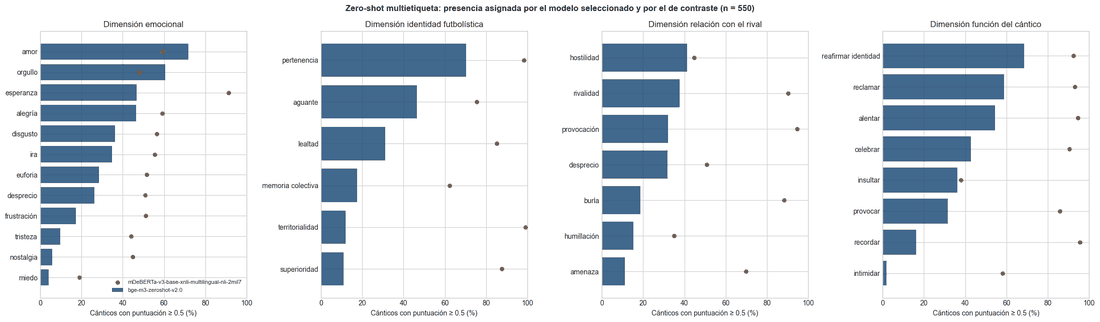

ρ medio entre etiquetas de un mismo grupo (diagonal) y de grupos distintos


emociones positivas  emociones negativas  identidad  \
emociones positivas                      0.55                -0.35       0.34   
emociones negativas                     -0.35                 0.75      -0.08   
identidad                                0.34                -0.08       0.30   
relación con el rival                   -0.17                 0.70       0.02   
funciones de aliento                     0.38                -0.11       0.28   
funciones de antagonismo                -0.09                 0.60       0.05   

                          relación con el rival  funciones de aliento  \
emociones positivas                       -0.17                  0.38   
emociones negativas                        0.70                 -0.11   
identidad                                  0.02                  0.28   
relación con el rival                      0.74                  0.01   
funciones de aliento                       0.01                  0.17   
funciones de antagon

In [47]:
zs_final = puntuaciones_zero_shot[(CLAVE_NLI_SELECCIONADA, FORMULACION_SELECCIONADA, REGLA_SELECCIONADA)]
zs_contraste = puntuaciones_zero_shot[CONFIGURACION_CONTRASTE]
# Dos contrastes adicionales separan el efecto de la formulación (mismo modelo)
# del efecto del modelo (misma formulación y regla).
otra_formulacion = next(f for f in HIPOTESIS_FASE4 if f != FORMULACION_SELECCIONADA)
zs_otra_formulacion = puntuaciones_zero_shot[(CLAVE_NLI_SELECCIONADA, otra_formulacion, REGLA_SELECCIONADA)]
zs_otros_modelos = {
    clave: puntuaciones_zero_shot[configuracion_comparable(clave, FORMULACION_SELECCIONADA, REGLA_SELECCIONADA)]
    for clave in MODELOS_NLI_FASE4 if clave != CLAVE_NLI_SELECCIONADA
}
NOMBRES_DIMENSION = {"emocional": "emocional", "identidad": "identidad futbolística",
                     "rival": "relación con el rival", "funcion": "función del cántico"}

# Hiperparámetro de decisión: el umbral solo convierte puntuaciones en presencia.
# Se elige comprobando que el orden de prevalencia de las etiquetas no dependa
# de un valor particular.
UMBRALES_CANDIDATOS = [0.3, 0.4, 0.5, 0.6, 0.7]
prevalencias_umbral = pd.DataFrame({u: zs_final.ge(u).mean() * 100 for u in UMBRALES_CANDIDATOS})
estabilidad_umbral = pd.DataFrame(
    [
        {
            "umbral": u,
            "tau_kendall_vs_0_5": kendalltau(prevalencias_umbral[u], prevalencias_umbral[0.5]).statistic,
            "etiquetas_activas_media": zs_final.ge(u).sum(axis=1).mean(),
            "canticos_sin_etiqueta_pct": (~zs_final.ge(u).any(axis=1)).mean() * 100,
        }
        for u in UMBRALES_CANDIDATOS
    ]
)
display(estabilidad_umbral.round(3))

activas_zs = zs_final.ge(UMBRAL_ZS)
resumen_zs = pd.DataFrame(
    {
        "dimension": [e.split(":")[0] for e in ORDEN_ETIQUETAS_ZS],
        "etiqueta": [e.split(":")[1] for e in ORDEN_ETIQUETAS_ZS],
        "prevalencia_pct": activas_zs.mean().values * 100,
        "puntuacion_media": zs_final.mean().values,
        "q25": zs_final.quantile(0.25).values, "mediana": zs_final.median().values,
        "q75": zs_final.quantile(0.75).values,
        "rho_con_modelo_contraste": [
            spearmanr(zs_final[e], zs_contraste[e]).statistic for e in ORDEN_ETIQUETAS_ZS
        ],
        "prevalencia_contraste_pct": zs_contraste.ge(UMBRAL_ZS).mean().values * 100,
        "rho_otra_formulacion": [
            spearmanr(zs_final[e], zs_otra_formulacion[e]).statistic for e in ORDEN_ETIQUETAS_ZS
        ],
        **{
            f"rho_{clave}_misma_formulacion": [spearmanr(zs_final[e], tabla[e]).statistic for e in ORDEN_ETIQUETAS_ZS]
            for clave, tabla in zs_otros_modelos.items()
        },
    }
)
display(resumen_zs.round(3))
columnas_rho = [c for c in resumen_zs.columns if c.startswith("rho_")]
print("ρ de Spearman mediano por etiqueta frente a cada alternativa:")
display(resumen_zs[columnas_rho].median().round(3).to_frame("mediana").T)

fig, axes = plt.subplots(1, 4, figsize=(22, 6.5), sharex=True)
for ax, dimension in zip(axes, ["emocional", "identidad", "rival", "funcion"]):
    datos = resumen_zs.query("dimension == @dimension").sort_values("prevalencia_pct")
    ax.barh(datos["etiqueta"], datos["prevalencia_pct"], color=COLOR_PRINCIPAL, alpha=0.85,
            label=MODELOS_FASE4[CLAVE_NLI_SELECCIONADA]["id"].split("/")[1])
    ax.scatter(datos["prevalencia_contraste_pct"], datos["etiqueta"], color=COLOR_ACENTO, zorder=3,
               s=28, label=MODELOS_FASE4[CLAVE_NLI_CONTRASTE]["id"].split("/")[1])
    ax.set(title=f"Dimensión {NOMBRES_DIMENSION[dimension]}", xlabel=f"Cánticos con puntuación ≥ {UMBRAL_ZS} (%)", xlim=(0, 100))
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle(
    "Zero-shot multietiqueta: presencia asignada por el modelo seleccionado y por el de contraste (n = 550)",
    fontweight="bold",
)
fig.tight_layout()
plt.show()

correlacion_etiquetas = zs_final.corr(method="spearman")
fig, ax = plt.subplots(figsize=(13, 11))
imagen = ax.imshow(correlacion_etiquetas, cmap="RdBu_r", vmin=-1, vmax=1)
ax.grid(False)
def nombre_visible(etiqueta):
    """Identificador de etiqueta con la tilde de «función» para las figuras."""
    return etiqueta.replace("funcion:", "función:").replace(":", ": ")


nombres = [nombre_visible(e) for e in ORDEN_ETIQUETAS_ZS]
ax.set_xticks(range(33), nombres, rotation=90, fontsize=8)
ax.set_yticks(range(33), nombres, fontsize=8)
for limite in [11.5, 17.5, 24.5]:
    ax.axhline(limite, color="black", linewidth=0.8)
    ax.axvline(limite, color="black", linewidth=0.8)
fig.colorbar(imagen, ax=ax, fraction=0.04).set_label("ρ de Spearman entre puntuaciones")
ax.set_title("Coocurrencia de las 33 etiquetas zero-shot en los 550 cánticos", fontweight="bold")
fig.tight_layout()
plt.show()

# Resumen numérico de la matriz con grupos definidos por dimensión y valencia de
# la etiqueta, no por la figura; nostalgia y reclamar quedan fuera por ambivalentes.
GRUPOS_COOCURRENCIA = {
    "emociones positivas": ["emocional:alegría", "emocional:euforia", "emocional:amor", "emocional:orgullo",
                            "emocional:esperanza"],
    "emociones negativas": ["emocional:tristeza", "emocional:frustración", "emocional:ira", "emocional:miedo",
                            "emocional:desprecio", "emocional:disgusto"],
    "identidad": [e for e in ORDEN_ETIQUETAS_ZS if e.startswith("identidad:")],
    "relación con el rival": [e for e in ORDEN_ETIQUETAS_ZS if e.startswith("rival:")],
    "funciones de aliento": ["funcion:alentar", "funcion:celebrar", "funcion:reafirmar identidad", "funcion:recordar"],
    "funciones de antagonismo": ["funcion:provocar", "funcion:intimidar", "funcion:insultar"],
}


def rho_medio_grupos(grupo_a, grupo_b):
    return np.mean([correlacion_etiquetas.loc[a, b] for a in grupo_a for b in grupo_b if a != b])


correlacion_grupos = pd.DataFrame(
    {
        g: {h: rho_medio_grupos(GRUPOS_COOCURRENCIA[g], GRUPOS_COOCURRENCIA[h]) for h in GRUPOS_COOCURRENCIA}
        for g in GRUPOS_COOCURRENCIA
    }
)
print("ρ medio entre etiquetas de un mismo grupo (diagonal) y de grupos distintos")
display(correlacion_grupos.round(2))

conteo_activas = activas_zs.sum(axis=1)
print(
    "Etiquetas activas por cántico: mediana "
    f"{conteo_activas.median():.0f}, RIC {conteo_activas.quantile(0.25):.0f}–{conteo_activas.quantile(0.75):.0f}, "
    f"máximo {conteo_activas.max()}; cánticos sin ninguna etiqueta: {(conteo_activas == 0).sum()}"
)

**Resultado observado.** El orden de prevalencia de las 33 etiquetas es estable alrededor del umbral: la τ de Kendall frente a 0,5 es 0,942 con 0,4 y 0,962 con 0,6, y su menor valor, 0,858, aparece con 0,3. El umbral cambia, en cambio, la cantidad de etiquetas por cántico —de 13,5 en promedio con 0,3 a 8,1 con 0,7— y la proporción de letras sin ninguna etiqueta, de 0,2 % a 4,7 %. Con 0,5, cada cántico activa una mediana de 11 etiquetas (RIC 7–14) y solo 7 no activan ninguna.

Las etiquetas más frecuentes combinan afecto e identidad: amor hacia el equipo (71,6 %), pertenencia (70,4 %), reafirmación de la identidad de la hinchada (68,5 %), orgullo (60,5 %), reclamo o exigencia a jugadores, directivos o autoridades (58,7 %) y aliento (54,5 %). En la relación con el rival predominan la hostilidad (41,5 %) y la rivalidad (37,6 %); la amenaza de violencia queda en 11,1 % y la intimidación, en 2,0 %. Las emociones de pérdida son poco frecuentes: tristeza 9,8 %, nostalgia 5,8 % y miedo 4,2 %. *Reclamar* no tiene marcador léxico, así que su alta prevalencia no puede contrastarse con la prueba de la [sección 23](#23-estrategia-de-evaluación-sin-un-conjunto-etiquetado).

La matriz de coocurrencia muestra que las 33 etiquetas no se comportan como dimensiones independientes. Las emociones negativas tienen entre sí una correlación media de 0,75, casi igual a la que mantienen con las etiquetas de relación con el rival (0,70) y con las funciones de antagonismo (0,60). Las emociones positivas forman un bloque más laxo (0,55), se asocian moderadamente con la identidad (0,34) y con las funciones de aliento (0,38), y se oponen a las negativas (−0,35).

**Interpretación.** El modelo distingue con claridad dos polos, el antagonismo y la afirmación afectiva del propio equipo, pero separa poco las emociones negativas entre sí: ira, desprecio, asco y frustración funcionan casi como una sola señal de antagonismo. En los cruces conviene leerlas como un conjunto y no como experiencias diferenciadas.

Los contrastes separan dos fuentes de variación. Entre las dos formulaciones de BGE-M3, la correlación mediana por etiqueta es 0,824; con mDeBERTa-v3 y BETO-XNLI en la misma formulación, baja a 0,517 y 0,339. El modelo pesa más que la redacción de la hipótesis. La redacción importa sobre todo cuando la palabra de la etiqueta es polisémica o propia del dominio: *aguante* (ρ = 0,156 entre A y B), *memoria colectiva* (0,457), *reclamar* (0,534), *alentar* (0,556) y *territorialidad* (0,585). La configuración de contraste asigna prevalencias mucho mayores en casi todas las etiquetas —por ejemplo, territorialidad 98,9 % y recordar 95,5 %—, coherentes con la saturación descrita en la sección anterior.

## 28. Síntesis de la Tarea 1 · ¿Qué agrega pasar de la polaridad al afecto?

Esta sección contrasta las tres representaciones sobre los mismos 550 cánticos. Primero examina si la **valencia lingüística** coincide con la **experiencia afectiva o identitaria** que asigna el zero-shot: un cántico puede contener insultos y, a la vez, expresar orgullo y pertenencia para la hinchada que lo canta. Después compara, para ocho conceptos emocionales compartidos, la prevalencia que asigna cada representación y mide su riqueza con el número de perfiles distintos de etiquetas activas. Por último, selecciona el modelo especializado de emociones que acompañará al zero-shot, según cobertura de conceptos del proyecto, validez léxica, dependencia de la clase residual y acuerdo con el modelo seleccionado.

In [48]:
polaridad = etiqueta_sentimiento[BASELINE_SELECCIONADO].rename("polaridad_baseline")
ETIQUETAS_CONTRASTE_VALENCIA = [
    "emocional:orgullo", "emocional:amor", "emocional:euforia", "identidad:pertenencia",
    "identidad:lealtad", "funcion:alentar", "rival:rivalidad", "rival:burla",
    "rival:provocación", "rival:hostilidad", "funcion:insultar",
]
valencia_vs_afecto = (
    activas_zs[ETIQUETAS_CONTRASTE_VALENCIA].groupby(polaridad).mean().mul(100)
    .join(polaridad.value_counts().rename("n_canticos"))
    .round(1)
)
display(valencia_vs_afecto)

identidad_positiva = activas_zs[
    ["emocional:orgullo", "emocional:amor", "identidad:pertenencia", "identidad:lealtad", "funcion:alentar"]
].any(axis=1)
antagonismo = activas_zs[["rival:burla", "rival:provocación", "rival:hostilidad", "funcion:insultar"]].any(axis=1)
negativos = polaridad.eq("negativo")
print(
    f"Cánticos negativos para el baseline: {negativos.sum()}. De ellos, "
    f"{(negativos & identidad_positiva).sum()} ({(negativos & identidad_positiva).sum() / negativos.sum():.1%}) "
    "activan al menos una etiqueta de afecto o identidad positiva hacia el propio equipo y "
    f"{(negativos & antagonismo).sum()} ({(negativos & antagonismo).sum() / negativos.sum():.1%}) "
    "una etiqueta de antagonismo."
)
print(
    f"Cánticos positivos para el baseline con antagonismo activo: {(polaridad.eq('positivo') & antagonismo).sum()} "
    f"de {polaridad.eq('positivo').sum()}."
)
correlacion_negatividad = pd.Series(
    {e: spearmanr(sentimiento[BASELINE_SELECCIONADO]["negativo"], zs_final[e]).statistic for e in ORDEN_ETIQUETAS_ZS}
).sort_values()
display(correlacion_negatividad.round(3).rename("rho_P(negativo)_vs_etiqueta").to_frame().T)

# Un mismo concepto según cada representación: etiqueta dominante en los modelos
# de una etiqueta y umbral de decisión en los multietiqueta.
CONCEPTOS_FIGURA = ["alegría", "amor", "orgullo", "tristeza", "ira", "miedo", "disgusto", "frustración"]
prevalencia_conceptos = pd.DataFrame(
    {
        MODELOS_FASE4[clave]["id"].split("/")[1]: {
            c: activaciones_emocion(clave)[CONCEPTOS_EMOCION[c][clave]].mean() * 100
            for c in CONCEPTOS_FIGURA if clave in CONCEPTOS_EMOCION[c]
        }
        for clave in MODELOS_EMOCION_FASE4
    }
).reindex(CONCEPTOS_FIGURA)
prevalencia_conceptos["zero-shot seleccionado"] = [activas_zs[f"emocional:{c}"].mean() * 100 for c in CONCEPTOS_FIGURA]
prevalencia_conceptos.index = ["asco / disgusto" if c == "disgusto" else c for c in CONCEPTOS_FIGURA]
display(prevalencia_conceptos.round(1))
fig, ax = plt.subplots(figsize=(12, 7))
ancho = 0.84 / prevalencia_conceptos.shape[1]
for k, columna in enumerate(prevalencia_conceptos.columns):
    valores = prevalencia_conceptos[columna]
    posiciones = np.arange(len(valores)) - 0.42 + ancho * (k + 0.5)
    presentes = valores.notna().to_numpy()
    ax.barh(posiciones[presentes], valores[presentes], height=ancho, color=plt.cm.tab10(k), label=columna)
ax.set_yticks(range(len(prevalencia_conceptos)), prevalencia_conceptos.index)
ax.invert_yaxis()
ax.set_xlabel("Cánticos con el concepto asignado (%); sin barra: el modelo no tiene esa categoría")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("Un mismo concepto emocional según cada representación (n = 550)", fontweight="bold")
fig.tight_layout()
plt.show()

# Riqueza de representación: número de perfiles distintos de etiquetas activas.
perfiles = {
    "Baseline ternario": polaridad.to_frame(),
    "Emociones Ekman (RoBERTuito)": activaciones_emocion("emo_robertuito"),
    "GoEmotions multilingüe (umbral de la ficha)": activaciones_emocion("emo_goemotions"),
    "tabularis multietiqueta (0,5)": activaciones_emocion("emo_tabularis"),
    "Zero-shot seleccionado (33 etiquetas, 0,5)": activas_zs,
}
riqueza = pd.DataFrame(
    [
        {
            "representacion": nombre,
            "etiquetas_posibles": tabla.shape[1] if nombre != "Baseline ternario" else 3,
            "perfiles_distintos": len(tabla.astype(str).drop_duplicates()),
            "etiquetas_activas_media": (tabla.sum(axis=1).mean() if nombre != "Baseline ternario" else 1.0),
        }
        for nombre, tabla in perfiles.items()
    ]
)
display(riqueza.round(2))

# Selección del modelo especializado: cobertura conceptual, coherencia léxica,
# baja dependencia de la clase residual y acuerdo con el zero-shot seleccionado.
acuerdo_con_zs = {}
for clave in MODELOS_EMOCION_FASE4:
    pares = [
        spearmanr(probabilidades_clasificadores[clave][m[clave]], zs_final[f"emocional:{c}"]).statistic
        for c, m in CONCEPTOS_EMOCION.items() if clave in m
    ]
    acuerdo_con_zs[clave] = np.mean(pares)
comparacion_emociones["acuerdo_con_zero_shot_rho"] = comparacion_emociones["clave"].map(acuerdo_con_zs)
comparacion_emociones["no_residual_pct"] = 100 - comparacion_emociones["residual_dominante_pct"]
ranking_emociones = seleccion_por_rangos(
    comparacion_emociones,
    {"conceptos_del_proyecto_cubiertos": True, "auc_lexica_media": True,
     "no_residual_pct": True, "acuerdo_con_zero_shot_rho": True},
)
EMOCION_SELECCIONADA = ranking_emociones.loc[0, "clave"]
display(
    ranking_emociones[
        ["modelo", "conceptos_del_proyecto_cubiertos", "auc_lexica_media", "no_residual_pct",
         "acuerdo_con_zero_shot_rho", "etiquetas_activas_media", "rango_medio"]
    ].round(3)
)
print(f"Modelo especializado de emociones seleccionado: {MODELOS_FASE4[EMOCION_SELECCIONADA]['id']}")

ejemplos_valencia = (
    pd.DataFrame(
        {
            "polaridad": polaridad, "p_negativo": sentimiento[BASELINE_SELECCIONADO]["negativo"],
            "orgullo": zs_final["emocional:orgullo"], "pertenencia": zs_final["identidad:pertenencia"],
            "provocación": zs_final["rival:provocación"], "insultar": zs_final["funcion:insultar"],
        }
    )
    .query("polaridad == 'negativo'")
    .assign(combinado=lambda t: t["orgullo"] + t["pertenencia"] + t["provocación"])
    .nlargest(3, "combinado")
)
for cantico_id, fila in ejemplos_valencia.iterrows():
    primeras = " / ".join(TEXTOS_FASE4[cantico_id].splitlines()[:2])[:130]
    print(
        f"{cantico_id} ({corpus_fase4.set_index('cantico_id').loc[cantico_id, 'nombre_corto']}): «{primeras}…» "
        f"P(neg)={fila['p_negativo']:.2f} · orgullo={fila['orgullo']:.2f} · "
        f"pertenencia={fila['pertenencia']:.2f} · provocación={fila['provocación']:.2f} · insultar={fila['insultar']:.2f}"
    )

emocional:orgullo  emocional:amor  emocional:euforia  \
polaridad_baseline                                                         
negativo                         29.2            30.6               12.5   
neutral                          37.8            51.2               13.4   
positivo                         71.0            83.3               34.3   

                    identidad:pertenencia  identidad:lealtad  funcion:alentar  \
polaridad_baseline                                                              
negativo                             65.3               18.1             30.6   
neutral                              42.7               24.4             28.0   
positivo                             77.0               34.8             64.4   

                    rival:rivalidad  rival:burla  rival:provocación  \
polaridad_baseline                                                    
negativo                       77.8         61.1               41.7   
neutral             

Cánticos negativos para el baseline: 72. De ellos, 55 (76.4%) activan al menos una etiqueta de afecto o identidad positiva hacia el propio equipo y 65 (90.3%) una etiqueta de antagonismo.
Cánticos positivos para el baseline con antagonismo activo: 183 de 396.


emocional:alegría  emocional:amor  \
rho_P(negativo)_vs_etiqueta             -0.455          -0.379   

                             emocional:euforia  emocional:orgullo  \
rho_P(negativo)_vs_etiqueta             -0.321              -0.31   

                             emocional:esperanza  funcion:alentar  \
rho_P(negativo)_vs_etiqueta               -0.284           -0.238   

                             funcion:celebrar  funcion:reafirmar identidad  \
rho_P(negativo)_vs_etiqueta            -0.214                       -0.152   

                             identidad:superioridad  \
rho_P(negativo)_vs_etiqueta                  -0.137   

                             identidad:memoria colectiva  \
rho_P(negativo)_vs_etiqueta                        -0.13   

                             identidad:pertenencia  identidad:aguante  \
rho_P(negativo)_vs_etiqueta                 -0.106             -0.088   

                             identidad:lealtad  emocional:nostalgia  \
rho_P(negat

robertuito-emotion-analysis  twitter-xlm-roberta-emotion-es  \
alegría                                 77.1                            68.9   
amor                                     NaN                             NaN   
orgullo                                  NaN                             NaN   
tristeza                                 1.8                             9.1   
ira                                      9.8                            10.7   
miedo                                    0.0                             0.0   
asco / disgusto                          0.0                             0.0   
frustración                              NaN                             NaN   

                 multilingual_go_emotions_V1.1  \
alegría                                   22.9   
amor                                      15.3   
orgullo                                    2.0   
tristeza                                   5.3   
ira                                        5.8

representacion  etiquetas_posibles  \
0                            Baseline ternario                   3   
1                 Emociones Ekman (RoBERTuito)                   7   
2  GoEmotions multilingüe (umbral de la ficha)                  28   
3                tabularis multietiqueta (0,5)                  11   
4   Zero-shot seleccionado (33 etiquetas, 0,5)                  33   

   perfiles_distintos  etiquetas_activas_media  
0                   3                     1.00  
1                   4                     1.00  
2                 123                     1.46  
3                  26                     1.02  
4                 499                    10.75


modelo  \
0  tabularisai/multilingual-emotion-classification   
1        pysentimiento/robertuito-emotion-analysis   
2            daveni/twitter-xlm-roberta-emotion-es   
3         AnasAlokla/multilingual_go_emotions_V1.1   

   conceptos_del_proyecto_cubiertos  auc_lexica_media  no_residual_pct  \
0                                 8             0.729           88.364   
1                                 5             0.697           88.727   
2                                 5             0.726           88.727   
3                                10             0.674           71.636   

   acuerdo_con_zero_shot_rho  etiquetas_activas_media  rango_medio  
0                      0.466                    1.024         2.00  
1                      0.496                    1.000         2.25  
2                      0.454                    1.000         2.50  
3                      0.140                    1.462         3.25


**Resultado observado.** La polaridad y las dimensiones afectivas no son redundantes. Entre los 72 cánticos que la línea base clasifica como negativos, el 65,3 % activa pertenencia, el 30,6 % amor y el 29,2 % orgullo: 55 de ellos (76,4 %) activan al menos una etiqueta de afecto o identidad positiva hacia el propio equipo, y 65 (90,3 %), una de antagonismo. A la inversa, 183 de los 396 cánticos positivos (46,2 %) activan alguna etiqueta de antagonismo. La probabilidad de negatividad se correlaciona con las emociones y relaciones hostiles —frustración (ρ = 0,643), desprecio (0,636), asco (0,611), burla (0,591), hostilidad (0,590)— y, en sentido inverso, con alegría (−0,455) y amor (−0,379); con la identidad es casi nula: pertenencia −0,106, aguante −0,088 y lealtad −0,083.

**Interpretación.** La polaridad capta el tono de la superficie verbal —groserías, agresión, fiesta— y no la adhesión identitaria, que atraviesa cánticos positivos y negativos. El primer ejemplo lo ilustra: una letra de Millonarios que exige «ponerle más huevos» recibe P(negativo) = 0,81 y, a la vez, orgullo 0,97 y pertenencia 0,98. Esta es la evidencia central de que reducir el análisis a positivo, neutral y negativo perdería la dimensión que más interesa al proyecto.

La riqueza de las representaciones confirma la diferencia: el *baseline* produce 3 perfiles distintos; el modelo de Ekman, 4; tabularis, 26; GoEmotions, 123, y el zero-shot, 499 perfiles para 550 cánticos. La figura de conceptos compartidos muestra, además, que la misma palabra no designa lo mismo en todos los modelos: alegría va de 14,7 % en tabularis a 77,1 % en RoBERTuito, y orgullo, de 2,0 % en GoEmotions a 60,5 % en el zero-shot. Asco, casi ausente en los clasificadores especializados (0,0 % a 0,5 %), llega a 36,2 % en el zero-shot, en línea con su pertenencia al bloque de antagonismo descrito en la [sección 27.4](#274-umbral-de-decisión-y-resultados-del-modelo-seleccionado).

**Decisión.** El modelo especializado que acompaña al zero-shot en la representación estructurada es el de tabularis, con el mejor rango medio (2,00), frente a RoBERTuito (2,25), XLM-RoBERTa para emociones en español (2,50) y GoEmotions (3,25). Cubre 8 conceptos del proyecto, tiene la mayor AUC léxica media (0,729) y su clase neutral es la dominante solo en el 11,6 % de los cánticos. GoEmotions cubre más conceptos (10), pero su acuerdo con el zero-shot es el más bajo (ρ = 0,140) y su clase neutral domina en el 28,4 % de las letras. La ventaja de tabularis es estrecha y su entrenamiento con datos sintéticos obliga a tratar sus etiquetas como una segunda lectura del afecto, no como una referencia.

## 29. Tarea 2 · Reconocimiento de entidades nombradas

### 29.1 Ejecución de los modelos y estrategia de agregación

Se comparan un modelo en español (BETO ajustado con CoNLL-2002), un modelo XLM-RoBERTa-large ajustado también con la porción española de CoNLL-2002 y un modelo multilingüe entrenado con datos plata de Wikipedia (Cañete et al., 2023; Tedeschi et al., 2021; Tjong Kim Sang, 2002). Cada uno se ejecuta con dos estrategias de agregación de subpalabras, que son el hiperparámetro principal de esta tarea: `simple` agrupa subpalabras contiguas con la misma etiqueta y `first` asigna a cada palabra completa la etiqueta de su primera subpalabra. Las posiciones de cada mención se conservan sobre `texto_modelo` y se verifica que coincidan exactamente con el texto.

In [ ]:
MODELOS_NER_FASE4 = ["ner_beto", "ner_xlmr", "ner_wikineural"]
# "simple" agrupa subpalabras contiguas con la misma etiqueta; "first" decide
# la etiqueta de cada palabra con su primera subpalabra y evita fragmentar nombres.
ESTRATEGIAS_NER_FASE4 = ["simple", "first"]

entidades_ner = {}
texto_por_id = TEXTOS_FASE4.to_dict()
# Los avisos de la biblioteca se resumen sin la ruta local del paquete instalado.
with warnings.catch_warnings(record=True) as avisos_ner:
    warnings.simplefilter("always")
    for clave in MODELOS_NER_FASE4:
        for estrategia in ESTRATEGIAS_NER_FASE4:
            tabla, _ = inferir_ner(clave, estrategia)
            tabla = tabla.assign(configuracion_ner=f"{clave}|{estrategia}")
            assert tabla["cantico_id"].isin(IDS_FASE4).all()
            assert all(
                texto_por_id[c][i:f] == m
                for c, i, f, m in tabla[["cantico_id", "inicio", "fin", "mencion"]].itertuples(index=False)
            ), "desplazamiento inconsistente"
            assert tabla["puntuacion"].between(0, 1).all()
            entidades_ner[(clave, estrategia)] = tabla
for mensaje in sorted({str(aviso.message) for aviso in avisos_ner}):
    print(f"Aviso de transformers durante el NER: {mensaje}")

display(
    pd.DataFrame(REGISTRO_EJECUCION_FASE4)
    .query("tarea == 'NER'")[
        ["modelo", "configuracion", "n_fragmentos", "textos_fragmentados",
         "parametros_millones", "segundos", "desde_cache"]
    ]
)
display(
    pd.DataFrame(
        [
            {
                "modelo": MODELOS_FASE4[c]["id"], "estrategia": e, "entidades": len(t),
                "canticos_con_entidad": t["cantico_id"].nunique(),
                **t["tipo"].value_counts().to_dict(),
            }
            for (c, e), t in entidades_ner.items()
        ]
    ).fillna(0)
)

**Resultado observado.** Las seis configuraciones procesaron los 550 cánticos. Con `first`, BETO detecta 800 entidades en 309 cánticos; XLM-RoBERTa-large, 837 en 307, y WikiNEuRal, 1.023 en 370. La estrategia `simple` produce más menciones —926, 1.130 y 1.093—, pero, como se verá, muchas son fragmentos de palabras. En todos los modelos MISC es el tipo más frecuente, una primera señal de que los referentes del dominio no encajan en el esquema de persona, lugar y organización. La advertencia de `transformers` sobre la heurística de palabras indica que el tokenizador de XLM-RoBERTa no marca límites de palabra y que `first` debe inferirlos; su efecto se mide en la comparación.

### 29.2 Diccionario de referentes para medir cobertura y enlazar menciones

No existe un conjunto anotado de entidades, pero sí una fuente independiente de nombres de clubes y territorios. **Decisión metodológica.** Se construye un diccionario determinista con tres orígenes: los nombres de `clubes.csv`, las identidades históricas de `cambios_identidad_clubes.csv` y los apodos registrados en las fichas de Wikipedia en español de cada club, fijados por número de revisión. Solo se incluyen formas que identifican un club sin ambigüedad razonable: se excluyen colores o símbolos compartidos («rojo», «verde», «tricolor», «diablo») y expresiones genéricas que Wikipedia registra como apodos, como «tu papá», «el equipo del alma» o «el equipo del pueblo». Los nombres que coinciden con una ciudad o departamento —Pasto, Cali, Medellín, Bucaramanga, Pereira, Cúcuta y Tolima— cuentan como club solo con artículo masculino («el Pasto», «al Tolima»); sin él se tratan como territorio.

El diccionario cumple dos funciones. Primero, ofrece una **referencia automática** para medir qué proporción de menciones conocidas detecta cada modelo NER. Segundo, **enlaza** las entidades detectadas con un club o un territorio y distingue club propio, otro club, territorio propio y otro territorio respecto del club al que pertenece el cántico. No es una anotación de las predicciones: se aplica igual a todos los textos y no revisa casos individuales.

In [ ]:
# Procedencia de los apodos: campo "Apodo(s)" de la ficha del artículo en
# Wikipedia en español, en la revisión indicada (consulta del 22-sep-2026).
REVISIONES_WIKIPEDIA_FASE4 = {
    "CLU001": ("Águilas Doradas", 175353136, "2026-09-14"),
    "CLU003": ("América de Cali", 175453147, "2026-09-20"),
    "CLU004": ("Deportivo Pasto", 175387746, "2026-09-16"),
    "CLU005": ("Atlético Bucaramanga", 175482504, "2026-09-22"),
    "CLU006": ("Atlético Nacional", 175446523, "2026-09-20"),
    "CLU007": ("Boyacá Chicó", 175356926, "2026-09-14"),
    "CLU008": ("Cúcuta Deportivo", 175348127, "2026-09-14"),
    "CLU009": ("Deportivo Cali", 175418924, "2026-09-18"),
    "CLU010": ("Deportivo Independiente Medellín", 175474487, "2026-09-22"),
    "CLU011": ("Deportivo Pereira", 175387742, "2026-09-16"),
    "CLU012": ("Deportes Tolima", 175199193, "2026-09-04"),
    "CLU013": ("Fortaleza Fútbol Club", 175348092, "2026-09-14"),
    "CLU014": ("Club Independiente Santa Fe", 175451042, "2026-09-20"),
    "CLU015": ("Internacional de Bogotá", 175478862, "2026-09-22"),
    "CLU016": ("Jaguares de Córdoba", 174779383, "2026-08-09"),
    "CLU017": ("Junior de Barranquilla", 175387264, "2026-09-16"),
    "CLU019": ("Millonarios Fútbol Club", 175475158, "2026-09-22"),
    "CLU020": ("Once Caldas", 175345492, "2026-09-14"),
}

# Formas que identifican un club sin ambigüedad razonable en este corpus.
# Se excluyen deliberadamente colores y símbolos compartidos por varios clubes
# («rojo», «verde», «azul», «tricolor», «diablo») y apodos repetidos entre
# clubes («el decano», «el glorioso», «súper depor»). Los apodos proceden de
# Wikipedia; las formas «derivada» son singulares, plurales o recortes del
# apodo documentado, y las «nombre» o «historica» provienen de clubes.csv y
# cambios_identidad_clubes.csv.
ALIAS_CLUBES_FASE4 = {
    "CLU001": {"nombre": ["aguilas doradas"], "apodo": ["equipo dorado"]},
    "CLU002": {"nombre": ["alianza valledupar", "alianza fc"], "historica": ["alianza petrolera"]},
    "CLU003": {"nombre": ["america de cali", "america"],
               "apodo": ["la mechita", "diablos rojos", "escarlatas"],
               "derivada": ["mechita", "diablo rojo", "escarlata"]},
    "CLU004": {"nombre": ["deportivo pasto"], "apodo": ["volcanicos", "fuerza tricolor"],
               "derivada": ["volcanico"]},
    "CLU005": {"nombre": ["atletico bucaramanga"], "apodo": ["auriverde", "bucaros", "leopardos"],
               "derivada": ["leopardo", "auriverdes"]},
    "CLU006": {"nombre": ["atletico nacional", "nacional"],
               "apodo": ["verdolaga", "verde paisa", "maquina verde", "rey de copas",
                         "puros criollos", "verde de la montana"],
               "derivada": ["verdolagas"]},
    "CLU007": {"nombre": ["boyaca chico"], "apodo": ["ajedrezados"]},
    "CLU008": {"nombre": ["cucuta deportivo"],
               "apodo": ["motilones", "rojinegros", "furia motilona", "doblemente glorioso",
                         "equipo fronterizo"],
               "derivada": ["motilon", "rojinegro"]},
    "CLU009": {"nombre": ["deportivo cali"], "apodo": ["azucarero", "verdiblanco", "amenaza verde"],
               "derivada": ["azucareros", "verdiblancos"]},
    "CLU010": {"nombre": ["independiente medellin", "dim"],
               "apodo": ["poderoso de la montana", "rojo de la montana", "rey de corazones"],
               "derivada": ["poderoso"]},
    "CLU011": {"nombre": ["deportivo pereira"], "apodo": ["grande matecana", "furia matecana"],
               "derivada": ["matecana"]},
    "CLU012": {"nombre": ["deportes tolima"], "apodo": ["pijaos", "vinotinto y oro"],
               "derivada": ["pijao", "vinotinto"]},
    "CLU013": {"nombre": ["fortaleza ceif"], "apodo": ["amix"]},
    "CLU014": {"nombre": ["independiente santa fe", "santa fe", "santafe"],
               "apodo": ["leon", "cardenales", "expreso rojo", "rojo capitalino",
                         "primer campeon", "albirrojos"],
               "derivada": ["cardenal", "albirrojo", "albi rojo", "albi-rojo"]},
    "CLU015": {"nombre": ["internacional de bogota"], "historica": ["la equidad", "equidad"],
               "apodo": ["condores"]},
    "CLU016": {"nombre": ["jaguares de cordoba", "jaguares"],
               "apodo": ["felinos", "fieras del sinu", "zenues", "sabaneros"]},
    "CLU017": {"nombre": ["junior de barranquilla", "junior fc", "junior"],
               "apodo": ["tiburon", "rojiblancos", "curramberos", "juju"],
               "derivada": ["tiburones", "rojiblanco"]},
    "CLU018": {"nombre": ["llaneros fc", "llaneros"]},
    "CLU019": {"nombre": ["millonarios"],
               "apodo": ["millos", "embajadores", "ballet azul", "albiazul", "famoso millos"],
               "derivada": ["embajador", "albiazules"]},
    "CLU020": {"nombre": ["once caldas", "once"],
               "apodo": ["blanco blanco", "albos", "blanco de la montana"]},
}
# «Tu papá» (Junior), «el equipo del alma» (Once Caldas) y «el equipo del
# pueblo» (Medellín) figuran como apodos en Wikipedia, pero en las letras
# funcionan también como expresiones genéricas; por eso se excluyen. Algunas formas se descartan en contextos que
# no aluden al club: «campeón de América» o «selección nacional».
PREFIJOS_EXCLUIDOS = {
    "america": ("de ", "copa "),
    "nacional": ("seleccion ", "himno ", "campeonato ", "torneo ", "liga "),
}
# Nombres de clubes que coinciden con su ciudad o departamento: cuentan como club
# solo si van precedidos por el artículo masculino («el Pasto», «al Tolima»).
HOMONIMOS_CLUB_TERRITORIO = {
    "pasto": "CLU004", "bucaramanga": "CLU005", "cucuta": "CLU008", "cali": "CLU009",
    "medellin": "CLU010", "pereira": "CLU011", "tolima": "CLU012",
}
TERRITORIOS_FASE4 = {
    "rionegro": "ciudad", "valledupar": "ciudad", "cali": "ciudad", "pasto": "ciudad",
    "bucaramanga": "ciudad", "medellin": "ciudad", "tunja": "ciudad", "cucuta": "ciudad",
    "pereira": "ciudad", "ibague": "ciudad", "bogota": "ciudad", "monteria": "ciudad",
    "barranquilla": "ciudad", "villavicencio": "ciudad", "manizales": "ciudad",
    "antioquia": "departamento", "valle del cauca": "departamento", "narino": "departamento",
    "santander": "departamento", "norte de santander": "departamento", "boyaca": "departamento",
    "risaralda": "departamento", "tolima": "departamento", "cordoba": "departamento",
    "atlantico": "departamento", "caldas": "departamento", "colombia": "pais",
}

clubes_por_territorio = {}
for fila in clubes.itertuples(index=False):
    for campo in (fila.ciudad_sede, fila.departamento):
        clave_territorio = normalizar_alineado(campo).replace(" d. c.", "").strip()
        clubes_por_territorio.setdefault(clave_territorio, set()).add(fila.club_id)

entradas_diccionario = []
for club_id, grupos in ALIAS_CLUBES_FASE4.items():
    for tipo_alias, formas in grupos.items():
        for forma in formas:
            entradas_diccionario.append((forma, "club", club_id, tipo_alias))
for forma, club_id in HOMONIMOS_CLUB_TERRITORIO.items():
    entradas_diccionario.append((forma, "club", club_id, "homonimo_con_articulo"))
for forma, nivel in TERRITORIOS_FASE4.items():
    entradas_diccionario.append((forma, "territorio", forma, nivel))
diccionario_referentes = pd.DataFrame(
    entradas_diccionario, columns=["forma", "categoria", "referente", "tipo_alias"]
)
assert not diccionario_referentes.query("categoria == 'club'")["forma"].duplicated().any()


def patron_forma(forma, tipo_alias):
    cuerpo = r"[\s-]+".join(re.escape(parte) for parte in forma.split())
    if tipo_alias == "homonimo_con_articulo":
        return re.compile(rf"(?<![a-z0-9ñ])(?:el|al|del)\s+({cuerpo})(?![a-z0-9ñ])")
    return re.compile(rf"(?<![a-z0-9ñ])({cuerpo})(?![a-z0-9ñ])")


PATRONES_DICCIONARIO = [
    (fila.forma, fila.categoria, fila.referente, fila.tipo_alias, patron_forma(fila.forma, fila.tipo_alias))
    for fila in diccionario_referentes.itertuples(index=False)
]


def buscar_referentes(cantico_id, texto):
    normalizado = normalizar_alineado(texto)
    candidatos = []
    for forma, categoria, referente, tipo_alias, patron in PATRONES_DICCIONARIO:
        for coincidencia in patron.finditer(normalizado):
            inicio, fin = coincidencia.span(1)
            if normalizado[:inicio].endswith(PREFIJOS_EXCLUIDOS.get(forma, ())):
                continue
            candidatos.append((inicio, fin, forma, categoria, referente, tipo_alias))
    # Se prefieren las coincidencias largas y, a igual longitud, las de club:
    # «Once Caldas» antes que «Caldas» y «el Pasto» antes que «Pasto».
    candidatos.sort(key=lambda c: (-(c[1] - c[0]), c[3] != "club", c[0]))
    ocupado = np.zeros(len(texto), dtype=bool)
    filas = []
    for inicio, fin, forma, categoria, referente, tipo_alias in candidatos:
        if ocupado[inicio:fin].any():
            continue
        ocupado[inicio:fin] = True
        filas.append(
            {
                "cantico_id": cantico_id, "inicio": inicio, "fin": fin,
                "mencion": texto[inicio:fin], "forma_diccionario": forma,
                "categoria": categoria, "referente": referente, "tipo_alias": tipo_alias,
            }
        )
    return filas


menciones_diccionario = pd.DataFrame(
    [fila for cid, texto in TEXTOS_FASE4.items() for fila in buscar_referentes(cid, texto)]
).merge(corpus_fase4[["cantico_id", "club_id"]], on="cantico_id", how="left")
menciones_diccionario["club_referido"] = np.where(
    menciones_diccionario["categoria"].eq("club"), menciones_diccionario["referente"], None
)
menciones_diccionario["clubes_del_territorio"] = menciones_diccionario.apply(
    lambda f: " | ".join(sorted(clubes_por_territorio.get(f["referente"], set())))
    if f["categoria"] == "territorio" else "",
    axis=1,
)
menciones_diccionario["relacion_con_club_del_cantico"] = np.select(
    [
        menciones_diccionario["categoria"].eq("club")
        & menciones_diccionario["club_referido"].eq(menciones_diccionario["club_id"]),
        menciones_diccionario["categoria"].eq("club"),
        menciones_diccionario.apply(
            lambda f: f["club_id"] in f["clubes_del_territorio"].split(" | "), axis=1
        ),
    ],
    ["club_propio", "otro_club", "territorio_propio"],
    default="otro_territorio",
)
menciones_diccionario.loc[
    menciones_diccionario["tipo_alias"].eq("pais"), "relacion_con_club_del_cantico"
] = "pais"
assert all(
    TEXTOS_FASE4[c][i:f] == m
    for c, i, f, m in menciones_diccionario[["cantico_id", "inicio", "fin", "mencion"]].itertuples(index=False)
)

procedencia_apodos = pd.DataFrame(
    [
        {
            "club_id": club_id, "articulo": titulo, "revision": revision, "fecha_revision": fecha,
            "url_permanente": f"https://es.wikipedia.org/w/index.php?oldid={revision}",
            "formas_usadas": ", ".join(
                ALIAS_CLUBES_FASE4[club_id].get("apodo", []) + ALIAS_CLUBES_FASE4[club_id].get("derivada", [])
            ),
        }
        for club_id, (titulo, revision, fecha) in REVISIONES_WIKIPEDIA_FASE4.items()
    ]
)
resumen_diccionario = (
    menciones_diccionario.groupby(["categoria", "relacion_con_club_del_cantico"])
    .agg(menciones=("cantico_id", "size"), canticos=("cantico_id", "nunique"))
    .reset_index()
)
display(
    diccionario_referentes.groupby(["categoria", "tipo_alias"]).size()
    .rename("formas").reset_index()
)
display(resumen_diccionario)
display(
    menciones_diccionario.query("categoria == 'club'")
    .groupby(["tipo_alias"]).agg(menciones=("cantico_id", "size"), canticos=("cantico_id", "nunique"))
    .reset_index()
)

**Resultado observado.** El diccionario contiene 119 formas de club —31 nombres, 55 apodos documentados, 23 formas derivadas, 3 identidades históricas y 7 homónimos con artículo— y 27 formas territoriales. Encuentra 723 menciones del club propio en 311 cánticos (56,5 % del corpus) y solo 55 menciones de otros clubes en 36 cánticos (6,5 %). Los apodos y sus variantes aportan 371 de las 778 menciones de club; sin ellos, formas frecuentes como «Millos», «León», «Verdolaga» o «Tiburón» quedarían fuera. También aparecen 95 menciones del territorio propio en 67 cánticos, 7 de otros territorios y 12 de Colombia.

**Interpretación.** Los cánticos nombran con mucha más frecuencia a su propio club que a otros. Cuando hay rivalidad, rara vez se expresa con el nombre oficial o el apodo documentado del rival. Es probable que también circule mediante denominaciones despectivas —en el corpus aparecen formas como «gallinas» o «panaderos»— que el diccionario excluye porque su referente no puede atribuirse con una fuente verificable. Por eso la cifra de 36 cánticos es un **mínimo** de menciones explícitas de otros clubes, no una medida completa de la rivalidad.

### 29.3 Comparación de los modelos NER

Además del volumen de entidades, la comparación registra indicadores de calidad observables sin anotación: menciones que cortan una palabra, menciones que cruzan un salto de línea, ruido evidente —fórmulas de aliento, interjecciones, *stopwords* o formas de uno o dos caracteres—, cobertura de las menciones del diccionario, cobertura en textos escritos en mayúsculas, tipo asignado a clubes y territorios y detección de los cinco referentes personales documentados en la [sección 5.4](#54-duplicados-banderas-de-calidad-e-identidades-históricas) de la Fase 1.

In [ ]:
# Interjecciones y fórmulas de aliento frecuentes (sección 10.7) que no son
# nombres propios; junto con stopwords y formas de uno o dos caracteres
# permiten estimar ruido evidente sin anotar manualmente las predicciones.
FORMULAS_NO_ENTIDAD = {
    "dale", "vamos", "vamo", "ve", "vos", "ole", "olé", "oh", "eh", "ah", "uh", "ay",
    "la", "lo", "le", "da", "ro", "ti", "yo", "hi", "ver", "campeón", "campeon",
    "banda", "hinchada", "ooh", "ohh", "lalala", "lala",
}
REFERENTES_PERSONALES_FASE1 = {
    "CAN0138": "juan pablo angel", "CAN0161": "galeano", "CAN0163": "macnelly torres",
    "CAN0205": "uruguayo", "CAN0420": "omar",
}
texto_por_id = TEXTOS_FASE4.to_dict()
tokens_por_id = corpus_fase4.set_index("cantico_id")["n_tokens_modelo"].to_dict()
mayusculas_por_id = corpus_fase4.set_index("cantico_id")["texto_mayusculas"].to_dict()


def solapa(inicio_a, fin_a, inicio_b, fin_b):
    return inicio_a < fin_b and inicio_b < fin_a


def rasgos_mencion(tabla):
    tabla = tabla.copy()
    normalizada = tabla["mencion"].map(normalizar_alineado)
    tabla["corta_palabra"] = [
        (i > 0 and texto_por_id[c][i - 1].isalnum()) or (f < len(texto_por_id[c]) and texto_por_id[c][f].isalnum())
        for c, i, f in tabla[["cantico_id", "inicio", "fin"]].itertuples(index=False)
    ]
    tabla["cruza_linea"] = tabla["mencion"].str.contains("\n")
    tabla["ruido_evidente"] = (
        normalizada.isin({normalizar_alineado(f) for f in FORMULAS_NO_ENTIDAD})
        | normalizada.isin(STOPWORDS_NLTK_ES)
        | normalizada.str.len().le(2)
    )
    return tabla


def cobertura_referentes(tabla, referencia):
    """Proporción de menciones del diccionario solapadas por alguna entidad del modelo."""
    por_texto = {c: g[["inicio", "fin", "tipo"]].to_numpy() for c, g in tabla.groupby("cantico_id")}
    cubiertas, tipos = [], []
    for c, i, f in referencia[["cantico_id", "inicio", "fin"]].itertuples(index=False):
        tipo = next(
            (t for a, b, t in por_texto.get(c, []) if solapa(i, f, int(a), int(b))), None
        )
        cubiertas.append(tipo is not None)
        tipos.append(tipo)
    return np.array(cubiertas), pd.Series(tipos, dtype="object")


referencia_clubes = menciones_diccionario.query("categoria == 'club'")
referencia_territorios = menciones_diccionario.query("categoria == 'territorio'")
filas_comparacion_ner, filas_tipos_club = [], []
for (clave, estrategia), tabla in entidades_ner.items():
    tabla = rasgos_mencion(tabla)
    entidades_ner[(clave, estrategia)] = tabla
    cubre_club, tipos_club = cobertura_referentes(tabla, referencia_clubes)
    cubre_territorio, tipos_territorio = cobertura_referentes(tabla, referencia_territorios)
    mayus_ref = referencia_clubes["cantico_id"].map(mayusculas_por_id).to_numpy()
    personas = sum(
        tabla.query("cantico_id == @c and tipo == 'PER'")["mencion"]
        .map(normalizar_alineado).str.contains(nombre.split()[0]).any()
        for c, nombre in REFERENTES_PERSONALES_FASE1.items()
    )
    registro = next(
        r for r in REGISTRO_EJECUCION_FASE4
        if r["clave"] == clave and r["configuracion"] == f"ner_{estrategia}"
    )
    filas_comparacion_ner.append(
        {
            "modelo": MODELOS_FASE4[clave]["id"], "clave": clave, "estrategia": estrategia,
            "entidades": len(tabla),
            "entidades_por_100_tokens": len(tabla) / sum(tokens_por_id.values()) * 100,
            "canticos_con_entidad_pct": tabla["cantico_id"].nunique() / 550 * 100,
            "puntuacion_mediana": tabla["puntuacion"].median(),
            "corta_palabra_pct": tabla["corta_palabra"].mean() * 100,
            "cruza_linea_pct": tabla["cruza_linea"].mean() * 100,
            "ruido_evidente_pct": tabla["ruido_evidente"].mean() * 100,
            "cobertura_clubes_pct": cubre_club.mean() * 100,
            "cobertura_clubes_mayusculas_pct": cubre_club[mayus_ref].mean() * 100,
            "cobertura_clubes_resto_pct": cubre_club[~mayus_ref].mean() * 100,
            "cobertura_territorios_pct": cubre_territorio.mean() * 100,
            "clubes_como_ORG_pct": tipos_club.eq("ORG").sum() / max(cubre_club.sum(), 1) * 100,
            "territorios_como_LOC_pct": tipos_territorio.eq("LOC").sum() / max(cubre_territorio.sum(), 1) * 100,
            "referentes_personales_fase1": f"{personas}/{len(REFERENTES_PERSONALES_FASE1)}",
            "segundos": registro["segundos"],
        }
    )
    distribucion = tipos_club.dropna().value_counts(normalize=True).mul(100)
    filas_tipos_club.append(
        {"modelo": MODELOS_FASE4[clave]["id"], "estrategia": estrategia, **distribucion.round(1).to_dict()}
    )

comparacion_ner = pd.DataFrame(filas_comparacion_ner)
tipos_asignados_a_clubes = pd.DataFrame(filas_tipos_club).fillna(0)
print(
    f"Referencia automática: {len(referencia_clubes)} menciones de club en "
    f"{referencia_clubes['cantico_id'].nunique()} cánticos y {len(referencia_territorios)} "
    f"menciones territoriales en {referencia_territorios['cantico_id'].nunique()} cánticos."
)
display(comparacion_ner.drop(columns="clave").round(1))
print("Tipo asignado por cada configuración a las menciones de club que detecta (%)")
display(tipos_asignados_a_clubes)

**Resultado observado.** La estrategia de agregación tiene un efecto mayor que el cambio de modelo en la calidad de las menciones. Con `simple`, el 46,8 % de las menciones de BETO, el 51,5 % de las de XLM-RoBERTa y el 20,3 % de las de WikiNEuRal cortan una palabra: aparecen fragmentos como «mill», «tol» o «medell». Con `first`, esa proporción cae a cero o casi cero en los tres modelos. `first` introduce, en cambio, un defecto específico en XLM-RoBERTa: el 27,4 % de sus menciones cruza un salto de línea y une versos distintos. El ruido evidente es menor en BETO con `first` (6,8 %) que en WikiNEuRal (10,0 %) y XLM-RoBERTa (11,2 %).

Ninguna configuración recupera más de la mitad de las menciones de club del diccionario: la cobertura va de 34,8 % (BETO) a 45,9 % (WikiNEuRal). Cuando las detectan, los modelos no las tipifican como organización: solo 11 % a 31 % de esas menciones reciben ORG, mientras MISC es el tipo más usado y una parte relevante se clasifica como persona o lugar. Los territorios se reconocen mejor —50 % a 63 %— y BETO los tipifica como LOC con mayor consistencia (80,7 %). WikiNEuRal no detecta ninguna mención de club en los textos escritos en mayúsculas (0,0 %), frente a 31 % a 38 % en los otros modelos. BETO identifica además como persona a cuatro de los cinco referentes personales de la Fase 1; los demás, a uno o dos.

**Interpretación.** Sin ajuste fino, los reconocedores genéricos capturan nombres propios con mayúscula y formato periodístico, pero no la categoría «club» ni la jerga que designa a los equipos. Por ejemplo, un mismo club puede aparecer como lugar, organización o persona según el modelo y el contexto. Esta es la información útil que puede obtenerse sin entrenamiento: detección aceptable de personas y territorios, detección parcial de clubes y necesidad de una capa adicional para interpretar su tipo.

### 29.4 Selección del modelo, de la estrategia y de la puntuación mínima

La configuración NER se elige por rango medio de siete criterios. La cobertura en textos escritos en mayúsculas se incluye porque 35 cánticos siguen esa convención editorial, casi todos procedentes del blog de Pasto y de Fortaleza Leoparda, como se observó en la [sección 10.5](#105-perfiles-multivariables-por-región-fuente-y-club). Un modelo que no reconozca entidades allí trasladaría una diferencia de transcripción a las comparaciones entre regiones. Después se evalúa la puntuación mínima para conservar una entidad: se adopta el mayor umbral que reduzca el ruido sin perder más de dos puntos de cobertura total.

In [52]:
# La cobertura en textos escritos en mayúsculas es un criterio propio: 35
# cánticos, casi todos del blog de Pasto y de Fortaleza Leoparda, usan esa
# convención editorial (sección 10.5); un modelo que falle allí sesgaría las
# comparaciones regionales.
criterios_ner = {
    "cobertura_clubes_pct": True, "cobertura_territorios_pct": True,
    "cobertura_clubes_mayusculas_pct": True, "territorios_como_LOC_pct": True,
    "ruido_evidente_pct": False, "corta_palabra_pct": False, "cruza_linea_pct": False,
}
comparacion_ner["personas_fase1"] = comparacion_ner["referentes_personales_fase1"].str.split("/").str[0].astype(int)
ranking_ner = seleccion_por_rangos(
    comparacion_ner, {**criterios_ner, "personas_fase1": True}, desempate="segundos"
)
CLAVE_NER_SELECCIONADA = ranking_ner.loc[0, "clave"]
ESTRATEGIA_NER_SELECCIONADA = ranking_ner.loc[0, "estrategia"]
display(
    ranking_ner[
        ["modelo", "estrategia", "cobertura_clubes_pct", "cobertura_territorios_pct",
         "cobertura_clubes_mayusculas_pct", "territorios_como_LOC_pct", "ruido_evidente_pct", "corta_palabra_pct",
         "cruza_linea_pct", "personas_fase1", "segundos", "rango_medio"]
    ].round(2)
)
print(f"Configuración NER seleccionada: {MODELOS_FASE4[CLAVE_NER_SELECCIONADA]['id']} · {ESTRATEGIA_NER_SELECCIONADA}")

# Hiperparámetro: puntuación mínima para conservar una entidad.
entidades_sel = entidades_ner[(CLAVE_NER_SELECCIONADA, ESTRATEGIA_NER_SELECCIONADA)]
filas_umbral_ner = []
for umbral in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    subconjunto = entidades_sel.query("puntuacion >= @umbral")
    cubre, _ = cobertura_referentes(subconjunto, referencia_clubes)
    cubre_t, _ = cobertura_referentes(subconjunto, referencia_territorios)
    filas_umbral_ner.append(
        {
            "umbral": umbral, "entidades": len(subconjunto),
            "ruido_evidente_pct": subconjunto["ruido_evidente"].mean() * 100,
            "cobertura_clubes_pct": cubre.mean() * 100, "cobertura_territorios_pct": cubre_t.mean() * 100,
        }
    )
umbral_ner = pd.DataFrame(filas_umbral_ner)
base_cobertura = umbral_ner.loc[0, "cobertura_clubes_pct"] + umbral_ner.loc[0, "cobertura_territorios_pct"]
# Regla: el mayor umbral que reduce el ruido sin perder más de dos puntos de
# cobertura total (clubes + territorios) respecto de conservar todas las entidades.
umbral_ner["perdida_cobertura_pts"] = base_cobertura - (
    umbral_ner["cobertura_clubes_pct"] + umbral_ner["cobertura_territorios_pct"]
)
UMBRAL_NER_SELECCIONADO = float(umbral_ner.query("perdida_cobertura_pts <= 2")["umbral"].max())
display(umbral_ner.round(2))
print(f"Puntuación mínima NER seleccionada: {UMBRAL_NER_SELECCIONADO}")
entidades_finales = entidades_sel.query("puntuacion >= @UMBRAL_NER_SELECCIONADO").reset_index(drop=True)

# Enlace determinista con el diccionario: una entidad hereda el club o territorio
# de la mención del diccionario con la que se solapa.
dicc_por_texto = {c: g for c, g in menciones_diccionario.groupby("cantico_id")}
enlaces = []
for fila in entidades_finales.itertuples(index=False):
    candidatas = dicc_por_texto.get(fila.cantico_id)
    enlace = None
    if candidatas is not None:
        for d in candidatas.itertuples(index=False):
            if solapa(fila.inicio, fila.fin, d.inicio, d.fin):
                enlace = d
                break
    enlaces.append(
        {
            "categoria_diccionario": enlace.categoria if enlace else None,
            "referente_diccionario": enlace.referente if enlace else None,
            "relacion_diccionario": enlace.relacion_con_club_del_cantico if enlace else None,
        }
    )
entidades_finales = pd.concat([entidades_finales, pd.DataFrame(enlaces)], axis=1)
entidades_finales["forma_normalizada"] = (
    entidades_finales["mencion"].map(normalizar_alineado).str.replace(r"\s+", " ", regex=True).str.strip()
)
print(
    f"Entidades finales: {len(entidades_finales)} en {entidades_finales['cantico_id'].nunique()} cánticos; "
    f"{entidades_finales['categoria_diccionario'].notna().sum()} quedan enlazadas con el diccionario."
)

modelo estrategia  cobertura_clubes_pct  \
0  mrm8488/bert-spanish-cased-finetuned-ner      first                 34.83   
1    Babelscape/wikineural-multilingual-ner      first                 45.50   
2  mrm8488/bert-spanish-cased-finetuned-ner     simple                 34.96   
3         MMG/xlm-roberta-large-ner-spanish      first                 39.85   
4    Babelscape/wikineural-multilingual-ner     simple                 45.89   
5         MMG/xlm-roberta-large-ner-spanish     simple                 44.09   

   cobertura_territorios_pct  cobertura_clubes_mayusculas_pct  \
0                      50.00                            31.03   
1                      60.53                             0.00   
2                      50.00                            31.03   
3                      57.02                            34.48   
4                      61.40                             0.00   
5                      63.16                            37.93   

   territorios_como_

Configuración NER seleccionada: mrm8488/bert-spanish-cased-finetuned-ner · first


umbral  entidades  ruido_evidente_pct  cobertura_clubes_pct  \
0     0.0        800                6.75                 34.83   
1     0.5        714                6.16                 31.49   
2     0.6        626                4.63                 28.28   
3     0.7        522                3.64                 24.55   
4     0.8        422                2.37                 20.05   
5     0.9        324                2.16                 14.27   

   cobertura_territorios_pct  perdida_cobertura_pts  
0                      50.00                   0.00  
1                      47.37                   5.97  
2                      44.74                  11.82  
3                      41.23                  19.05  
4                      37.72                  27.06  
5                      34.21                  36.36


Puntuación mínima NER seleccionada: 0.0
Entidades finales: 800 en 309 cánticos; 330 quedan enlazadas con el diccionario.


**Decisión y resultado.** BETO con `first` obtiene el mejor rango medio (3,00), seguido de WikiNEuRal con `first` (3,25). Su menor cobertura de clubes se compensa con la ausencia de cortes y fusiones de versos, el menor ruido, la mejor tipificación territorial, la detección de personas documentadas y un funcionamiento aceptable en textos en mayúsculas, un aspecto decisivo porque esos textos se concentran en fuentes de Pacífica y de Bucaramanga. En la puntuación mínima, exigir 0,5 reduce el ruido solo de 6,8 % a 6,2 %, pero pierde casi seis puntos de cobertura; por eso la regla conserva todas las entidades (umbral 0). El conjunto final tiene 800 entidades en 309 cánticos y 330 de ellas quedan enlazadas con un club o territorio del diccionario.

### 29.5 Tipificación semántica de las menciones con NLI

Los tipos PER, LOC, ORG y MISC no distinguen un club de una hinchada, ni una ciudad de un estadio. Cada mención detectada se tipifica entonces con el modelo NLI seleccionado en la [sección 27](#27-tarea-1c--zero-shot-multietiqueta-con-modelos-nli). La premisa es el verso de la mención con el anterior y el siguiente, y la hipótesis adopta la forma «En este cántico, «Millos» es un club o equipo de fútbol.». Se evalúan ocho categorías del dominio y se asigna la de mayor probabilidad si supera 0,5; en caso contrario, la mención queda como *sin tipo claro*. Las menciones enlazadas con el diccionario tienen una categoría esperada conocida —club o territorio—, lo que permite medir indirectamente la coherencia de esta tipificación.

In [ ]:
CATEGORIAS_REFERENTE = {
    "club": "un club o equipo de fútbol",
    "hinchada": "una hinchada o barra de aficionados",
    "persona": "una persona, como un jugador, un técnico o un dirigente",
    "territorio": "una ciudad, una región o un país",
    "lugar": "un barrio, un estadio u otro lugar específico",
    "autoridad": "la policía u otra autoridad",
    "organizacion": "una organización o institución",
    "animal_simbolo": "un animal, una mascota o un símbolo",
}
UMBRAL_TIPIFICACION = 0.5


def contexto_mencion(texto, inicio, fin):
    """Verso de la mención más el anterior y el siguiente."""
    lineas, posicion = [], 0
    for linea in texto.split("\n"):
        lineas.append((posicion, posicion + len(linea), linea))
        posicion += len(linea) + 1
    indice = next(i for i, (a, b, _) in enumerate(lineas) if a <= inicio <= b)
    return "\n".join(l for _, _, l in lineas[max(0, indice - 1): indice + 2]).strip()


def inferir_pares_nli(clave, premisas, hipotesis, nombre_configuracion, regla):
    """Puntuación de implicación para pares premisa-hipótesis arbitrarios."""
    espec = MODELOS_FASE4[clave]
    huella_pares = hashlib.sha256(
        "\n".join(f"{p}\t{h}" for p, h in zip(premisas, hipotesis)).encode("utf-8")
    ).hexdigest().upper()
    configuracion = {
        "nombre": nombre_configuracion, "modelo": espec["id"], "revision": espec["revision"],
        "pares": huella_pares, "n_pares": len(premisas), "reglas": REGLAS_NLI,
        "transformers": transformers.__version__, "codigo": VERSION_CODIGO_INFERENCIA + "-nli2",
    }
    ruta = ruta_cache(clave, configuracion, "npz")
    if ruta.exists() and ruta.with_suffix(".json").exists():
        meta = json.loads(ruta.with_suffix(".json").read_text(encoding="utf-8"))
        if meta.get("configuracion") == configuracion:
            valores = np.load(ruta, allow_pickle=False)["valores"]
            return valores[REGLAS_NLI.index(regla)], meta
    inicio_reloj = time.perf_counter()
    tokenizador, modelo = cargar_modelo(clave, AutoModelForSequenceClassification)
    longitud = longitud_admitida(modelo, clave)
    codificados = tokenizador(premisas, hipotesis, truncation="only_first", max_length=longitud, padding=False)
    orden = np.argsort([len(x) for x in codificados["input_ids"]], kind="stable")
    salida = {r: np.zeros(len(premisas), dtype=np.float64) for r in REGLAS_NLI}
    with torch.inference_mode():
        for i in range(0, len(orden), LOTE_NLI):
            indices = orden[i : i + LOTE_NLI]
            lote = tokenizador.pad(
                {k: [codificados[k][j] for j in indices] for k in codificados.keys()}, return_tensors="pt"
            )
            logits = modelo(**lote.to(DISPOSITIVO_FASE4)).logits.float()
            for r, v in probabilidades_implicacion(logits, modelo).items():
                salida[r][indices] = v.cpu().numpy()
    meta = {"segundos": time.perf_counter() - inicio_reloj, "dispositivo": NOMBRE_DISPOSITIVO_FASE4,
            "parametros": sum(p.numel() for p in modelo.parameters())}
    valores = np.stack([salida[r] for r in REGLAS_NLI])
    np.savez_compressed(ruta, valores=valores)
    ruta.with_suffix(".json").write_text(
        json.dumps({**meta, "configuracion": configuracion}, ensure_ascii=False, indent=1), encoding="utf-8"
    )
    del modelo, tokenizador
    liberar_memoria()
    return valores[REGLAS_NLI.index(regla)], meta


# Los contextos de las menciones son versos breves: el truncamiento de
# `only_first` no se activa, pero se deja como límite explícito del par.
entidades_finales["contexto"] = [
    contexto_mencion(texto_por_id[c], i, f)
    for c, i, f in entidades_finales[["cantico_id", "inicio", "fin"]].itertuples(index=False)
]
pares_premisa, pares_hipotesis = [], []
for mencion, contexto in entidades_finales[["mencion", "contexto"]].itertuples(index=False):
    for descripcion in CATEGORIAS_REFERENTE.values():
        pares_premisa.append(contexto)
        pares_hipotesis.append(f"En este cántico, «{mencion}» es {descripcion}.")
probabilidades_tipo, meta_tipo = inferir_pares_nli(
    CLAVE_NLI_SELECCIONADA, pares_premisa, pares_hipotesis, "tipificacion_menciones", REGLA_SELECCIONADA
)
matriz_tipo = pd.DataFrame(
    probabilidades_tipo.reshape(len(entidades_finales), len(CATEGORIAS_REFERENTE)),
    columns=list(CATEGORIAS_REFERENTE),
)
entidades_finales["tipo_dominio"] = matriz_tipo.idxmax(axis=1)
entidades_finales["puntuacion_tipo_dominio"] = matriz_tipo.max(axis=1)
entidades_finales.loc[
    entidades_finales["puntuacion_tipo_dominio"].lt(UMBRAL_TIPIFICACION), "tipo_dominio"
] = "sin_tipo_claro"
for categoria in CATEGORIAS_REFERENTE:
    entidades_finales[f"p_{categoria}"] = matriz_tipo[categoria].to_numpy()

# Control indirecto: las entidades enlazadas con el diccionario tienen una
# categoría esperada conocida (club o territorio) sin anotar las predicciones.
control_tipificacion = (
    entidades_finales.dropna(subset=["categoria_diccionario"])
    .assign(esperada=lambda t: t["categoria_diccionario"])
    .groupby("esperada")["tipo_dominio"].value_counts(normalize=True).mul(100).round(1)
    .rename("porcentaje").reset_index()
)
coincidencia_tipificacion = (
    entidades_finales.dropna(subset=["categoria_diccionario"])
    .assign(coincide=lambda t: t["tipo_dominio"].eq(t["categoria_diccionario"]))
    .groupby("categoria_diccionario")["coincide"].agg(["mean", "size"])
    .rename(columns={"mean": "coincidencia", "size": "n_entidades"})
)
# Coherencia ampliada: en los cánticos, el nombre de un club designa también a su
# hinchada, a la institución y al animal o símbolo que lo identifica.
TIPOS_CONTIGUOS = {"club": ["club", "hinchada", "organizacion", "animal_simbolo"], "territorio": ["territorio", "lugar"]}
coincidencia_tipificacion["coincidencia_ampliada"] = [
    entidades_finales.loc[entidades_finales["categoria_diccionario"].eq(c), "tipo_dominio"].isin(TIPOS_CONTIGUOS[c]).mean()
    for c in coincidencia_tipificacion.index
]
print(
    f"Pares NLI evaluados: {len(pares_premisa)} · tiempo: {meta_tipo['segundos']:.1f} s · "
    f"modelo: {MODELOS_FASE4[CLAVE_NLI_SELECCIONADA]['id']} · regla: {REGLA_SELECCIONADA}"
)
display(coincidencia_tipificacion.round(3))
display(control_tipificacion.pivot(index="esperada", columns="tipo_dominio", values="porcentaje").fillna(0))
display(
    pd.crosstab(entidades_finales["tipo"], entidades_finales["tipo_dominio"], margins=True)
)

**Resultado observado.** Se evaluaron 6.400 pares —800 menciones por 8 categorías— en unos cuatro minutos. La coherencia estricta con el diccionario es baja: solo el 24,5 % de las 273 menciones enlazadas con un club recibe la categoría *club*, y el 33,3 % de las 57 enlazadas con un territorio recibe *territorio*. Las discrepancias en los clubes, sin embargo, no son aleatorias: se reparten sobre todo entre organización (20,9 %), hinchada (16,8 %) y animal o símbolo (15,8 %), mientras que solo el 7,0 % se tipifica como persona y el 2,2 % como territorio. Si se aceptan esas categorías contiguas, la coherencia ampliada llega al 78,0 %. En los territorios no ocurre lo mismo: además de territorio reciben animal o símbolo, hinchada y club, y ninguna mención del corpus se tipifica como lugar específico.

**Interpretación.** En los cánticos, el nombre de un club designa también a su hinchada, a la institución y al animal o símbolo que lo representa: «el León», «el Tiburón» o «la Verdolaga» son, a la vez, equipo, símbolo y comunidad. El modelo refleja esa metonimia más que un error arbitrario, pero no puede resolverla sin información adicional. Algo parecido ocurre con los topónimos: «Cali» o «Pasto» pueden nombrar la ciudad, el club o su hinchada, y la regla del artículo del diccionario solo resuelve una parte de esos casos. Por eso, los cruces de la [sección 31](#31-análisis-exploratorio-y-descriptivo-de-las-salidas) usan el enlace del diccionario como variable principal de referente y la tipificación NLI como información complementaria.

Frente a los tipos del NER, la tipificación agrega categorías que el esquema general no tiene —170 menciones quedan como hinchada y 116 como animal o símbolo—, pero coincide poco con PER: solo 39 de las 137 personas detectadas por el NER se tipifican como persona.

## 30. Representación estructurada por cántico

La salida integra, para cada cántico, la polaridad de la línea base, las etiquetas activas de las cuatro dimensiones zero-shot con sus puntuaciones, las emociones del modelo especializado seleccionado, las entidades con su tipo NER, su tipo del dominio, su enlace y su relación con el club, y la versión de cada modelo. Es la estructura propuesta en la formulación del proyecto y se exporta como un archivo JSONL de 550 líneas. Las puntuaciones son **asignaciones de modelos preentrenados**, no juicios verificados sobre el cántico.

In [ ]:
PATRON_AUTORIDAD = r"\b(?:policia\w*|tombo\w*|esmad)\b"
TIPOS_NER = ["PER", "LOC", "ORG", "MISC"]
TIPOS_DOMINIO = list(CATEGORIAS_REFERENTE)

conteo_ner = (
    entidades_finales.pivot_table(index="cantico_id", columns="tipo", values="inicio", aggfunc="size", fill_value=0)
    .reindex(index=IDS_FASE4, columns=TIPOS_NER, fill_value=0)
)
conteo_dominio = (
    entidades_finales.pivot_table(index="cantico_id", columns="tipo_dominio", values="inicio", aggfunc="size", fill_value=0)
    .reindex(index=IDS_FASE4, columns=TIPOS_DOMINIO, fill_value=0)
)
relaciones_dicc = (
    menciones_diccionario.pivot_table(
        index="cantico_id", columns="relacion_con_club_del_cantico", values="inicio", aggfunc="size", fill_value=0
    ).reindex(index=IDS_FASE4, fill_value=0)
)
for columna in ["club_propio", "otro_club", "territorio_propio", "otro_territorio", "pais"]:
    if columna not in relaciones_dicc:
        relaciones_dicc[columna] = 0
otros_clubes = (
    menciones_diccionario.query("relacion_con_club_del_cantico == 'otro_club'")
    .groupby("cantico_id")["club_referido"].agg(lambda s: " | ".join(sorted(set(s))))
    .reindex(IDS_FASE4).fillna("")
)
referentes_por_cantico = pd.DataFrame(index=pd.Index(IDS_FASE4, name="cantico_id"))
for tipo in TIPOS_NER:
    referentes_por_cantico[f"ner_{tipo}"] = conteo_ner[tipo].gt(0)
for tipo in TIPOS_DOMINIO:
    referentes_por_cantico[f"tipo_{tipo}"] = conteo_dominio[tipo].gt(0)
referentes_por_cantico["menciona_club_propio"] = relaciones_dicc["club_propio"].gt(0)
referentes_por_cantico["menciona_otro_club"] = relaciones_dicc["otro_club"].gt(0)
referentes_por_cantico["menciona_territorio_propio"] = relaciones_dicc["territorio_propio"].gt(0)
referentes_por_cantico["menciona_otro_territorio"] = relaciones_dicc["otro_territorio"].gt(0)
referentes_por_cantico["menciona_autoridad"] = (
    textos_normalizados.str.contains(PATRON_AUTORIDAD, regex=True) | conteo_dominio["autoridad"].gt(0)
)
referentes_por_cantico["otros_clubes_mencionados"] = otros_clubes
referentes_por_cantico["n_entidades_ner"] = conteo_ner.sum(axis=1)
detectadas_por_ner = (
    menciones_diccionario.assign(
        detectada=[
            any(
                solapa(i, f, a, b)
                for a, b in entidades_finales.loc[entidades_finales["cantico_id"].eq(c), ["inicio", "fin"]].to_numpy()
            )
            for c, i, f in menciones_diccionario[["cantico_id", "inicio", "fin"]].itertuples(index=False)
        ]
    )
    .groupby("relacion_con_club_del_cantico")["detectada"].agg(["mean", "size"])
    .rename(columns={"mean": "detectadas_por_ner", "size": "menciones_diccionario"})
)
display(referentes_por_cantico.drop(columns="otros_clubes_mencionados").mean(numeric_only=False).to_frame("proporcion").T.round(3))
display(detectadas_por_ner.round(3))


def valor_opcional(valor):
    """None en lugar de NaN: la representación debe ser JSON válido."""
    return None if valor is None or (isinstance(valor, float) and math.isnan(valor)) else valor


def representacion_cantico(cantico_id, umbral=UMBRAL_ZS):
    fila = corpus_fase4.set_index("cantico_id").loc[cantico_id]
    puntuaciones = zs_final.loc[cantico_id]
    dimensiones = {}
    for dimension, nombre in [("emocional", "emociones"), ("identidad", "identidad"),
                              ("rival", "relacion_con_rival"), ("funcion", "funcion")]:
        activas = {
            e.split(":")[1]: round(float(v), 3) for e, v in puntuaciones.items()
            if e.startswith(dimension + ":") and v >= umbral
        }
        dimensiones[nombre] = dict(sorted(activas.items(), key=lambda kv: -kv[1]))
    especializado = probabilidades_clasificadores[EMOCION_SELECCIONADA].loc[cantico_id]
    activas_esp = activaciones_emocion(EMOCION_SELECCIONADA).loc[cantico_id]
    entidades = entidades_finales.loc[entidades_finales["cantico_id"].eq(cantico_id)]
    return {
        "cantico_id": cantico_id, "club_id": fila["club_id"], "club": fila["nombre_corto"],
        "region": fila["region"], "fuente": fila["fuente"], "texto_modelo": fila["texto_modelo"],
        "polaridad_baseline": {
            "modelo": MODELOS_FASE4[BASELINE_SELECCIONADO]["id"],
            "etiqueta": polaridad[cantico_id],
            "puntuacion": round(float(sentimiento[BASELINE_SELECCIONADO].loc[cantico_id].max()), 3),
        },
        **dimensiones,
        "emociones_modelo_especializado": {
            "modelo": MODELOS_FASE4[EMOCION_SELECCIONADA]["id"],
            "etiquetas": {
                e: round(float(especializado[e]), 3)
                for e in especializado[activas_esp].sort_values(ascending=False).index
            },
        },
        "entidades": [
            {
                "mencion": e.mencion, "inicio": int(e.inicio), "fin": int(e.fin), "tipo_ner": e.tipo,
                "puntuacion_ner": round(float(e.puntuacion), 3), "tipo_dominio": e.tipo_dominio,
                "puntuacion_tipo": round(float(e.puntuacion_tipo_dominio), 3),
                "enlace": valor_opcional(e.referente_diccionario), "relacion": valor_opcional(e.relacion_diccionario),
            }
            for e in entidades.itertuples(index=False)
        ],
        "referentes_diccionario": sorted(
            set(menciones_diccionario.loc[menciones_diccionario["cantico_id"].eq(cantico_id), "referente"])
        ),
        "modelos": {
            "zero_shot": f"{MODELOS_FASE4[CLAVE_NLI_SELECCIONADA]['id']}@{MODELOS_FASE4[CLAVE_NLI_SELECCIONADA]['revision'][:10]}",
            "formulacion": FORMULACION_SELECCIONADA, "regla": REGLA_SELECCIONADA, "umbral": umbral,
            "ner": f"{MODELOS_FASE4[CLAVE_NER_SELECCIONADA]['id']}@{MODELOS_FASE4[CLAVE_NER_SELECCIONADA]['revision'][:10]}",
            "estrategia_ner": ESTRATEGIA_NER_SELECCIONADA, "umbral_ner": UMBRAL_NER_SELECCIONADO,
        },
    }


representaciones_fase4 = [representacion_cantico(c) for c in IDS_FASE4]
assert len(representaciones_fase4) == 550
assert [r["cantico_id"] for r in representaciones_fase4] == IDS_FASE4
ejemplos_representacion = (
    referentes_por_cantico.assign(n=referentes_por_cantico["n_entidades_ner"])
    .join(corpus_fase4.set_index("cantico_id")[["region", "n_tokens_modelo"]])
    .query("n >= 2 and n_tokens_modelo <= 80")
    .groupby("region").head(1).index.tolist()
)
for cantico_id in ejemplos_representacion:
    ejemplo = representacion_cantico(cantico_id)
    ejemplo["texto_modelo"] = ejemplo["texto_modelo"][:160].replace("\n", " / ") + "…"
    print(json.dumps(ejemplo, ensure_ascii=False, indent=1, allow_nan=False)[:3000])
    print("-" * 100)

**Resultado observado.** Cada registro reúne cinco bloques: la polaridad de la línea base; las etiquetas activas de las cuatro dimensiones, con su puntuación; las emociones del modelo especializado; las entidades, con su tipo NER, su tipo del dominio, su enlace y su relación con el club, y los modelos con revisión, formulación, regla y umbrales. Un cántico contiene en promedio 1,5 entidades NER; según el diccionario, el 56,5 % menciona a su propio club, el 6,5 % a otro club y el 12,2 % a su territorio, y el 3,8 % nombra a la policía u otra autoridad. El NER detecta el 34,4 % de las menciones del club propio y el 40,0 % de las de otros clubes, frente al 91,7 % de las menciones de Colombia: los topónimos convencionales se reconocen mucho mejor que los nombres y apodos de los equipos.

El primer ejemplo muestra el valor y los límites de la estructura. La letra pertenece a Alianza y fue publicada en la fuente como Alianza Petrolera, identidad histórica del club según la Fase 1. Recibe polaridad positiva y, a la vez, ira (0,970), orgullo (0,945), hostilidad (0,958) y aliento (0,971); el modelo especializado solo le asigna amor. Sus entidades «Orgullo Barranqueño», «Aurinegro» y «Anarkia» se tipifican como organización o hinchada, pero el diccionario no las enlaza con el club porque esas formas no están entre los nombres y apodos documentados que lo componen. La representación deja ver estas discrepancias en lugar de ocultarlas en una sola etiqueta.

## 31. Análisis exploratorio y descriptivo de las salidas

Los cruces reúnen las salidas seleccionadas con las variables de club y región. Se presentan siempre con su denominador: número de cánticos, número de clubes y, para proporciones, intervalos de Wilson del 95 % (Wilson, 1927), que se comportan mejor que el intervalo normal cuando los grupos son pequeños. Cada región se resume de dos formas: por cántico (**micro**), donde los clubes con más letras pesan más, y como promedio de clubes (**macro**), donde cada club pesa igual. Una diferencia regional que aparece en micro pero no en macro probablemente refleja la composición de clubes y fuentes, no un rasgo territorial. Recuérdese que Caribe tiene 36 cánticos, 30 de ellos de Junior, y que Pacífica depende en parte de un solo blog.

Para las etiquetas con mayor diferencia regional se repite la comparación con dos controles de composición: solo los textos de Barrabrava.net, la fuente mayoritaria en las tres regiones, y una estandarización directa por terciles de longitud del corpus.

**Límite de interpretación.** Las frecuencias describen los textos localizados y las etiquetas asignadas por modelos; no miden emociones de personas, no estiman el repertorio total de ninguna hinchada y no permiten inferir causas.

### 31.1 Perfiles afectivos por región, club y fuente

In [55]:
def intervalo_wilson(exitos, n, z=1.96):
    """Intervalo de Wilson para una proporción; estable con n pequeños o p extremas."""
    if n == 0:
        return np.nan, np.nan
    p = exitos / n
    denominador = 1 + z**2 / n
    centro = (p + z**2 / (2 * n)) / denominador
    medio = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominador
    return centro - medio, centro + medio


tabla_analitica = (
    corpus_fase4.set_index("cantico_id")
    .join(activas_zs.add_prefix("activa|"))
    .join(zs_final.add_prefix("score|"))
    .join(referentes_por_cantico)
    .join(polaridad)
)
assert len(tabla_analitica) == 550

filas_region = []
for region, grupo in tabla_analitica.groupby("region"):
    for etiqueta in ORDEN_ETIQUETAS_ZS:
        k, n = int(grupo[f"activa|{etiqueta}"].sum()), len(grupo)
        bajo, alto = intervalo_wilson(k, n)
        macro = grupo.groupby("club_id")[f"activa|{etiqueta}"].mean().mean()
        filas_region.append(
            {
                "region": region, "etiqueta": etiqueta, "n_canticos": n, "n_clubes": grupo["club_id"].nunique(),
                "canticos_con_etiqueta": k, "prevalencia_pct": k / n * 100,
                "ic95_inferior_pct": bajo * 100, "ic95_superior_pct": alto * 100,
                "prevalencia_macro_clubes_pct": macro * 100,
                "puntuacion_media": grupo[f"score|{etiqueta}"].mean(),
            }
        )
afecto_por_region = pd.DataFrame(filas_region)
matriz_region_micro = afecto_por_region.pivot(index="etiqueta", columns="region", values="prevalencia_pct").loc[ORDEN_ETIQUETAS_ZS]
matriz_region_macro = afecto_por_region.pivot(index="etiqueta", columns="region", values="prevalencia_macro_clubes_pct").loc[ORDEN_ETIQUETAS_ZS]
contraste_region = afecto_por_region.pivot(index="etiqueta", columns="region", values=["ic95_inferior_pct", "ic95_superior_pct"])
diferencias_region = pd.DataFrame(
    {
        "rango_micro_pts": matriz_region_micro.max(axis=1) - matriz_region_micro.min(axis=1),
        "rango_macro_pts": matriz_region_macro.max(axis=1) - matriz_region_macro.min(axis=1),
        "region_mayor": matriz_region_micro.idxmax(axis=1),
        "region_menor": matriz_region_micro.idxmin(axis=1),
    }
)
diferencias_region["intervalos_separados"] = [
    contraste_region.loc[e, ("ic95_inferior_pct", diferencias_region.loc[e, "region_mayor"])]
    > contraste_region.loc[e, ("ic95_superior_pct", diferencias_region.loc[e, "region_menor"])]
    for e in diferencias_region.index
]
diferencias_region["misma_region_mayor_en_macro"] = (
    matriz_region_macro.idxmax(axis=1) == diferencias_region["region_mayor"]
)
display(
    tabla_analitica.groupby("region").agg(
        canticos=("club_id", "size"), clubes=("club_id", "nunique"),
        tokens_mediana=("n_tokens_modelo", "median"),
        barrabrava_pct=("fuente", lambda s: s.eq("Barrabrava.net").mean() * 100),
    ).round(1)
)
display(diferencias_region.sort_values("rango_micro_pts", ascending=False).head(12).round(1))

prevalencia_corpus = activas_zs.mean().mul(100)[ORDEN_ETIQUETAS_ZS]
matriz_region_relativa = matriz_region_micro.sub(prevalencia_corpus, axis=0)
etiquetas_columnas = [
    f"{r}\n(n={int(afecto_por_region.query('region == @r')['n_canticos'].iloc[0])}, "
    f"{int(afecto_por_region.query('region == @r')['n_clubes'].iloc[0])} clubes)" for r in matriz_region_micro.columns
]
fig, axes = plt.subplots(1, 2, figsize=(15, 12), sharey=True)
for ax, matriz, titulo, mapa, limites, formato in [
    (axes[0], matriz_region_micro, "Prevalencia por cántico (%)", "YlGnBu", (0, 100), "{:.0f}"),
    (axes[1], matriz_region_relativa, "Diferencia frente al corpus (puntos porcentuales)", "RdBu_r", (-25, 25), "{:+.0f}"),
]:
    imagen = ax.imshow(matriz.to_numpy(), cmap=mapa, vmin=limites[0], vmax=limites[1], aspect="auto")
    ax.grid(False)
    ax.set_xticks(range(matriz.shape[1]), etiquetas_columnas)
    ax.set_yticks(range(len(matriz)), [nombre_visible(e) for e in matriz.index], fontsize=8)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            valor = matriz.iloc[i, j]
            ax.text(j, i, formato.format(valor), ha="center", va="center", fontsize=7,
                    color="white" if (mapa == "YlGnBu" and valor > 60) or abs(valor) > 18 and mapa != "YlGnBu" else "black")
    for limite in [11.5, 17.5, 24.5]:
        ax.axhline(limite, color="black", linewidth=0.8)
    ax.set_title(titulo)
    fig.colorbar(imagen, ax=ax, fraction=0.05)
fig.suptitle("Perfil afectivo asignado por el modelo zero-shot seleccionado, por región", fontweight="bold")
fig.tight_layout()
plt.show()

ETIQUETAS_CLAVE = [
    "emocional:alegría", "emocional:amor", "emocional:orgullo", "emocional:euforia", "emocional:ira",
    "identidad:pertenencia", "identidad:lealtad", "identidad:aguante", "identidad:superioridad",
    "rival:rivalidad", "rival:burla", "rival:provocación", "rival:hostilidad",
    "funcion:alentar", "funcion:celebrar", "funcion:insultar",
]
n_por_club = tabla_analitica["nombre_corto"].value_counts()
clubes_grandes = n_por_club[n_por_club >= 15].index
perfil_club_zs = (
    tabla_analitica.loc[tabla_analitica["nombre_corto"].isin(clubes_grandes)]
    .groupby("nombre_corto")[[f"activa|{e}" for e in ETIQUETAS_CLAVE]].mean().mul(100)
)
perfil_club_zs.columns = ETIQUETAS_CLAVE
perfil_club_zs = perfil_club_zs.loc[n_por_club[clubes_grandes].sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(16, 7))
imagen = ax.imshow(perfil_club_zs.to_numpy(), cmap="YlGnBu", vmin=0, vmax=100, aspect="auto")
ax.grid(False)
ax.set_yticks(range(len(perfil_club_zs)), [f"{c} (n={n_por_club[c]})" for c in perfil_club_zs.index])
ax.set_xticks(range(len(ETIQUETAS_CLAVE)), [e.split(":")[1] for e in ETIQUETAS_CLAVE], rotation=45, ha="right")
for i in range(perfil_club_zs.shape[0]):
    for j in range(perfil_club_zs.shape[1]):
        ax.text(j, i, f"{perfil_club_zs.iloc[i, j]:.0f}", ha="center", va="center", fontsize=7,
                color="white" if perfil_club_zs.iloc[i, j] > 60 else "black")
fig.colorbar(imagen, ax=ax, fraction=0.03).set_label("Cánticos con la etiqueta activa (%)")
ax.set_title("Clubes con al menos 15 cánticos: presencia de etiquetas seleccionadas", fontweight="bold")
fig.tight_layout()
plt.show()

afecto_por_fuente = (
    tabla_analitica.groupby("fuente")[[f"activa|{e}" for e in ETIQUETAS_CLAVE]].mean().mul(100)
    .set_axis(ETIQUETAS_CLAVE, axis=1)
    .join(tabla_analitica["fuente"].value_counts().rename("n_canticos"))
)
andina = tabla_analitica.query("region == 'Andina' and fuente in ['Barrabrava.net', 'FanChants']")
afecto_andina_fuente = (
    andina.groupby("fuente")[[f"activa|{e}" for e in ETIQUETAS_CLAVE]].mean().mul(100)
    .set_axis(ETIQUETAS_CLAVE, axis=1).join(andina["fuente"].value_counts().rename("n_canticos"))
)
print("Presencia por fuente (%): la procedencia editorial puede confundir las diferencias regionales")
display(afecto_por_fuente.round(1))
print("Solo región Andina, dos fuentes principales (%)")
display(afecto_andina_fuente.round(1))

control_longitud = pd.Series(
    {e: spearmanr(tabla_analitica["n_tokens_modelo"], tabla_analitica[f"score|{e}"]).statistic for e in ORDEN_ETIQUETAS_ZS}
)
print(
    "Longitud y número de etiquetas activas: ρ = "
    f"{spearmanr(tabla_analitica['n_tokens_modelo'], activas_zs.sum(axis=1)).statistic:.3f}; "
    f"|ρ| máximo entre longitud y una etiqueta = {control_longitud.abs().max():.3f} "
    f"({control_longitud.abs().idxmax()})"
)

# Controles de composición para las etiquetas con mayor diferencia regional:
# la comparación se repite solo con Barrabrava.net y con estandarización directa
# por terciles de longitud del corpus.
tercil_longitud = pd.qcut(tabla_analitica["n_tokens_modelo"], 3, labels=["corta", "media", "larga"])
peso_tercil = tercil_longitud.value_counts(normalize=True)
ETIQUETAS_CONTROL = diferencias_region.sort_values("rango_micro_pts", ascending=False).head(8).index.tolist()
filas_control = []
for region, grupo in tabla_analitica.groupby("region"):
    barrabrava = grupo.query("fuente == 'Barrabrava.net'")
    for etiqueta in ETIQUETAS_CONTROL:
        columna = f"activa|{etiqueta}"
        por_tercil = grupo[columna].groupby(tercil_longitud.loc[grupo.index], observed=False).mean().dropna()
        filas_control.append(
            {
                "etiqueta": etiqueta, "region": region,
                "bruta_pct": grupo[columna].mean() * 100,
                "solo_barrabrava_pct": barrabrava[columna].mean() * 100,
                "estandarizada_longitud_pct": (por_tercil * peso_tercil[por_tercil.index]).sum()
                / peso_tercil[por_tercil.index].sum() * 100,
            }
        )
control_composicion = pd.DataFrame(filas_control).pivot(
    index="etiqueta", columns="region", values=["bruta_pct", "solo_barrabrava_pct", "estandarizada_longitud_pct"]
).loc[ETIQUETAS_CONTROL]
print(
    "Controles de composición (%). Cánticos de Barrabrava.net por región: "
    + ", ".join(f"{r} {n}" for r, n in tabla_analitica.query("fuente == 'Barrabrava.net'")["region"].value_counts().items())
    + " · longitud mediana por tercil: "
    + ", ".join(f"{t} {m:.0f}" for t, m in tabla_analitica["n_tokens_modelo"].groupby(tercil_longitud, observed=False).median().items())
)
display(control_composicion.round(1))

canticos  clubes  tokens_mediana  barrabrava_pct
region                                                    
Andina         437      11            46.0            65.9
Caribe          36       3            63.5            97.2
Pacífica        77       3            47.0            51.9


rango_micro_pts  rango_macro_pts region_mayor  \
etiqueta                                                                     
emocional:euforia                       34.8              7.9       Caribe   
identidad:memoria colectiva             28.3             12.0       Caribe   
identidad:aguante                       26.0             28.6       Caribe   
emocional:orgullo                       23.4             33.2       Caribe   
funcion:reafirmar identidad             22.3             29.2       Caribe   
emocional:disgusto                      19.2             11.1     Pacífica   
emocional:amor                          19.1             29.0       Caribe   
rival:provocación                       18.6             35.8       Caribe   
identidad:pertenencia                   17.3             18.9       Caribe   
rival:desprecio                         16.6             17.6     Pacífica   
emocional:desprecio                     16.0             12.7     Pacífica   
identidad:lealt

Presencia por fuente (%): la procedencia editorial puede confundir las diferencias regionales


Solo región Andina, dos fuentes principales (%)


**Resultado observado.** Las diferencias regionales más amplias corresponden a Caribe, que supera a las otras regiones en euforia (55,6 % frente a 27,5 % en Andina y 20,8 % en Pacífica), memoria colectiva (36,1 % frente a 17,8 % y 7,8 %), aguante, orgullo, reafirmación de identidad y amor. En cinco de las doce etiquetas con mayor diferencia, los intervalos de Wilson de la región con mayor y menor prevalencia no se superponen. Pacífica registra la mayor presencia de asco (44,2 %) y de desprecio hacia el rival, aunque con intervalos superpuestos. Insultar, en cambio, tiene la misma prevalencia en las tres regiones (36 %), y la hostilidad varía poco (40 % a 48 %).

Los controles de composición no eliminan el exceso de Caribe. Con solo los textos de Barrabrava.net, euforia queda en 54,3 % en Caribe frente a 35,1 % en Andina; con estandarización por terciles de longitud, en 53,7 % frente a 27,9 %. Lo mismo ocurre con memoria colectiva, orgullo y amor. Sin embargo, en euforia la región con mayor prevalencia cambia cuando cada club pesa igual (resumen macro), y la figura por club muestra la razón: Junior, con 30 de los 36 cánticos de Caribe, activa euforia en el 63 % de sus letras, frente a 11 % a 44 % en los demás clubes con al menos 15 cánticos.

**Interpretación.** Las diferencias de Caribe describen sobre todo el repertorio de Junior tal como lo registra Barrabrava.net, no un rasgo regional: con tres clubes y uno dominante, la región no tiene variación interna suficiente para separar ambos efectos. La procedencia editorial también pesa. Dentro de Andina, las letras de Barrabrava.net activan más amor (76,0 % frente a 56,5 %), orgullo (67,7 % frente a 45,0 %) y pertenencia (77,8 % frente a 52,7 %) que las de FanChants, mientras que las etiquetas de antagonismo apenas cambian (insultar, 34,7 % frente a 34,4 %). Las fuentes difieren más en cuánto registran la exaltación del propio equipo que en la hostilidad. Por último, los textos largos activan más etiquetas (ρ = 0,336): contienen más pasajes que pueden apoyar una hipótesis. Por eso las comparaciones principales se repiten con estandarización por longitud.

### 31.2 Entidades y referentes por región, y relación entidad → emoción

La relación **entidad → emoción** se estima comparando la puntuación media de cada etiqueta entre los cánticos que contienen un tipo de referente y los que no lo contienen. El intervalo bootstrap del 95 % se obtiene remuestreando cánticos con reemplazo mil veces (Efron, 1979). Una diferencia con intervalo que no incluye cero indica una asociación descriptiva estable dentro de este corpus, no un efecto del referente sobre la letra. Esas asociaciones se representan además como una red bipartita entre referentes y etiquetas; la red club → club se construye con las menciones del diccionario.

In [56]:
INDICADORES_REFERENTE = {
    "ner_PER": "Persona (NER: PER)", "ner_LOC": "Lugar (NER: LOC)", "ner_ORG": "Organización (NER: ORG)",
    "ner_MISC": "Otra entidad (NER: MISC)", "tipo_persona": "Persona (tipificación NLI)",
    "tipo_club": "Club (tipificación NLI)", "tipo_territorio": "Ciudad, región o país (NLI)",
    "tipo_animal_simbolo": "Animal o símbolo (NLI)", "menciona_club_propio": "Club propio (diccionario)",
    "menciona_otro_club": "Otro club (diccionario)", "menciona_territorio_propio": "Territorio propio (diccionario)",
    "menciona_autoridad": "Policía o autoridad",
}
filas = []
for region, grupo in tabla_analitica.groupby("region"):
    tokens = grupo["n_tokens_modelo"].sum()
    for indicador, nombre in INDICADORES_REFERENTE.items():
        k, n = int(grupo[indicador].sum()), len(grupo)
        bajo, alto = intervalo_wilson(k, n)
        filas.append(
            {"region": region, "referente": nombre, "n_canticos": n, "canticos_con_referente": k,
             "porcentaje": k / n * 100, "ic95": f"{bajo * 100:.1f}–{alto * 100:.1f}"}
        )
    filas.append(
        {"region": region, "referente": "Entidades NER por 1.000 tokens", "n_canticos": len(grupo),
         "canticos_con_referente": int(grupo["n_entidades_ner"].sum()),
         "porcentaje": grupo["n_entidades_ner"].sum() / tokens * 1000, "ic95": ""}
    )
referentes_por_region = pd.DataFrame(filas)
display(referentes_por_region.pivot(index="referente", columns="region", values="porcentaje").round(1))
display(referentes_por_region.pivot(index="referente", columns="region", values="ic95"))

# Entidad → emoción: diferencia de puntuación media entre los cánticos que
# contienen un tipo de referente y los que no, con intervalo bootstrap.
ETIQUETAS_ENTIDAD_EMOCION = [
    "emocional:orgullo", "emocional:amor", "emocional:ira", "emocional:desprecio",
    "identidad:pertenencia", "identidad:lealtad", "identidad:territorialidad", "identidad:superioridad",
    "rival:rivalidad", "rival:burla", "rival:provocación", "rival:hostilidad", "rival:amenaza",
    "funcion:alentar", "funcion:insultar", "funcion:intimidar",
]
generador_f4 = np.random.default_rng(SEMILLA_FASE4)
filas = []
for indicador in ["menciona_club_propio", "menciona_otro_club", "menciona_territorio_propio",
                  "menciona_autoridad", "tipo_persona", "tipo_animal_simbolo"]:
    con = tabla_analitica[indicador].to_numpy()
    if con.sum() < 5:
        continue
    for etiqueta in ETIQUETAS_ENTIDAD_EMOCION:
        valores = tabla_analitica[f"score|{etiqueta}"].to_numpy()
        a, b = valores[con], valores[~con]
        remuestras = [
            generador_f4.choice(a, len(a)).mean() - generador_f4.choice(b, len(b)).mean() for _ in range(1000)
        ]
        filas.append(
            {
                "referente": INDICADORES_REFERENTE[indicador], "etiqueta": etiqueta,
                "n_con": int(con.sum()), "n_sin": int((~con).sum()),
                "media_con": a.mean(), "media_sin": b.mean(), "diferencia": a.mean() - b.mean(),
                "ic95_inf": np.quantile(remuestras, 0.025), "ic95_sup": np.quantile(remuestras, 0.975),
            }
        )
entidad_emocion = pd.DataFrame(filas)
entidad_emocion["intervalo_excluye_cero"] = (entidad_emocion["ic95_inf"] > 0) | (entidad_emocion["ic95_sup"] < 0)
print("Diferencias con intervalo bootstrap que excluye cero, de mayor a menor magnitud")
display(
    entidad_emocion.query("intervalo_excluye_cero")
    .assign(magnitud=lambda t: t["diferencia"].abs()).sort_values("magnitud", ascending=False)
    .drop(columns=["magnitud", "intervalo_excluye_cero"]).round(3).reset_index(drop=True)
)
matriz_entidad_emocion = entidad_emocion.pivot(index="referente", columns="etiqueta", values="diferencia")[ETIQUETAS_ENTIDAD_EMOCION]
fig, ax = plt.subplots(figsize=(17, 5.5))
imagen = ax.imshow(matriz_entidad_emocion.to_numpy(), cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
ax.grid(False)
etiquetas_filas = [
    f"{r} (n={int(entidad_emocion.query('referente == @r')['n_con'].iloc[0])})" for r in matriz_entidad_emocion.index
]
ax.set_yticks(range(len(etiquetas_filas)), etiquetas_filas)
ax.set_xticks(range(len(ETIQUETAS_ENTIDAD_EMOCION)), [nombre_visible(e).replace(": ", ":\n") for e in ETIQUETAS_ENTIDAD_EMOCION], fontsize=8)
significativos = entidad_emocion.set_index(["referente", "etiqueta"])["intervalo_excluye_cero"]
for i, r in enumerate(matriz_entidad_emocion.index):
    for j, e in enumerate(ETIQUETAS_ENTIDAD_EMOCION):
        valor = matriz_entidad_emocion.loc[r, e]
        ax.text(j, i, f"{valor:+.2f}{'*' if significativos[(r, e)] else ''}", ha="center", va="center", fontsize=7)
fig.colorbar(imagen, ax=ax, fraction=0.03).set_label("Diferencia de puntuación media (con − sin)")
ax.set_title(
    "Entidad → emoción: diferencia de puntuación zero-shot según la presencia del referente "
    "(* intervalo bootstrap de 95 % sin cero)", fontweight="bold",
)
fig.tight_layout()
plt.show()

# Red bipartita entidad → emoción: solo las asociaciones cuyo intervalo
# bootstrap excluye el cero.
asociaciones_estables = entidad_emocion.query("intervalo_excluye_cero")
referentes_red = list(dict.fromkeys(asociaciones_estables["referente"]))
etiquetas_red = [e for e in ETIQUETAS_ENTIDAD_EMOCION if e in set(asociaciones_estables["etiqueta"])]
posicion_referente = dict(zip(referentes_red, np.linspace(1, 0, len(referentes_red))))
posicion_etiqueta = dict(zip(etiquetas_red, np.linspace(1, 0, len(etiquetas_red))))
fig, ax = plt.subplots(figsize=(13, 9))
for fila in asociaciones_estables.itertuples(index=False):
    ax.plot(
        [0, 1], [posicion_referente[fila.referente], posicion_etiqueta[fila.etiqueta]],
        color="#B2182B" if fila.diferencia > 0 else "#2166AC", alpha=0.65, linewidth=0.8 + 14 * abs(fila.diferencia),
    )
for referente, y in posicion_referente.items():
    n = int(asociaciones_estables.loc[asociaciones_estables["referente"].eq(referente), "n_con"].iloc[0])
    ax.scatter(0, y, s=260, color=COLOR_PRINCIPAL, zorder=3)
    ax.text(-0.03, y, f"{referente} (n={n})", ha="right", va="center", fontsize=9)
for etiqueta, y in posicion_etiqueta.items():
    ax.scatter(1, y, s=120, color=COLOR_ACENTO, zorder=3)
    ax.text(1.03, y, nombre_visible(etiqueta), ha="left", va="center", fontsize=9)
ax.plot([], [], color="#B2182B", linewidth=3, label="Puntuación mayor cuando aparece el referente")
ax.plot([], [], color="#2166AC", linewidth=3, label="Puntuación menor cuando aparece el referente")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9, frameon=False)
ax.set_xlim(-1.0, 1.7)
ax.axis("off")
ax.set_title(
    "Red entidad → emoción: asociaciones con intervalo bootstrap de 95 % sin cero\n"
    "(grosor proporcional a la diferencia de puntuación media)", fontweight="bold",
)
fig.tight_layout()
plt.show()

# Entidades normalizadas frecuentes y su perfil afectivo relativo al corpus.
por_entidad = (
    entidades_finales.assign(
        entidad=lambda t: np.where(t["referente_diccionario"].notna(), t["referente_diccionario"], t["forma_normalizada"])
    )
    .drop_duplicates(["cantico_id", "entidad"])
)
nombre_club = clubes.set_index("club_id")["nombre_corto"].to_dict()
por_entidad["entidad_visible"] = por_entidad["entidad"].map(lambda e: nombre_club.get(e, e))
frecuentes = por_entidad["entidad_visible"].value_counts()
frecuentes = frecuentes[frecuentes >= 5]
perfil_entidades = pd.DataFrame(
    {
        e: tabla_analitica.loc[por_entidad.loc[por_entidad["entidad_visible"].eq(e), "cantico_id"],
                               [f"score|{x}" for x in ETIQUETAS_ENTIDAD_EMOCION]].mean().to_numpy()
        for e in frecuentes.index
    },
    index=ETIQUETAS_ENTIDAD_EMOCION,
).T
perfil_entidades_relativo = perfil_entidades - zs_final[ETIQUETAS_ENTIDAD_EMOCION].mean()
tipo_por_entidad = por_entidad.groupby("entidad_visible")["tipo_dominio"].agg(lambda s: s.value_counts().index[0])
display(
    pd.DataFrame({"canticos": frecuentes, "tipo_dominio_mas_frecuente": tipo_por_entidad[frecuentes.index]})
    .join(perfil_entidades_relativo[["emocional:orgullo", "identidad:lealtad", "rival:rivalidad",
                                     "rival:hostilidad", "funcion:insultar"]].round(3))
)
fig, ax = plt.subplots(figsize=(17, max(4, 0.42 * len(perfil_entidades_relativo))))
imagen = ax.imshow(perfil_entidades_relativo.to_numpy(), cmap="RdBu_r", vmin=-0.3, vmax=0.3, aspect="auto")
ax.grid(False)
ax.set_yticks(range(len(perfil_entidades_relativo)), [f"{e} (n={frecuentes[e]})" for e in perfil_entidades_relativo.index])
ax.set_xticks(range(len(ETIQUETAS_ENTIDAD_EMOCION)), [nombre_visible(e).replace(": ", ":\n") for e in ETIQUETAS_ENTIDAD_EMOCION], fontsize=8)
fig.colorbar(imagen, ax=ax, fraction=0.03).set_label("Puntuación media menos la media del corpus")
ax.set_title("Red entidad–emoción en forma matricial: entidades presentes en al menos 5 cánticos", fontweight="bold")
fig.tight_layout()
plt.show()

# Red club → club mencionado.
aristas = (
    menciones_diccionario.query("relacion_con_club_del_cantico == 'otro_club'")
    .drop_duplicates(["cantico_id", "club_referido"])
    .groupby(["club_id", "club_referido"]).size().rename("canticos").reset_index()
)
aristas["origen"] = aristas["club_id"].map(nombre_club)
aristas["destino"] = aristas["club_referido"].map(nombre_club)
display(aristas.sort_values("canticos", ascending=False)[["origen", "destino", "canticos"]])
nodos = sorted(set(aristas["origen"]) | set(aristas["destino"]))
angulos = np.linspace(0, 2 * np.pi, len(nodos), endpoint=False)
posiciones = {n: (np.cos(a), np.sin(a)) for n, a in zip(nodos, angulos)}
fig, ax = plt.subplots(figsize=(10, 10))
for fila in aristas.itertuples(index=False):
    (x0, y0), (x1, y1) = posiciones[fila.origen], posiciones[fila.destino]
    ax.annotate(
        "", xy=(x1, y1), xytext=(x0, y0),
        arrowprops=dict(arrowstyle="-|>", color=COLOR_ACENTO, alpha=0.65,
                        lw=0.8 + 1.2 * fila.canticos, shrinkA=18, shrinkB=18,
                        connectionstyle="arc3,rad=0.12"),
    )
entrantes = aristas.groupby("destino")["canticos"].sum()
for nodo, (x, y) in posiciones.items():
    ax.scatter(x, y, s=300 + 120 * entrantes.get(nodo, 0), color=COLOR_PRINCIPAL, zorder=3)
    ax.text(x * 1.16, y * 1.16, f"{nodo}\n(recibe {entrantes.get(nodo, 0)})", ha="center", va="center", fontsize=8)
ax.set_xlim(-1.45, 1.45)
ax.set_ylim(-1.45, 1.45)
ax.axis("off")
ax.set_title(
    "Red club → club mencionado en sus cánticos (grosor = cánticos con la mención)", fontweight="bold"
)
plt.show()

# Coocurrencia de tipos de referente dentro de un mismo cántico.
columnas_coocurrencia = ["tipo_persona", "tipo_club", "tipo_hinchada", "tipo_territorio", "tipo_lugar",
                         "tipo_animal_simbolo", "menciona_otro_club", "menciona_autoridad"]
matriz_coocurrencia = tabla_analitica[columnas_coocurrencia].astype(int).T.dot(tabla_analitica[columnas_coocurrencia].astype(int))
display(matriz_coocurrencia)

region                           Andina  Caribe  Pacífica
referente                                                
Animal o símbolo (NLI)             13.5    13.9       9.1
Ciudad, región o país (NLI)         4.6     8.3       3.9
Club (tipificación NLI)            15.6    19.4      11.7
Club propio (diccionario)          58.6    86.1      31.2
Entidades NER por 1.000 tokens     26.1    28.5      27.1
Lugar (NER: LOC)                   16.7    38.9       7.8
Organización (NER: ORG)            19.0    36.1      20.8
Otra entidad (NER: MISC)           28.1    30.6      35.1
Otro club (diccionario)             7.1     5.6       3.9
Persona (NER: PER)                 14.2    30.6      13.0
Persona (tipificación NLI)          7.3    11.1      10.4
Policía o autoridad                 3.9     8.3       1.3
Territorio propio (diccionario)     9.4     8.3      29.9


region                              Andina     Caribe   Pacífica
referente                                                       
Animal o símbolo (NLI)           10.6–17.0   6.1–28.7   4.5–17.6
Ciudad, región o país (NLI)        3.0–7.0   2.9–21.8   1.3–10.8
Club (tipificación NLI)          12.5–19.3   9.8–35.0   6.3–20.7
Club propio (diccionario)        53.9–63.1  71.3–93.9  21.9–42.2
Entidades NER por 1.000 tokens                                  
Lugar (NER: LOC)                 13.5–20.5  24.8–55.1   3.6–16.0
Organización (NER: ORG)          15.6–22.9  22.5–52.4  13.2–31.1
Otra entidad (NER: MISC)         24.1–32.5  18.0–46.9  25.3–46.2
Otro club (diccionario)            5.0–9.9   1.5–18.1   1.3–10.8
Persona (NER: PER)               11.2–17.8  18.0–46.9   7.2–22.3
Persona (tipificación NLI)        5.2–10.2   4.4–25.3   5.4–19.2
Policía o autoridad                2.4–6.1   2.9–21.8    0.2–7.0
Territorio propio (diccionario)   7.0–12.5   2.9–21.8  20.8–40.8


Diferencias con intervalo bootstrap que excluye cero, de mayor a menor magnitud


referente                   etiqueta  n_con  n_sin  \
0               Policía o autoridad           rival:hostilidad     21    529   
1               Policía o autoridad              rival:amenaza     21    529   
2               Policía o autoridad              emocional:ira     21    529   
3           Otro club (diccionario)                rival:burla     36    514   
4           Otro club (diccionario)        emocional:desprecio     36    514   
5           Otro club (diccionario)           rival:hostilidad     36    514   
6               Policía o autoridad        emocional:desprecio     21    529   
7           Otro club (diccionario)            rival:rivalidad     36    514   
8               Policía o autoridad            rival:rivalidad     21    529   
9           Otro club (diccionario)           funcion:insultar     36    514   
10          Otro club (diccionario)              emocional:ira     36    514   
11  Territorio propio (diccionario)  identidad:territorialidad    

**Resultado observado.** Las menciones del club propio aparecen en el 86,1 % de los cánticos de Caribe, el 58,6 % de Andina y solo el 31,2 % de Pacífica; en esta región, en cambio, el territorio propio alcanza el 29,9 %, frente a 9,4 % y 8,3 %. La densidad de entidades NER es parecida en las tres regiones, entre 26 y 29 por cada 1.000 tokens. Las menciones de otros clubes son escasas en todas partes (3,9 % a 7,1 %), y las de la policía u otra autoridad van de 1,3 % en Pacífica a 8,3 % en Caribe, con intervalos amplios.

**Advertencia de medición.** El contraste entre club propio y territorio propio en Pacífica depende en parte de la regla del diccionario: «Cali» y «Pasto» sin artículo se cuentan como territorio, aunque en muchas letras nombran al club. La suma de ambas menciones es más comparable entre regiones que cada una por separado.

La relación entidad → emoción es el resultado más consistente de los cruces. Los cánticos que nombran a su propio club (n = 311) tienen puntuaciones medias más altas de amor (+0,186), orgullo (+0,169), pertenencia (+0,141), aliento (+0,109) y lealtad (+0,095), y más bajas de desprecio (−0,160), hostilidad (−0,134), insultar (−0,121) e ira (−0,118). Los que nombran a otro club (n = 36) muestran el patrón inverso: burla (+0,281), desprecio (+0,266), hostilidad (+0,257), rivalidad (+0,238), insultar (+0,231) e ira (+0,211), sin diferencias estables en orgullo ni en amor. La mención de la policía u otra autoridad (n = 21) se asocia con las mayores diferencias en hostilidad, amenaza e ira (+0,298 en las tres), y la del territorio propio (n = 67), con territorialidad (+0,186) y aliento (+0,138). Todas estas diferencias tienen intervalos bootstrap que excluyen el cero; las de las personas tipificadas por NLI (n = 44), no.

**Interpretación.** El referente nombrado ordena el tono afectivo de la letra: el propio club concentra la afirmación afectiva e identitaria, y los otros clubes y la policía, el antagonismo. La asociación con territorialidad aporta, además, una validación indirecta de esa etiqueta zero-shot: el modelo la asigna más cuando la letra nombra efectivamente la ciudad o la región del club. La red de menciones es pequeña y concentrada. Atlético Nacional y Millonarios reciben 28 de las 41 relaciones club → club, y el enlace más denso es el clásico bogotano: 7 cánticos de Santa Fe nombran a Millonarios y 6 de Millonarios nombran a Santa Fe.

### 31.3 Cruce con variables de los clubes

Con cada club como unidad de análisis se correlacionan, mediante Spearman, las proporciones de etiquetas y referentes con títulos, tasa de clasificación, asistencia y seguidores. Solo entran los clubes con al menos 15 cánticos, el mismo mínimo de la figura por club: con menos letras, agregar o quitar una sola cambia la proporción en siete puntos o más. Para limitar las comparaciones múltiples se preespecifican once etiquetas y tres indicadores de referentes, y cada coeficiente se acompaña de su valor q de Benjamini-Hochberg. Con una docena de clubes, un coeficiente aislado puede variar mucho al cambiar uno o dos de ellos, y las variables contextuales están fuertemente correlacionadas entre sí, como mostró la [sección 10.6](#106-relación-entre-cobertura-perfil-textual-y-variables-del-club).

nombre_corto    region  n_canticos  pct|emocional:orgullo  \
11   Independiente Santa Fe    Andina         102                  0.667   
4         Atlético Nacional    Andina          72                  0.528   
15           Millonarios FC    Andina          69                  0.696   
8    Independiente Medellín    Andina          64                  0.578   
16              Once Caldas    Andina          37                  0.703   
10          Deportes Tolima    Andina          34                  0.588   
14                Junior FC    Caribe          30                  0.800   
3      Atlético Bucaramanga    Andina          28                  0.429   
2           Deportivo Pasto  Pacífica          28                  0.643   
7            Deportivo Cali  Pacífica          26                  0.423   
1           América de Cali  Pacífica          23                  0.652   
12  Internacional de Bogotá    Andina          15                  0.133   
6          Cúcuta Deportivo

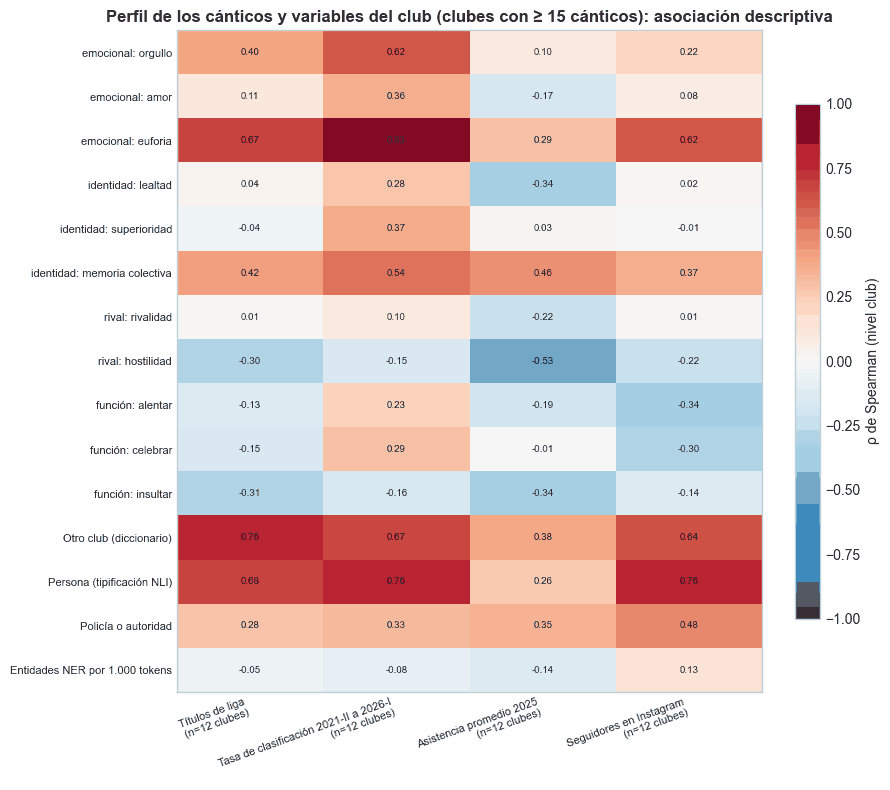

Clubes en el cruce: 12 con al menos 15 cánticos · 60 correlaciones evaluadas


indicador                   variable   rho  p_valor  \
0             emocional:euforia         tasa_clasificacion  0.93   0.0000   
1                  tipo_persona       seguidores_instagram  0.76   0.0040   
2            menciona_otro_club  titulos_liga_hasta_2026_I  0.76   0.0041   
3                  tipo_persona         tasa_clasificacion  0.76   0.0042   
4                  tipo_persona  titulos_liga_hasta_2026_I  0.68   0.0156   
5             emocional:euforia  titulos_liga_hasta_2026_I  0.67   0.0161   
6            menciona_otro_club         tasa_clasificacion  0.67   0.0176   
7            menciona_otro_club       seguidores_instagram  0.64   0.0256   
8             emocional:orgullo         tasa_clasificacion  0.62   0.0306   
9             emocional:euforia       seguidores_instagram  0.62   0.0315   
10  identidad:memoria colectiva         tasa_clasificacion  0.54   0.0696   
11             rival:hostilidad   promedio_asistencia_2025 -0.53   0.0754   

    n_clubes   q_bh 

Correlaciones con q de Benjamini-Hochberg < 0,05: 1


In [57]:
VARIABLES_CLUB_FASE4 = {
    "titulos_liga_hasta_2026_I": "Títulos de liga",
    "tasa_clasificacion": "Tasa de clasificación 2021-II a 2026-I",
    "promedio_asistencia_2025": "Asistencia promedio 2025",
    "seguidores_instagram": "Seguidores en Instagram",
}
# Conjunto preespecificado para limitar las comparaciones múltiples.
ETIQUETAS_CRUCE_CLUB = [
    "emocional:orgullo", "emocional:amor", "emocional:euforia", "identidad:lealtad",
    "identidad:superioridad", "identidad:memoria colectiva", "rival:rivalidad",
    "rival:hostilidad", "funcion:alentar", "funcion:celebrar", "funcion:insultar",
]
perfil_por_club = (
    tabla_analitica.groupby(["club_id", "nombre_corto", "region"])
    .agg(
        n_canticos=("titulo_referencia", "size"),
        **{f"pct|{e}": (f"activa|{e}", "mean") for e in ETIQUETAS_CRUCE_CLUB},
        **{f"pct|{r}": (r, "mean") for r in ["menciona_otro_club", "tipo_persona", "menciona_autoridad"]},
        entidades_por_1000_tokens=("n_entidades_ner", "sum"),
        tokens=("n_tokens_modelo", "sum"),
    )
    .reset_index()
)
perfil_por_club["entidades_por_1000_tokens"] = perfil_por_club["entidades_por_1000_tokens"] / perfil_por_club["tokens"] * 1000
perfil_por_club = perfil_por_club.merge(clubes[["club_id", *VARIABLES_CLUB_FASE4]], on="club_id", how="left")
columnas_perfil = [c for c in perfil_por_club.columns if c.startswith("pct|")] + ["entidades_por_1000_tokens"]
# Mismo mínimo que la figura por club: con menos de 15 cánticos una proporción
# cambia 7 puntos o más al agregar o quitar una sola letra.
MINIMO_CANTICOS_CLUB = 15
clubes_cruce = perfil_por_club.query("n_canticos >= @MINIMO_CANTICOS_CLUB")
filas = []
for columna in columnas_perfil:
    for variable in VARIABLES_CLUB_FASE4:
        datos = clubes_cruce[[columna, variable]].dropna()
        prueba = spearmanr(datos[columna], datos[variable])
        filas.append(
            {"indicador": columna.replace("pct|", ""), "variable": variable, "rho": prueba.statistic,
             "p_valor": prueba.pvalue, "n_clubes": len(datos)}
        )
correlaciones_club_fase4 = pd.DataFrame(filas)


def valores_q_bh(p_valores):
    """Valores q de Benjamini-Hochberg: controlan la tasa de falsos descubrimientos."""
    p = np.asarray(p_valores, dtype=float)
    orden = np.argsort(p)
    ajustados = p[orden] * len(p) / np.arange(1, len(p) + 1)
    ajustados = np.minimum.accumulate(ajustados[::-1])[::-1].clip(max=1)
    q = np.empty_like(ajustados)
    q[orden] = ajustados
    return q


correlaciones_club_fase4["q_bh"] = valores_q_bh(correlaciones_club_fase4["p_valor"])
matriz_club = correlaciones_club_fase4.pivot(index="indicador", columns="variable", values="rho").loc[
    [c.replace("pct|", "") for c in columnas_perfil], list(VARIABLES_CLUB_FASE4)
]
display(
    perfil_por_club[["nombre_corto", "region", "n_canticos", *columnas_perfil[:6]]]
    .sort_values("n_canticos", ascending=False).round(3)
)
fig, ax = plt.subplots(figsize=(9, 8))
imagen = ax.imshow(matriz_club.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.grid(False)
n_variable = correlaciones_club_fase4.groupby("variable")["n_clubes"].max()
ax.set_xticks(range(4), [f"{VARIABLES_CLUB_FASE4[v]}\n(n={n_variable[v]} clubes)" for v in matriz_club.columns],
              rotation=20, ha="right", fontsize=8)
NOMBRES_INDICADOR_CLUB = {**INDICADORES_REFERENTE, "entidades_por_1000_tokens": "Entidades NER por 1.000 tokens"}
ax.set_yticks(
    range(len(matriz_club)), [NOMBRES_INDICADOR_CLUB.get(e, nombre_visible(e)) for e in matriz_club.index], fontsize=8
)
for i in range(matriz_club.shape[0]):
    for j in range(matriz_club.shape[1]):
        ax.text(j, i, f"{matriz_club.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(imagen, ax=ax, fraction=0.04).set_label("ρ de Spearman (nivel club)")
ax.set_title(
    f"Perfil de los cánticos y variables del club (clubes con ≥ {MINIMO_CANTICOS_CLUB} cánticos): asociación descriptiva",
    fontweight="bold",
)
fig.tight_layout()
plt.show()
print(
    f"Clubes en el cruce: {len(clubes_cruce)} con al menos {MINIMO_CANTICOS_CLUB} cánticos · "
    f"{len(correlaciones_club_fase4)} correlaciones evaluadas"
)
display(
    correlaciones_club_fase4.query("rho.abs() >= 0.5").sort_values("p_valor")
    .round({"rho": 2, "p_valor": 4, "q_bh": 3}).reset_index(drop=True)
)
print(f"Correlaciones con q de Benjamini-Hochberg < 0,05: {int((correlaciones_club_fase4['q_bh'] < 0.05).sum())}")

**Resultado observado.** Con los 12 clubes que tienen al menos 15 cánticos se calcularon 60 correlaciones de Spearman. Solo una se mantiene con la corrección de Benjamini-Hochberg, que controla la tasa de falsos descubrimientos (Benjamini & Hochberg, 1995), a q < 0,05: la proporción de cánticos con euforia aumenta con la tasa de clasificación a la fase final entre 2021-II y 2026-I (ρ = 0,93; q = 0,001). Otras asociaciones alcanzan |ρ| ≥ 0,5, como la mención de otros clubes con los títulos de liga (0,76) o la de personas con los seguidores en Instagram (0,76), pero sus valores q, entre 0,06 y 0,38, no permiten distinguirlas del azar con tantas comparaciones.

**Interpretación.** La asociación entre euforia y clasificación es coherente con un repertorio más celebratorio en los clubes con campañas más exitosas, pero debe leerse con tres cautelas: se calcula con 12 clubes; el valor más alto de euforia corresponde a Junior, cuyas letras proceden casi todas de Barrabrava.net, de modo que club y fuente no pueden separarse, y las variables de rendimiento están correlacionadas entre sí. Es una regularidad descriptiva del corpus, no una explicación del comportamiento de las hinchadas.

## 32. Integridad, exportación y manifiesto

Los controles verifican las 550 entradas, la unicidad de identificadores, la ausencia de textos vacíos, la cobertura completa de inferencia de cada modelo, puntuaciones finitas en [0, 1], distribuciones de una etiqueta que suman uno, correspondencia exacta entre posiciones y texto, y alineación de todas las salidas con el orden de entrada. Cada archivo exportado conserva `cantico_id`, club, región, fuente, `texto_modelo`, modelo, revisión, etiqueta o entidad, puntuación y parámetros de inferencia. El manifiesto SHA-256 permite comprobar que ninguna salida cambió después de la ejecución.

In [ ]:
base_texto = corpus_fase4[["cantico_id", "club_id", "nombre_corto", "region", "fuente", "texto_modelo"]]


def a_largo(tabla, clave, **columnas_fijas):
    espec = MODELOS_FASE4[clave]
    largo = (
        tabla.rename_axis("cantico_id").reset_index()
        .melt(id_vars="cantico_id", var_name="etiqueta", value_name="puntuacion")
        .assign(modelo=espec["id"], revision=espec["revision"], **columnas_fijas)
    )
    return base_texto.merge(largo, on="cantico_id", how="right", validate="one_to_many")


exportar_clasificadores = pd.concat(
    [
        a_largo(
            probabilidades_clasificadores[clave], clave, tarea=MODELOS_FASE4[clave]["tarea"],
            agregacion=CONFIG_CLASIFICADORES_FASE4[clave],
            max_longitud=MODELOS_FASE4[clave]["max_longitud"],
            multietiqueta=metadatos_clasificadores[clave]["multietiqueta"],
        )
        for clave in CONFIG_CLASIFICADORES_FASE4
    ],
    ignore_index=True,
)
exportar_zero_shot = pd.concat(
    [
        a_largo(
            tabla, clave, tarea="Zero-shot NLI", formulacion=formulacion, regla_puntuacion=regla,
            agregacion="maximo", umbral=UMBRAL_ZS,
            seleccionada=(clave, formulacion, regla) == (CLAVE_NLI_SELECCIONADA, FORMULACION_SELECCIONADA, REGLA_SELECCIONADA),
        )
        for (clave, formulacion, regla), tabla in puntuaciones_zero_shot.items()
    ],
    ignore_index=True,
)
exportar_zero_shot["hipotesis"] = [
    HIPOTESIS_FASE4[f][e] for f, e in zip(exportar_zero_shot["formulacion"], exportar_zero_shot["etiqueta"])
]
exportar_zero_shot["activa"] = exportar_zero_shot["puntuacion"].ge(UMBRAL_ZS)
exportar_ner = pd.concat(
    [
        t.assign(modelo=MODELOS_FASE4[c]["id"], revision=MODELOS_FASE4[c]["revision"], estrategia=e)
        for (c, e), t in entidades_ner.items()
    ],
    ignore_index=True,
).merge(base_texto, on="cantico_id", how="left", validate="many_to_one")
exportar_entidades_finales = entidades_finales.assign(
    modelo=MODELOS_FASE4[CLAVE_NER_SELECCIONADA]["id"], revision=MODELOS_FASE4[CLAVE_NER_SELECCIONADA]["revision"],
    estrategia=ESTRATEGIA_NER_SELECCIONADA, umbral_ner=UMBRAL_NER_SELECCIONADO,
    modelo_tipificacion=MODELOS_FASE4[CLAVE_NLI_SELECCIONADA]["id"],
    revision_tipificacion=MODELOS_FASE4[CLAVE_NLI_SELECCIONADA]["revision"],
).merge(base_texto, on="cantico_id", how="left", validate="many_to_one")
tabla_final_fase4 = (
    base_texto.set_index("cantico_id")
    .join(polaridad)
    .join(sentimiento[BASELINE_SELECCIONADO].add_prefix("baseline|"))
    .join(zs_final.add_prefix("zero_shot|"))
    .join(activaciones_emocion(EMOCION_SELECCIONADA).add_prefix("emocion_especializada_activa|"))
    .join(referentes_por_cantico)
    .reset_index()
)

# Controles de integridad de todas las salidas.
controles_fase4 = {
    "Cánticos de entrada": len(corpus_fase4) == 550,
    "Identificadores únicos": corpus_fase4["cantico_id"].is_unique,
    "Sin textos vacíos": corpus_fase4["texto_modelo"].str.strip().ne("").all(),
    "Clasificadores con 550 filas en el orden de entrada": all(
        t.index.tolist() == IDS_FASE4 for t in probabilidades_clasificadores.values()
    ),
    "Zero-shot con 550 × 33 puntuaciones por configuración": len(puntuaciones_zero_shot) == 10 and all(
        t.shape == (550, 33) and t.index.tolist() == IDS_FASE4 for t in puntuaciones_zero_shot.values()
    ),
    "Puntuación NLI propia equivalente al pipeline de transformers": bool(
        control_implementacion_nli["diferencia_maxima"].max() < 1e-3
    ),
    "Puntuaciones finitas en [0, 1]": bool(
        np.isfinite(exportar_clasificadores["puntuacion"]).all()
        and np.isfinite(exportar_zero_shot["puntuacion"]).all()
        and exportar_clasificadores["puntuacion"].between(0, 1).all()
        and exportar_zero_shot["puntuacion"].between(0, 1).all()
        and exportar_ner["puntuacion"].between(0, 1).all()
    ),
    "Distribuciones de una etiqueta suman 1": all(
        np.allclose(probabilidades_clasificadores[c].sum(axis=1), 1)
        for c in CONFIG_CLASIFICADORES_FASE4 if not metadatos_clasificadores[c]["multietiqueta"]
    ),
    "Cobertura de inferencia (cánticos procesados por cada modelo)": all(
        m["n_textos"] == 550 for m in metadatos_clasificadores.values()
    ),
    "Todos los cánticos fragmentados cubren su texto completo": all(
        r["n_textos"] == 550 for r in REGISTRO_EJECUCION_FASE4
    ),
    "Posiciones de entidades coinciden con el texto": all(
        texto_por_id[c][i:f] == m for c, i, f, m in exportar_ner[["cantico_id", "inicio", "fin", "mencion"]].itertuples(index=False)
    ),
    "Menciones del diccionario coinciden con el texto": all(
        texto_por_id[c][i:f] == m
        for c, i, f, m in menciones_diccionario[["cantico_id", "inicio", "fin", "mencion"]].itertuples(index=False)
    ),
    "Representaciones alineadas con la entrada": [r["cantico_id"] for r in representaciones_fase4] == IDS_FASE4,
    "Tabla final con 550 filas": len(tabla_final_fase4) == 550 and tabla_final_fase4["cantico_id"].tolist() == IDS_FASE4,
    "Revisiones de modelos fijadas (40 caracteres)": all(len(m["revision"]) == 40 for m in MODELOS_FASE4.values()),
}
tabla_controles_fase4 = pd.DataFrame(controles_fase4.items(), columns=["control", "resultado"])
display(tabla_controles_fase4)
assert tabla_controles_fase4["resultado"].all(), "Falló un control de integridad de la Fase 4"

# Tabla comparativa de los doce modelos: métricas externas del registro, con su
# benchmark y su fuente, más parámetros y tiempo medidos en esta ejecución.
COMPARABILIDAD_METRICAS = {
    "nli_mdeberta": "Comparable con BETO-XNLI: misma prueba (XNLI en español) y misma métrica (accuracy)",
    "nli_beto": "Comparable con mDeBERTa-v3: misma prueba (XNLI en español) y misma métrica (accuracy)",
    "ner_beto": "Comparable con XLM-RoBERTa-large NER: CoNLL-2002 en español y F1; la ficha no precisa la partición",
    "ner_xlmr": "Comparable con BETO-NER: CoNLL-2002 en español y F1",
}
def comparabilidad_metrica(clave, espec):
    if clave in COMPARABILIDAD_METRICAS:
        return COMPARABILIDAD_METRICAS[clave]
    if all(str(espec[m]).startswith("No reportada") for m in ("precision", "recall", "f1", "accuracy")):
        return "Sin métrica publicada para esta revisión"
    return "Orientativa: benchmark, idioma o métrica sin equivalente en otro candidato"


medicion_modelos = pd.DataFrame(REGISTRO_EJECUCION_FASE4).groupby("clave").agg(
    parametros_millones=("parametros_millones", "first"), segundos=("segundos", "sum")
)
PAPEL_MODELO = {
    BASELINE_SELECCIONADO: "Seleccionado: línea base",
    EMOCION_SELECCIONADA: "Seleccionado: emociones especializadas",
    CLAVE_NLI_SELECCIONADA: "Seleccionado: zero-shot y tipificación",
    CLAVE_NLI_CONTRASTE: "Contraste del zero-shot",
    CLAVE_NER_SELECCIONADA: "Seleccionado: NER",
}
tabla_comparativa_fase4 = pd.DataFrame(
    [
        {
            "Modelo": espec["id"], "Arquitectura": espec["arquitectura"], "Idioma": espec["idioma"],
            "Tarea": espec["tarea"], "Dataset": espec["dataset"], "Etiquetas": espec["etiquetas"],
            "Precision": espec["precision"], "Recall": espec["recall"], "F1": espec["f1"],
            "Accuracy": espec["accuracy"],
            "Parámetros": f"{medicion_modelos.loc[clave, 'parametros_millones']:.1f} M".replace(".", ","),
            "Benchmark de la métrica": espec["benchmark"], "Fuente de la métrica": espec["fuente_metrica"],
            "Comparabilidad de la métrica": comparabilidad_metrica(clave, espec),
            "Segundos de inferencia": round(float(medicion_modelos.loc[clave, "segundos"]), 1),
            "Papel en la Fase 4": PAPEL_MODELO.get(clave, "Comparado y descartado"),
            "Observaciones": espec["observaciones"],
        }
        for clave, espec in MODELOS_FASE4.items()
    ]
)
assert len(tabla_comparativa_fase4) == 12

rutas_fase4 = {
    "predicciones_clasificadores_fase4.csv.gz": exportar_clasificadores,
    "predicciones_zero_shot_fase4.csv.gz": exportar_zero_shot,
    "entidades_ner_todas_configuraciones_fase4.csv.gz": exportar_ner,
    "entidades_finales_fase4.csv.gz": exportar_entidades_finales,
    "menciones_diccionario_fase4.csv.gz": menciones_diccionario.merge(
        base_texto, on=["cantico_id", "club_id"], how="left"
    ),
    "tabla_final_por_cantico_fase4.csv": tabla_final_fase4,
    "tabla_comparativa_modelos_fase4.csv": tabla_comparativa_fase4,
    "comparacion_sentimiento_fase4.csv": comparacion_sentimiento,
    "comparacion_emociones_fase4.csv": ranking_emociones,
    "comparacion_zero_shot_fase4.csv": ranking_zs,
    "comparacion_ner_fase4.csv": ranking_ner,
    "registro_ejecucion_fase4.csv": pd.DataFrame(REGISTRO_EJECUCION_FASE4),
    "procedencia_apodos_wikipedia_fase4.csv": procedencia_apodos,
}
for nombre, tabla in rutas_fase4.items():
    # gzip sin marca de tiempo: el mismo contenido produce la misma huella SHA-256.
    compresion = {"method": "gzip", "mtime": 0} if nombre.endswith(".gz") else None
    tabla.to_csv(SALIDAS_FASE4 / nombre, index=False, encoding="utf-8", compression=compresion)
ruta_jsonl = SALIDAS_FASE4 / "representacion_estructurada_fase4.jsonl"
ruta_jsonl.write_text(
    "\n".join(json.dumps(r, ensure_ascii=False, allow_nan=False) for r in representaciones_fase4) + "\n", encoding="utf-8"
)
# Si las predicciones vinieron de la caché, el formato de pesos se consulta en
# la misma revisión del repositorio, con la regla de cargar_modelo.
for clave, espec in MODELOS_FASE4.items():
    if clave not in FORMATO_PESOS_FASE4:
        archivos_revision = set(list_repo_files(espec["id"], revision=espec["revision"]))
        FORMATO_PESOS_FASE4[clave] = (
            "model.safetensors" if "model.safetensors" in archivos_revision else "pytorch_model.bin"
        )
configuracion_fase4 = {
    "alcance": "inferencia con modelos preentrenados, sin entrenamiento ni ajuste fino",
    "entrada": {"n_canticos": 550, "huella_sha256": HUELLA_ENTRADA_FASE4, "columna_texto": "texto_modelo"},
    "entorno": ENTORNO_FASE4,
    "modelos": {
        c: {"id": m["id"], "revision": m["revision"], "tarea": m["tarea"], "max_longitud": m["max_longitud"],
            "formato_pesos": FORMATO_PESOS_FASE4.get(c)}
        for c, m in MODELOS_FASE4.items()
    },
    "agregacion_clasificadores": CONFIG_CLASIFICADORES_FASE4,
    "umbrales_goemotions_ficha": UMBRALES_GOEMOTIONS_FICHA,
    "zero_shot": {
        "formulaciones": HIPOTESIS_FASE4, "umbral": UMBRAL_ZS, "agregacion_fragmentos": "maximo",
        "reglas_puntuacion": REGLAS_NLI,
        "seleccion": {"modelo": MODELOS_FASE4[CLAVE_NLI_SELECCIONADA]["id"], "formulacion": FORMULACION_SELECCIONADA,
                      "regla": REGLA_SELECCIONADA},
        "contraste": {"modelo": MODELOS_FASE4[CLAVE_NLI_CONTRASTE]["id"], "formulacion": CONFIGURACION_CONTRASTE[1],
                      "regla": CONFIGURACION_CONTRASTE[2]},
    },
    "baseline_seleccionado": MODELOS_FASE4[BASELINE_SELECCIONADO]["id"],
    "emocion_especializada_seleccionada": MODELOS_FASE4[EMOCION_SELECCIONADA]["id"],
    "ner": {
        "modelo": MODELOS_FASE4[CLAVE_NER_SELECCIONADA]["id"], "estrategia": ESTRATEGIA_NER_SELECCIONADA,
        "umbral": UMBRAL_NER_SELECCIONADO, "categorias_tipificacion": CATEGORIAS_REFERENTE,
        "umbral_tipificacion": UMBRAL_TIPIFICACION, "regla_tipificacion": REGLA_SELECCIONADA,
    },
    "marcadores_lexicos": MARCADORES_LEXICOS,
    "diccionario": {"formas": len(diccionario_referentes), "revisiones_wikipedia": REVISIONES_WIKIPEDIA_FASE4},
    "semilla": SEMILLA_FASE4,
}
(SALIDAS_FASE4 / "configuracion_fase4.json").write_text(
    json.dumps(configuracion_fase4, ensure_ascii=False, indent=2, default=str), encoding="utf-8"
)

nombres_manifiesto = [*rutas_fase4, ruta_jsonl.name, "configuracion_fase4.json"]
manifiesto_fase4 = pd.DataFrame(
    [
        {"archivo": n, "bytes": (SALIDAS_FASE4 / n).stat().st_size,
         "sha256": hashlib.sha256((SALIDAS_FASE4 / n).read_bytes()).hexdigest().upper()}
        for n in nombres_manifiesto
    ]
)
manifiesto_fase4.to_csv(SALIDAS_FASE4 / "MANIFIESTO_SHA256_FASE4.csv", index=False, encoding="utf-8")
assert len(pd.read_csv(SALIDAS_FASE4 / "tabla_final_por_cantico_fase4.csv")) == 550
assert sum(1 for _ in ruta_jsonl.open(encoding="utf-8")) == 550
display(manifiesto_fase4)
print(f"Salidas de Fase 4 en ./{SALIDAS_FASE4.relative_to(Path.cwd())}/")
print("Pruebas de integridad de la Fase 4: OK")

**Lectura de la integridad.** Los quince controles resultan verdaderos: las salidas de los doce modelos cubren los 550 cánticos en el mismo orden de entrada; la puntuación NLI propia coincide con la del *pipeline* de `transformers`; las puntuaciones son finitas y están en [0, 1]; las distribuciones de una etiqueta suman uno; las posiciones de cada entidad y de cada mención del diccionario reproducen exactamente el texto, y la tabla final y la representación estructurada tienen 550 filas alineadas. La representación se escribe como JSON estricto, sin valores `NaN`, y cada revisión de modelo es un identificador completo de 40 caracteres. Los archivos comprimidos se guardan sin marca de tiempo, de modo que su huella SHA-256 depende solo del contenido y no del momento de la ejecución.

**Archivos para ejecutar el cuaderno como único entregable.** La Fase 4 no agrega insumos de datos al repositorio de GitHub. El corpus final se reconstruye en memoria con los archivos que ya se descargan y verifican en la [sección 5.1](#51-descarga-explícita-de-datos-y-recursos); los pesos de los modelos se obtienen de sus repositorios oficiales en Hugging Face con revisión fijada, y el diccionario de apodos y los marcadores léxicos forman parte del código, con la procedencia registrada en las referencias de datos. Las carpetas `salidas_fase4/` y `salidas_fase4/cache_inferencia/` son productos regenerables de la ejecución; no son requisitos de entrada.

## 33. Síntesis de la selección de modelos e hiperparámetros

La celda siguiente presenta dos tablas. La primera es la **tabla comparativa** de los doce modelos: reúne arquitectura, idioma, tarea, conjunto de entrenamiento, etiquetas y las métricas externas —*precision*, *recall*, F1 y *accuracy*— con su *benchmark*, su fuente y una columna que indica si la cifra es comparable con la de otro candidato o solo orientativa; los parámetros y los segundos de inferencia se miden en esta ejecución. La segunda resume, para cada tarea, la alternativa elegida, las descartadas, los hiperparámetros de inferencia fijados, el criterio que decidió y la evidencia observada en el corpus. Como se explicó en la [sección 23](#23-estrategia-de-evaluación-sin-un-conjunto-etiquetado), «mejor» significa aquí un mejor resultado en indicadores indirectos definidos antes de la inferencia —validez léxica, acuerdo entre modelos, capacidad discriminante, calidad de las menciones y coherencia con el diccionario—, no una mayor exactitud frente a una anotación, que no existe.

In [59]:
print("Tabla comparativa de los doce modelos evaluados")
with pd.option_context("display.max_colwidth", 80):
    display(tabla_comparativa_fase4)


def nombre_modelo(clave):
    return MODELOS_FASE4[clave]["id"].split("/")[1]


def num(valor, decimales=3):
    """Número con coma decimal para el texto de la tabla."""
    return f"{valor:.{decimales}f}".replace(".", ",")


sentimiento_por_clave = comparacion_sentimiento.set_index("clave")
otro_baseline = next(c for c in sentimiento_por_clave.index if c != BASELINE_SELECCIONADO)
emociones_por_clave = ranking_emociones.set_index("clave")
segunda_emocion = ranking_emociones.loc[1, "clave"]
zs_elegida, zs_segunda = ranking_zs.iloc[0], ranking_zs.iloc[1]
zs_otra_formulacion = comparacion_zs.query(
    "clave == @CLAVE_NLI_SELECCIONADA and regla == @REGLA_SELECCIONADA and formulacion != @FORMULACION_SELECCIONADA"
).iloc[0]
ner_elegida, ner_segunda = ranking_ner.iloc[0], ranking_ner.iloc[1]
ner_otra_estrategia = comparacion_ner.query(
    "clave == @CLAVE_NER_SELECCIONADA and estrategia != @ESTRATEGIA_NER_SELECCIONADA"
).iloc[0]
umbrales_ner = umbral_ner.set_index("umbral")
siguiente_umbral_ner = umbral_ner.query("umbral > @UMBRAL_NER_SELECCIONADO")["umbral"].min()
coincidencia = coincidencia_tipificacion["coincidencia"]
coincidencia_ampliada = coincidencia_tipificacion["coincidencia_ampliada"]

if EMOCION_SELECCIONADA == "emo_goemotions":
    decision_emocion = "umbrales por etiqueta de la ficha; máximo entre fragmentos"
elif metadatos_clasificadores[EMOCION_SELECCIONADA]["multietiqueta"]:
    decision_emocion = f"umbral {num(0.5, 1)}; máximo entre fragmentos"
else:
    decision_emocion = "etiqueta de mayor probabilidad; media ponderada entre fragmentos"

resumen_seleccion_fase4 = pd.DataFrame(
    [
        {
            "tarea": "1A · Polaridad (línea base)",
            "seleccion": nombre_modelo(BASELINE_SELECCIONADO),
            "alternativas": nombre_modelo(otro_baseline),
            "hiperparametros": "etiqueta de mayor probabilidad; media ponderada entre fragmentos",
            "criterio": "AUC léxica media",
            "evidencia": (
                f"AUC {num(sentimiento_por_clave.loc[BASELINE_SELECCIONADO, 'auc_media'])} frente a "
                f"{num(sentimiento_por_clave.loc[otro_baseline, 'auc_media'])}; κ entre modelos = {num(kappa_sentimiento)}"
            ),
        },
        {
            "tarea": "1B · Emociones especializadas",
            "seleccion": nombre_modelo(EMOCION_SELECCIONADA),
            "alternativas": ", ".join(nombre_modelo(c) for c in MODELOS_EMOCION_FASE4 if c != EMOCION_SELECCIONADA),
            "hiperparametros": decision_emocion,
            "criterio": "rango medio: conceptos, AUC léxica, no residual, acuerdo con zero-shot",
            "evidencia": (
                f"rango {num(emociones_por_clave.loc[EMOCION_SELECCIONADA, 'rango_medio'], 2)} frente a "
                f"{num(emociones_por_clave.loc[segunda_emocion, 'rango_medio'], 2)} ({nombre_modelo(segunda_emocion)}); "
                f"AUC {num(emociones_por_clave.loc[EMOCION_SELECCIONADA, 'auc_lexica_media'])}; "
                f"{emociones_por_clave.loc[EMOCION_SELECCIONADA, 'conceptos_del_proyecto_cubiertos']} conceptos cubiertos"
            ),
        },
        {
            "tarea": "1C · Zero-shot multietiqueta",
            "seleccion": f"{nombre_modelo(CLAVE_NLI_SELECCIONADA)} · {FORMULACION_SELECCIONADA} · {NOMBRE_REGLA[REGLA_SELECCIONADA]}",
            "alternativas": f"{len(ranking_zs) - 1} configuraciones (3 modelos × 2 formulaciones × reglas)",
            "hiperparametros": f"formulación, regla de puntuación, umbral {num(UMBRAL_ZS, 1)}; máximo entre fragmentos",
            "criterio": (
                "rango medio: AUC léxica, acuerdo entre modelos, etiquetas informativas; "
                "desempate: hipótesis no repetidas y costo"
            ),
            "evidencia": (
                f"rango {num(zs_elegida['rango_medio'], 2)} frente a {num(zs_segunda['rango_medio'], 2)} "
                f"({nombre_modelo(zs_segunda['clave'])} · {zs_segunda['formulacion']} · {NOMBRE_REGLA[zs_segunda['regla']]}); "
                f"hipótesis repetidas {zs_elegida['hipotesis_repetidas']} frente a {zs_segunda['hipotesis_repetidas']}; "
                f"AUC {num(zs_elegida['auc_lexica_media'])} frente a {num(zs_otra_formulacion['auc_lexica_media'])} "
                f"con la otra formulación; {zs_elegida['etiquetas_informativas']} de 33 etiquetas informativas"
            ),
        },
        {
            "tarea": "1C · Umbral zero-shot",
            "seleccion": num(UMBRAL_ZS, 1),
            "alternativas": "; ".join(num(u, 1) for u in UMBRALES_CANDIDATOS if u != UMBRAL_ZS),
            "hiperparametros": "presencia si la puntuación alcanza el umbral",
            "criterio": "estabilidad del orden de prevalencias (τ de Kendall)",
            "evidencia": (
                f"τ mínima = {num(estabilidad_umbral['tau_kendall_vs_0_5'].min())}; "
                f"mediana de {activas_zs.sum(axis=1).median():.0f} etiquetas activas por cántico"
            ),
        },
        {
            "tarea": "2 · NER",
            "seleccion": f"{nombre_modelo(CLAVE_NER_SELECCIONADA)} · {ESTRATEGIA_NER_SELECCIONADA}",
            "alternativas": f"{len(ranking_ner) - 1} configuraciones (3 modelos × 2 estrategias)",
            "hiperparametros": f"agregación {ESTRATEGIA_NER_SELECCIONADA}; puntuación mínima {num(UMBRAL_NER_SELECCIONADO, 1)}",
            "criterio": "rango medio de ocho criterios de cobertura, tipo y calidad",
            "evidencia": (
                f"rango {num(ner_elegida['rango_medio'], 2)} frente a {num(ner_segunda['rango_medio'], 2)} "
                f"({nombre_modelo(ner_segunda['clave'])} · {ner_segunda['estrategia']}); menciones que cortan palabra: "
                f"{num(ner_elegida['corta_palabra_pct'], 1)} % frente a {num(ner_otra_estrategia['corta_palabra_pct'], 1)} % "
                f"con {ner_otra_estrategia['estrategia']}"
            ),
        },
        {
            "tarea": "2 · Puntuación mínima NER",
            "seleccion": num(UMBRAL_NER_SELECCIONADO, 1),
            "alternativas": "; ".join(num(u, 1) for u in umbral_ner["umbral"] if u != UMBRAL_NER_SELECCIONADO),
            "hiperparametros": "conservar entidades con puntuación mayor o igual",
            "criterio": "mayor umbral con pérdida de cobertura ≤ 2 puntos",
            "evidencia": (
                f"con {num(siguiente_umbral_ner, 1)}: ruido {num(umbrales_ner.loc[UMBRAL_NER_SELECCIONADO, 'ruido_evidente_pct'], 1)} % → "
                f"{num(umbrales_ner.loc[siguiente_umbral_ner, 'ruido_evidente_pct'], 1)} %, pérdida de cobertura "
                f"{num(umbrales_ner.loc[siguiente_umbral_ner, 'perdida_cobertura_pts'], 1)} puntos"
            ),
        },
        {
            "tarea": "2 · Tipificación de menciones",
            "seleccion": f"{nombre_modelo(CLAVE_NLI_SELECCIONADA)} · {NOMBRE_REGLA[REGLA_SELECCIONADA]}",
            "alternativas": "tipos PER, LOC, ORG y MISC del NER",
            "hiperparametros": f"8 categorías; umbral {num(UMBRAL_TIPIFICACION, 1)}; contexto de tres versos",
            "criterio": "coherencia con la categoría esperada del diccionario (estricta y ampliada)",
            "evidencia": "; ".join(
                f"{c}: {num(coincidencia[c] * 100, 1)} % estricta, {num(coincidencia_ampliada[c] * 100, 1)} % ampliada"
                for c in coincidencia.index
            ),
        },
    ]
)
with pd.option_context("display.max_colwidth", None):
    display(resumen_seleccion_fase4)

Tabla comparativa de los doce modelos evaluados


tarea  \
0    1A · Polaridad (línea base)   
1  1B · Emociones especializadas   
2   1C · Zero-shot multietiqueta   
3          1C · Umbral zero-shot   
4                        2 · NER   
5      2 · Puntuación mínima NER   
6  2 · Tipificación de menciones   

                                                    seleccion  \
0                               robertuito-sentiment-analysis   
1                         multilingual-emotion-classification   
2  bge-m3-zeroshot-v2.0 · B_hipotesis · implicación vs. resto   
3                                                         0,5   
4                    bert-spanish-cased-finetuned-ner · first   
5                                                         0,0   
6                bge-m3-zeroshot-v2.0 · implicación vs. resto   

                                                                                 alternativas  \
0                                             twitter-xlm-roberta-base-sentiment-multilingual   
1  robertuito-emotion-a

**Lectura de las tablas.** La tabla comparativa confirma que solo dos pares de métricas externas pueden compararse directamente: la *accuracy* de mDeBERTa-v3 y BETO-XNLI en XNLI en español (0,832 frente a 0,799) y el F1 de BETO-NER y XLM-RoBERTa-large en CoNLL-2002 (0,901 frente a 0,892). En NER, el modelo con mejor F1 externo es también el seleccionado. En NLI, en cambio, la mejor *accuracy* externa, la de mDeBERTa-v3, no evitó la saturación en los cánticos, y el modelo seleccionado, BGE-M3, no publica una cifra comparable: la decisión descansa en el comportamiento observado en el corpus. BGE-M3 es también el modelo más grande y el de mayor costo de inferencia, un precio que se acepta porque es el único que combina las 33 etiquetas informativas con una AUC léxica superior a 0,7.

En cada tarea, la alternativa elegida mejora los indicadores que la comparación definió como relevantes. RoBERTuito ordena mejor que XLM-T los cánticos con marcadores léxicos (AUC media de 0,715 frente a 0,654). En NER, la estrategia `first` reduce las menciones que cortan palabras de 46,8 % a 0,1 % en BETO. En zero-shot, BGE-M3 evita tanto la saturación de mDeBERTa-v3 como el vaciamiento de BETO-XNLI con la regla estricta, con una AUC léxica cercana a la mejor (0,766 frente a 0,789); la regla implicación vs. resto, por su parte, reduce la saturación en los dos modelos de tres clases y mejora la AUC de mDeBERTa-v3. Dos decisiones conservan la opción más simple porque las alternativas no mejoraban: el umbral de 0,5, que mantiene estable el orden de las etiquetas, y la puntuación mínima NER de 0, porque exigir 0,5 reduce el ruido solo de 6,8 % a 6,2 % a costa de seis puntos de cobertura.

La tabla también muestra lo que no se resolvió: la tipificación de menciones solo coincide con la categoría esperada de un club en el 24,5 % de los casos, aunque el 78,0 % cae en categorías contiguas, y el modelo especializado de emociones se elige por un margen estrecho. Ninguna de estas cifras es una medida de exactitud; son las mejores evidencias disponibles sin anotación humana.

## 34. Limitaciones metodológicas

1. **No hay conjunto de prueba propio.** Sin anotación humana no puede estimarse *accuracy*, *precision*, *recall* ni F1 de ningún modelo en cánticos colombianos. Las métricas citadas pertenecen a otros *benchmarks* —tuits, noticias, Wikipedia, pares NLI o datos sintéticos— y no se trasladan a este dominio.
2. **Las pruebas internas son indirectas.** La AUC léxica solo verifica expresiones literales definidas por el equipo; un modelo que reconozca orgullo implícito no recibe crédito y uno que responda a palabras clave puede obtener un buen resultado sin comprender el texto. El acuerdo entre modelos tampoco equivale a exactitud: modelos entrenados con datos parecidos pueden compartir errores.
3. **Las etiquetas dependen del modelo, de la formulación y de la regla de puntuación.** La prevalencia de una etiqueta zero-shot cambia con la hipótesis, la regla que convierte los logits en probabilidad y el umbral; el cambio de modelo pesa todavía más. Por eso las comparaciones se hacen entre grupos con la misma configuración y no se interpretan como porcentajes absolutos de afecto. Además, la elección entre las dos formulaciones de BGE-M3 se resolvió con un desempate precisado después de observar el empate, como se documenta en la sección 27.3.
4. **Cambio de dominio.** Los modelos se entrenaron con tuits, reseñas, noticias o textos traducidos. La jerga barrista, las elisiones («vamo», «pa'»), la ironía, la negación, los apodos y las grafías deliberadas pueden inducir errores sistemáticos; por ejemplo, «loco» y «locura» expresan devoción y no siempre se reconocen como entusiasmo.
5. **Taxonomías no equivalentes y emociones negativas poco diferenciadas.** Las categorías de Ekman, GoEmotions, tabularis y las hipótesis del proyecto no son intercambiables; el bajo acuerdo en conceptos compartidos muestra que «alegría» o «amor» no significan lo mismo en todos los modelos. En el zero-shot, además, ira, desprecio, asco y frustración se mueven casi juntas y junto con el antagonismo hacia el rival, de modo que no pueden leerse como experiencias distintas.
6. **Cobertura parcial de entidades.** Los reconocedores genéricos detectan una fracción de las menciones de club y las tipifican de forma inconsistente. El diccionario mejora el enlace, pero solo contiene nombres y apodos documentados; deja fuera apodos despectivos, barras, jugadores no identificados y referentes que requieren conocimiento experto. La regla del artículo para los topónimos homónimos es una aproximación: «Cali» o «Pasto» sin artículo pueden nombrar al club y se cuentan como territorio. La tipificación NLI de menciones es exploratoria: confunde club, hinchada, institución y símbolo, que en los cánticos comparten el mismo nombre, y su coherencia solo se mide sobre las menciones que el diccionario puede verificar.
7. **Longitud de los textos.** Los cánticos largos activan más etiquetas zero-shot (ρ = 0,336), porque contienen más pasajes que pueden apoyar una hipótesis; en los pocos textos fragmentados, la agregación por máximo refuerza ese efecto. La estandarización por longitud lo controla en los cruces regionales, pero no lo elimina de las prevalencias generales.
8. **Composición del corpus.** Las diferencias por región o club reflejan también el número desigual de textos, la concentración en pocos clubes y la procedencia editorial: Caribe depende casi por completo de Junior y de Barrabrava.net, y una parte de Pacífica procede de un único blog transcrito en mayúsculas. La región es la de la sede actual del club: el único cántico de Alianza FC se cuenta en Caribe, aunque se publicó bajo la identidad de Alianza Petrolera, anterior al traslado de sede aprobado en 2024 y documentado en la Fase 1. Los grupos pequeños producen intervalos amplios.
9. **Asociación no es causa.** Las correlaciones con títulos, asistencia, seguidores o clasificación se calculan con 12 clubes, variables fuertemente correlacionadas entre sí y 60 comparaciones; solo una supera la corrección por comparaciones múltiples. Son descriptivas y no autorizan conclusiones sobre el comportamiento de las hinchadas.
10. **Reproducibilidad numérica.** Las puntuaciones pueden variar en decimales lejanos entre CPU y GPU o entre versiones de PyTorch. Las decisiones se basan en indicadores agregados y las versiones, revisiones y configuraciones quedan registradas, pero una ejecución en otro hardware puede producir diferencias menores en conteos cercanos a los umbrales.
11. **Contenido ofensivo y ética.** Las letras contienen insultos, amenazas y expresiones discriminatorias que se conservan por integridad documental. Clasificarlas no implica respaldarlas, y los resultados describen textos públicos, no a las personas que los cantan.

## 35. Conclusiones de la Fase 4

1. **La aplicación de los modelos es correcta y verificable.** Doce modelos preentrenados de cuatro familias procesaron los 550 cánticos completos, sin truncamiento silencioso. La implementación zero-shot reproduce el *pipeline* oficial de `transformers`, los quince controles de integridad resultan verdaderos y todas las salidas quedan exportadas con modelo, revisión, parámetros y huella SHA-256. Ningún modelo se entrenó ni se ajustó.

2. **La polaridad ternaria no basta para describir estos textos.** Los dos modelos de polaridad coinciden en que los cánticos negativos son minoría, pero discrepan en el resto de la escala (κ = 0,328). Sobre todo, la polaridad casi no se relaciona con la identidad: tres de cada cuatro cánticos negativos activan alguna etiqueta de afecto o identidad positiva hacia el propio equipo, y casi la mitad de los positivos contiene antagonismo.

3. **Los clasificadores especializados de emociones aportan una lectura limitada en este dominio.** Concentran el corpus en alegría o amor, usan pocas de sus categorías y discrepan entre sí incluso en conceptos compartidos. El de tabularis se eligió por un margen estrecho y funciona como una segunda lectura, no como referencia.

4. **El zero-shot con BGE-M3 e hipótesis explícitas es la representación afectiva más informativa.** Entre diez configuraciones, las dos de BGE-M3 son las únicas que combinan la ausencia de etiquetas saturadas o vacías con una AUC léxica superior a 0,7; la de hipótesis explícitas, además, no repite hipótesis y produce 499 perfiles distintos para 550 cánticos. La comparación mostró que el modelo pesa más que la redacción de la hipótesis, que la regla de puntuación decide la saturación de los modelos de tres clases y que la prueba léxica favorece por construcción a las hipótesis que repiten la palabra del marcador.

5. **Las 33 etiquetas se organizan en dos polos.** El modelo separa con claridad el antagonismo hacia rivales y autoridades de la afirmación afectiva del propio equipo, pero agrupa las emociones negativas en una sola señal. Según las asignaciones del modelo, muchos cánticos combinan ambos polos: afirman la pertenencia al mismo tiempo que provocan o insultan.

6. **Los reconocedores genéricos de entidades captan solo una parte de los referentes del dominio.** La mejor configuración, BETO con agregación `first`, recupera cerca de un tercio de las menciones de club documentadas y tipifica como organización menos de un tercio de las que detecta. El diccionario de nombres y apodos resulta indispensable para enlazarlas, y la tipificación NLI muestra que club, hinchada, institución y símbolo comparten nombre en los cánticos.

7. **La relación entidad → emoción es el hallazgo más consistente.** Nombrar al propio club se asocia con amor, orgullo y pertenencia; nombrar a otro club o a la policía, con burla, desprecio, hostilidad y amenaza, y nombrar el propio territorio, con territorialidad. Son asociaciones descriptivas con intervalos bootstrap que excluyen el cero.

8. **Las diferencias por región y por club reflejan sobre todo la composición del corpus.** El perfil más celebratorio de Caribe se mantiene al controlar fuente y longitud, pero corresponde casi por completo al repertorio de Junior. Las fuentes difieren más en la exaltación del propio equipo que en la hostilidad. De 60 correlaciones con variables de los clubes, solo la de euforia con la tasa de clasificación supera la corrección por comparaciones múltiples, y con 12 clubes sigue siendo una regularidad descriptiva.

9. **La comparación y la selección de hiperparámetros mejoraron el desempeño medible sin anotación.** La agregación `first` eliminó los cortes de palabras del NER; la regla implicación vs. resto redujo la saturación; BGE-M3 corrigió la sobreasignación de mDeBERTa-v3, y la puntuación mínima de entidades y el umbral zero-shot se fijaron después de medir su efecto. Estas mejoras se expresan en indicadores indirectos, porque sin un conjunto etiquetado no puede estimarse exactitud.

10. **El cuaderno sigue siendo el único entregable.** La Fase 4 no requiere nuevos archivos en el repositorio: reconstruye su entrada a partir de los datos verificados en la Fase 1, descarga los modelos con revisión fijada y regenera en cada ejecución la caché y las salidas.

## 36. Referencias unificadas de las Fases 1, 2, 3 y 4

<style>
.apa-reference {
  display: block;
  padding-left: 2em;
  text-indent: -2em;
  margin-bottom: 0.8em;
}
</style>

<span class="apa-reference">AnasAlokla. (s. f.). *multilingual_go_emotions_V1.1* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/AnasAlokla/multilingual_go_emotions_V1.1</span>

<span class="apa-reference">Babelscape. (s. f.). *wikineural-multilingual-ner* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/Babelscape/wikineural-multilingual-ner</span>

<span class="apa-reference">Barbieri, F., Espinosa Anke, L., & Camacho-Collados, J. (2022). XLM-T: Multilingual language models in Twitter for sentiment analysis and beyond. En *Proceedings of the Thirteenth Language Resources and Evaluation Conference* (pp. 258–266). European Language Resources Association. https://aclanthology.org/2022.lrec-1.27/</span>

<span class="apa-reference">Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological), 57*(1), 289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x</span>

<span class="apa-reference">Biber, D. (1993). Representativeness in corpus design. *Literary and Linguistic Computing, 8*(4), 243–257. https://doi.org/10.1093/llc/8.4.243</span>

<span class="apa-reference">Bird, S., Klein, E., & Loper, E. (2009). *Natural language processing with Python: Analyzing text with the Natural Language Toolkit*. O’Reilly Media. https://www.nltk.org/book/</span>

<span class="apa-reference">Borisov, V. (2026). *Multilingual multi-label emotion classification at scale with synthetic data* (arXiv:2604.12633). arXiv. https://doi.org/10.48550/arXiv.2604.12633</span>

<span class="apa-reference">Cañete, J., Chaperon, G., Fuentes, R., Ho, J.-H., Kang, H., & Pérez, J. (2023). *Spanish pre-trained BERT model and evaluation data* (arXiv:2308.02976). arXiv. https://doi.org/10.48550/arXiv.2308.02976</span>

<span class="apa-reference">Cardiff NLP. (s. f.). *twitter-xlm-roberta-base-sentiment-multilingual* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/cardiffnlp/twitter-xlm-roberta-base-sentiment-multilingual</span>

<span class="apa-reference">Castro, J. (2022). El combate entre hinchas en Bogotá: Sociología de la violencia del fútbol. *Revista Colombiana de Sociología, 45*(2), 117–139. https://doi.org/10.15446/rcs.v45n2.95844</span>

<span class="apa-reference">Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS. https://public.dhe.ibm.com/software/analytics/spss/documentation/modeler/14.2/es/CRISP-DM.pdf</span>

<span class="apa-reference">Chen, J., Xiao, S., Zhang, P., Luo, K., Lian, D., & Liu, Z. (2024). M3-Embedding: Multi-linguality, multi-functionality, multi-granularity text embeddings through self-knowledge distillation. En *Findings of the Association for Computational Linguistics: ACL 2024* (pp. 2318–2335). Association for Computational Linguistics. https://doi.org/10.18653/v1/2024.findings-acl.137</span>

<span class="apa-reference">Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement, 20*(1), 37–46. https://doi.org/10.1177/001316446002000104</span>

<span class="apa-reference">Conneau, A., Khandelwal, K., Goyal, N., Chaudhary, V., Wenzek, G., Guzmán, F., Grave, E., Ott, M., Zettlemoyer, L., & Stoyanov, V. (2020). Unsupervised cross-lingual representation learning at scale. En *Proceedings of the 58th Annual Meeting of the Association for Computational Linguistics* (pp. 8440–8451). Association for Computational Linguistics. https://doi.org/10.18653/v1/2020.acl-main.747</span>

<span class="apa-reference">Conneau, A., Rinott, R., Lample, G., Williams, A., Bowman, S., Schwenk, H., & Stoyanov, V. (2018). XNLI: Evaluating cross-lingual sentence representations. En *Proceedings of the 2018 Conference on Empirical Methods in Natural Language Processing* (pp. 2475–2485). Association for Computational Linguistics. https://doi.org/10.18653/v1/D18-1269</span>

<span class="apa-reference">Covington, M. A., & McFall, J. D. (2010). Cutting the Gordian knot: The moving-average type–token ratio (MATTR). *Journal of Quantitative Linguistics, 17*(2), 94–100. https://doi.org/10.1080/09296171003643098</span>

<span class="apa-reference">daveni. (s. f.). *twitter-xlm-roberta-emotion-es* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/daveni/twitter-xlm-roberta-emotion-es</span>

<span class="apa-reference">Deerwester, S., Dumais, S. T., Furnas, G. W., Landauer, T. K., & Harshman, R. (1990). Indexing by latent semantic analysis. *Journal of the American Society for Information Science, 41*(6), 391–407. https://doi.org/10.1002/(SICI)1097-4571(199009)41:6%3C391::AID-ASI1%3E3.0.CO;2-9</span>

<span class="apa-reference">Demszky, D., Movshovitz-Attias, D., Ko, J., Cowen, A., Nemade, G., & Ravi, S. (2020). GoEmotions: A dataset of fine-grained emotions. En *Proceedings of the 58th Annual Meeting of the Association for Computational Linguistics* (pp. 4040–4054). Association for Computational Linguistics. https://doi.org/10.18653/v1/2020.acl-main.372</span>

<span class="apa-reference">Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. En *Proceedings of the 2019 Conference of the North American Chapter of the Association for Computational Linguistics: Human Language Technologies* (pp. 4171–4186). Association for Computational Linguistics. https://doi.org/10.18653/v1/N19-1423</span>

<span class="apa-reference">División Mayor del Fútbol Colombiano. (2026). *Reglamento Liga BetPlay DIMAYOR 2026*. https://dimayor.com.co/wp-content/uploads/2026/01/REGLAMENTO-LIGA-2026-V11-1.pdf</span>

<span class="apa-reference">Efron, B. (1979). Bootstrap methods: Another look at the jackknife. *The Annals of Statistics, 7*(1), 1–26. https://doi.org/10.1214/aos/1176344552</span>

<span class="apa-reference">Ekman, P. (1992). An argument for basic emotions. *Cognition and Emotion, 6*(3–4), 169–200. https://doi.org/10.1080/02699939208411068</span>

<span class="apa-reference">FanChants. (s. f.). *Canciones de equipos de fútbol de Colombia*. Recuperado el 1 de septiembre de 2026, de https://www.fanchants.com/es/country/colombia/classic/</span>

<span class="apa-reference">Gururangan, S., Marasović, A., Swayamdipta, S., Lo, K., Beltagy, I., Downey, D., & Smith, N. A. (2020). Don’t stop pretraining: Adapt language models to domains and tasks. En *Proceedings of the 58th Annual Meeting of the Association for Computational Linguistics* (pp. 8342–8360). Association for Computational Linguistics. https://doi.org/10.18653/v1/2020.acl-main.740</span>

<span class="apa-reference">Hanley, J. A., & McNeil, B. J. (1982). The meaning and use of the area under a receiver operating characteristic (ROC) curve. *Radiology, 143*(1), 29–36. https://doi.org/10.1148/radiology.143.1.7063747</span>

<span class="apa-reference">He, P., Gao, J., & Chen, W. (2021). *DeBERTaV3: Improving DeBERTa using ELECTRA-style pre-training with gradient-disentangled embedding sharing* (arXiv:2111.09543). arXiv. https://doi.org/10.48550/arXiv.2111.09543</span>

<span class="apa-reference">Knijnik, J. (2018). Imagining a multicultural community in an everyday football carnival: Chants, identity and social resistance on Western Sydney terraces. *International Review for the Sociology of Sport, 53*(4), 471–489. https://doi.org/10.1177/1012690216665356</span>

<span class="apa-reference">Laurer, M. (s. f.-a). *bge-m3-zeroshot-v2.0* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/MoritzLaurer/bge-m3-zeroshot-v2.0</span>

<span class="apa-reference">Laurer, M. (s. f.-b). *mDeBERTa-v3-base-xnli-multilingual-nli-2mil7* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7</span>

<span class="apa-reference">Laurer, M., van Atteveldt, W., Casas, A., & Welbers, K. (2023). *Building efficient universal classifiers with natural language inference* (arXiv:2312.17543). arXiv. https://doi.org/10.48550/arXiv.2312.17543</span>

<span class="apa-reference">Laurer, M., van Atteveldt, W., Casas, A., & Welbers, K. (2024). Less annotating, more classifying: Addressing the data scarcity issue of supervised machine learning with deep transfer learning and BERT-NLI. *Political Analysis, 32*(1), 84–100. https://doi.org/10.1017/pan.2023.20</span>

<span class="apa-reference">Li, B., Yin, W., & Chen, M. (2022). Ultra-fine entity typing with indirect supervision from natural language inference. *Transactions of the Association for Computational Linguistics, 10*, 607–622. https://doi.org/10.1162/tacl_a_00479</span>

<span class="apa-reference">McCoy, R. T., Pavlick, E., & Linzen, T. (2019). Right for the wrong reasons: Diagnosing syntactic heuristics in natural language inference. En *Proceedings of the 57th Annual Meeting of the Association for Computational Linguistics* (pp. 3428–3448). Association for Computational Linguistics. https://doi.org/10.18653/v1/P19-1334</span>

<span class="apa-reference">MMG. (s. f.). *xlm-roberta-large-ner-spanish* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/MMG/xlm-roberta-large-ner-spanish</span>

<span class="apa-reference">Monroe, B. L., Colaresi, M. P., & Quinn, K. M. (2008). Fightin’ words: Lexical feature selection and evaluation for identifying the content of political conflict. *Political Analysis, 16*(4), 372–403. https://doi.org/10.1093/pan/mpn018</span>

<span class="apa-reference">NLTK Project. (2025). *Sample usage for corpus*. https://www.nltk.org/howto/corpus.html</span>

<span class="apa-reference">OpenAI. (s. f.). *Codex use cases*. Recuperado el 2 de septiembre de 2026, de https://developers.openai.com/codex/use-cases</span>

<span class="apa-reference">Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://jmlr.org/papers/v12/pedregosa11a.html</span>

<span class="apa-reference">Pérez, J. M., Furman, D. A., Alonso Alemany, L., & Luque, F. M. (2022). RoBERTuito: A pre-trained language model for social media text in Spanish. En *Proceedings of the Thirteenth Language Resources and Evaluation Conference* (pp. 7235–7243). European Language Resources Association. https://aclanthology.org/2022.lrec-1.785/</span>

<span class="apa-reference">Pérez, J. M., Rajngewerc, M., Giudici, J. C., Furman, D. A., Luque, F., Alonso Alemany, L., & Martínez, M. V. (2021). *pysentimiento: A Python toolkit for opinion mining and social NLP tasks* (arXiv:2106.09462). arXiv. https://doi.org/10.48550/arXiv.2106.09462</span>

<span class="apa-reference">Plaza del Arco, F. M., Strapparava, C., Ureña López, L. A., & Martín, M. (2020). EmoEvent: A multilingual emotion corpus based on different events. En *Proceedings of the Twelfth Language Resources and Evaluation Conference* (pp. 1492–1498). European Language Resources Association. https://aclanthology.org/2020.lrec-1.186/</span>

<span class="apa-reference">Preciado Gallego, S. (2018). Las barras de fútbol y el poder político en Colombia. *Forum. Revista Departamento de Ciencia Política*, (14), 185–205. https://doi.org/10.15446/frdcp.n14.70306</span>

<span class="apa-reference">pysentimiento. (s. f.-a). *robertuito-emotion-analysis* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/pysentimiento/robertuito-emotion-analysis</span>

<span class="apa-reference">pysentimiento. (s. f.-b). *robertuito-sentiment-analysis* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/pysentimiento/robertuito-sentiment-analysis</span>

<span class="apa-reference">Recognai. (s. f.). *bert-base-spanish-wwm-cased-xnli* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/Recognai/bert-base-spanish-wwm-cased-xnli</span>

<span class="apa-reference">Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. En *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing and the 9th International Joint Conference on Natural Language Processing* (pp. 3982–3992). Association for Computational Linguistics. https://doi.org/10.18653/v1/D19-1410</span>

<span class="apa-reference">Reimers, N., & Gurevych, I. (2020). Making monolingual sentence embeddings multilingual using knowledge distillation. En *Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing* (pp. 4512–4525). Association for Computational Linguistics. https://doi.org/10.18653/v1/2020.emnlp-main.365</span>

<span class="apa-reference">Romero, M. (s. f.). *bert-spanish-cased-finetuned-ner* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/mrm8488/bert-spanish-cased-finetuned-ner</span>

<span class="apa-reference">Saif, H., Fernandez, M., He, Y., & Alani, H. (2014). On stopwords, filtering and data sparsity for sentiment analysis of Twitter. En *Proceedings of the Ninth International Conference on Language Resources and Evaluation (LREC’14)* (pp. 810–817). European Language Resources Association. https://aclanthology.org/L14-1265/</span>

<span class="apa-reference">Salton, G., & Buckley, C. (1988). Term-weighting approaches in automatic text retrieval. *Information Processing & Management, 24*(5), 513–523. https://doi.org/10.1016/0306-4573(88)90021-0</span>

<span class="apa-reference">Schofield, A., Magnusson, M., & Mimno, D. (2017). Pulling out the stops: Rethinking stopword removal for topic models. En *Proceedings of the 15th Conference of the European Chapter of the Association for Computational Linguistics: Volume 2, Short Papers* (pp. 432–436). Association for Computational Linguistics. https://aclanthology.org/E17-2069/</span>

<span class="apa-reference">Sentence Transformers. (s. f.). *paraphrase-multilingual-MiniLM-L12-v2* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 15 de septiembre de 2026, de https://huggingface.co/sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2</span>

<span class="apa-reference">tabularis.ai. (s. f.). *multilingual-emotion-classification* [Modelo de aprendizaje automático]. Hugging Face. Recuperado el 22 de septiembre de 2026, de https://huggingface.co/tabularisai/multilingual-emotion-classification</span>

<span class="apa-reference">Tedeschi, S., Maiorca, V., Campolungo, N., Cecconi, F., & Navigli, R. (2021). WikiNEuRal: Combined neural and knowledge-based silver data creation for multilingual NER. En *Findings of the Association for Computational Linguistics: EMNLP 2021* (pp. 2521–2533). Association for Computational Linguistics. https://doi.org/10.18653/v1/2021.findings-emnlp.215</span>

<span class="apa-reference">The Unicode Consortium. (2025). *The Unicode Standard, Version 17.0.0*. https://www.unicode.org/versions/Unicode17.0.0/</span>

<span class="apa-reference">Tjong Kim Sang, E. F. (2002). Introduction to the CoNLL-2002 shared task: Language-independent named entity recognition. En *COLING-02: The 6th Conference on Natural Language Learning 2002 (CoNLL-2002)*. https://aclanthology.org/W02-2024/</span>

<span class="apa-reference">Vera, D., Araque, O., & Iglesias, C. A. (2021). GSI-UPM at IberLEF2021: Emotion analysis of Spanish tweets by fine-tuning the XLM-RoBERTa language model. En M. Montes, P. Rosso, J. Gonzalo, M. E. Aragón, R. Agerri, M. Á. Álvarez-Carmona, E. Álvarez Mellado, J. Carrillo-de-Albornoz, L. Chiruzzo, L. Freitas, H. Gómez Adorno, Y. Gutiérrez, S. M. Jiménez Zafra, S. Lima-López, F. M. Plaza-de-Arco y M. Taulé (Eds.), *Proceedings of the Iberian Languages Evaluation Forum (IberLEF 2021)* (pp. 16–26). CEUR-WS.org. https://ceur-ws.org/Vol-2943/emoeval_paper1.pdf</span>

<span class="apa-reference">Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953</span>

<span class="apa-reference">Wolf, T., Debut, L., Sanh, V., Chaumond, J., Delangue, C., Moi, A., Cistac, P., Rault, T., Louf, R., Funtowicz, M., Davison, J., Shleifer, S., von Platen, P., Ma, C., Jernite, Y., Plu, J., Xu, C., Le Scao, T., Gugger, S., … Rush, A. (2020). Transformers: State-of-the-art natural language processing. En *Proceedings of the 2020 Conference on Empirical Methods in Natural Language Processing: System Demonstrations* (pp. 38–45). Association for Computational Linguistics. https://doi.org/10.18653/v1/2020.emnlp-demos.6</span>

<span class="apa-reference">Yin, W., Hay, J., & Roth, D. (2019). Benchmarking zero-shot text classification: Datasets, evaluation and entailment approach. En *Proceedings of the 2019 Conference on Empirical Methods in Natural Language Processing and the 9th International Joint Conference on Natural Language Processing (EMNLP-IJCNLP)* (pp. 3914–3923). Association for Computational Linguistics. https://doi.org/10.18653/v1/D19-1404</span>

<span class="apa-reference">Zaratiana, U., Tomeh, N., Holat, P., & Charnois, T. (2024). GLiNER: Generalist model for named entity recognition using bidirectional transformer. En *Proceedings of the 2024 Conference of the North American Chapter of the Association for Computational Linguistics: Human Language Technologies (Volume 1: Long Papers)* (pp. 5364–5376). Association for Computational Linguistics. https://doi.org/10.18653/v1/2024.naacl-long.300</span>

### Referencias de datos y procedencia

El archivo `datos/bibliografia_apa7.csv` contiene 75 referencias con URL, fecha de consulta, dato respaldado y notas. La siguiente celda muestra la selección directamente relacionada con el universo, las letras y los cambios de identidad; el resto permanece disponible para auditoría.

In [ ]:
referencias_clave = ["REF001", "REF018", "REF019", "REF020", "REF069", "REF070", "REF071", "REF072", "REF073", "REF074", "REF075"]
display(bibliografia.loc[
    bibliografia["ref_id"].isin(referencias_clave),
    ["ref_id", "referencia_apa7", "url", "datos_respaldados"]
])
print(f"Bibliografía auditable completa: {len(bibliografia)} referencias")

### Referencias de datos de la Fase 4

Los apodos del diccionario de referentes (sección 29.2) proceden del campo «Apodo(s)» de los artículos de Wikipedia en español de cada club. Siguiendo la práctica de las referencias de datos anteriores, cada artículo se identifica con su revisión permanente, de modo que una edición posterior no altera la fuente consultada.

In [ ]:
MESES_ES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto",
            "septiembre", "octubre", "noviembre", "diciembre"]
referencias_wikipedia_fase4 = procedencia_apodos.assign(
    referencia_apa7=lambda t: [
        f"{articulo}. ({fecha[:4]}, {int(fecha[8:10])} de {MESES_ES[int(fecha[5:7]) - 1]}). "
        f"En Wikipedia, la enciclopedia libre. {url}"
        for articulo, fecha, url in zip(t["articulo"], t["fecha_revision"], t["url_permanente"])
    ]
)
with pd.option_context("display.max_colwidth", 140):
    display(referencias_wikipedia_fase4[["club_id", "referencia_apa7", "formas_usadas"]])
print(f"Artículos de Wikipedia usados como fuente de apodos: {len(referencias_wikipedia_fase4)}")